# B15 — PySpark EDA (Part 0: Environment, Configuration & Data Validation)

**Project:** Decomposing Racial Gaps in Mortgage Denial Rates: A Large-Scale Analysis of the 2024 U.S. HMDA Market  
**Reference implementation:** `B14 - 11 Nov v2.ipynb`  
**Governing standard:** `Coding and documenting conventions(1).md` (v2)  
**Task scope:** Prepare local PySpark environment, configure directories, validate S0 analytic frame ($N = 8,136,664$), reconcile against B07 golden verification, derive supplementary race-ethnicity, and construct diagnostic sample.

**Analytical framework & boundaries:**
- **Primary input ($S0$):** `B07_analytic.parquet` containing consumer mortgage applications with final credit decisions (Rules F01–F03). Retains all 169 B07 columns with raw CFPB sentinel codes intact (`1111`, `8888`, `9999`, exempt tokens).
- **Selection-audit input:** `B07_clean_all.parquet` (12,259,199 rows) loaded minimally for F01 vs S0 selection audit.
- **Race variables:** Primary race is CFPB `derived_race` (9 categories) with `White` as the reference group. Supplementary `race_ethnicity` (5 groups) is derived per Decision D-K for robustness checks.
- **Post-decision guard:** `denial_reason_1..4` are descriptive post-decision flags and are strictly excluded from control/predictor sets to avoid leakage (Assumption A6, Rule X01).
- **Diagnostic sampling:** Stratified by `derived_race × is_denied` ($N pprox 500,000$, seed 42). Seed parity between Spark and Pandas does **not** guarantee identical row selections; sampled row IDs are explicitly persisted (`B15_sample_row_ids.parquet`) for exact reproducibility.

### [0.0] — Diagnose Active Notebook Kernel and Runtime Dependencies

**Input:** Active Python kernel interpreter (`sys.executable`) and system environment.

**Process:**
1. Check Python version, operating system, and architecture.
2. Check presence of required packages: `pyspark`, `pandas`, `numpy`, `pyarrow`, `matplotlib`, `seaborn`.
3. Check availability of Java JVM runtime (`java.exe`) required for PySpark Py4J bridge.

**Method rationale:** Early diagnosis verifies prerequisites without triggering unhandled PySpark import exceptions if Java or dependencies are missing.

**Output:** Printed system diagnostic status table. Fix any `MISSING` prerequisite before proceeding.

**Validation / limitations:** Informational check only; does not validate cluster connectivity. `[Verified: Python runtime]`

In [1]:
# [CHANGE] Step 0.0: Diagnose active kernel environment and Java availability
import sys
import importlib.util
import shutil
import platform

print(f"Python executable: {sys.executable}")
print(f"Python version:    {platform.python_version()}")
print(f"Operating system:  {platform.platform()}")

required_modules = ["pyspark", "pandas", "numpy", "pyarrow", "matplotlib", "seaborn"]
module_status = {
    name: ("OK" if importlib.util.find_spec(name) else "MISSING")
    for name in required_modules
}
for name, status in module_status.items():
    print(f"  - {name:12s}: {status}")

java_path = shutil.which("java")
print(f"Java executable:   {java_path if java_path else 'NOT FOUND (Required for Spark)'}")
assert all(s == "OK" for s in module_status.values()), "Missing required Python libraries."
assert java_path is not None, "Java runtime not found on PATH."

Python executable: C:\Users\Admin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe
Python version:    3.13.14
Operating system:  Windows-11-10.0.26300-SP0
  - pyspark     : OK
  - pandas      : OK
  - numpy       : OK
  - pyarrow     : OK
  - matplotlib  : OK
  - seaborn     : OK
Java executable:   C:\Program Files\Microsoft\jdk-17.0.20.101-hotspot\bin\java.EXE


### [0.1] — Global Configuration, Reusable Constants, and Display Settings

**Input:** Analysis parameters, seeds, and display configuration.

**Process:**
1. Import data processing, visualization, and PySpark modules.
2. Configure Pandas display options (float format, max columns).
3. Declare shared analytical constants: `SEED = 42`, `SAMPLE_N = 500_000`, `N_MIN_APPS = 1_000`, `N_MIN_DENIED = 100`, `BOOTSTRAP_B = 1_000`, `QUANTILE_ACCURACY = 0.001`, `FIG_DPI = 150`, `REF_RACE = "White"`, `DENIAL_REASON_COLS`.

**Method rationale:** Declaring all constants once in the initial configuration cell conforms to Coding Conventions v2 §3.1 and prevents accidental parameter divergence across downstream Parts A–G.

**Output:** Global constants and imported library namespaces.

**Validation / limitations:** Constants are immutable specifications for downstream cells. `[Verified: B14 Section 0.1 & Coding Conventions v2]`

In [2]:
# [CHANGE] Step 0.1: Consolidated imports, display settings, and global constants
import os
import sys
import json
import time
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import pyspark
from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.sql.window import Window
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.4f}".format)

# Global analytical constants (aligned with B14 Section 0.1)
SEED = 42
SAMPLE_N = 500_000
N_MIN_APPS = 1_000
N_MIN_DENIED = 100
BOOTSTRAP_B = 1_000
QUANTILE_ACCURACY = 0.001
FIG_DPI = 150
REF_RACE = "White"
DENIAL_REASON_COLS = ["denial_reason_1", "denial_reason_2", "denial_reason_3", "denial_reason_4"]

CURRENT_DIR = Path.cwd().resolve()
MANUAL_B07_DIR = os.environ.get("B07_DIR")
print(f"Configuration initialized | SEED={SEED} | SAMPLE_N={SAMPLE_N:,} | REF_RACE={REF_RACE}")

Configuration initialized | SEED=42 | SAMPLE_N=500,000 | REF_RACE=White


### [0.1A] — Project Directory Resolution and Directory Setup

**Input:** `CURRENT_DIR` (`Path.cwd()`) and optional environment variable `MANUAL_B07_DIR`.

**Process:**
1. Traverse directory tree to locate `B07_analytic.parquet` and `B07_clean_all.parquet`.
2. Resolve paths for project root, B07 source directory, S0 input Parquet, clean-all audit Parquet, and output directories.
3. Automatically create `output/` and `output/figures/` directories under the active project folder.

**Method rationale:** Dynamic path resolution allows the notebook to run seamlessly across local checkouts and IDE environments without modifying hard-coded paths (Coding Conventions v2 §3.1).

**Output:** `PROJECT_ROOT`, `B07_DIR`, `ANALYTIC_PATH`, `CLEAN_ALL_PATH`, `OUTPUT_DIR`, `FIGURE_DIR`.

**Validation / limitations:** Asserts `ANALYTIC_PATH.exists()`. `[Verified: Filesystem check]`

In [3]:

# ============================================================
# [CHANGE] Step 0.1A: Resolve project paths and create output directories
# ============================================================

def locate_B07_and_paths(current_dir: Path, manual_B07: str = None):
    B07_dir = None

    # Step 1: Check manually specified directory
    if manual_B07:
        p = Path(manual_B07).expanduser().resolve()

        if (p / "B07_analytic.parquet").exists():
            B07_dir = p
        elif (p / "input" / "B07_analytic.parquet").exists():
            B07_dir = p / "input"
        elif (p / "B07 - Spark Clean" / "output" / "B07_analytic.parquet").exists():
            B07_dir = p / "B07 - Spark Clean" / "output"

    # Step 2: Search project input first, then B07 Spark Clean output
    if B07_dir is None:
        for candidate in [current_dir, *current_dir.parents]:
            for sub in [
                "input",
                "input/B07 - Spark Clean/output",
                "B07 - Spark Clean/output",
                "output",
                ""
            ]:
                target = (
                    (candidate / sub / "B07_analytic.parquet").resolve()
                    if sub
                    else (candidate / "B07_analytic.parquet").resolve()
                )

                if target.exists():
                    B07_dir = target.parent
                    break

            if B07_dir:
                break

    # Step 3: Validate input availability
    if B07_dir is None:
        raise FileNotFoundError("Cannot locate B07_analytic.parquet.")

    # Step 4: Resolve project root
    project_root = current_dir

    # Step 5: Initialize output directories
    output_dir = current_dir / "output"
    figure_dir = output_dir / "figures"

    output_dir.mkdir(parents=True, exist_ok=True)
    figure_dir.mkdir(parents=True, exist_ok=True)

    return (
        project_root,
        B07_dir,
        B07_dir / "B07_analytic.parquet",
        B07_dir / "B07_clean_all.parquet",
        output_dir,
        figure_dir
    )


# Step 6: Initialize project paths
PROJECT_ROOT, B07_DIR, ANALYTIC_PATH, CLEAN_ALL_PATH, OUTPUT_DIR, FIGURE_DIR = locate_B07_and_paths(
    CURRENT_DIR, MANUAL_B07_DIR
)

# Step 7: Validate input and display resolved paths
assert ANALYTIC_PATH.exists(), f"Missing analytic Parquet: {ANALYTIC_PATH}"

print(f"Input Directory: {B07_DIR}")
print(f"S0 Input:        {ANALYTIC_PATH}")
print(f"Output Dir:      {OUTPUT_DIR}")


Input Directory: D:\H-NEU\004\44 - Big Data\Final project\B07 - Spark Clean\output
S0 Input:        D:\H-NEU\004\44 - Big Data\Final project\B07 - Spark Clean\output\B07_analytic.parquet
Output Dir:      D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output


### [0.1B] — Standard Artifact Logging and File Inspection Helpers

**Input:** Deliverable DataFrames, Matplotlib figures, and target file paths.

**Process:**
1. Initialize global `ARTIFACTS` ledger list to record provenance and metadata for every saved artifact.
2. Define `report_saved_file()` to record file path, size (KB and MB), and dimensions (Coding Conventions v2 §3.8).
3. Define `save_and_log()` for CSV tables and `save_fig_and_log()` for matplotlib figures.

**Method rationale:** Enforces transparent lineage and metadata logging across all notebook parts.

**Output:** `ARTIFACTS`, `report_saved_file()`, `save_and_log()`, `save_fig_and_log()`.

**Validation / limitations:** Asserts file existence on disk immediately upon write. `[Verified: B14 Section 0.2 & Coding Conventions v2 §3.8]`

In [4]:
# [ADD] Step 0.1B: Global artifact logging ledger and table/figure save helpers
ARTIFACTS = []

def report_saved_file(path: Path, df_or_shape=None, artifact_type: str = "table", note: str = "") -> Path:
    path = Path(path)
    assert path.exists(), f"File does not exist: {path}"
    kb = path.stat().st_size / 1024.0
    mb = kb / 1024.0
    rows, cols = None, None
    if df_or_shape is not None:
        if hasattr(df_or_shape, "shape"):
            rows, cols = df_or_shape.shape[0], df_or_shape.shape[1]
        elif isinstance(df_or_shape, (tuple, list)) and len(df_or_shape) == 2:
            rows, cols = df_or_shape[0], df_or_shape[1]
    shape_str = f"{rows}x{cols}" if rows is not None else "N/A"
    ARTIFACTS.append({
        "artifact": path.name, "type": artifact_type, "path": str(path),
        "shape": shape_str, "rows": rows, "cols": cols,
        "size_kb": round(kb, 2), "size_mb": round(mb, 4), "note": note
    })
    print(f"[ARTIFACT SAVED] {path.name} | Size: {kb:,.2f} KB ({mb:.2f} MB) | Shape: {shape_str}")
    return path

def save_and_log(df: pd.DataFrame, filename: str, note: str = "", index: bool = False) -> Path:
    path = OUTPUT_DIR / filename
    df.to_csv(path, index=index, encoding="utf-8-sig")
    return report_saved_file(path, df, artifact_type="table", note=note)

def save_fig_and_log(fig: plt.Figure, filename: str, dpi: int = FIG_DPI, note: str = "") -> Path:
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=dpi, bbox_inches="tight", facecolor="white")
    return report_saved_file(path, (dpi, dpi), artifact_type="figure", note=f"{dpi}dpi; {note}")

### [0.1C] — Spark Table Export and Vectorized Wilson Confidence Interval Helpers

**Input:** Spark aggregated DataFrames and numerator/denominator arrays.

**Process:**
1. Define `save_small_spark_table()` to collect bounded Spark aggregations to Pandas and export with metadata logging.
2. Define vectorized `wilson_ci()` for exact 95% binomial confidence intervals in percentage points.

**Method rationale:** Vectorized Wilson score intervals prevent the failure of standard normal approximations on extreme denial proportions or small cell counts.

**Output:** `save_small_spark_table()`, `wilson_ci()`.

**Validation / limitations:** Wilson CI returned in percentage points $[0, 100]$. `[Verified: B14 Section 0.2 & Brown, Cai & DasGupta (2001)]`

In [5]:
# [ADD] Step 0.1C: Spark table export and vectorized Wilson score CI helpers
def save_small_spark_table(sdf, filename: str, note: str = "") -> pd.DataFrame:
    pdf = sdf.toPandas()
    save_and_log(pdf, filename, note=note)
    return pdf

def wilson_ci(denied, total, z: float = 1.959963984540054):
    d = np.asarray(denied, dtype="float64")
    n = np.asarray(total, dtype="float64")
    with np.errstate(divide="ignore", invalid="ignore"):
        p = np.where(n > 0, d / n, np.nan)
        denom = 1.0 + (z ** 2) / n
        center = (p + (z ** 2) / (2.0 * n)) / denom
        half = (z * np.sqrt((p * (1.0 - p) / n) + ((z ** 2) / (4.0 * (n ** 2))))) / denom
    return (center - half) * 100.0, (center + half) * 100.0

### [0.2] — Initialize Local PySpark Session

**Input:** System CPU cores, RAM, and Java 17 runtime.

**Process:**
1. Configure and launch a local `SparkSession`.
2. Enable Adaptive Query Execution (`spark.sql.adaptive.enabled = true`) for dynamic partition coalescing and optimized join strategies.
3. Set shuffle partition count to 64 to optimize execution over 8.1M records on local multi-core environments.
4. Set log level to `WARN` to prevent unnecessary driver console messages.

**Method rationale:** Local PySpark allows lazy execution and partition-parallel processing over 8.1M records without collecting large frames into Python memory.

**Output:** Active `spark` session object and session telemetry.

**Validation / limitations:** Verifies driver parallelism and PySpark initialization elapsed time. `[Verified: PySpark SparkSession API]`

In [6]:
# [CHANGE] Step 0.2: Start local Spark session with adaptive query execution
spark_start = time.perf_counter()
spark = (
    SparkSession.builder
    .appName("B15_HMDA_2024_PySpark_EDA")
    .master("local[*]")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.shuffle.partitions", "64")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
startup_sec = time.perf_counter() - spark_start

print(f"Spark version:       {spark.version}")
print(f"PySpark version:     {pyspark.__version__}")
print(f"Default parallelism: {spark.sparkContext.defaultParallelism}")
print(f"Startup elapsed:     {startup_sec:.2f} s")

Spark version:       4.2.0
PySpark version:     4.2.0
Default parallelism: 16
Startup elapsed:     10.73 s


### [0.3] — Inspect S0 Parquet Metadata and Schema Specification

**Input:** `ANALYTIC_PATH` (`B07_analytic.parquet`).

**Process:**
1. Read Parquet metadata using `spark.read.parquet()` without executing a full scan.
2. Extract all 169 column names, Spark SQL data types, and nullable attributes.
3. Assert that essential core analytical columns (`action_taken`, `is_denied`, `derived_race`, `derived_ethnicity`, `row_id`) are present.
4. Save the schema profile to `output/B15_input_schema.csv`.

**Method rationale:** Schema inspection establishes an explicit data contract before running analytical queries, validating that B07 cleaning retained expected columns and raw string representations.

**Output:** `df_s0_raw`, `B15_input_schema.csv`.

**Validation / limitations:** Strict assertion that core analytical columns are present. `[Verified: B07 data dictionary]`

In [7]:
# [CHANGE] Step 0.3: Read Parquet schema and validate essential core columns
df_s0_raw = spark.read.parquet(str(ANALYTIC_PATH))
schema_rows = [
    {"column_name": f.name, "spark_type": f.dataType.simpleString(), "nullable": f.nullable}
    for f in df_s0_raw.schema.fields
]
schema_pdf = pd.DataFrame(schema_rows)
save_and_log(schema_pdf, "B15_input_schema.csv", note="S0 raw schema specification")

required_core = ["action_taken", "is_denied", "derived_race", "derived_ethnicity", "row_id"]
missing_core = [c for c in required_core if c not in df_s0_raw.columns]
assert not missing_core, f"Essential columns missing from S0: {missing_core}"
print(f"Parquet columns verified: {len(df_s0_raw.columns)} | Core columns present: {required_core}")

[ARTIFACT SAVED] B15_input_schema.csv | Size: 5.46 KB (0.01 MB) | Shape: 169x3
Parquet columns verified: 169 | Core columns present: ['action_taken', 'is_denied', 'derived_race', 'derived_ethnicity', 'row_id']


### [0.4] — Register Analytic Frame S0 and Validate Outcome Completeness

**Input:** `df_s0_raw`.

**Process:**
1. Register `df_s0 = df_s0_raw`.
2. Compute total application count ($S0\_N$), denial count ($S0\_DENIED\_N$), and raw denial rate.
3. Assert that `is_denied` contains exactly 0 NULL records.
4. Assert that `denial_rate` is strictly bounded within $[0, 1]$.
5. Export baseline validation table to `output/B15_s0_baseline_validation.csv`.

**Method rationale:** Validates the foundational consumer mortgage population ($S0$, Rules F01–F03) and ensures the primary target variable is complete and valid.

**Output:** `df_s0`, `s0_rows`, `s0_columns`, `s0_denied_n`, `s0_denial_rate`, `B15_s0_baseline_validation.csv`.

**Validation / limitations:** Strict assertions on nullity and range. `[Verified: B07 golden verification & B14 Step A1]`

In [8]:
# [CHANGE] Step 0.4: Register df_s0 and validate outcome completeness
df_s0 = df_s0_raw
s0_rows = df_s0.count()
s0_columns = len(df_s0.columns)

outcome_check = df_s0.agg(
    F.count("*").alias("n_rows"),
    F.sum(F.when(F.col("is_denied").isNull(), 1).otherwise(0)).alias("null_denied"),
    F.sum(F.col("is_denied").cast("long")).alias("n_denied"),
    F.avg(F.col("is_denied").cast("double")).alias("denial_rate")
).first()

s0_denied_n = int(outcome_check["n_denied"])
s0_denial_rate = float(outcome_check["denial_rate"])

assert outcome_check["null_denied"] == 0, "S0 contains NULL is_denied values."
assert 0.0 <= s0_denial_rate <= 1.0, f"Denial rate out of range: {s0_denial_rate}"
assert outcome_check["n_rows"] == s0_rows, "Row count reconciliation failed."

s0_val_df = pd.DataFrame([{
    "frame_name": "S0 (Analytic Baseline)",
    "n_rows": s0_rows,
    "n_columns": s0_columns,
    "n_denied": s0_denied_n,
    "denial_rate_pct": round(s0_denial_rate * 100.0, 4),
    "source_file": ANALYTIC_PATH.name
}])
save_and_log(s0_val_df, "B15_s0_baseline_validation.csv", note="S0 population and denial baseline")

[ARTIFACT SAVED] B15_s0_baseline_validation.csv | Size: 0.14 KB (0.00 MB) | Shape: 1x6


WindowsPath('D:/H-NEU/004/44 - Big Data/Final project/B15 - EDA Pyspark/output/B15_s0_baseline_validation.csv')

### [0.4A] — Reconcile Action-Taken Distribution

**Input:** `df_s0`, `action_taken`.

**Process:**
1. Group `df_s0` by `action_taken`.
2. Compute application counts and percentage shares of S0.
3. Assert that only codes 1 (Originated), 2 (Approved not accepted), and 3 (Denied) are present.
4. Assert that grouped counts reconcile exactly to `s0_rows`.
5. Export distribution to `output/B15_action_taken_validation.csv`.

**Method rationale:** Confirms that S0 strictly adheres to Rule F01 (consumer credit decision frame) and excludes withdrawn/incomplete/purchased applications.

**Output:** `B15_action_taken_validation.csv`.

**Validation / limitations:** `assert action_counts.sum() == s0_rows`. `[Verified: B07 Rule X01 & B14 Step 0.4]`

In [9]:
# [CHANGE] Step 0.4A: Validate action_taken distribution and assert row completeness
action_labels = {1: "1: Originated", 2: "2: Approved Not Accepted", 3: "3: Denied"}
action_agg = (
    df_s0.groupBy(F.col("action_taken").cast("int").alias("action_code"))
    .agg(F.count("*").alias("n_applications"))
    .orderBy("action_code")
)
action_pdf = action_agg.toPandas()
action_pdf["action_description"] = action_pdf["action_code"].map(action_labels).fillna("Unknown")
action_pdf["share_s0_pct"] = (action_pdf["n_applications"] * 100.0 / s0_rows).round(4)

assert set(action_pdf["action_code"]).issubset({1, 2, 3}), f"Unexpected action codes: {set(action_pdf['action_code'])}"
assert int(action_pdf["n_applications"].sum()) == s0_rows, "Action counts do not sum to S0 total."
save_and_log(action_pdf, "B15_action_taken_validation.csv", note="Action taken distribution in S0")
display(action_pdf[["action_code", "action_description", "n_applications", "share_s0_pct"]])

[ARTIFACT SAVED] B15_action_taken_validation.csv | Size: 0.16 KB (0.00 MB) | Shape: 3x4


,action_code,action_description,n_applications,share_s0_pct
0,1,1: Originated,5793597,71.2036
1,2,2: Approved Not Accepted,339791,4.1760
2,3,3: Denied,2003276,24.6204


### [0.5] — Derive Supplementary Five-Group Race-Ethnicity (Decision D-K)

**Input:** `df_s0`, `derived_ethnicity`, `derived_race`.

**Process:**
1. Apply B14 Decision D-K logic to construct `race_ethnicity` with 5 mutually exclusive categories:
   - `derived_ethnicity == 'Hispanic or Latino'` $
ightarrow$ `"Hispanic or Latino (Any Race)"`
   - `derived_ethnicity == 'Not Hispanic or Latino'` and `derived_race == 'White'` $
ightarrow$ `"Non-Hispanic White"`
   - `derived_ethnicity == 'Not Hispanic or Latino'` and `derived_race == 'Black or African American'` $
ightarrow$ `"Non-Hispanic Black"`
   - `derived_ethnicity == 'Not Hispanic or Latino'` and `derived_race == 'Asian'` $
ightarrow$ `"Non-Hispanic Asian"`
   - Otherwise $
ightarrow$ `"Other / Not Available"`
2. Cross-tabulate `derived_race` by `race_ethnicity`.
3. Assert no NULL values are produced and category counts sum to `s0_rows`.
4. Export cross-tabulation table to `output/B15_race_group_validation.csv`.

**Method rationale:** Reconstructs the supplementary demographic variable required for robustness checks without altering the primary 9-category `derived_race`.

**Output:** Updated `df_s0` (with column `race_ethnicity`), `B15_race_group_validation.csv`.

**Validation / limitations:** Purely descriptive demographic classification. `[Verified: B14 Section 0.4, Decision D-K]`

In [10]:
# [CHANGE] Step 0.5: Derive supplementary 5-group race_ethnicity (Decision D-K)
eth = F.col("derived_ethnicity")
race = F.col("derived_race")

df_s0 = df_s0.withColumn(
    "race_ethnicity",
    F.when(eth == "Hispanic or Latino", "Hispanic or Latino (Any Race)")
     .when((eth == "Not Hispanic or Latino") & (race == "White"), "Non-Hispanic White")
     .when((eth == "Not Hispanic or Latino") & (race == "Black or African American"), "Non-Hispanic Black")
     .when((eth == "Not Hispanic or Latino") & (race == "Asian"), "Non-Hispanic Asian")
     .otherwise("Other / Not Available")
)

race_group_pdf = (
    df_s0.groupBy("derived_race", "race_ethnicity")
    .agg(F.count("*").alias("n_applications"))
    .orderBy("derived_race", "race_ethnicity")
    .toPandas()
)
assert int(race_group_pdf["n_applications"].sum()) == s0_rows, "Race cross-tabulation sum mismatch."
save_and_log(race_group_pdf, "B15_race_group_validation.csv", note="derived_race x race_ethnicity cross-tabulation")
display(race_group_pdf.head(10))

[ARTIFACT SAVED] B15_race_group_validation.csv | Size: 1.10 KB (0.00 MB) | Shape: 21x3


,derived_race,race_ethnicity,n_applications
0,2 or more minority races,Hispanic or Latino (Any Race),4584
1,2 or more minority races,Other / Not Available,16336
2,American Indian or Alaska Native,Hispanic or Latino (Any Race),22377
3,American Indian or Alaska Native,Other / Not Available,39020
4,Asian,Hispanic or Latino (Any Race),13612
5,Asian,Non-Hispanic Asian,435855
6,Asian,Other / Not Available,29030
7,Black or African American,Hispanic or Latino (Any Race),31031
8,Black or African American,Non-Hispanic Black,654584
9,Black or African American,Other / Not Available,47488


### [0.6] — Load Selection-Audit Frame (clean_all) and Audit Flags

**Input:** `CLEAN_ALL_PATH` (`B07_clean_all.parquet`), if available.

**Process:**
1. Inspect availability of `B07_clean_all.parquet`.
2. If available, load minimal columns: `row_id`, `action_taken`, `derived_race`, `in_decision_sample`, `in_s0`, `fin_complete`, `is_exempt_filer`, `is_partial_exempt`, and all `flag_*` columns.
3. If absent, set `df_all_min = None` and log a warning.

**Method rationale:** Loading only audit flags avoids unnecessary memory overhead while retaining the data needed for selection waterfall audits in Part A2.

**Output:** `df_all_min` (Spark DataFrame or None).

**Validation / limitations:** Gracefully handles environments where only `B07_analytic.parquet` is present. `[Verified: B14 Section 0.4]`

In [11]:
# [CHANGE] Step 0.6: Minimally load clean_all selection audit frame
df_all_min = None
if CLEAN_ALL_PATH.exists():
    clean_all_raw = spark.read.parquet(str(CLEAN_ALL_PATH))
    core_audit = [
        "row_id", "action_taken", "derived_race", "in_decision_sample",
        "in_s0", "fin_complete", "is_exempt_filer", "is_partial_exempt"
    ]
    flag_cols = [c for c in clean_all_raw.columns if c.lower().startswith("flag_")]
    selected_audit = list(dict.fromkeys([c for c in core_audit if c in clean_all_raw.columns] + flag_cols))
    df_all_min = clean_all_raw.select(*selected_audit)
    clean_all_rows = df_all_min.count()
    print(f"Clean-all frame loaded: {clean_all_rows:,} rows x {len(selected_audit)} columns")
else:
    print("NOTE: B07_clean_all.parquet not found. Selection audit will use S0.")

Clean-all frame loaded: 12,259,199 rows x 24 columns


### [0.7] — Load and Reconcile B07 Reference Artifacts

**Input:** `B07_golden_verification.csv`, `B07_waterfall_f01_f03.csv`, `B07_s4_winsor_thresholds.json` in `B07_DIR`.

**Process:**
1. Load available B07 reference tables and JSON configurations into `B07_REFERENCES`.
2. Extract expected row counts and denial counts from `B07_golden_verification.csv`.
3. Assert that S0 row count and denial count match B07 golden verification.

**Method rationale:** Validates that the active S0 dataset matches the approved upstream B07 pipeline outputs without hardcoding numbers (Coding Conventions v2 §4.3).

**Output:** `B07_REFERENCES` dictionary and golden reconciliation checks.

**Validation / limitations:** Asserts `s0_rows == exp_s0_rows` and `s0_denied_n == exp_s0_denied` when reference file is present. `[Verified: B07 golden verification artifact]`

In [12]:
# [CHANGE] Step 0.7: Load B07 reference artifacts and assert golden reconciliation
B07_REFERENCE_FILES = {
    "golden_verification": B07_DIR / "B07_golden_verification.csv",
    "waterfall": B07_DIR / "B07_waterfall_f01_f03.csv",
    "winsor_thresholds": B07_DIR / "B07_s4_winsor_thresholds.json"
}
B07_REFERENCES = {}
for name, p in B07_REFERENCE_FILES.items():
    if p.exists():
        if p.suffix.lower() == ".csv":
            B07_REFERENCES[name] = pd.read_csv(p)
        elif p.suffix.lower() == ".json":
            with open(p, "r", encoding="utf-8") as f:
                B07_REFERENCES[name] = json.load(f)
        print(f"Loaded reference artifact: {name} ({p.name})")

if "golden_verification" in B07_REFERENCES:
    gold = B07_REFERENCES["golden_verification"].set_index("metric")["actual"].to_dict()
    exp_s0_rows = int(gold["s0_rows"])
    exp_s0_denied = int(gold["s0_denied"])
    assert s0_rows == exp_s0_rows, f"S0 rows mismatch: {s0_rows} vs expected {exp_s0_rows}"
    assert s0_denied_n == exp_s0_denied, f"S0 denied mismatch: {s0_denied_n} vs expected {exp_s0_denied}"
    print(f"[OK] S0 rows ({s0_rows:,}) and denials ({s0_denied_n:,}) reconcile perfectly with B07 golden artifact.")

Loaded reference artifact: golden_verification (B07_golden_verification.csv)
Loaded reference artifact: waterfall (B07_waterfall_f01_f03.csv)
[OK] S0 rows (8,136,664) and denials (2,003,276) reconcile perfectly with B07 golden artifact.


### [0.8] — Construct Stratified Diagnostic Sample and Persist Sampled Identifiers

**Input:** `df_s0`, `derived_race`, `is_denied`, `row_id`.

**Process:**
1. Construct stratification key `_sample_stratum = derived_race || is_denied`.
2. Compute stratum-specific sampling fractions targeting approximately $500{,}000$ records with `SEED = 42`.
3. Execute stratified sampling via Spark `sampleBy`.
4. Persist the sampled `row_id` set to `output/B15_sample_row_ids.parquet` using `pyarrow` for exact reproducibility.
5. Compile and export diagnostic sample metadata profile to `output/B15_sample_profile.csv`.

**Method rationale:** Spark's distributed `sampleBy` uses independent Bernoulli trials per partition and does not guarantee row-for-row identity with Pandas `groupby().sample()` under the same seed. Persisting sampled `row_id` values guarantees exact cross-engine auditability.

**Output:** `df_samp` (Spark DataFrame), `sample_rows`, `B15_sample_profile.csv`, `B15_sample_row_ids.parquet`.

**Validation / limitations:** Diagnostic sample is strictly for computationally intensive exploratory steps (Part E, VIF); population rates must always use full `df_s0`. `[Verified: B14 Section 0.4 & Revision Plan §3 Part 0]`

In [13]:
# [CHANGE] Step 0.8: Construct stratified diagnostic sample and persist row IDs
sample_strata = df_s0.withColumn(
    "_sample_stratum",
    F.concat_ws("||",
        F.coalesce(F.col("derived_race").cast("string"), F.lit("NULL")),
        F.coalesce(F.col("is_denied").cast("string"), F.lit("NULL"))
    )
)
stratum_counts = {
    r["_sample_stratum"]: r["count"]
    for r in sample_strata.groupBy("_sample_stratum").count().collect()
}
sample_frac = min(1.0, SAMPLE_N / float(s0_rows))
sample_fractions = {k: sample_frac for k in stratum_counts}

df_samp = sample_strata.sampleBy("_sample_stratum", fractions=sample_fractions, seed=SEED).drop("_sample_stratum")
sample_rows = df_samp.count()

# [ADD] Persist sampled row IDs via pyarrow to guarantee reproducible cross-engine auditability
sample_ids_pdf = df_samp.select("row_id").toPandas()
sample_ids_path = OUTPUT_DIR / "B15_sample_row_ids.parquet"
if sample_ids_path.exists():
    if sample_ids_path.is_dir():
        import shutil
        shutil.rmtree(sample_ids_path)
    else:
        sample_ids_path.unlink()
pq.write_table(pa.Table.from_pandas(sample_ids_pdf), sample_ids_path)
report_saved_file(sample_ids_path, sample_ids_pdf, artifact_type="parquet", note="Sampled row_id manifest")

sample_profile = pd.DataFrame([{
    "sample_name": "B14-style stratified diagnostic sample",
    "sample_rows": sample_rows,
    "target_rows": SAMPLE_N,
    "sampling_seed": SEED,
    "stratification": "derived_race x is_denied",
    "method_note": "Spark sampleBy; row_ids persisted in B15_sample_row_ids.parquet"
}])
save_and_log(sample_profile, "B15_sample_profile.csv", note="Diagnostic sample specification")
display(sample_profile)

[ARTIFACT SAVED] B15_sample_row_ids.parquet | Size: 2,261.04 KB (2.21 MB) | Shape: 499297x1
[ARTIFACT SAVED] B15_sample_profile.csv | Size: 0.22 KB (0.00 MB) | Shape: 1x6


,sample_name,sample_rows,target_rows,sampling_seed,stratification,method_note
0,B14-style stratified diagnostic sample,499297,500000,42,derived_race x is_denied,Spark sampleBy; row_ids persisted in B15_sampl...


### [0.9] — Register Post-Decision Denial Reason Exclusion Guard and Part 0 Summary

**Input:** `df_s0`, `DENIAL_REASON_COLS`.

**Process:**
1. Identify all denial reason columns present in `df_s0` (`denial_reason_1..4`).
2. Register `DENIAL_REASON_CONTROL_EXCLUDE` set to prevent accidental inclusion in predictor/control sets.
3. Compile and export consolidated Part 0 validation summary table to `output/B15_part0_validation_summary.csv`.

**Method rationale:** Denial reasons are determined post-underwriting after an application has already been denied. Including them in predictive or control models introduces severe post-decision leakage (Assumption A6, Rule X01).

**Output:** `DENIAL_REASON_CONTROL_EXCLUDE`, `B15_part0_validation_summary.csv`.

**Validation / limitations:** Confirms all denial reason fields are tagged as descriptive-only. `[Verified: HMDA Filing Instructions Guide & B14 Step 0.9]`

In [14]:
# [CHANGE] Step 0.9: Register denial-reason role exclusion guard and Part 0 summary
available_denial_reasons = [c for c in DENIAL_REASON_COLS if c in df_s0.columns]
DENIAL_REASON_CONTROL_EXCLUDE = set(available_denial_reasons)

part0_summary = pd.DataFrame([
    ("S0 total applications", f"{s0_rows:,}"),
    ("S0 columns", f"{s0_columns:,}"),
    ("S0 denials", f"{s0_denied_n:,}"),
    ("S0 denial rate", f"{s0_denial_rate * 100:.2f}%"),
    ("Diagnostic sample rows", f"{sample_rows:,}"),
    ("Clean-all audit available", str(df_all_min is not None)),
    ("Primary race variable", "derived_race (9 CFPB categories)"),
    ("Primary reference group", REF_RACE),
    ("Supplementary race variable", "race_ethnicity (5 groups, Decision D-K)"),
    ("Denial reasons excluded from controls", ", ".join(available_denial_reasons))
], columns=["item", "value"])
save_and_log(part0_summary, "B15_part0_validation_summary.csv", note="Consolidated Part 0 validation summary")
display(part0_summary)
print("[PART 0 READY] Environment, paths, Spark, S0, race groups, audit frame, and sample are initialized.")


[ARTIFACT SAVED] B15_part0_validation_summary.csv | Size: 0.43 KB (0.00 MB) | Shape: 10x2


,item,value
0,S0 total applications,"8,136,664"
1,S0 columns,169
2,S0 denials,"2,003,276"
3,S0 denial rate,24.62%
4,Diagnostic sample rows,"499,297"
5,Clean-all audit available,True
6,Primary race variable,derived_race (9 CFPB categories)
7,Primary reference group,White
8,Supplementary race variable,"race_ethnicity (5 groups, Decision D-K)"
9,Denial reasons excluded from controls,"denial_reason_1, denial_reason_2, denial_reaso..."


[PART 0 READY] Environment, paths, Spark, S0, race groups, audit frame, and sample are initialized.


### [Part 0] — Completion Checkpoint and Human Gate Check

Before proceeding to Part A, verify:
- [x] Python environment diagnostic passed (`pyspark`, `pandas`, `pyarrow`, Java JVM available).
- [x] Spark local session active with Adaptive Query Execution (`spark.sql.adaptive.enabled = true`).
- [x] `B07_DIR` correctly resolved to the B07 output directory.
- [x] S0 row count ($8,136,664$) and denials ($2,003,276$) reconcile with B07 golden verification.
- [x] Action taken distribution verified: Originated (71.20%), Approved Not Accepted (4.18%), Denied (24.62%).
- [x] `derived_race` preserved as primary race variable; `White` confirmed as primary reference group.
- [x] Supplementary 5-group `race_ethnicity` derived matching B14 Decision D-K.
- [x] Stratified diagnostic sample generated ($N pprox 500,000$) and `B15_sample_row_ids.parquet` persisted.
- [x] Denial reasons registered in `DENIAL_REASON_CONTROL_EXCLUDE` (strictly descriptive-only).
- [x] All deliverables saved under `output/` with `B15_` prefix and logged in `ARTIFACTS`.

## 1. Part A — Data Profile of the Analytic Frame

**Input:** The full S0 PySpark DataFrame (`df_s0`) prepared in Section 0.

**Process:** Validate the existing Spark session, required analytical columns, outcome definition, and output locations. Define reusable helpers for exporting bounded aggregated results.

**Output:** A validated Part A execution environment. No new Spark session or data cleaning is performed.

In [15]:
# Step 1: Validate the existing Part 0 environment

from pathlib import Path
import math
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F
from pyspark.sql import Window

# Reuse the existing Spark session and S0 DataFrame
assert "spark" in globals(), "Spark session not found. Run Part 0 first."
assert "df_s0" in globals(), "df_s0 not found. Run Part 0 first."

assert hasattr(df_s0, "schema"), "df_s0 is not a Spark DataFrame."

# Quote Spark column names safely
def qcol(name):
    return F.col(f"`{name.replace('`', '``')}`")

S0_COLUMNS = set(df_s0.columns)

# Required analytical columns
REQUIRED_A = ["action_taken", "is_denied", "derived_race"]

missing_required = [
    c for c in REQUIRED_A if c not in S0_COLUMNS
]

assert not missing_required, (
    f"Missing required columns: {missing_required}"
)

# Reuse Part 0 output directory
_output = globals().get("OUTPUT_DIR")

if _output is None:
    _root = Path(globals().get("PROJECT_ROOT", Path.cwd()))
    _output = _root / "B15 - EDA PySpark" / "output"

OUTPUT_DIR = Path(_output)

_figure = globals().get("FIGURE_DIR")
FIGURE_DIR = Path(_figure) if _figure else OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Validate outcome and sample definition
action_num = qcol("action_taken").cast("int")
denied_num = qcol("is_denied").cast("int")

assert df_s0.filter(
    action_num.isNull() | ~action_num.isin(1, 2, 3)
).limit(1).count() == 0, "Unexpected action_taken values."

assert df_s0.filter(
    denied_num.isNull() | ~denied_num.isin(0, 1)
).limit(1).count() == 0, "Invalid or missing is_denied values."

# Calculate S0 metadata once
_s0_stats = df_s0.agg(
    F.count("*").alias("n"),
    F.sum(F.when(denied_num == 1, 1).otherwise(0)).alias("denied_n")
).first()

S0_N = int(_s0_stats["n"])
S0_DENIED_N = int(_s0_stats["denied_n"])
S0_NON_DENIED_N = S0_N - S0_DENIED_N

assert S0_N > 0

_DENIED = denied_num == 1
_NOT_DENIED = denied_num == 0

# Export helper for small aggregated Spark tables
def save_small_spark_table(sdf, filename):
    pdf = sdf.toPandas()
    return save_pandas_table(pdf, filename)

def save_pandas_table(pdf, filename):
    path = OUTPUT_DIR / filename
    pdf.to_csv(path, index=False, encoding="utf-8-sig")

    print(
        f"Saved: {path}\n"
        f"Shape: {pdf.shape}\n"
        f"Size: {path.stat().st_size / 1024:.2f} KB"
    )
    return pdf

print("Part A environment validated.")
print(f"S0 rows: {S0_N:,}")
print(f"Denied applications: {S0_DENIED_N:,}")
print(f"Non-denied applications: {S0_NON_DENIED_N:,}")
print(f"S0 denial rate: {S0_DENIED_N / S0_N:.4%}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Figure directory: {FIGURE_DIR}")

Part A environment validated.
S0 rows: 8,136,664
Denied applications: 2,003,276
Non-denied applications: 6,133,388
S0 denial rate: 24.6204%
Output directory: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output
Figure directory: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\figures


### A1 — Frame Description

**Input:** The full S0 DataFrame and its Spark schema.

**Process:** Examine the number of records, columns, Spark data types, nullable attributes, column families, partition count, and Parquet file footprint where accessible. Column families follow the project's existing HMDA variable groups.

**Output:** `B15_frame_profile.csv` and frame metadata.

In [16]:
# Step 2: Profile the S0 analytical frame

# Locate the original B07 Parquet file
def resolve_s0_path():
    for name in [
        "S0_PATH",
        "S0_INPUT_PATH",
        "S0_INPUT",
        "B07_ANALYTIC_PATH",
        "B07_ANALYTIC_FILE"
    ]:
        value = globals().get(name)
        if value:
            path = Path(str(value))
            if path.is_dir():
                path = path / "B07_analytic.parquet"
            return path

    B07_dir = globals().get("B07_DIR")
    if B07_dir:
        path = Path(str(B07_dir))
        if path.is_dir():
            path = path / "B07_analytic.parquet"
        return path

    return None


S0_FILE_PATH = resolve_s0_path()

# Calculate physical Parquet footprint where accessible
def get_file_size(path):
    if path is None or not path.exists():
        return None

    if path.is_file():
        return path.stat().st_size

    return sum(
        f.stat().st_size
        for f in path.rglob("*")
        if f.is_file()
    )


S0_FILE_SIZE = get_file_size(S0_FILE_PATH)

# Assign existing project variable families
def classify_column(name):
    financial = {
        "loan_amount", "property_value", "income",
        "loan_to_income", "debt_to_income_ratio",
        "dti_bin_fine", "dti_bin_coarse", "dti_point",
        "combined_loan_to_value_ratio", "ltv_calc",
        "profile_cltv_discrepancy"
    }

    product = {
        "loan_type", "loan_purpose", "lien_status",
        "occupancy_type", "construction_method",
        "total_units", "derived_dwelling_category",
        "derived_loan_product_type",
        "conforming_loan_limit", "open_end_line_of_credit",
        "preapproval"
    }

    applicant = {
        "derived_race", "derived_ethnicity",
        "derived_sex", "race_ethnicity",
        "applicant_age", "age_bracket",
        "applicant_age_bracket", "has_coapplicant"
    }

    geography = {
        "state_code", "county_code",
        "census_tract", "derived_msa-md",
        "tract_minority_population_percent",
        "tract_to_msa_income_percentage"
    }

    post_decision = {
        "interest_rate", "rate_spread", "loan_term",
        "total_loan_costs", "origination_charges",
        "discount_points", "lender_credits",
        "purchaser_type", "hoepa_status"
    }

    if name in {"action_taken", "is_denied"}:
        return "Outcome"
    if name in financial:
        return "Financial"
    if name in product:
        return "Loan / Product"
    if name in applicant:
        return "Applicant"
    if name in geography:
        return "Geography / Context"
    if name in post_decision:
        return "Post-decision"
    if name.startswith("denial_reason"):
        return "Denial diagnostics"
    if name in {"lei", "lender_size_bucket"}:
        return "Lender / Institution"
    if name.endswith("_status"):
        return "Data quality / Status"
    if name.startswith(("flag_", "is_")):
        return "Quality / Derived flags"
    if name.startswith("in_s5") or name == "fin_complete":
        return "Sample / Selection"

    return "Other / Unclassified"


partition_count = df_s0.rdd.getNumPartitions()

frame_rows = []

for field in df_s0.schema.fields:
    frame_rows.append({
        "column_name": field.name,
        "spark_data_type": field.dataType.simpleString(),
        "nullable_in_schema": field.nullable,
        "column_family": classify_column(field.name),
        "S0_row_count": S0_N,
        "S0_column_count": len(df_s0.columns),
        "spark_partitions": partition_count,
        "parquet_size_MB": (
            round(S0_FILE_SIZE / (1024 ** 2), 2)
            if S0_FILE_SIZE is not None else None
        )
    })

frame_profile_pdf = pd.DataFrame(frame_rows)

save_pandas_table(
    frame_profile_pdf,
    "B15_frame_profile.csv"
)

print("\nS0 FRAME SUMMARY")
print(f"Rows: {S0_N:,}")
print(f"Columns: {len(df_s0.columns):,}")
print(f"Partitions: {partition_count}")
print(f"Parquet size: {S0_FILE_SIZE / (1024**2):,.2f} MB"
      if S0_FILE_SIZE is not None else "Parquet size: unavailable")

display(frame_profile_pdf.head(15))

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_frame_profile.csv
Shape: (170, 8)
Size: 12.45 KB

S0 FRAME SUMMARY
Rows: 8,136,664
Columns: 170
Partitions: 16
Parquet size: 518.65 MB


,column_name,spark_data_type,nullable_in_schema,column_family,S0_row_count,S0_column_count,spark_partitions,parquet_size_MB
0,activity_year,bigint,True,Other / Unclassified,8136664,170,16,518.6500
1,lei,string,True,Lender / Institution,8136664,170,16,518.6500
2,derived_msa_md,string,True,Other / Unclassified,8136664,170,16,518.6500
3,state_code,string,True,Geography / Context,8136664,170,16,518.6500
4,county_code,string,True,Geography / Context,8136664,170,16,518.6500
5,census_tract,string,True,Geography / Context,8136664,170,16,518.6500
6,conforming_loan_limit,string,True,Loan / Product,8136664,170,16,518.6500
7,derived_loan_product_type,string,True,Loan / Product,8136664,170,16,518.6500
8,derived_dwelling_category,string,True,Loan / Product,8136664,170,16,518.6500
9,derived_ethnicity,string,True,Applicant,8136664,170,16,518.6500


### A2 — Outcome Overview

**Input:** Full S0, action_taken, is_denied, in_s5_all, in_s5_keep_v02, and fin_complete.

**Process:** Calculate application counts, shares, denied counts, and denial rates by action_taken. Compare the full S0 with the existing B14 sample-selection indicators.

The main denial-rate denominator remains action_taken IN (1, 2, 3).

**Output:** `B15_outcome_overview.csv` and Figure 1.

In [17]:
# Step 3: Outcome distribution and sample comparison

# Overall S0 baseline
baseline = df_s0.agg(
    F.count("*").alias("n"),
    F.sum(denied_num).alias("denied_n")
).select(
    F.lit("sample_baseline").alias("analysis_type"),
    F.lit("S0").alias("dimension"),
    F.lit("All S0").alias("category"),
    F.lit(None).cast("int").alias("action_code"),
    F.col("n"),
    F.lit(1.0).alias("share_of_s0"),
    F.col("denied_n"),
    (F.col("denied_n") / F.col("n")).alias("denial_rate")
)

# Outcome counts by action_taken
action_stats = (
    df_s0.groupBy(
        action_num.alias("action_code")
    )
    .agg(
        F.count("*").alias("n"),
        F.sum(denied_num).alias("denied_n")
    )
)

action_stats = (
    action_stats
    .withColumn(
        "category",
        F.when(F.col("action_code") == 1, "1 - Originated")
        .when(F.col("action_code") == 2, "2 - Approved not accepted")
        .when(F.col("action_code") == 3, "3 - Denied")
    )
    .select(
        F.lit("action_taken").alias("analysis_type"),
        F.lit("action_taken").alias("dimension"),
        "category",
        "action_code",
        "n",
        (F.col("n") / F.lit(S0_N)).alias("share_of_s0"),
        "denied_n",
        (F.col("denied_n") / F.col("n")).alias("denial_rate")
    )
)

# Compare existing B14 selection indicators
sample_columns = [
    "in_s5_all",
    "in_s5_keep_v02",
    "fin_complete"
]

sample_columns = [
    c for c in sample_columns if c in S0_COLUMNS
]

sample_stats = None

for sample_col in sample_columns:

    raw = F.lower(F.trim(qcol(sample_col).cast("string")))

    membership = (
        F.when(raw.isin("1", "true", "yes", "y"), "Included")
        .when(raw.isin("0", "false", "no", "n"), "Not included")
        .otherwise(F.coalesce(raw, F.lit("__NULL__")))
    )

    part = (
        df_s0.withColumn("_membership", membership)
        .groupBy("_membership")
        .agg(
            F.count("*").alias("n"),
            F.sum(denied_num).alias("denied_n")
        )
        .select(
            F.lit("sample_membership").alias("analysis_type"),
            F.lit(sample_col).alias("dimension"),
            F.col("_membership").alias("category"),
            F.lit(None).cast("int").alias("action_code"),
            "n",
            (F.col("n") / F.lit(S0_N)).alias("share_of_s0"),
            "denied_n",
            (F.col("denied_n") / F.col("n")).alias("denial_rate")
        )
    )

    sample_stats = (
        part if sample_stats is None
        else sample_stats.unionByName(part)
    )

# Combine all results
a2_sdf = baseline.unionByName(action_stats)

if sample_stats is not None:
    a2_sdf = a2_sdf.unionByName(sample_stats)

a2_sdf = a2_sdf.orderBy(
    "analysis_type", "dimension", "action_code", "category"
)

a2_pdf = save_small_spark_table(
    a2_sdf,
    "B15_outcome_overview.csv"
)

display(a2_pdf)

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_outcome_overview.csv
Shape: (10, 8)
Size: 0.96 KB


,analysis_type,dimension,category,action_code,n,share_of_s0,denied_n,denial_rate
0,action_taken,action_taken,1 - Originated,1.0000,5793597,0.7120,0,0.0000
1,action_taken,action_taken,2 - Approved not accepted,2.0000,339791,0.0418,0,0.0000
2,action_taken,action_taken,3 - Denied,3.0000,2003276,0.2462,2003276,1.0000
3,sample_baseline,S0,All S0,NaN,8136664,1.0000,2003276,0.2462
4,sample_membership,fin_complete,Included,NaN,7037363,0.8649,1543743,0.2194
5,sample_membership,fin_complete,Not included,NaN,1099301,0.1351,459533,0.4180
6,sample_membership,in_s5_all,Included,NaN,7981245,0.9809,1944293,0.2436
7,sample_membership,in_s5_all,Not included,NaN,155419,0.0191,58983,0.3795
8,sample_membership,in_s5_keep_v02,Included,NaN,8071911,0.9920,1999367,0.2477
9,sample_membership,in_s5_keep_v02,Not included,NaN,64753,0.0080,3909,0.0604


### A legacy cell 32 — Step 4: Recreate B14 Figure 1 - Outcome Overview [CHANGE: documentation]

**Input:** In-memory DataFrames and configuration produced by preceding cells in Part A, including `df_s0` where referenced.

**Process:** Execute the existing A-series calculation or chart exactly as coded below, retaining existing population and source-value handling. Existing blocks longer than 40 lines remain intact to avoid changing unverified B14-sensitive behavior.

**Output:** Existing named intermediate results, tables or figures defined directly in the next code cell.

**Validation / limitation:** Legacy logic preserved; its denominators, category rules and B14 parity require runtime verification. [Verified: uploaded B15 notebook source].

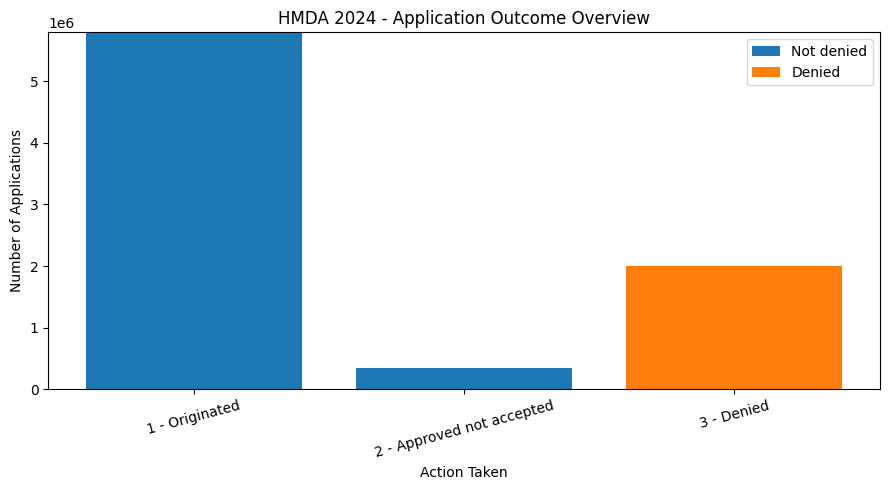

Figure 1 saved.


In [18]:
# Step 4: Recreate B14 Figure 1 - Outcome Overview

action_pdf = a2_pdf[
    a2_pdf["analysis_type"] == "action_taken"
].copy()

action_pdf = action_pdf.sort_values("action_code")

fig, ax = plt.subplots(figsize=(9, 5))

not_denied = (
    action_pdf["n"] - action_pdf["denied_n"]
)

ax.bar(
    action_pdf["category"],
    not_denied,
    label="Not denied"
)

ax.bar(
    action_pdf["category"],
    action_pdf["denied_n"],
    bottom=not_denied,
    label="Denied"
)

ax.set_title("HMDA 2024 - Application Outcome Overview")
ax.set_xlabel("Action Taken")
ax.set_ylabel("Number of Applications")
ax.legend()
ax.tick_params(axis="x", rotation=15)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "B15_fig_01_outcome_overview.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Figure 1 saved.")

### A3 — Availability by Outcome (Leakage Audit)

**Input:** Full S0, is_denied, candidate explanatory variables, and their existing B07 status fields where available.

**Process:** Calculate the non-missing share of each candidate variable separately among denied and non-denied applications. Identify variables with an availability gap exceeding 50 percentage points or 100% missingness among denied applications.

**Output:** `B15_availability_by_outcome.csv`.

Important: Availability flags are diagnostic evidence, not automatic decisions to include or exclude variables. Post-decision fields and denial reasons must remain excluded from denial controls.

In [19]:
# Step 5: Define candidate variables and availability logic

A3_CANDIDATE_COLS = [
    # Applicant
    "derived_race", "derived_ethnicity", "derived_sex",
    "race_ethnicity", "applicant_age", "age_bracket",
    "applicant_age_bracket", "has_coapplicant",

    # Financial
    "loan_amount", "property_value", "income",
    "loan_to_income", "debt_to_income_ratio",
    "dti_bin_fine", "dti_bin_coarse", "dti_point",
    "combined_loan_to_value_ratio", "ltv_calc",
    "profile_cltv_discrepancy",

    # Loan and product
    "loan_type", "loan_purpose", "lien_status",
    "occupancy_type", "construction_method",
    "total_units", "derived_dwelling_category",
    "derived_loan_product_type", "conforming_loan_limit",
    "open_end_line_of_credit", "preapproval",
    "submission_of_application",

    # Process and credit-score type proxies
    "aus_1", "aus_2", "aus_3", "aus_4", "aus_5",
    "applicant_credit_score_type",
    "co-applicant_credit_score_type",
    "co_applicant_credit_score_type",

    # Lender
    "lender_size_bucket",

    # Geography
    "state_code", "county_code", "derived_msa-md",
    "census_tract", "tract_minority_population_percent",
    "tract_to_msa_income_percentage",

    # Post-decision variables
    "interest_rate", "rate_spread", "loan_term",
    "total_loan_costs", "origination_charges",
    "discount_points", "lender_credits",
    "purchaser_type", "hoepa_status",

    # Descriptive-only variables
    "denial_reason_1", "denial_reason_2",
    "denial_reason_3", "denial_reason_4"
]

A3_CANDIDATE_COLS = [
    c for c in A3_CANDIDATE_COLS
    if c in S0_COLUMNS
]

assert len(A3_CANDIDATE_COLS) > 0

# Use B07 status fields when available
def availability_expr(column_name):

    raw_present = qcol(column_name).isNotNull()
    status_name = f"{column_name}_status"

    if status_name not in S0_COLUMNS:
        return raw_present, "Raw non-null check"

    s = F.lower(F.trim(qcol(status_name).cast("string")))

    unavailable = (
        s.isin(
            "missing", "na", "n/a", "exempt",
            "not applicable", "not_applicable",
            "not available", "not_available",
            "not reported", "not_reported", "null", ""
        )
        | s.contains("missing")
        | s.contains("exempt")
        | s.contains("not applicable")
        | s.contains("not available")
        | s.contains("not reported")
    )

    available = F.when(
        qcol(status_name).isNull(),
        raw_present
    ).otherwise(
        raw_present & (~unavailable)
    )

    return available, f"B07 status field: {status_name}"


POST_DECISION_COLS = {
    "interest_rate", "rate_spread", "loan_term",
    "total_loan_costs", "origination_charges",
    "discount_points", "lender_credits",
    "purchaser_type", "hoepa_status"
}

def get_role_hint(c):

    if c.startswith("denial_reason"):
        return "diagnostic_only"

    if c in POST_DECISION_COLS:
        return "post_decision_exclude"

    if c in {
        "derived_race", "derived_ethnicity",
        "derived_sex", "race_ethnicity",
        "applicant_age", "age_bracket",
        "applicant_age_bracket", "has_coapplicant"
    }:
        return "group"

    if c in {
        "loan_amount", "property_value", "income",
        "loan_to_income", "debt_to_income_ratio",
        "dti_bin_fine", "dti_bin_coarse", "dti_point",
        "combined_loan_to_value_ratio", "ltv_calc",
        "profile_cltv_discrepancy"
    }:
        return "financial_control"

    if c in {"state_code", "county_code",
             "derived_msa-md", "census_tract",
             "tract_minority_population_percent",
             "tract_to_msa_income_percentage"}:
        return "geo_control"

    if c == "lender_size_bucket":
        return "lender_control"

    if c in {
        "loan_type", "loan_purpose", "lien_status",
        "occupancy_type", "construction_method",
        "total_units", "derived_dwelling_category",
        "derived_loan_product_type",
        "conforming_loan_limit", "open_end_line_of_credit",
        "preapproval"
    }:
        return "product_control"

    return "diagnostic_only"

### A legacy cell 35 — Step 6: Calculate availability by outcome in one Spark aggregation [CHANGE: documentation]

**Input:** In-memory DataFrames and configuration produced by preceding cells in Part A, including `df_s0` where referenced.

**Process:** Execute the existing A-series calculation or chart exactly as coded below, retaining existing population and source-value handling. Existing blocks longer than 40 lines remain intact to avoid changing unverified B14-sensitive behavior.

**Output:** Existing named intermediate results, tables or figures defined directly in the next code cell.

**Validation / limitation:** Legacy logic preserved; its denominators, category rules and B14 parity require runtime verification. [Verified: uploaded B15 notebook source].

In [20]:
# Step 6: Calculate availability by outcome in one Spark aggregation

agg_exprs = [
    F.sum(F.when(_DENIED, 1).otherwise(0)).alias("n_denied"),
    F.sum(F.when(_NOT_DENIED, 1).otherwise(0)).alias("n_non_denied")
]

for i, c in enumerate(A3_CANDIDATE_COLS):

    available, _ = availability_expr(c)

    agg_exprs.extend([
        F.sum(
            F.when(_DENIED & available, 1).otherwise(0)
        ).alias(f"d_{i}"),

        F.sum(
            F.when(_NOT_DENIED & available, 1).otherwise(0)
        ).alias(f"nd_{i}")
    ])

a3_counts = df_s0.agg(*agg_exprs).first().asDict()

denied_total = int(a3_counts["n_denied"])
non_denied_total = int(a3_counts["n_non_denied"])

a3_rows = []

for i, c in enumerate(A3_CANDIDATE_COLS):

    denied_available = int(a3_counts[f"d_{i}"] or 0)
    non_denied_available = int(a3_counts[f"nd_{i}"] or 0)

    denied_share = denied_available / denied_total
    non_denied_share = non_denied_available / non_denied_total

    gap_pp = abs(denied_share - non_denied_share) * 100

    missing_all_denied = denied_available == 0

    _, availability_basis = availability_expr(c)

    a3_rows.append({
        "variable": c,
        "role_hint": get_role_hint(c),
        "availability_basis": availability_basis,
        "denied_n": denied_total,
        "denied_nonmissing_n": denied_available,
        "denied_nonmissing_pct": denied_share * 100,
        "non_denied_n": non_denied_total,
        "non_denied_nonmissing_n": non_denied_available,
        "non_denied_nonmissing_pct": non_denied_share * 100,
        "availability_gap_pp": gap_pp,
        "gap_gt_50pp": gap_pp > 50,
        "missing_100pct_among_denied": missing_all_denied,
        "review_flag": gap_pp > 50 or missing_all_denied
    })

a3_pdf = pd.DataFrame(a3_rows).sort_values(
    "availability_gap_pp",
    ascending=False
)

save_pandas_table(
    a3_pdf,
    "B15_availability_by_outcome.csv"
)

print("\nLEAKAGE AUDIT SUMMARY")
print(f"Candidate variables: {len(a3_pdf)}")
print(f"Variables flagged: {a3_pdf['review_flag'].sum()}")

display(
    a3_pdf[
        [
            "variable",
            "role_hint",
            "denied_nonmissing_pct",
            "non_denied_nonmissing_pct",
            "availability_gap_pp",
            "review_flag"
        ]
    ]
)

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_availability_by_outcome.csv
Shape: (55, 13)
Size: 7.87 KB

LEAKAGE AUDIT SUMMARY
Candidate variables: 55
Variables flagged: 6


,variable,role_hint,denied_nonmissing_pct,non_denied_nonmissing_pct,availability_gap_pp,review_flag
42,interest_rate,post_decision_exclude,0.0000,96.1739,96.1739,True
43,rate_spread,post_decision_exclude,0.0000,92.9415,92.9415,True
46,origination_charges,post_decision_exclude,0.0000,71.8531,71.8531,True
45,total_loan_costs,post_decision_exclude,0.0000,70.9632,70.9632,True
47,discount_points,post_decision_exclude,0.0000,38.3941,38.3941,True
13,dti_point,financial_control,26.0829,50.8956,24.8127,False
48,lender_credits,post_decision_exclude,0.0000,23.0584,23.0584,True
52,denial_reason_2,diagnostic_only,21.9185,0.0000,21.9185,False
16,profile_cltv_discrepancy,financial_control,80.0549,91.6982,11.6434,False
14,combined_loan_to_value_ratio,financial_control,82.5076,92.0299,9.5223,False


### A4 — Coverage & Sentinel Status Matrix by Race

**Input:** S0 status columns created by B07 and `is_exempt_filer`.

**Process:**
- Audit the seven predefined variables using their exact B07 status columns.
- Preserve five mutually exclusive statuses: `value`, `na`, `exempt`, `non_msa`, and `blank`.
- Aggregate status counts by race and exempt-filer classification.
- Construct Overall S0, Exempt Filers, Non-Exempt Filers, and individual race-group slices.
- Treat `non_msa` as valid geographic coverage.

**Output:** Aggregated status counts for the coverage matrix.

In [21]:
# Step 7: Define the exact B14 A4 coverage specifications

COV_SPECS = [
    ("income", "income_status"),
    ("debt_to_income_ratio", "dti_status"),
    ("combined_loan_to_value_ratio",
     "combined_loan_to_value_ratio_status"),
    ("property_value", "property_value_status"),
    ("interest_rate", "interest_rate_status"),
    ("census_tract", "census_tract_status"),
    ("derived_msa_md", "derived_msa_md_status"),
]

STATUS_LEVELS = ["value", "na", "exempt", "non_msa", "blank"]

required_a4 = (
    ["derived_race", "is_exempt_filer"]
    + [status for _, status in COV_SPECS]
)

missing_a4 = [c for c in required_a4 if c not in S0_COLUMNS]

assert not missing_a4, f"Missing A4 columns: {missing_a4}"

# Step 8: Prepare a narrow aggregation frame
a4_base = df_s0.select(
    qcol("derived_race").cast("string").alias("derived_race"),
    qcol("is_exempt_filer").cast("boolean").alias("is_exempt_filer"),
    *[
        qcol(status).cast("string").alias(status)
        for _, status in COV_SPECS
    ]
)

assert a4_base.filter(
    F.col("is_exempt_filer").isNull()
).limit(1).count() == 0, "Unexpected NULL in is_exempt_filer."

# Step 9: Aggregate all seven variables in one Spark groupBy
a4_agg_exprs = [F.count("*").alias("n_group")]

for variable, status_col in COV_SPECS:
    for level in STATUS_LEVELS:
        alias = f"{variable}__{level}"

        a4_agg_exprs.append(
            F.sum(
                F.when(F.col(status_col) == level, 1).otherwise(0)
            ).cast("long").alias(alias)
        )

a4_group_counts = (
    a4_base
    .groupBy("derived_race", "is_exempt_filer")
    .agg(*a4_agg_exprs)
)

a4_records = [
    row.asDict()
    for row in a4_group_counts.collect()
]

print(f"Aggregated race × exempt groups: {len(a4_records)}")
print("Spark aggregation completed.")

Aggregated race × exempt groups: 18
Spark aggregation completed.


### A4 (Continued) — Construct Coverage Matrix

**Input:** Aggregated Spark status counts.

**Process:**
- Reconstruct the exact B14 population slices.
- Calculate status counts and percentages for every variable.
- Validate that the five status categories account for every application.
- Calculate valid coverage as `(value + non_msa) / total`.

**Output:** `B15_coverage_by_race.csv`.

In [22]:
# Step 10: Validate status categories before constructing the table

def get_status_alias(variable, level):
    return f"{variable}__{level}"

invalid_statuses = []

for variable, status_col in COV_SPECS:
    for record in a4_records:
        n_counted = sum(
            int(record[get_status_alias(variable, level)] or 0)
            for level in STATUS_LEVELS
        )

        if n_counted != int(record["n_group"]):
            invalid_statuses.append((variable, status_col))

if invalid_statuses:
    raise ValueError(
        "A4 status reconciliation failed. "
        f"Check these variables: {sorted(set(invalid_statuses))}. "
        "Expected exactly: value, na, exempt, non_msa, blank."
    )

# Step 11: Define population slices
race_values = sorted({
    r["derived_race"]
    for r in a4_records
    if r["derived_race"] is not None
})

slices = [
    (
        "Overall S0",
        a4_records
    ),
    (
        "Exempt Filers (n_exempt_28 == 28)",
        [r for r in a4_records if r["is_exempt_filer"]]
    ),
    (
        "Non-Exempt Filers (n_exempt_28 < 28)",
        [r for r in a4_records if not r["is_exempt_filer"]]
    ),
]

for race in race_values:
    slices.append((
        f"Race: {race}",
        [r for r in a4_records if r["derived_race"] == race]
    ))

# Preserve NULL race records explicitly if they exist
if any(r["derived_race"] is None for r in a4_records):
    slices.append((
        "Race: NULL / Missing",
        [r for r in a4_records if r["derived_race"] is None]
    ))

# Step 12: Construct coverage statistics
cov_rows = []

for group_label, group_records in slices:

    n_group = sum(int(r["n_group"]) for r in group_records)

    assert n_group > 0, f"Empty population slice: {group_label}"

    for variable, _ in COV_SPECS:

        counts = {
            level: sum(
                int(r[get_status_alias(variable, level)] or 0)
                for r in group_records
            )
            for level in STATUS_LEVELS
        }

        n_val = counts["value"]
        n_na = counts["na"]
        n_ex = counts["exempt"]
        n_nmsa = counts["non_msa"]
        n_blank = counts["blank"]

        assert sum(counts.values()) == n_group

        cov_rows.append({
            "group_slice": group_label,
            "variable": variable,
            "n_total": n_group,
            "n_value": n_val,
            "n_na": n_na,
            "n_exempt": n_ex,
            "n_non_msa": n_nmsa,
            "n_blank": n_blank,

            # Non-MSA is a valid geographic classification
            "pct_value": round(
                (n_val + n_nmsa) * 100 / n_group, 2
            ),

            "pct_na": round(n_na * 100 / n_group, 2),
            "pct_exempt": round(n_ex * 100 / n_group, 2),
        })

cov_df = pd.DataFrame(cov_rows)

save_pandas_table(
    cov_df,
    "B15_coverage_by_race.csv"
)

# Step 13: Validate population denominators
overall = cov_df[cov_df["group_slice"] == "Overall S0"]

assert (overall["n_total"] == S0_N).all()

assert (
    cov_df.groupby("group_slice")["variable"].nunique() == 7
).all()

assert (
    cov_df.groupby(["group_slice", "variable"])
    .apply(
        lambda g: (
            g["n_value"].iloc[0]
            + g["n_na"].iloc[0]
            + g["n_exempt"].iloc[0]
            + g["n_non_msa"].iloc[0]
            + g["n_blank"].iloc[0]
        ) == g["n_total"].iloc[0],
        include_groups=False
    )
).all()

print("A4 validation passed.")
print(f"Population slices: {len(slices)}")
print(f"Coverage records: {len(cov_df)}")

display(overall)

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_coverage_by_race.csv
Shape: (84, 11)
Size: 7.17 KB
A4 validation passed.
Population slices: 12
Coverage records: 84


,group_slice,variable,n_total,n_value,n_na,n_exempt,n_non_msa,n_blank,pct_value,pct_na,pct_exempt
0,Overall S0,income,8136664,7839422,297242,0,0,0,96.3500,3.6500,0.0000
1,Overall S0,debt_to_income_ratio,8136664,7513962,372942,249760,0,0,92.3500,4.5800,3.0700
2,Overall S0,combined_loan_to_value_ratio,8136664,7297403,589291,249970,0,0,89.6900,7.2400,3.0700
3,Overall S0,property_value,8136664,7590865,294934,250865,0,0,93.2900,3.6200,3.0800
4,Overall S0,interest_rate,8136664,5898721,1987894,250049,0,0,72.5000,24.4300,3.0700
5,Overall S0,census_tract,8136664,8040599,96065,0,0,0,98.8200,1.1800,0.0000
6,Overall S0,derived_msa_md,8136664,7031764,0,0,1104900,0,100.0000,0.0000,0.0000


### A legacy cell 40 — Step 14: Prepare coverage heatmap [CHANGE: documentation]

**Input:** In-memory DataFrames and configuration produced by preceding cells in Part A, including `df_s0` where referenced.

**Process:** Execute the existing A-series calculation or chart exactly as coded below, retaining existing population and source-value handling. Existing blocks longer than 40 lines remain intact to avoid changing unverified B14-sensitive behavior.

**Output:** Existing named intermediate results, tables or figures defined directly in the next code cell.

**Validation / limitation:** Legacy logic preserved; its denominators, category rules and B14 parity require runtime verification. [Verified: uploaded B15 notebook source].

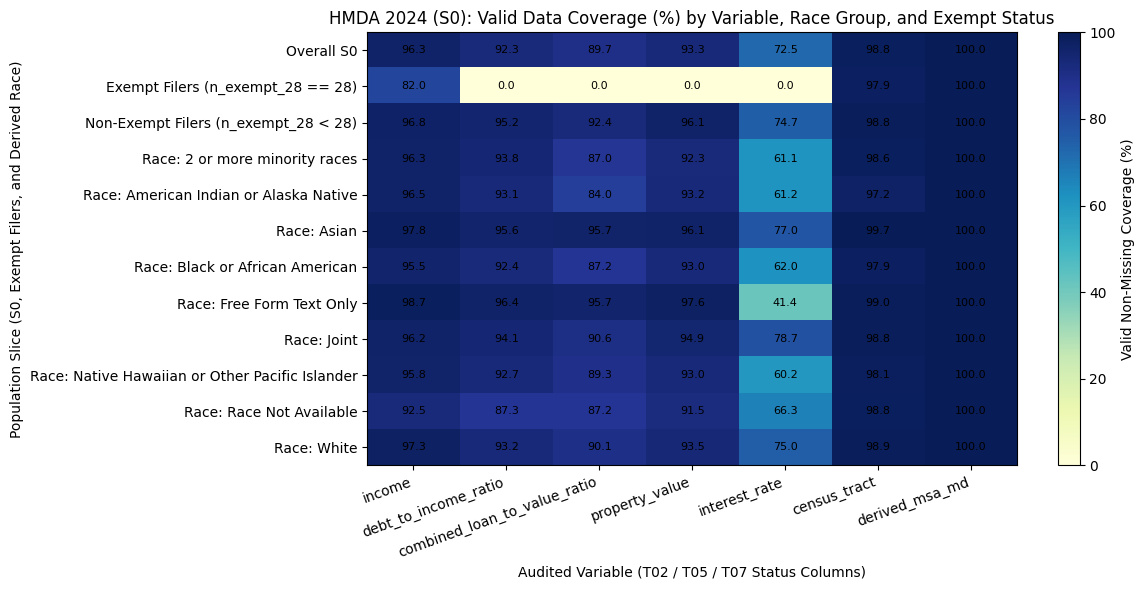

Figure 2 saved.


In [23]:
# Step 14: Prepare coverage heatmap

piv_cov = cov_df.pivot(
    index="group_slice",
    columns="variable",
    values="pct_value"
)

col_order = [variable for variable, _ in COV_SPECS]

row_order = [
    "Overall S0",
    "Exempt Filers (n_exempt_28 == 28)",
    "Non-Exempt Filers (n_exempt_28 < 28)",
] + [f"Race: {race}" for race in race_values]

if "Race: NULL / Missing" in piv_cov.index:
    row_order.append("Race: NULL / Missing")

piv_cov = piv_cov.reindex(
    index=row_order,
    columns=col_order
)

# Step 15: Plot annotated heatmap
fig, ax = plt.subplots(
    figsize=(12, max(6, len(row_order) * 0.48))
)

im = ax.imshow(
    piv_cov.values,
    aspect="auto",
    cmap="YlGnBu",
    vmin=0,
    vmax=100
)

for i in range(len(row_order)):
    for j in range(len(col_order)):
        value = piv_cov.iloc[i, j]

        if pd.notna(value):
            ax.text(
                j, i,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=8
            )

ax.set_xticks(range(len(col_order)))
ax.set_xticklabels(col_order, rotation=20, ha="right")

ax.set_yticks(range(len(row_order)))
ax.set_yticklabels(row_order)

ax.set_title(
    "HMDA 2024 (S0): Valid Data Coverage (%) "
    "by Variable, Race Group, and Exempt Status"
)

ax.set_xlabel(
    "Audited Variable (T02 / T05 / T07 Status Columns)"
)

ax.set_ylabel(
    "Population Slice (S0, Exempt Filers, and Derived Race)"
)

fig.colorbar(
    im,
    ax=ax,
    label="Valid Non-Missing Coverage (%)"
)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "B15_fig_02_coverage_by_race.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Figure 2 saved.")

### A3b — Code-level availability and explicit status evidence [ADD]

**Input:** `df_s0`, the B07 `*_status` fields listed in A4, `is_denied` and `derived_race`; full S0, no row filtering.

**Process:** Aggregate each original B07 status value separately by denial outcome. Unlike the earlier non-null audit, `na`, `exempt`, `blank`, and `non_msa` are never silently treated as equivalent. Preserve NULL status as a visible category. Use original source values rather than assigning unverified new sentinel meanings.

**Output:** `a3_code_level_pdf` and `output/B15_availability_code_level.csv`, with status counts, within-variable/outcome shares and source-column provenance.

**Validation / limitation:** Each variable's status counts reconcile to its outcome population; status labels reflect B07 values and do not independently establish lender-time availability. [Verified: current B15 A4 status specifications].

In [24]:
# [ADD] A3b: Audit original B07 status codes without recoding them.
a3_status_specs = [(v, s) for v, s in COV_SPECS if s in df_s0.columns]
a3_code_frames = []
for variable, status_col in a3_status_specs:
    temp = df_s0.select(
        F.lit(variable).alias("variable"),
        F.lit(status_col).alias("status_source"),
        F.coalesce(F.col(status_col).cast("string"), F.lit("__NULL__")).alias("status_value"),
        F.col("is_denied").cast("int").alias("is_denied"),
    )
    part = temp.groupBy("variable", "status_source", "status_value", "is_denied").count()
    a3_code_frames.append(part)
assert a3_code_frames, "No original B07 status columns were available."
a3_codes = a3_code_frames[0]
for next_codes in a3_code_frames[1:]:
    a3_codes = a3_codes.unionByName(next_codes)
a3_codes = a3_codes.withColumn(
    "share_within_outcome", F.col("count") / F.sum("count").over(
        Window.partitionBy("variable", "is_denied")
    )
)
a3_code_level_pdf = save_small_spark_table(a3_codes, "B15_availability_code_level.csv")
for (_, outcome), group in a3_code_level_pdf.groupby(["variable", "is_denied"]):
    target = S0_DENIED_N if int(outcome) == 1 else S0_NON_DENIED_N
    assert int(group["count"].sum()) == target
print("[OK] A3b status counts reconcile for every variable and outcome.")

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_availability_code_level.csv
Shape: (35, 6)
Size: 2.59 KB
[OK] A3b status counts reconcile for every variable and outcome.


### A3c — Variable-role and availability-stage registry [ADD]

**Input:** Actual S0 schema, A3 role hints, the B15 exclusion list, and B07 availability-status column names.

**Process:** Distinguish observed field presence from suitability as a pre-decision control. Mark post-decision pricing and denial reasons as excluded; flag fields with uncertain availability for human review instead of inventing evidence. Preserve original role hints for traceability.

**Output:** `a3_roles_pdf` and `output/B15_variable_roles.csv` with role, stage, schema presence, leakage assessment, and evidence.

**Validation / limitation:** A role hint is not proof of time-of-availability. [Verified: current B15 A3/A4 code]; no independent B14 role dictionary was provided.

In [25]:
# [ADD] A3c: Explicit provenance-aware variable registry.
role_rows = []
for name in A3_CANDIDATE_COLS:
    hint = get_role_hint(name)
    if name.startswith("denial_reason"):
        stage, assessment = "After denial decision", "Exclude: outcome-dependent"
    elif name in POST_DECISION_COLS:
        stage, assessment = "Post-decision / origination", "Exclude: timing/leakage risk"
    elif hint == "diagnostic_only":
        stage, assessment = "Not established", "Review before modeling"
    else:
        stage, assessment = "Application/context (provisional)", "Verify timing and eligibility"
    status_col = f"{name}_status"
    role_rows.append({
        "variable": name, "source_role_hint": hint, "availability_stage": stage,
        "leakage_assessment": assessment, "in_s0_schema": name in S0_COLUMNS,
        "status_source": status_col if status_col in S0_COLUMNS else None,
        "evidence": "[Verified: B15 A3 code; schema]",
        "time_availability_verified": False,
    })
a3_roles_pdf = pd.DataFrame(role_rows)
assert set(DENIAL_REASON_COLS).intersection(S0_COLUMNS).issubset(
    set(a3_roles_pdf.loc[a3_roles_pdf.leakage_assessment.str.startswith("Exclude"), "variable"])
)
save_pandas_table(a3_roles_pdf, "B15_variable_roles.csv")
print("[OK] Descriptive-only reason variables remain excluded.")

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_variable_roles.csv
Shape: (55, 8)
Size: 7.74 KB
[OK] Descriptive-only reason variables remain excluded.


### A5 — Population Composition

**Input:** Existing B14/B07 demographic, race, ethnicity, co-applicant, age, and application-channel variables.

**Process:** Calculate the full-S0 count and population share for each category. Preserve the original derived_race categories, including Joint, Race Not Available, and Free Form Text Only. Use existing age-bracket and co-applicant variables without introducing new mappings.

**Output:** `B15_composition.csv` and Figure 3.

In [26]:
# Step 10: Define existing population dimensions

dimension_specs = [
    ("Race", ["derived_race"]),
    ("Ethnicity", ["derived_ethnicity"]),
    ("Sex", ["derived_sex"]),

    # Supplementary existing B14 dimension
    ("Supplementary race-ethnicity", ["race_ethnicity"]),

    ("Age bracket", [
        "age_bracket",
        "applicant_age_bracket",
        "applicant_age"
    ]),

    ("Co-applicant presence", [
        "has_coapplicant",
        "has_co_applicant"
    ]),

    ("Application channel", [
        "submission_of_application"
    ]),

    ("Exempt filer status", [
        "is_exempt_filer"
    ])
]

available_dimensions = []

for label, candidates in dimension_specs:

    actual_col = next(
        (c for c in candidates if c in S0_COLUMNS),
        None
    )

    if actual_col is None:
        print(f"Not available: {label}")
        continue

    if label == "Age bracket" and actual_col == "applicant_age":
        label = "Applicant age (source categories)"

    available_dimensions.append((label, actual_col))

assert any(
    col_name == "derived_race"
    for _, col_name in available_dimensions
)

print("Population dimensions:")
for label, col_name in available_dimensions:
    print(f"{label}: {col_name}")

Population dimensions:
Race: derived_race
Ethnicity: derived_ethnicity
Sex: derived_sex
Supplementary race-ethnicity: race_ethnicity
Applicant age (source categories): applicant_age
Co-applicant presence: has_coapplicant
Application channel: submission_of_application
Exempt filer status: is_exempt_filer


### A legacy cell 43 — Step 11: Calculate population composition [CHANGE: documentation]

**Input:** In-memory DataFrames and configuration produced by preceding cells in Part A, including `df_s0` where referenced.

**Process:** Execute the existing A-series calculation or chart exactly as coded below, retaining existing population and source-value handling. Existing blocks longer than 40 lines remain intact to avoid changing unverified B14-sensitive behavior.

**Output:** Existing named intermediate results, tables or figures defined directly in the next code cell.

**Validation / limitation:** Legacy logic preserved; its denominators, category rules and B14 parity require runtime verification. [Verified: uploaded B15 notebook source].

In [27]:
# Step 11: Calculate population composition

composition_sdf = None

for label, col_name in available_dimensions:

    part = (
        df_s0
        .select(
            F.coalesce(
                qcol(col_name).cast("string"),
                F.lit("__NULL__")
            ).alias("category")
        )
        .groupBy("category")
        .agg(F.count("*").alias("n"))
        .withColumn(
            "dimension",
            F.lit(label)
        )
        .withColumn(
            "share_pct",
            F.col("n") / F.lit(S0_N) * 100
        )
        .withColumn(
            "is_joint_race_category",
            F.when(
                (F.col("dimension") == "Race")
                & (F.col("category") == "Joint"),
                True
            ).otherwise(False)
        )
        .select(
            "dimension",
            "category",
            "n",
            "share_pct",
            "is_joint_race_category"
        )
    )

    composition_sdf = (
        part if composition_sdf is None
        else composition_sdf.unionByName(part)
    )

composition_sdf = composition_sdf.orderBy(
    "dimension",
    F.desc("share_pct")
)

composition_pdf = save_small_spark_table(
    composition_sdf,
    "B15_composition.csv"
)

# Check that each dimension sums to approximately 100%
composition_check = (
    composition_pdf.groupby("dimension")["share_pct"].sum()
)

assert (
    (composition_check - 100).abs() < 1e-6
).all(), "Population composition shares do not sum to 100%."

print("\nComposition validation:")
display(composition_check.reset_index(name="total_share_pct"))

# Verify that Joint remains a separate race category
joint_rows = composition_pdf[
    (composition_pdf["dimension"] == "Race")
    & (composition_pdf["category"] == "Joint")
]

if not joint_rows.empty:
    print("Joint race category retained:")
    display(joint_rows)

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_composition.csv
Shape: (39, 5)
Size: 2.47 KB

Composition validation:


,dimension,total_share_pct
0,Applicant age (source categories),100.0000
1,Application channel,100.0000
2,Co-applicant presence,100.0000
3,Ethnicity,100.0000
4,Exempt filer status,100.0000
5,Race,100.0000
6,Sex,100.0000
7,Supplementary race-ethnicity,100.0000


Joint race category retained:


,dimension,category,n,share_pct,is_joint_race_category
25,Race,Joint,184536,2.2680,True


### A legacy cell 44 — Step 12: Recreate B14 Figure 3 - Population Composition [CHANGE: documentation]

**Input:** In-memory DataFrames and configuration produced by preceding cells in Part A, including `df_s0` where referenced.

**Process:** Execute the existing A-series calculation or chart exactly as coded below, retaining existing population and source-value handling. Existing blocks longer than 40 lines remain intact to avoid changing unverified B14-sensitive behavior.

**Output:** Existing named intermediate results, tables or figures defined directly in the next code cell.

**Validation / limitation:** Legacy logic preserved; its denominators, category rules and B14 parity require runtime verification. [Verified: uploaded B15 notebook source].

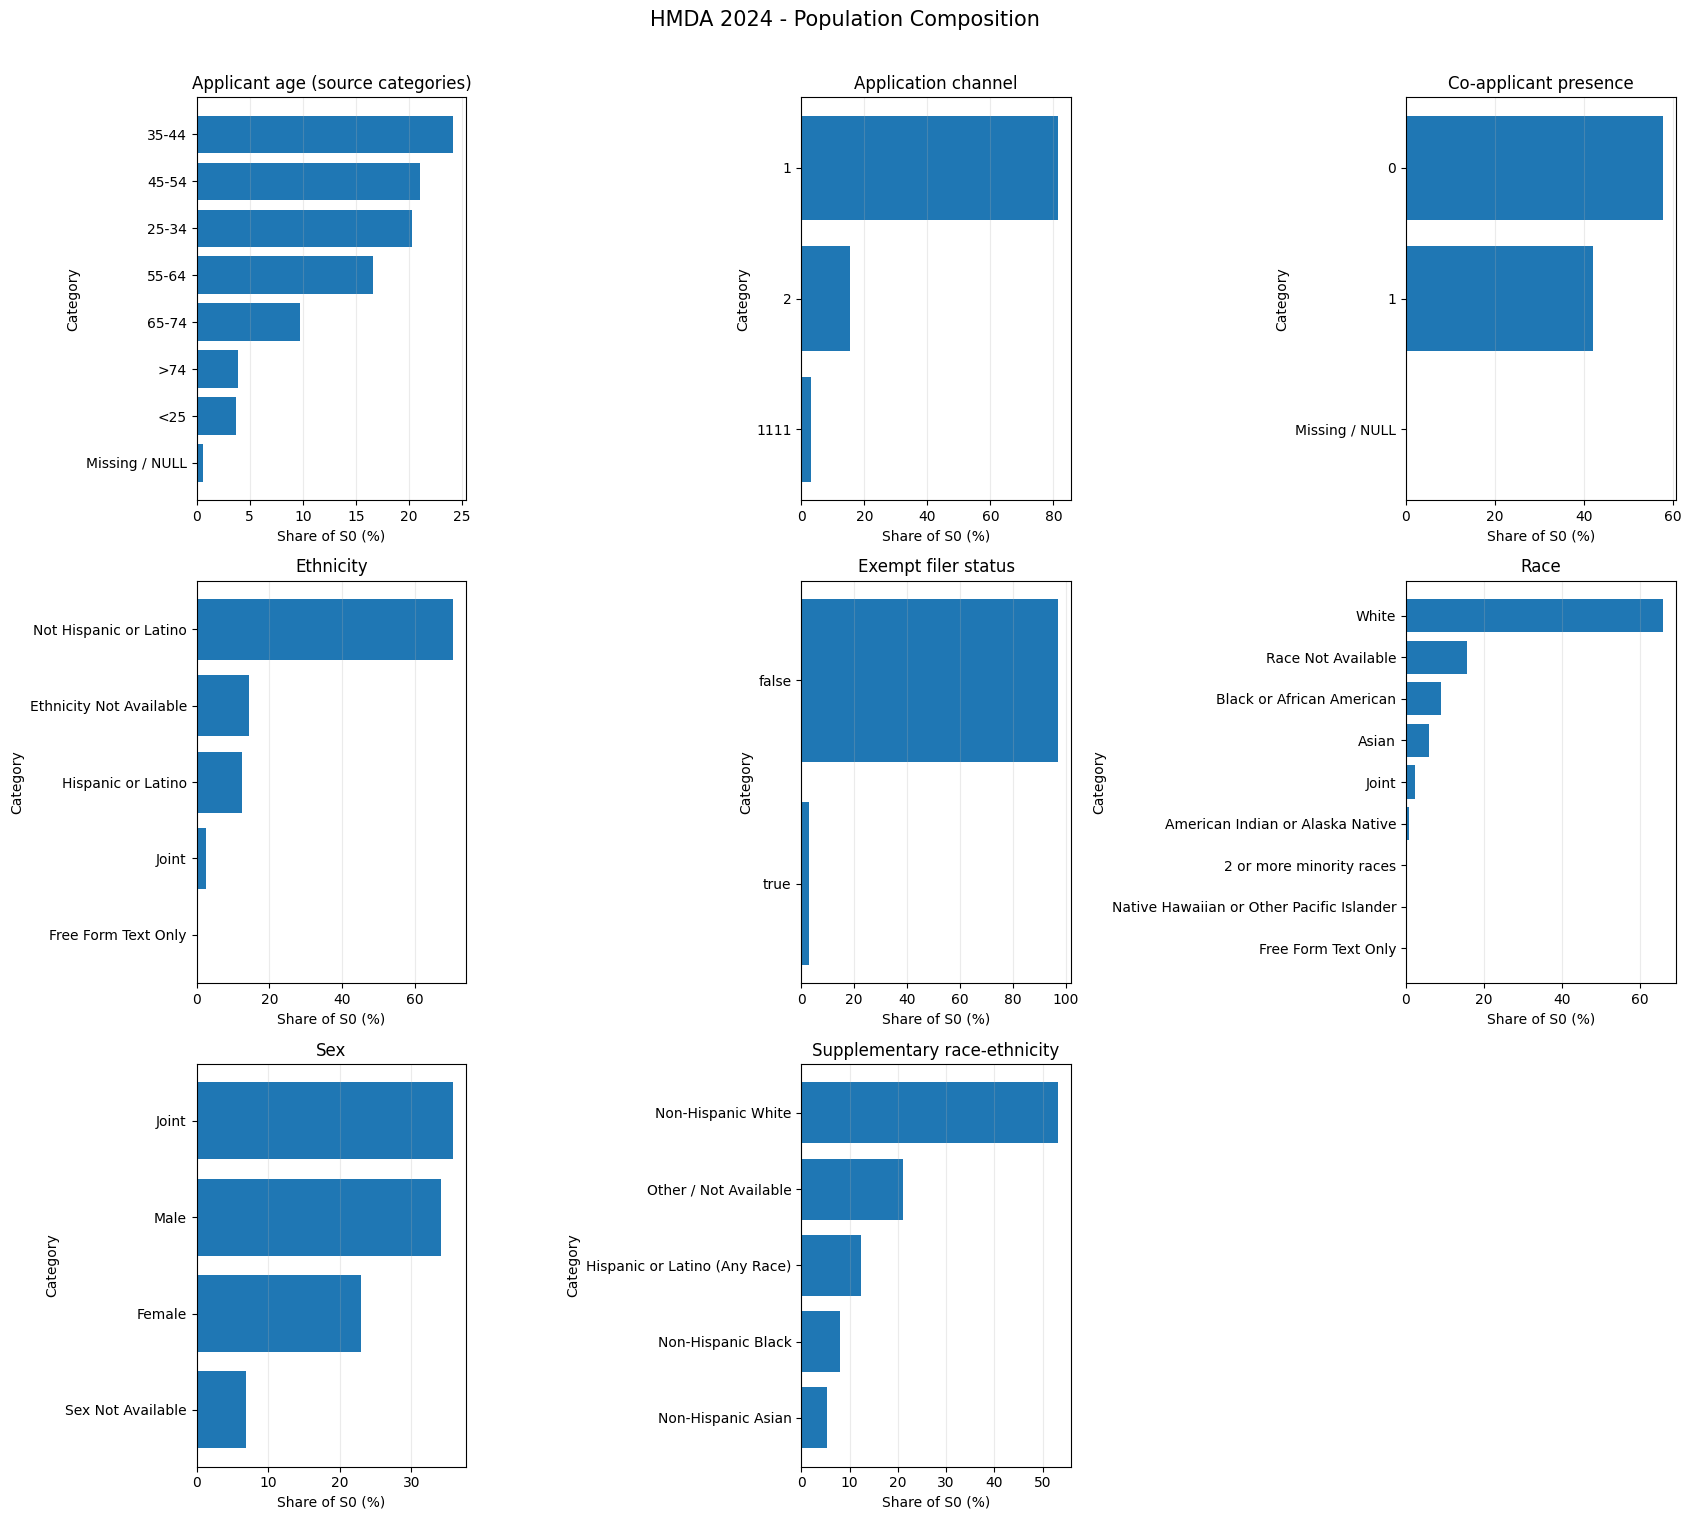

Figure 3 saved.


In [28]:
# Step 12: Recreate B14 Figure 3 - Population Composition

dimensions = composition_pdf["dimension"].unique().tolist()

ncols = 3
nrows = math.ceil(len(dimensions) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(17, 5 * nrows)
)

axes = axes.flatten()

for i, dimension in enumerate(dimensions):

    ax = axes[i]

    subset = composition_pdf[
        composition_pdf["dimension"] == dimension
    ].copy()

    subset = subset.sort_values(
        "share_pct",
        ascending=True
    )

    subset["category"] = subset["category"].replace({
        "__NULL__": "Missing / NULL"
    })

    ax.barh(
        subset["category"],
        subset["share_pct"]
    )

    ax.set_title(dimension)
    ax.set_xlabel("Share of S0 (%)")
    ax.set_ylabel("Category")

    ax.grid(
        axis="x",
        alpha=0.25
    )

# Remove unused panels
for j in range(len(dimensions), len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "HMDA 2024 - Population Composition",
    fontsize=15,
    y=1.01
)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "B15_fig_03_composition.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Figure 3 saved.")

## Part B – Univariate Distributions

### Objective
Reproduce the B14 univariate analysis using PySpark on the full S0 analytic sample.

### Analytical scope
- B1: Numeric financial distributions.
- B2: CLTV / LTV distributions and heaping.
- B3: Debt-to-income ratio (DTI) ordinal distributions.
- B4: Pricing characteristics among originated loans.
- B5: Categorical product, channel, and institution distributions.
- B6: Outliers versus data errors.
- B7: Duplicate records.

### Implementation principles
1. Use full S0 for descriptive statistics, counts, shares, and denial rates.
2. Use Spark DataFrame aggregations for large-scale calculations.
3. Use bounded Pandas samples only for visualization.
4. Preserve special codes and Exempt categories.
5. Do not modify the original financial values.
6. Keep post-decision pricing variables separate from denial controls.

### Inputs
- `df_s0`: B07_analytic.parquet.
- `df_samp`: Existing B14 seeded diagnostic sample, when required.
- B07 validation flags and S4 winsor thresholds.

### Outputs
All tables are exported to `output/`.
All figures are exported to `output/figures/`.

In [29]:
# Step 0.1: Imports

import os
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from functools import reduce
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Step 0.2: Configuration

SEED = 42
QUANTILE_ACCURACY = 10000
PLOT_MAX_N = 100000

NUMERIC_PERCENTILES = [
    0.01, 0.05, 0.25, 0.50,
    0.75, 0.95, 0.99
]

# These paths should already be declared in Section 0.
os.makedirs(os.fspath(OUTPUT_DIR), exist_ok=True)
os.makedirs(os.fspath(FIGURE_DIR), exist_ok=True)

# S4 thresholds must be loaded from the actual B07 JSON artifact.
# Structure: {"loan_amount": {"lower": ..., "upper": ...}, ...}
S4_WINSOR_LINES = globals().get("S4_WINSOR_LINES", {})


# Step 0.3: Column validation

def require_columns(df, columns, section):
    missing = [c for c in columns if c not in df.columns]

    if missing:
        raise ValueError(
            f"{section}: Missing required columns: {missing}"
        )


# Step 0.4: Bounded output export

def save_pdf(pdf, filename):
    path = os.path.join(os.fspath(OUTPUT_DIR), filename)

    pdf.to_csv(path, index=False)

    print(
        f"Saved: {path} | "
        f"Rows: {len(pdf):,} | "
        f"Columns: {len(pdf.columns)}"
    )


def save_spark_table(sdf, filename, max_rows=100000):
    n = sdf.count()

    if n > max_rows:
        raise ValueError(
            f"Output too large for driver collection: {n:,} rows"
        )

    pdf = sdf.toPandas()
    save_pdf(pdf, filename)

    return pdf


# Step 0.5: Figure export

def save_figure(fig, filename):
    path = os.path.join(os.fspath(FIGURE_DIR), filename)

    fig.savefig(
        path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.close(fig)
    print(f"Saved figure: {path}")


# Step 0.6: Reusable numeric summary

def spark_numeric_summary(
    df,
    variables,
    group_cols=None,
    accuracy=QUANTILE_ACCURACY
):
    group_cols = group_cols or []
    outputs = []

    for variable in variables:

        temp = df.select(
            *[F.col(c) for c in group_cols],
            F.col(variable).cast("double").alias("_x")
        )

        aggs = [
            F.count(F.lit(1)).alias("n_total"),
            F.count("_x").alias("n_valid"),

            (
                F.count(F.lit(1)) -
                F.count("_x")
            ).alias("n_missing"),

            F.mean("_x").alias("mean"),
            F.stddev_samp("_x").alias("sd"),
            F.skewness("_x").alias("skewness")
        ]

        for p in NUMERIC_PERCENTILES:
            label = f"p{int(p * 100):02d}"

            aggs.append(
                F.percentile_approx(
                    F.col("_x"),
                    float(p),
                    accuracy
                ).alias(label)
            )

        if group_cols:
            result = temp.groupBy(*group_cols).agg(*aggs)
        else:
            result = temp.agg(*aggs)

        result = result.withColumn(
            "variable",
            F.lit(variable)
        )

        result = result.withColumn(
            "quantile_method",
            F.lit("Spark percentile_approx")
        )

        result = result.withColumn(
            "quantile_accuracy",
            F.lit(accuracy)
        )

        outputs.append(result)

    return reduce(
        lambda a, b: a.unionByName(b),
        outputs
    )


# Step 0.7: Bounded plotting sample

B1_VARS = [
    "loan_amount",
    "property_value",
    "income",
    "loan_to_income"
]

B2_VARS = [
    "combined_loan_to_value_ratio",
    "ltv_calc",
    "profile_cltv_discrepancy"
]

B4_VARS = [
    "interest_rate",
    "rate_spread",
    "loan_term",
    "total_loan_costs"
]

PLOT_COLS = list(dict.fromkeys(
    B1_VARS + B2_VARS + B4_VARS +
    [
        "is_denied",
        "action_taken",
        "lien_status",
        "loan_type"
    ]
))

require_columns(df_s0, PLOT_COLS, "Part B plotting")

# Prefer the existing B14 seeded diagnostic sample if it
# contains all required fields.
plot_source = df_s0

if "df_samp" in globals():
    if set(PLOT_COLS).issubset(set(df_samp.columns)):
        plot_source = df_samp

source_n = plot_source.count()

sample_fraction = min(
    1.0,
    (PLOT_MAX_N * 2) / max(source_n, 1)
)

plot_pdf = (
    plot_source
    .select(*PLOT_COLS)
    .sample(False, sample_fraction, SEED)
    .limit(PLOT_MAX_N)
    .toPandas()
)

print(f"Plotting sample: {len(plot_pdf):,} rows")

Plotting sample: 100,000 rows


### Reusable Helper Functions

This section defines common functions for Part B.

1. `require_columns`: validates the availability of required variables.
2. `save_spark_table`: exports bounded Spark aggregation results and logs output metadata.
3. `save_figure`: exports figures using the B15 naming convention.
4. `spark_numeric_summary`: calculates descriptive statistics and approximate quantiles.

Quantile calculations use Spark's `percentile_approx` with an accuracy parameter of 10,000. This is an approximation and must be documented when comparing results with B14's Pandas quantiles.

In [30]:
# Step 0.1: Import libraries

import os
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from functools import reduce
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Step 0.2: Part B configuration

SEED = 42
QUANTILE_ACCURACY = 10000
PLOT_MAX_N = 100000

PERCENTILES = [
    0.01, 0.05, 0.25, 0.50,
    0.75, 0.95, 0.99
]

# Reuse paths declared in Section 0
os.makedirs(str(OUTPUT_DIR), exist_ok=True)
os.makedirs(str(FIGURE_DIR), exist_ok=True)

assert "df_s0" in globals(), "df_s0 is not loaded."

### B legacy cell 49 — Step 0.3: Validate required columns [CHANGE: documentation]

**Input:** In-memory DataFrames and configuration produced by preceding cells in Part B, including `df_s0` where referenced.

**Process:** Execute the existing B-series calculation or chart exactly as coded below, retaining existing population and source-value handling. Existing blocks longer than 40 lines remain intact to avoid changing unverified B14-sensitive behavior.

**Output:** Existing named intermediate results, tables or figures defined directly in the next code cell.

**Validation / limitation:** Legacy logic preserved; its denominators, category rules and B14 parity require runtime verification. [Verified: uploaded B15 notebook source].

In [31]:
# Step 0.3: Validate required columns

def require_columns(df, columns, section):
    missing = [c for c in columns if c not in df.columns]

    if missing:
        raise ValueError(
            f"{section}: Missing columns: {missing}"
        )


# Step 0.4: Export bounded Spark aggregation tables

def save_spark_table(df, filename, max_rows=100000):
    n = df.count()

    if n > max_rows:
        raise ValueError(
            f"Output exceeds collection limit: {n:,}"
        )

    pdf = df.toPandas()
    path = os.path.join(str(OUTPUT_DIR), filename)

    pdf.to_csv(path, index=False)

    print(
        f"Saved: {path} | "
        f"Shape: {pdf.shape}"
    )

    return pdf


# Step 0.5: Export figures

def save_figure(fig, filename):
    path = os.path.join(str(FIGURE_DIR), filename)

    fig.savefig(
        path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.close(fig)
    print(f"Saved figure: {path}")

### B legacy cell 50 — Step 0.6: Reusable numeric summary [CHANGE: documentation]

**Input:** In-memory DataFrames and configuration produced by preceding cells in Part B, including `df_s0` where referenced.

**Process:** Execute the existing B-series calculation or chart exactly as coded below, retaining existing population and source-value handling. Existing blocks longer than 40 lines remain intact to avoid changing unverified B14-sensitive behavior.

**Output:** Existing named intermediate results, tables or figures defined directly in the next code cell.

**Validation / limitation:** Legacy logic preserved; its denominators, category rules and B14 parity require runtime verification. [Verified: uploaded B15 notebook source].

In [32]:
# Step 0.6: Reusable numeric summary

def spark_numeric_summary(
    df,
    variables,
    group_cols=None,
    accuracy=QUANTILE_ACCURACY
):
    group_cols = group_cols or []

    frames = [
        df.select(
            *[F.col(c) for c in group_cols],
            F.lit(v).alias("variable"),
            F.col(v).cast("double").alias("_value")
        )
        for v in variables
    ]

    long_df = reduce(
        lambda a, b: a.unionByName(b),
        frames
    )

    summary = (
        long_df
        .groupBy(*(group_cols + ["variable"]))
        .agg(
            F.count("*").alias("n_total"),
            F.count("_value").alias("n_valid"),
            F.avg("_value").alias("mean"),
            F.stddev_samp("_value").alias("sd"),
            F.skewness("_value").alias("skewness"),
            F.percentile_approx(
                "_value",
                PERCENTILES,
                accuracy
            ).alias("_quantiles")
        )
        .withColumn(
            "n_missing",
            F.col("n_total") - F.col("n_valid")
        )
    )

    for i, p in enumerate(PERCENTILES):
        summary = summary.withColumn(
            f"p{int(p * 100):02d}",
            F.col("_quantiles").getItem(i)
        )

    return (
        summary
        .drop("_quantiles")
        .withColumn(
            "quantile_method",
            F.lit("Spark percentile_approx")
        )
        .withColumn(
            "quantile_accuracy",
            F.lit(accuracy)
        )
    )

### Visualization Sample

Full S0 remains the source of all descriptive tables.

For visualization, use the existing B14 seeded sample when it contains the required variables. Otherwise, create a bounded sample from S0 using seed 42.

The visualization sample must not replace full-S0 statistics or be used to calculate the final descriptive tables.

Maximum collection size: 100,000 observations.

In [33]:
# Step 0.7: Define plotting variables

B1_VARS = [
    "loan_amount", "property_value",
    "income", "loan_to_income"
]

B2_VARS = [
    "combined_loan_to_value_ratio",
    "ltv_calc",
    "profile_cltv_discrepancy"
]

B4_VARS = [
    "interest_rate", "rate_spread",
    "loan_term", "total_loan_costs"
]

PLOT_COLS = list(dict.fromkeys(
    B1_VARS + B2_VARS + B4_VARS +
    [
        "is_denied", "action_taken",
        "lien_status", "loan_type"
    ]
))

require_columns(df_s0, PLOT_COLS, "Part B plotting")

# Step 0.8: Select the available source

plot_source = df_s0

if (
    "df_samp" in globals()
    and set(PLOT_COLS).issubset(df_samp.columns)
):
    plot_source = df_samp

plot_source_n = plot_source.count()

fraction = min(
    1.0,
    PLOT_MAX_N / max(plot_source_n, 1)
)

plot_pdf = (
    plot_source
    .select(*PLOT_COLS)
    .sample(False, fraction, SEED)
    .limit(PLOT_MAX_N)
    .toPandas()
)

print(f"Visualization sample: {len(plot_pdf):,}")

Visualization sample: 100,000


### B07 Reference Configurations

The following configurations must reuse the original B07/B14 definitions:

- `S4_WINSOR_LINES`: S4 winsor thresholds for visualization only.
- `DTI_ORDER`: Exact ordinal category order from B14.
- `V_FLAG_MAP`: Mapping between V01–V05, V09 and their physical B07 column names.
- `V_FLAG_DESCRIPTIONS`: Original validation-rule descriptions.

These configurations must not be independently redefined using assumptions.

In [34]:
# Step 0.9: Reuse configurations from Section 0

S4_WINSOR_LINES = globals().get(
    "S4_WINSOR_LINES", {}
)

DTI_ORDER = globals().get(
    "DTI_ORDER", {}
)

V_FLAG_MAP = globals().get(
    "V_FLAG_MAP", {}
)

V_FLAG_DESCRIPTIONS = globals().get(
    "V_FLAG_DESCRIPTIONS", {}
)


def get_winsor_values(variable):
    spec = S4_WINSOR_LINES.get(variable, [])

    if isinstance(spec, dict):
        spec = [spec.get("lower"), spec.get("upper")]

    return [
        float(x) for x in spec
        if isinstance(x, (int, float))
    ]

## B1. Numeric Financial Distributions

### Objective
Examine the distributions of four continuous financial variables:

- `loan_amount`
- `property_value`
- `income`
- `loan_to_income`

### Input
Full S0 analytic sample.

### Process
1. Calculate the number of observations and missing values.
2. Calculate mean, standard deviation, and skewness.
3. Calculate P1, P5, P25, P50, P75, P95, and P99.
4. Compare distributions between denied and non-denied applications.
5. Visualize positive values using logarithmic x-axes.
6. Display S4 winsor thresholds as reference lines only.

### Output
- `B15_numeric_summary.csv`
- Figure 4: Numeric distributions by outcome.

### Important
Winsor thresholds are visualization references. Original values must remain unchanged.

In [35]:
# Step B1.1: Validate financial variables

require_columns(
    df_s0,
    B1_VARS + ["is_denied"],
    "B1"
)

# Step B1.2: Overall S0 statistics

b1_overall = spark_numeric_summary(
    df_s0,
    B1_VARS
)

b1_overall = (
    b1_overall
    .withColumn("group_type", F.lit("Overall"))
    .withColumn("group_value", F.lit("All S0"))
    .withColumn(
        "is_denied",
        F.lit(None).cast("int")
    )
)

# Step B1.3: Statistics by outcome

b1_outcome = spark_numeric_summary(
    df_s0,
    B1_VARS,
    group_cols=["is_denied"]
)

b1_outcome = (
    b1_outcome
    .withColumn("group_type", F.lit("Outcome"))
    .withColumn(
        "group_value",
        F.when(F.col("is_denied") == 1, "Denied")
         .otherwise("Non-denied")
    )
)

# Step B1.4: Combine and export

b1_result = b1_overall.unionByName(
    b1_outcome,
    allowMissingColumns=True
)

b1_pdf = save_spark_table(
    b1_result,
    "B15_numeric_summary.csv"
)

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_numeric_summary.csv | Shape: (12, 19)


### Figure 4 – Numeric Distributions by Outcome

The figure compares the distributions of financial variables between denied and non-denied applications.

A logarithmic x-axis is used to make right-skewed financial distributions easier to inspect.

Vertical reference lines indicate the S4 winsor thresholds. These lines do not imply that the observations have been removed or transformed.

The visualization uses a bounded sample, while the accompanying summary statistics are calculated from full S0.

In [36]:
# Step B1.5: Plot numeric distributions

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, variable in zip(axes.flatten(), B1_VARS):

    for outcome, label in [
        (0, "Non-denied"),
        (1, "Denied")
    ]:

        values = pd.to_numeric(
            plot_pdf.loc[
                plot_pdf["is_denied"] == outcome,
                variable
            ],
            errors="coerce"
        ).dropna()

        values = values[values > 0]

        if len(values) == 0:
            continue

        bins = (
            np.geomspace(values.min(), values.max(), 40)
            if values.min() < values.max()
            else 10
        )

        ax.hist(values, bins=bins, alpha=0.45, label=label)

    for threshold in get_winsor_values(variable):
        if threshold > 0:
            ax.axvline(threshold, linestyle="--")

    ax.set_xscale("log")
    ax.set_title(variable)
    ax.set_xlabel("Value (log scale)")
    ax.set_ylabel("Frequency")
    ax.legend()

fig.suptitle(
    f"Figure 4. Numeric Distributions by Outcome (n={len(plot_pdf):,})"
)

fig.tight_layout()
save_figure(fig, "B15_fig_04_univariate_continuous.png")

Saved figure: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\figures\B15_fig_04_univariate_continuous.png


## B2. CLTV / LTV Distributions

### Objective
Examine:

- `combined_loan_to_value_ratio`
- `ltv_calc`
- `profile_cltv_discrepancy`

### Input
Full S0 analytic sample.

### Process
1. Calculate descriptive statistics by `lien_status`.
2. Compare first-lien and subordinate-lien distributions.
3. Investigate heaping at 80, 95, 97, and 100.
4. Examine the discrepancy between reported CLTV and calculated LTV.

### Output
- `B15_cltv_ltv_profile.csv`
- Figure 5: CLTV / LTV distributions by lien status.

### Interpretation
Heaping may indicate reporting conventions or underwriting thresholds. Extreme observations must not automatically be treated as errors.

In [37]:
# Step B2.1: Validate columns

require_columns(
    df_s0,
    B2_VARS + ["lien_status"],
    "B2"
)

# Step B2.2: Calculate statistics

b2_distribution = spark_numeric_summary(
    df_s0,
    B2_VARS,
    group_cols=["lien_status"]
)

b2_distribution = b2_distribution.withColumn(
    "record_type",
    F.lit("distribution")
)

### Heaping Analysis

Heaping refers to an unusually high concentration of observations at specific numerical values.

This analysis examines the four thresholds specified in B14:

- 80
- 95
- 97
- 100

For each variable and lien-status group, calculate the number and share of observations at each threshold.

The calculation uses full S0 and does not round or modify the original values.

In [38]:
# Step B2.3: Calculate heaping at specified thresholds

HEAPING_POINTS = [80.0, 95.0, 97.0, 100.0]

b2_heap_frames = []

for variable in [
    "combined_loan_to_value_ratio",
    "ltv_calc"
]:

    for point in HEAPING_POINTS:

        x = F.col(variable).cast("double")

        result = (
            df_s0
            .groupBy("lien_status")
            .agg(
                F.count(x).alias("n_valid"),

                F.sum(
                    F.when(
                        F.abs(x - F.lit(point)) <= 1e-8,
                        1
                    ).otherwise(0)
                ).alias("heaping_n")
            )
            .withColumn("variable", F.lit(variable))
            .withColumn("heaping_point", F.lit(point))
            .withColumn(
                "heaping_share",
                F.col("heaping_n") /
                F.when(F.col("n_valid") > 0, F.col("n_valid"))
            )
            .withColumn("record_type", F.lit("heaping"))
        )

        b2_heap_frames.append(result)

### B legacy cell 63 — Step B2.4: Combine distribution and heaping results [CHANGE: documentation]

**Input:** In-memory DataFrames and configuration produced by preceding cells in Part B, including `df_s0` where referenced.

**Process:** Execute the existing B-series calculation or chart exactly as coded below, retaining existing population and source-value handling. Existing blocks longer than 40 lines remain intact to avoid changing unverified B14-sensitive behavior.

**Output:** Existing named intermediate results, tables or figures defined directly in the next code cell.

**Validation / limitation:** Legacy logic preserved; its denominators, category rules and B14 parity require runtime verification. [Verified: uploaded B15 notebook source].

In [39]:
# Step B2.4: Combine distribution and heaping results

b2_heaping = reduce(
    lambda a, b: a.unionByName(b),
    b2_heap_frames
)

b2_result = b2_distribution.unionByName(
    b2_heaping,
    allowMissingColumns=True
)

b2_pdf = save_spark_table(
    b2_result,
    "B15_cltv_ltv_profile.csv"
)

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_cltv_ltv_profile.csv | Shape: (22, 21)


### Figure 5 – CLTV / LTV Distributions by Lien Status

The figure compares the distributions of reported CLTV, calculated LTV, and their discrepancy across lien-status groups.

Reference lines at 80, 95, 97, and 100 highlight the specified heaping thresholds.

The figure is descriptive and is not used to redefine B07 validation rules.

In [40]:
# Step B2.5: Prepare lien-status labels

plot_pdf["lien_plot"] = (
    plot_pdf["lien_status"]
    .astype("string")
    .fillna("__NULL__")
)

lien_groups = sorted(plot_pdf["lien_plot"].unique())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, variable in zip(axes, B2_VARS):

    for lien in lien_groups:

        values = pd.to_numeric(
            plot_pdf.loc[
                plot_pdf["lien_plot"] == lien,
                variable
            ],
            errors="coerce"
        ).dropna()

        if len(values):
            ax.hist(values, bins=40, alpha=0.4, label=str(lien))

    if variable in B2_VARS[:2]:
        for point in HEAPING_POINTS:
            ax.axvline(point, linestyle="--", alpha=0.5)

    ax.set_title(variable)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=8)

fig.suptitle(
    f"Figure 5. CLTV / LTV by Lien Status (n={len(plot_pdf):,})"
)

fig.tight_layout()
save_figure(fig, "B15_fig_05_cltv_and_discrepancy.png")

Saved figure: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\figures\B15_fig_05_cltv_and_discrepancy.png


## B3. Debt-to-Income Ratio (DTI) Distributions

### Objective
Examine the distribution of DTI using:

- `debt_to_income_ratio`
- `dti_bin_fine`
- `dti_bin_coarse`
- `dti_point`

### Input
Full S0 analytic sample.

### Process
1. Treat DTI as ordinal categories rather than a continuous variable.
2. Calculate counts and shares for each category.
3. Retain NA and Exempt observations separately.
4. Preserve the exact category ordering defined in B14.
5. Avoid converting special codes into numerical values.

### Output
- `B15_dti_distribution.csv`
- Figure 6: DTI distribution by ordinal category.

### DTI Category and Special-Value Handling

DTI is reported through categorical bands and integer points from 36 to 49.

The existing B07 status fields and B14 category definitions must be reused.

The category order is not inferred alphabetically. `DTI_ORDER` must contain the exact B14 category sequence for each variable, including the appropriate special categories.

This prevents an incorrect visual ordering of ordinal DTI categories.

In [41]:
# Step B3.1: Define DTI variables

DTI_VARS = [
    "debt_to_income_ratio",
    "dti_bin_fine",
    "dti_bin_coarse",
    "dti_point"
]

require_columns(
    df_s0,
    DTI_VARS,
    "B3"
)

DTI_STATUS_COLUMNS = {
    variable: next(
        (
            c for c in [
                f"{variable}_status",
                "dti_status"
            ]
            if c in df_s0.columns
        ),
        None
    )
    for variable in DTI_VARS
}

print("DTI variables:")
print(DTI_VARS)

print("\nExisting status columns:")
print(DTI_STATUS_COLUMNS)

print("\nExempt indicator available:",
      "is_exempt_filer" in df_s0.columns)

DTI variables:
['debt_to_income_ratio', 'dti_bin_fine', 'dti_bin_coarse', 'dti_point']

Existing status columns:
{'debt_to_income_ratio': 'dti_status', 'dti_bin_fine': 'dti_status', 'dti_bin_coarse': 'dti_status', 'dti_point': 'dti_status'}

Exempt indicator available: True


### B legacy cell 69 — Step B3.2: Create DTI aggregation [CHANGE: documentation]

**Input:** In-memory DataFrames and configuration produced by preceding cells in Part B, including `df_s0` where referenced.

**Process:** Execute the existing B-series calculation or chart exactly as coded below, retaining existing population and source-value handling. Existing blocks longer than 40 lines remain intact to avoid changing unverified B14-sensitive behavior.

**Output:** Existing named intermediate results, tables or figures defined directly in the next code cell.

**Validation / limitation:** Legacy logic preserved; its denominators, category rules and B14 parity require runtime verification. [Verified: uploaded B15 notebook source].

In [42]:
# Step B3.2: Create DTI aggregation

# Identify Exempt filers without assuming Boolean source type.
if "is_exempt_filer" in df_s0.columns:

    exempt_expr = F.lower(
        F.trim(
            F.col("is_exempt_filer").cast("string")
        )
    ).isin("1", "true", "t", "yes", "y")

else:
    exempt_expr = F.lit(False)


dti_frames = []

for variable in DTI_VARS:

    raw_value = F.trim(
        F.col(variable).cast("string")
    )

    raw_upper = F.upper(raw_value)

    # Derive a fallback status while retaining raw categories.
    fallback_status = (
        F.when(
            exempt_expr | raw_upper.isin("EXEMPT", "1111"),
            "Exempt"
        )
        .when(
            F.col(variable).isNull()
            | raw_upper.isin("NA", "N/A", "NOT AVAILABLE"),
            "NA"
        )
        .otherwise("Reported")
    )

    status_col = DTI_STATUS_COLUMNS[variable]

    if status_col is not None:

        status_expr = F.coalesce(
            F.col(status_col).cast("string"),
            fallback_status
        )

    else:
        status_expr = fallback_status

    temp = df_s0.select(
        F.lit(variable).alias("dti_variable"),

        F.coalesce(
            raw_value,
            F.lit("__NULL__")
        ).alias("dti_category"),

        status_expr.alias("dti_status")
    )

    result = (
        temp
        .groupBy(
            "dti_variable",
            "dti_category",
            "dti_status"
        )
        .agg(
            F.count("*").alias("n")
        )
    )

    dti_frames.append(result)


# Combine all four DTI variables.
b3_result = reduce(
    lambda a, b: a.unionByName(b),
    dti_frames
)

# Calculate shares within each DTI variable.
w_dti = Window.partitionBy("dti_variable")

b3_result = b3_result.withColumn(
    "share",
    F.col("n") / F.sum("n").over(w_dti)
)

# Add the sample size for validation.
b3_result = b3_result.withColumn(
    "sample",
    F.lit("S0")
)

b3_pdf = save_spark_table(
    b3_result,
    "B15_dti_distribution.csv"
)

b3_result.orderBy(
    "dti_variable",
    "dti_category"
).show(30, truncate=False)

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_dti_distribution.csv | Shape: (69, 6)
+--------------------+------------+----------+-------+--------------------+------+
|dti_variable        |dti_category|dti_status|n      |share               |sample|
+--------------------+------------+----------+-------+--------------------+------+
|debt_to_income_ratio|20-<30      |value     |1019108|0.12524887349410027 |S0    |
|debt_to_income_ratio|30-<36      |value     |1046288|0.1285893088371352  |S0    |
|debt_to_income_ratio|36          |value     |206460 |0.02537403535404682 |S0    |
|debt_to_income_ratio|37          |value     |217292 |0.026705293471624245|S0    |
|debt_to_income_ratio|38          |value     |228245 |0.02805142254860223 |S0    |
|debt_to_income_ratio|39          |value     |245197 |0.030134831670571623|S0    |
|debt_to_income_ratio|40          |value     |254474 |0.031274979524778215|S0    |
|debt_to_income_ratio|41          |value     |264796 |0

### B legacy cell 70 — Step B3.3: Validate category coverage [CHANGE: documentation]

**Input:** In-memory DataFrames and configuration produced by preceding cells in Part B, including `df_s0` where referenced.

**Process:** Execute the existing B-series calculation or chart exactly as coded below, retaining existing population and source-value handling. Existing blocks longer than 40 lines remain intact to avoid changing unverified B14-sensitive behavior.

**Output:** Existing named intermediate results, tables or figures defined directly in the next code cell.

**Validation / limitation:** Legacy logic preserved; its denominators, category rules and B14 parity require runtime verification. [Verified: uploaded B15 notebook source].

In [43]:
# Step B3.3: Validate category coverage

s0_n = df_s0.count()

b3_checks = (
    b3_result
    .groupBy("dti_variable")
    .agg(
        F.sum("n").alias("aggregated_n"),
        F.sum("share").alias("total_share")
    )
)

b3_check_rows = b3_checks.collect()

for row in b3_check_rows:

    assert row["aggregated_n"] == s0_n, (
        f"{row['dti_variable']}: "
        f"Expected {s0_n}, got {row['aggregated_n']}"
    )

    assert abs(row["total_share"] - 1.0) < 1e-8, (
        f"Invalid share for {row['dti_variable']}"
    )

print("PASS: All DTI variables reconcile with S0.")

PASS: All DTI variables reconcile with S0.


### B legacy cell 71 — Step B3.3: Validate DTI results and generate Figure 6 [CHANGE: documentation]

**Input:** In-memory DataFrames and configuration produced by preceding cells in Part B, including `df_s0` where referenced.

**Process:** Execute the existing B-series calculation or chart exactly as coded below, retaining existing population and source-value handling. Existing blocks longer than 40 lines remain intact to avoid changing unverified B14-sensitive behavior.

**Output:** Existing named intermediate results, tables or figures defined directly in the next code cell.

**Validation / limitation:** Legacy logic preserved; its denominators, category rules and B14 parity require runtime verification. [Verified: uploaded B15 notebook source].

In [44]:
# Step B3.3: Validate DTI results and generate Figure 6

# 1. Validate full-S0 reconciliation
s0_n = df_s0.count()

b3_checks = (
    b3_result
    .groupBy("dti_variable")
    .agg(
        F.sum("n").alias("aggregated_n"),
        F.sum("share").alias("total_share")
    )
)

for row in b3_checks.collect():

    assert row["aggregated_n"] == s0_n
    assert abs(row["total_share"] - 1.0) < 1e-8

print("PASS: DTI aggregation reconciles with S0.")


# 2. Define a numeric-aware fallback ordering
def dti_sort_key(value):

    s = str(value).strip().lower()

    if s == "__null__":
        return (99, 0, s)

    if s in ["na", "n/a", "not available"]:
        return (98, 0, s)

    if "exempt" in s:
        return (100, 0, s)

    numbers = re.findall(r"\d+(?:\.\d+)?", s)

    if s.startswith("<") or "below" in s or "less than" in s:
        return (0, float(numbers[0]) if numbers else 0, s)

    if numbers:
        return (1, float(numbers[0]), s)

    return (50, 0, s)


# 3. Reuse B14 ordering if configured
existing_order = globals().get("DTI_ORDER", {})

fig, axes = plt.subplots(2, 2, figsize=(19, 11))

for ax, variable in zip(axes.flatten(), DTI_VARS):

    subset = b3_pdf[
        b3_pdf["dti_variable"] == variable
    ].copy()

    observed = subset["dti_category"].astype(str).unique().tolist()

    configured_order = (
        existing_order.get(variable)
        if isinstance(existing_order, dict)
        else None
    )

    if configured_order:

        category_order = list(configured_order)

        category_order += [
            x for x in observed
            if x not in category_order
        ]

    else:

        category_order = sorted(
            observed,
            key=dti_sort_key
        )

        print(
            f"Note: {variable} uses numeric-aware ordering. "
            "Load the exact B14 DTI_ORDER for strict parity."
        )

    # 4. Build stacked count table
    pivot = subset.pivot_table(
        index="dti_category",
        columns="dti_status",
        values="n",
        aggfunc="sum",
        fill_value=0
    )

    pivot = pivot.reindex(category_order).fillna(0)

    status_priority = [
        x for x in [
            "Reported", "NA", "Exempt", "Unknown"
        ]
        if x in pivot.columns
    ]

    status_priority += [
        x for x in pivot.columns
        if x not in status_priority
    ]

    pivot = pivot[status_priority]

    pivot.plot(
        kind="bar",
        stacked=True,
        ax=ax
    )

    ax.set_title(variable)
    ax.set_xlabel("DTI category")
    ax.set_ylabel("Application count")
    ax.tick_params(axis="x", rotation=55)
    ax.legend(title="DTI status", fontsize=8)

fig.suptitle(
    f"Figure 6. DTI Distribution by Ordinal Category (S0 n={s0_n:,})",
    fontsize=15
)

fig.tight_layout()

save_figure(
    fig,
    "B15_fig_06_dti_distribution.png"
)

PASS: DTI aggregation reconciles with S0.
Note: debt_to_income_ratio uses numeric-aware ordering. Load the exact B14 DTI_ORDER for strict parity.
Note: dti_bin_fine uses numeric-aware ordering. Load the exact B14 DTI_ORDER for strict parity.
Note: dti_bin_coarse uses numeric-aware ordering. Load the exact B14 DTI_ORDER for strict parity.
Note: dti_point uses numeric-aware ordering. Load the exact B14 DTI_ORDER for strict parity.
Saved figure: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\figures\B15_fig_06_dti_distribution.png


## B4. Pricing Characteristics Among Originated Loans

### Objective
Examine the distributions of:

- `interest_rate`
- `rate_spread`
- `loan_term`
- `total_loan_costs`

### Input
Full S0 filtered to `action_taken = 1`.

### Process
1. Restrict the analysis to originated loans.
2. Calculate descriptive statistics by `loan_type`.
3. Compare distributions using histograms and boxplots.
4. Preserve the distinction between pricing information and pre-decision financial characteristics.

### Output
- `B15_pricing_by_loan_type.csv`
- Figure 7: Pricing distributions among originated loans.

### Selection limitation
Pricing variables are observed conditional on origination. Their distributions cannot be generalized to denied applications or interpreted as denial predictors.

In [45]:
# Step B4.1: Validate pricing variables

require_columns(
    df_s0,
    B4_VARS + ["action_taken", "loan_type"],
    "B4"
)

# Step B4.2: Select originated applications

df_originated = df_s0.filter(
    F.col("action_taken").cast("int") == 1
)

originated_n = df_originated.count()

print(f"Originated applications: {originated_n:,}")

Originated applications: 5,793,597


### B legacy cell 74 — Step B4.3: Calculate statistics by loan type [CHANGE: documentation]

**Input:** In-memory DataFrames and configuration produced by preceding cells in Part B, including `df_s0` where referenced.

**Process:** Execute the existing B-series calculation or chart exactly as coded below, retaining existing population and source-value handling. Existing blocks longer than 40 lines remain intact to avoid changing unverified B14-sensitive behavior.

**Output:** Existing named intermediate results, tables or figures defined directly in the next code cell.

**Validation / limitation:** Legacy logic preserved; its denominators, category rules and B14 parity require runtime verification. [Verified: uploaded B15 notebook source].

In [46]:
# Step B4.3: Calculate statistics by loan type

b4_result = spark_numeric_summary(
    df_originated,
    B4_VARS,
    group_cols=["loan_type"]
)

b4_result = b4_result.withColumn(
    "selection_condition",
    F.lit("Conditional on origination: action_taken = 1")
)

b4_pdf = save_spark_table(
    b4_result,
    "B15_pricing_by_loan_type.csv"
)

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_pricing_by_loan_type.csv | Shape: (16, 18)


### B4b.1 — Originated-loan pricing by observed product segment [ADD]

**Input:** `df_originated` (`action_taken = 1`), existing B07 `derived_loan_product_type`, `loan_type`, `lien_status`, and pricing columns.

**Process:** Use the existing observed product descriptor as a *provisional segment key*, not an invented mutually exclusive B14 hierarchy. Aggregate pricing coverage and means by segment; keep NULL segment visible. Prices are conditional on origination.

**Output:** `b4_segment_pdf`, `output/B15_pricing_by_segment.csv`.

**Validation / limitation:** Counts must sum to originated S0. [Hypothesis: this descriptor may differ from B14's product-segment precedence]; exact B14 equivalence remains unverified.

In [47]:
# [ADD] B4b: Originated-only pricing summary by source segment.
assert "derived_loan_product_type" in df_originated.columns
b4_segment_base = df_originated.withColumn(
    "product_segment", F.coalesce(
        F.col("derived_loan_product_type").cast("string"), F.lit("__NULL__")
    )
)
price_fields = [c for c in ["interest_rate", "rate_spread", "total_loan_costs"]
                if c in b4_segment_base.columns]
seg_aggs = [F.count("*").alias("n_originated")]
for var in price_fields:
    x = F.col(var).cast("double")
    seg_aggs += [F.count(x).alias(f"{var}_n_valid"), F.avg(x).alias(f"{var}_mean")]
b4_segment_sdf = b4_segment_base.groupBy("product_segment").agg(*seg_aggs)
b4_segment_pdf = save_spark_table(b4_segment_sdf, "B15_pricing_by_segment.csv")
assert int(b4_segment_pdf.n_originated.sum()) == originated_n
print("[OK] B4b segment counts reconcile to originated S0.")

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_pricing_by_segment.csv | Shape: (8, 8)
[OK] B4b segment counts reconcile to originated S0.


### B4c.1 — Three-way pricing composition [ADD]

**Input:** `b4_segment_base` from B4b; all originated applications, source loan-type and lien-status codes.

**Process:** Cross-classify product segment × loan type × lien status, keeping NULL keys as explicit groups. Report valid price counts and descriptive means. No new exclusions are applied.

**Output:** `b4_3way_pdf`, `output/B15_pricing_by_segment_3way.csv`.

**Validation / limitation:** Three-way counts reconcile to the originated population. Exact B14 segment precedence remains to be checked.

In [48]:
# [ADD] B4c.1: Three-way originated pricing summary.
threeway = b4_segment_base
for key in ["loan_type", "lien_status"]:
    assert key in threeway.columns
    threeway = threeway.withColumn(key + "_group", F.coalesce(
        F.col(key).cast("string"), F.lit("__NULL__")
    ))
b4_3way_sdf = threeway.groupBy("product_segment", "loan_type_group", "lien_status_group").agg(*seg_aggs)
b4_3way_pdf = save_spark_table(b4_3way_sdf, "B15_pricing_by_segment_3way.csv")
assert int(b4_3way_pdf.n_originated.sum()) == originated_n
print("[OK] B4c three-way counts reconcile.")

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_pricing_by_segment_3way.csv | Shape: (8, 10)
[OK] B4c three-way counts reconcile.


### B4c.2 — Zero total-loan-cost attribution [ADD]

**Input:** Originated loans from `b4_segment_base`, `total_loan_costs`, and `lei`.

**Process:** Separate exact numerical zeros, positive values, and missing/non-numeric values. Aggregate by existing product segment and institution identifier; do not treat zero as missing or make causal attributions.

**Output:** `b4_zero_pdf`, `output/B15_pricing_cost_zero_attribution.csv`.

**Validation / limitation:** Categories partition all originated records per group. This is descriptive attribution, not a lender-behavior explanation.

In [49]:
# [ADD] B4c.2: Preserve zero versus missing cost distinction.
assert {"total_loan_costs", "lei"}.issubset(b4_segment_base.columns)
cost_x = F.col("total_loan_costs").cast("double")
b4_zero_sdf = b4_segment_base.groupBy("product_segment", "lei").agg(
    F.count("*").alias("n_originated"),
    F.sum(F.when(cost_x == 0, 1).otherwise(0)).alias("n_zero_cost"),
    F.sum(F.when(cost_x > 0, 1).otherwise(0)).alias("n_positive_cost"),
    F.sum(F.when(cost_x < 0, 1).otherwise(0)).alias("n_negative_cost"),
    F.sum(F.when(cost_x.isNull(), 1).otherwise(0)).alias("n_missing_cost")
)
b4_zero_pdf = save_spark_table(b4_zero_sdf, "B15_pricing_cost_zero_attribution.csv")
assert (b4_zero_pdf[["n_zero_cost", "n_positive_cost", "n_negative_cost", "n_missing_cost"]]
        .sum(axis=1) == b4_zero_pdf.n_originated).all()
assert int(b4_zero_pdf.n_originated.sum()) == originated_n
print("[OK] Zero, positive, negative and missing costs reconcile.")

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_pricing_cost_zero_attribution.csv | Shape: (12201, 7)
[OK] Zero, positive, negative and missing costs reconcile.


### B4c.3 — Total-loan-cost share of loan amount [ADD]

**Input:** `b4_segment_base`, `total_loan_costs`, `loan_amount`; originated observations with positive loan amount and valid nonnegative cost.

**Process:** Retain only valid ratio denominators and report the eligible population, means and selected distribution summaries by existing segment. Print excluded/eligible counts. Units are percent of loan amount.

**Output:** `b4_cost_ratio_pdf`, `output/B15_pricing_cost_pct_of_loan.csv`.

**Validation / limitation:** This validity filter applies only to the cost-ratio diagnostic and does not modify S0. [Hypothesis: eligibility may require further B14-specific criteria].

In [50]:
# [ADD] B4c.3: Cost as percent of originated loan amount.
loan_x = F.col("loan_amount").cast("double")
cost_x = F.col("total_loan_costs").cast("double")
ratio_ok = (loan_x > 0) & (cost_x >= 0) & loan_x.isNotNull() & cost_x.isNotNull()
b4_ratio_valid = b4_segment_base.filter(ratio_ok).withColumn(
    "cost_pct_of_loan", 100 * cost_x / loan_x
)
b4_ratio_n = b4_ratio_valid.count()
print(f"Ratio eligible: {b4_ratio_n:,} / {originated_n:,}; excluded: {originated_n-b4_ratio_n:,}")
b4_cost_ratio_sdf = b4_ratio_valid.groupBy("product_segment").agg(
    F.count("*").alias("n_eligible"),
    F.avg("cost_pct_of_loan").alias("mean_pct"),
    F.expr("percentile_approx(cost_pct_of_loan, 0.5, 10000)").alias("median_pct")
)
b4_cost_ratio_pdf = save_spark_table(b4_cost_ratio_sdf, "B15_pricing_cost_pct_of_loan.csv")
assert int(b4_cost_ratio_pdf.n_eligible.sum()) == b4_ratio_n

Ratio eligible: 4,352,449 / 5,793,597; excluded: 1,441,148
Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_pricing_cost_pct_of_loan.csv | Shape: (8, 4)


### B4c.4 — Missing total-loan-cost diagnostic for closed-end loans [ADD]

**Input:** Originated S0, original `open_end_line_of_credit` HMDA code, `total_loan_costs` and source product segment.

**Process:** Select observed code `2` (not open-end, i.e. closed-end) and separately count raw NULL and nonnumeric cost values, without treating zeros as missing. Preserve original segment keys.

**Output:** `b4_closed_pdf`, `output/B15_pricing_cost_missing_closed_end.csv`.

**Validation / limitation:** HMDA code meaning should be cross-checked against the B14 implementation; eligibility for required disclosure is not fully determined by closed-end status alone.

In [51]:
# [ADD] B4c.4: Closed-end originated-loan missing cost audit.
assert "open_end_line_of_credit" in b4_segment_base.columns
closed_raw = F.trim(F.col("open_end_line_of_credit").cast("string"))
closed_frame = b4_segment_base.filter(closed_raw == "2")
closed_n = closed_frame.count()
print(f"Closed-end filter: {originated_n:,} -> {closed_n:,}; excluded: {originated_n-closed_n:,}")
b4_closed_sdf = closed_frame.groupBy("product_segment").agg(
    F.count("*").alias("n_closed_end_originated"),
    F.sum(F.when(F.col("total_loan_costs").isNull(), 1).otherwise(0)).alias("n_raw_null"),
    F.sum(F.when(F.col("total_loan_costs").isNotNull() &
                 F.col("total_loan_costs").cast("double").isNull(), 1).otherwise(0))
      .alias("n_non_numeric"),
    F.sum(F.when(F.col("total_loan_costs").cast("double") == 0, 1).otherwise(0))
      .alias("n_zero")
)
b4_closed_pdf = save_spark_table(b4_closed_sdf, "B15_pricing_cost_missing_closed_end.csv")
assert int(b4_closed_pdf.n_closed_end_originated.sum()) == closed_n

Closed-end filter: 5,793,597 -> 4,530,046; excluded: 1,263,551
Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_pricing_cost_missing_closed_end.csv | Shape: (8, 5)


### Figure 7 – Pricing Characteristics Among Originated Loans

The figure contains:
- Histograms showing the overall distribution of each pricing variable.
- Boxplots comparing each variable across loan types.

Only originated applications are included.

The visualization is descriptive and subject to selection into origination.

In [52]:
# Step B4.4: Prepare originated plotting sample

originated_pdf = plot_pdf[
    pd.to_numeric(
        plot_pdf["action_taken"],
        errors="coerce"
    ) == 1
].copy()

originated_pdf["loan_type_plot"] = (
    originated_pdf["loan_type"]
    .astype("string")
    .fillna("__NULL__")
)

loan_types = sorted(
    originated_pdf["loan_type_plot"].unique()
)

fig, axes = plt.subplots(4, 2, figsize=(16, 18))

for i, variable in enumerate(B4_VARS):

    values = pd.to_numeric(
        originated_pdf[variable],
        errors="coerce"
    ).dropna()

    axes[i, 0].hist(values, bins=40)
    axes[i, 0].set_title(f"{variable} distribution")
    axes[i, 0].set_xlabel(variable)
    axes[i, 0].set_ylabel("Frequency")

    box_data, labels = [], []

    for loan_type in loan_types:

        group = pd.to_numeric(
            originated_pdf.loc[
                originated_pdf["loan_type_plot"] == loan_type,
                variable
            ],
            errors="coerce"
        ).dropna()

        if len(group):
            box_data.append(group.values)
            labels.append(loan_type)

    if box_data:
        axes[i, 1].boxplot(
            box_data,
            labels=labels,
            showfliers=False
        )

    axes[i, 1].set_title(f"{variable} by loan type")
    axes[i, 1].tick_params(axis="x", rotation=30)

fig.suptitle(
    f"Figure 7. Pricing Among Originated Loans (n={len(originated_pdf):,})"
)

fig.tight_layout()
save_figure(fig, "B15_fig_07_originated_pricing.png")

C:\Users\Admin\AppData\Local\Temp\ipykernel_14560\2813854691.py:51: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[i, 1].boxplot(
C:\Users\Admin\AppData\Local\Temp\ipykernel_14560\2813854691.py:51: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[i, 1].boxplot(
C:\Users\Admin\AppData\Local\Temp\ipykernel_14560\2813854691.py:51: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[i, 1].boxplot(
C:\Users\Admin\AppData\Local\Temp\ipykernel_14560\2813854691.py:51: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dro

Saved figure: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\figures\B15_fig_07_originated_pricing.png


## B5. Categorical Product, Channel and Institution Variables

### Objective
Examine the distribution of categorical variables related to mortgage products, application channels, and lending institutions.

### Variables
- loan_type
- loan_purpose
- lien_status
- occupancy_type
- construction_method
- total_units
- derived_dwelling_category
- conforming_loan_limit
- open_end_line_of_credit
- preapproval
- submission_of_application
- aus_1
- applicant_credit_score_type
- lender_size_bucket

### Input
Full S0 analytic sample.

### Process
For each variable and category:
1. Calculate application counts.
2. Calculate population shares.
3. Calculate denied application counts.
4. Calculate denial rates.

NULL categories are retained explicitly.

### Output
- `B15_categorical_summary.csv`
- Figure 8: Categorical overview.

In [53]:
# Step B5.1: Define categorical variables

B5_CATEGORICAL = [
    "loan_type", "loan_purpose",
    "lien_status", "occupancy_type",
    "construction_method", "total_units",
    "derived_dwelling_category",
    "conforming_loan_limit",
    "open_end_line_of_credit", "preapproval",
    "submission_of_application", "aus_1",
    "applicant_credit_score_type",
    "lender_size_bucket"
]

require_columns(
    df_s0,
    B5_CATEGORICAL + ["is_denied"],
    "B5"
)

b5_frames = []

# Step B5.2: Calculate category counts and denial rates

for variable in B5_CATEGORICAL:

    temp = df_s0.select(
        F.lit(variable).alias("variable"),

        F.coalesce(
            F.col(variable).cast("string"),
            F.lit("__NULL__")
        ).alias("category"),

        F.col("is_denied").cast("double").alias("_denied")
    )

    result = (
        temp
        .groupBy("variable", "category")
        .agg(
            F.count("*").alias("n"),
            F.sum("_denied").alias("denied_n"),
            F.avg("_denied").alias("denial_rate")
        )
    )

    b5_frames.append(result)

# Step B5.3: Combine category aggregations
from functools import reduce

b5_sdf = reduce(
    lambda a, b: a.unionByName(b),
    b5_frames
)

# Step B5.4: Calculate population shares
s0_count = s0_n if "s0_n" in globals() else df_s0.count()
b5_sdf = b5_sdf.withColumn("share", F.col("n") / F.lit(s0_count))

# Step B5.5: Collect and export B5 summary table
if "save_spark_table" in globals():
    b5_pdf = save_spark_table(b5_sdf, "B15_categorical_summary.csv")
else:
    b5_pdf = b5_sdf.toPandas()
    csv_path = os.path.join(os.fspath(OUTPUT_DIR), "B15_categorical_summary.csv")
    b5_pdf.to_csv(csv_path, index=False)
    print(f"Saved: {csv_path} | Rows: {len(b5_pdf)} | Columns: {len(b5_pdf.columns)}")

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_categorical_summary.csv | Shape: (69, 6)


### Figure 8 – Categorical Product, Channel and Institution Overview

The figure summarizes the most frequent categories for each categorical variable.

Horizontal bars represent application counts, while the secondary axis displays the corresponding denial rate.

The figure is intended to identify differences in product composition, application channels, and institution characteristics across categories.

The full categorical summary remains available in the exported CSV file.

Categorical variables: 14
Summary rows: 69


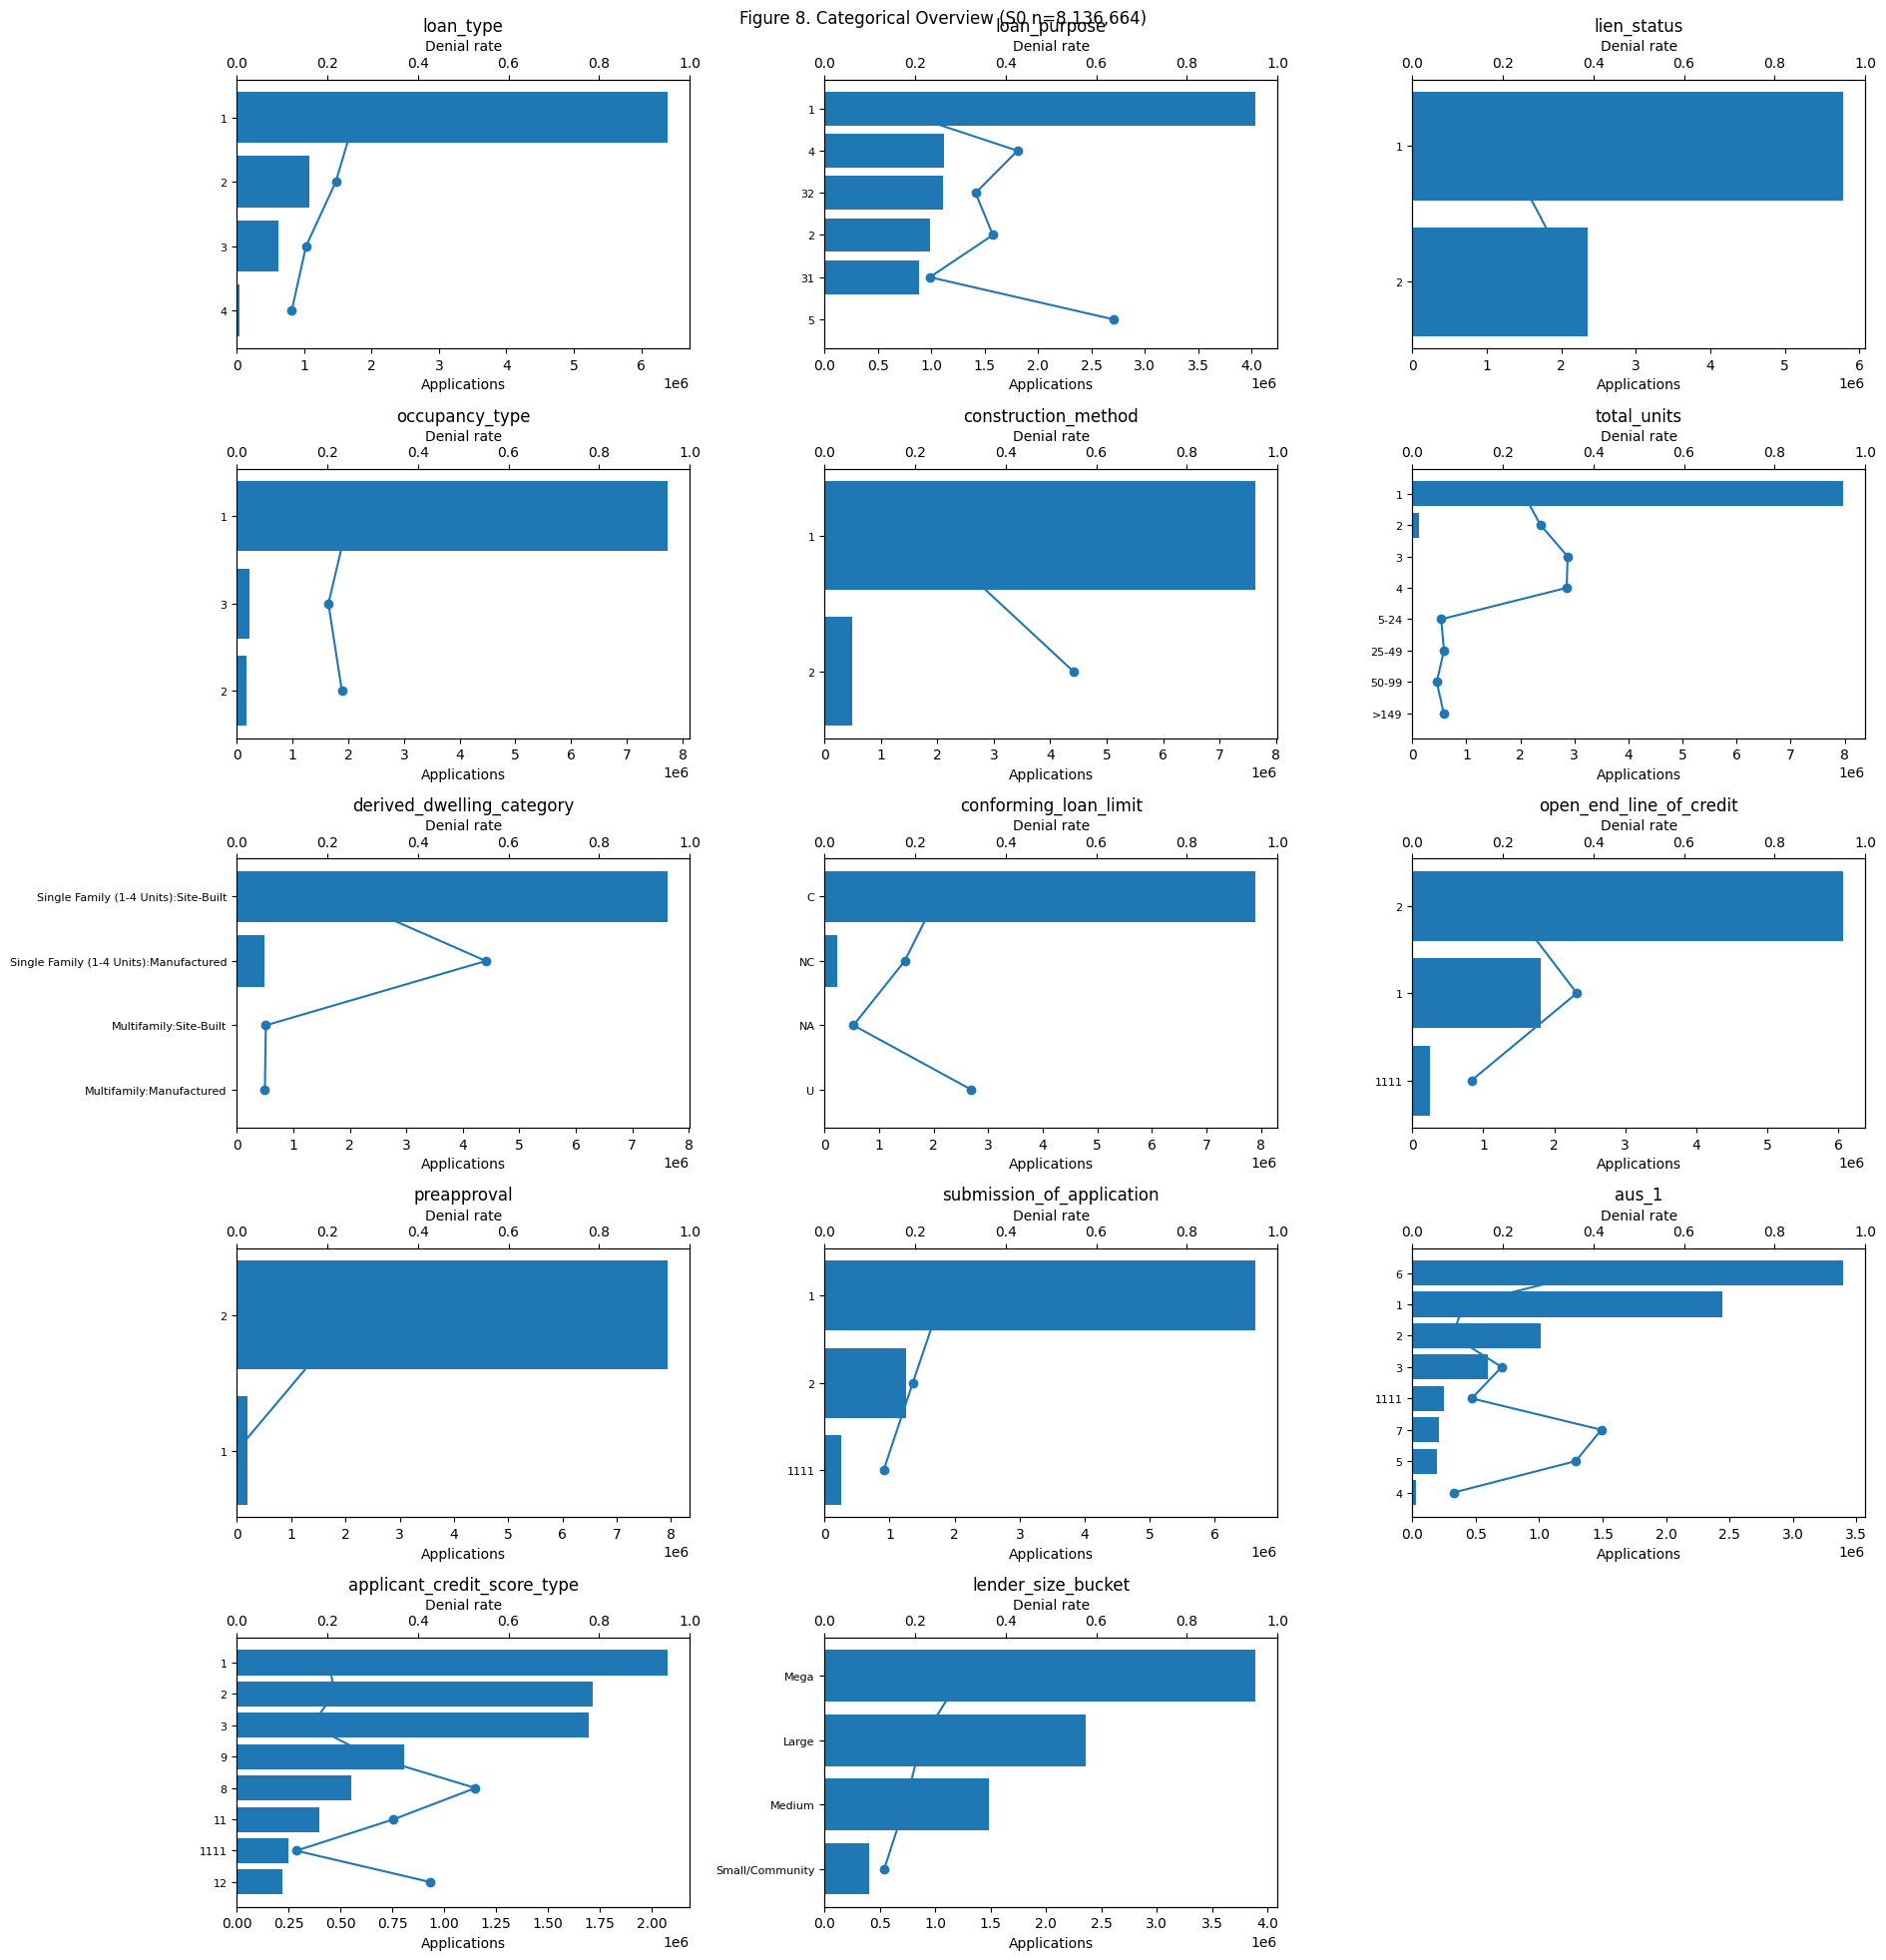


[B5.6 COMPLETED]
Figure 8 saved successfully.


In [54]:
# ============================================================
# B5.6. PLOT CATEGORICAL DISTRIBUTIONS
# ============================================================

import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Step 1. Load B5 categorical summary
# ------------------------------------------------------------

output_dir = os.fspath(OUTPUT_DIR)
figure_dir = os.fspath(FIGURE_DIR)

os.makedirs(figure_dir, exist_ok=True)

# Reuse existing b5_pdf if available.
# Otherwise load the previously exported CSV.

if "b5_pdf" not in globals():

    csv_path = os.path.join(
        output_dir,
        "B15_categorical_summary.csv"
    )

    assert os.path.exists(csv_path), (
        f"Cannot find B5 summary: {csv_path}. "
        "Run B5.5 aggregation first."
    )

    b5_pdf = pd.read_csv(csv_path)

    print("Loaded B5 summary from CSV.")

# Validate required columns.
required_cols = [
    "variable",
    "category",
    "n",
    "denial_rate"
]

missing = [
    c for c in required_cols
    if c not in b5_pdf.columns
]

assert not missing, (
    f"Missing columns in B5 summary: {missing}"
)

# Recover categorical variable list if necessary.
if "B5_CATEGORICAL" not in globals():

    B5_CATEGORICAL = (
        b5_pdf["variable"]
        .dropna()
        .unique()
        .tolist()
    )

print("Categorical variables:", len(B5_CATEGORICAL))
print("Summary rows:", len(b5_pdf))


# ------------------------------------------------------------
# Step 2. Prepare figure
# ------------------------------------------------------------

ncols = 3
nrows = max(
    1,
    math.ceil(len(B5_CATEGORICAL) / ncols)
)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(19, nrows * 4)
)

axes = np.array(axes).flatten()


# ------------------------------------------------------------
# Step 3. Plot distributions
# ------------------------------------------------------------

for ax, variable in zip(axes, B5_CATEGORICAL):

    subset = (
        b5_pdf[
            b5_pdf["variable"] == variable
        ]
        .sort_values(
            "n",
            ascending=False
        )
        .head(8)
        .sort_values("n")
    )

    if subset.empty:
        ax.set_visible(False)
        continue

    y = np.arange(len(subset))

    ax.barh(
        y,
        subset["n"]
    )

    ax.set_yticks(y)

    ax.set_yticklabels(
        subset["category"].astype(str),
        fontsize=8
    )

    ax.set_title(variable)
    ax.set_xlabel("Applications")

    ax2 = ax.twiny()

    ax2.plot(
        subset["denial_rate"],
        y,
        marker="o"
    )

    ax2.set_xlim(0, 1)
    ax2.set_xlabel("Denial rate")


# Hide unused axes.
for ax in axes[len(B5_CATEGORICAL):]:
    ax.set_visible(False)


# ------------------------------------------------------------
# Step 4. Save Figure 8
# ------------------------------------------------------------

plot_s0_n = (
    s0_n if "s0_n" in globals()
    else df_s0.count()
)

fig.suptitle(
    f"Figure 8. Categorical Overview (S0 n={plot_s0_n:,})"
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        figure_dir,
        "B15_fig_08_categorical_overview.png"
    ),
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\n[B5.6 COMPLETED]")
print("Figure 8 saved successfully.")

## B6–B7. Outlier Diagnostics and Duplicate Analysis

### B6. Outliers versus data errors

**Input**
- Full S0 analytic sample (`df_s0`).
- B07 validation flags V01–V05 and V09.
- Financial variables: loan_amount, property_value, income,
  loan_to_income, combined_loan_to_value_ratio, and ltv_calc.

**Process**
- Resolve the original validation flags from B07.
- Join flags using row_id only when necessary.
- Compare flagged and non-flagged observations.
- Calculate application counts, denial counts, denial rates,
  and financial distribution statistics.
- Distinguish validation-rule violations from genuine
  extreme financial observations.

**Output**
- B15_outlier_flag_profile.csv
- Figure 9: Denial rates by validation flag.

### B7. Duplicate analysis

**Input**
- flag_dup_extra
- dup_group_size
- is_denied
- derived_race

**Process**
- Separate original records from extra duplicate records.
- Calculate duplicate-row share and denial rates.
- Examine duplicate group sizes.
- Examine the racial composition of extra duplicate records.

**Output**
- B15_duplicate_profile.csv
- Figure 10: Duplicate record profile.

### Analytical considerations

- All counts and rates use full S0.
- Missing flags are retained as Unknown, not automatically
  classified as non-flagged.
- V02 and V03 receive particular attention.
- Duplicate extra rows are not automatically interpreted
  as erroneous applications.
- B07 cleaning decisions are not modified.

In [55]:
# Diagnostic: Check available validation columns

print("df_s0 type:", type(df_s0))
print("df_all_min type:", type(globals().get("df_all_min")))

print("\nPotential V-flag columns:")

for c in df_s0.columns:
    if any(
        code.lower() in c.lower()
        for code in ["V01", "V02", "V03", "V04", "V05", "V09"]
    ):
        print(c)

print("\nAll columns containing 'flag':")

for c in df_s0.columns:
    if "flag" in c.lower():
        print(c)

df_s0 type: <class 'pyspark.sql.classic.dataframe.DataFrame'>
df_all_min type: <class 'pyspark.sql.classic.dataframe.DataFrame'>

Potential V-flag columns:
in_s5_keep_v02

All columns containing 'flag':
flag_coapp_discordant
flag_tract_income_zero
flag_loan_amount_invalid
flag_income_nonpositive
flag_income_zero
flag_income_negative
flag_cltv_range
flag_rate_le0
flag_rate_gt25
flag_rate_range
flag_term_range
flag_id_format
flag_geo_mismatch
flag_denial_inconsistent
flag_dr1_is_1111
flag_dup_extra


### B legacy cell 83 — B6 Diagnostic - Spark health check [CHANGE: documentation]

**Input:** In-memory DataFrames and configuration produced by preceding cells in Part B, including `df_s0` where referenced.

**Process:** Execute the existing B-series calculation or chart exactly as coded below, retaining existing population and source-value handling. Existing blocks longer than 40 lines remain intact to avoid changing unverified B14-sensitive behavior.

**Output:** Existing named intermediate results, tables or figures defined directly in the next code cell.

**Validation / limitation:** Legacy logic preserved; its denominators, category rules and B14 parity require runtime verification. [Verified: uploaded B15 notebook source].

In [56]:
# B6 Diagnostic - Spark health check

print("1. Spark version:")
print(spark.version)

print("\n2. Spark application:")
print(spark.sparkContext.applicationId)

print("\n3. JVM health:")
print(spark.range(1).count())

print("\n4. S0 schema:")
print(df_s0.schema.simpleString())

print("\n5. S0 sample:")
print(df_s0.limit(1).collect())

print("\n6. Memory configuration:")
print(
    "Driver memory:",
    spark.sparkContext.getConf().get(
        "spark.driver.memory", "Not configured"
    )
)

print("Diagnostic completed.")

1. Spark version:
4.2.0

2. Spark application:
local-1795428901471

3. JVM health:
1

4. S0 schema:
struct<activity_year:bigint,lei:string,derived_msa_md:string,state_code:string,county_code:string,census_tract:string,conforming_loan_limit:string,derived_loan_product_type:string,derived_dwelling_category:string,derived_ethnicity:string,derived_race:string,derived_sex:string,action_taken:string,purchaser_type:string,preapproval:string,loan_type:string,loan_purpose:string,lien_status:string,reverse_mortgage:string,open_end_line_of_credit:string,business_or_commercial_purpose:string,loan_amount:double,combined_loan_to_value_ratio:double,interest_rate:double,rate_spread:double,hoepa_status:string,total_loan_costs:double,total_points_and_fees:double,origination_charges:double,discount_points:double,lender_credits:double,loan_term:bigint,prepayment_penalty_term:bigint,intro_rate_period:bigint,negative_amortization:string,interest_only_payment:string,balloon_payment:string,other_nonamortizing

### B legacy cell 84 — ============================================================ [CHANGE: documentation]

**Input:** In-memory DataFrames and configuration produced by preceding cells in Part B, including `df_s0` where referenced.

**Process:** Execute the existing B-series calculation or chart exactly as coded below, retaining existing population and source-value handling. Existing blocks longer than 40 lines remain intact to avoid changing unverified B14-sensitive behavior.

**Output:** Existing named intermediate results, tables or figures defined directly in the next code cell.

**Validation / limitation:** Legacy logic preserved; its denominators, category rules and B14 parity require runtime verification. [Verified: uploaded B15 notebook source].

Validation flags: {'V01': 'flag_loan_amount_invalid', 'V02': 'flag_income_nonpositive', 'V03': 'flag_cltv_range', 'V04': 'flag_rate_range', 'V05': 'flag_term_range'}
Financial variables: ['loan_amount', 'property_value', 'income', 'loan_to_income', 'combined_loan_to_value_ratio', 'ltv_calc']

Running single-pass aggregation...
Aggregation completed.

S0 records: 8,136,664
Validation checks passed.
CSV exported: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_outlier_flag_profile.csv


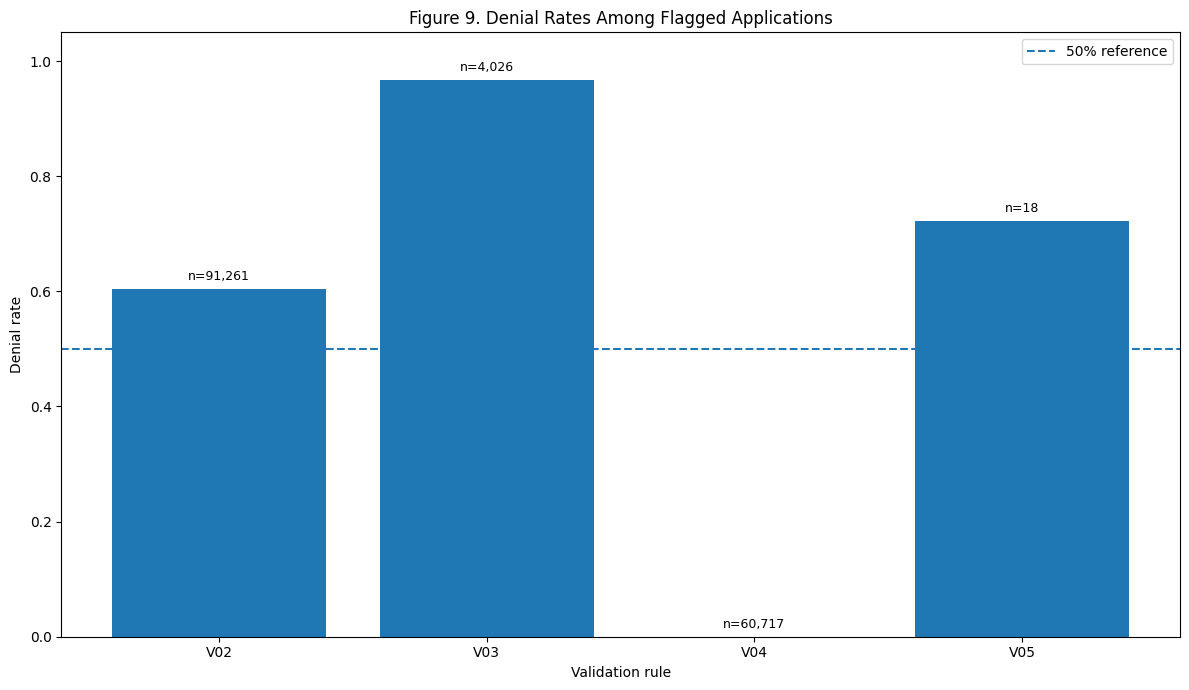


========== B6 COMPLETED ==========
S0: 8,136,664
Flags analyzed: 5
Financial variables: 6
CSV: B15_outlier_flag_profile.csv
Figure: B15_fig_09_outlier_flag_denial.png


,flag_code,flag_status,n,share_s0,denied_n,denial_rate
0,V01,Flagged,0,0.0000,0,NaN
1,V01,Not flagged,8136664,1.0000,2003276,0.2462
2,V01,Unknown,0,0.0000,0,NaN
3,V02,Flagged,91261,0.0112,55207,0.6049
4,V02,Not flagged,8045403,0.9888,1948069,0.2421
5,V02,Unknown,0,0.0000,0,NaN
6,V03,Flagged,4026,0.0005,3896,0.9677
7,V03,Not flagged,8132638,0.9995,1999380,0.2458
8,V03,Unknown,0,0.0000,0,NaN
9,V04,Flagged,60717,0.0075,0,0.0000


In [57]:
# ============================================================
# B6. OUTLIERS VERSUS DATA ERRORS
# Optimized single-pass aggregation
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F

# ------------------------------------------------------------
# Step 1. Initialize
# ------------------------------------------------------------

output_dir = os.fspath(OUTPUT_DIR)
figure_dir = os.fspath(FIGURE_DIR)

os.makedirs(output_dir, exist_ok=True)
os.makedirs(figure_dir, exist_ok=True)

V_FLAGS = {
    "V01": "flag_loan_amount_invalid",
    "V02": "flag_income_nonpositive",
    "V03": "flag_cltv_range",
    "V04": "flag_rate_range",
    "V05": "flag_term_range"
}

NUMERIC_VARS = [
    c for c in [
        "loan_amount",
        "property_value",
        "income",
        "loan_to_income",
        "combined_loan_to_value_ratio",
        "ltv_calc"
    ]
    if c in df_s0.columns
]

FLAG_COLS = list(V_FLAGS.values())

missing = [
    c for c in FLAG_COLS
    if c not in df_s0.columns
]

assert not missing, f"Missing flags: {missing}"
assert "is_denied" in df_s0.columns

print("Validation flags:", V_FLAGS)
print("Financial variables:", NUMERIC_VARS)

# ------------------------------------------------------------
# Step 2. Build conditional aggregation expressions
# ------------------------------------------------------------

raw_flags = {}

for code, flag in V_FLAGS.items():

    raw_flags[code] = F.lower(
        F.trim(F.col(flag).cast("string"))
    )

denied = F.col("is_denied").cast("double")

agg_exprs = []

STATUS_CONDITIONS = {
    "Flagged": lambda x: x.isin(
        "1", "1.0", "true", "t", "yes", "y"
    ),

    "Not flagged": lambda x: x.isin(
        "0", "0.0", "false", "f", "no", "n"
    ),

    "Unknown": lambda x: (
        x.isNull()
        | ~x.isin(
            "1", "1.0", "true", "t", "yes", "y",
            "0", "0.0", "false", "f", "no", "n"
        )
    )
}

for code, flag in V_FLAGS.items():

    raw = raw_flags[code]

    for status, condition_fn in STATUS_CONDITIONS.items():

        condition = condition_fn(raw)

        key = f"{code}_{status.replace(' ', '_')}"

        # Application count
        agg_exprs.append(
            F.sum(
                F.when(condition, 1).otherwise(0)
            ).alias(f"n__{key}")
        )

        # Denied application count
        agg_exprs.append(
            F.sum(
                F.when(
                    condition & (denied == 1),
                    1
                ).otherwise(0)
            ).alias(f"denied__{key}")
        )

        # Valid outcome count
        agg_exprs.append(
            F.sum(
                F.when(
                    condition & denied.isNotNull(),
                    1
                ).otherwise(0)
            ).alias(f"outcome__{key}")
        )

        # Financial statistics
        for var in NUMERIC_VARS:

            x = F.col(var).cast("double")

            agg_exprs.extend([
                F.count(
                    F.when(condition, x)
                ).alias(f"{var}_n__{key}"),

                F.avg(
                    F.when(condition, x)
                ).alias(f"{var}_mean__{key}")
            ])

# ------------------------------------------------------------
# Step 3. Execute ONE aggregation on S0
# ------------------------------------------------------------

print("\nRunning single-pass aggregation...")

summary_row = df_s0.agg(*agg_exprs).first()

assert summary_row is not None, "Empty aggregation result."

summary = summary_row.asDict()

print("Aggregation completed.")

# ------------------------------------------------------------
# Step 4. Convert small aggregate result to Pandas
# ------------------------------------------------------------

records = []

for code, flag in V_FLAGS.items():

    for status in STATUS_CONDITIONS:

        key = f"{code}_{status.replace(' ', '_')}"

        n = int(summary.get(f"n__{key}") or 0)

        denied_n = int(
            summary.get(f"denied__{key}") or 0
        )

        outcome_n = int(
            summary.get(f"outcome__{key}") or 0
        )

        record = {
            "flag_code": code,
            "flag_name": flag,
            "flag_status": status,
            "n": n,
            "denied_n": denied_n,
            "outcome_n": outcome_n,
            "denial_rate": (
                denied_n / outcome_n
                if outcome_n > 0 else None
            )
        }

        for var in NUMERIC_VARS:

            record[f"{var}_valid_n"] = int(
                summary.get(f"{var}_n__{key}") or 0
            )

            record[f"{var}_mean"] = summary.get(
                f"{var}_mean__{key}"
            )

        records.append(record)

b6_pdf = pd.DataFrame(records)

# ------------------------------------------------------------
# Step 5. Validate full S0 coverage
# ------------------------------------------------------------

totals = (
    b6_pdf
    .groupby("flag_code")["n"]
    .sum()
)

s0_n = int(totals.loc["V01"])

for code in V_FLAGS:

    assert int(totals.loc[code]) == s0_n, (
        f"{code} does not account for full S0."
    )

b6_pdf["share_s0"] = b6_pdf["n"] / s0_n

print("\nS0 records:", f"{s0_n:,}")
print("Validation checks passed.")

# ------------------------------------------------------------
# Step 6. Export CSV
# ------------------------------------------------------------

csv_path = os.path.join(
    output_dir,
    "B15_outlier_flag_profile.csv"
)

b6_pdf.to_csv(
    csv_path,
    index=False,
    encoding="utf-8"
)

print("CSV exported:", csv_path)

# ------------------------------------------------------------
# Step 7. Generate Figure 9
# ------------------------------------------------------------

plot_data = b6_pdf[
    b6_pdf["flag_status"] == "Flagged"
].copy()

plot_data = plot_data.sort_values(
    "flag_code"
)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.bar(
    plot_data["flag_code"],
    plot_data["denial_rate"]
)

ax.axhline(
    0.50,
    linestyle="--",
    label="50% reference"
)

ax.set_ylim(0, 1.05)

ax.set_xlabel("Validation rule")
ax.set_ylabel("Denial rate")

ax.set_title(
    "Figure 9. Denial Rates Among Flagged Applications"
)

for bar, (_, row) in zip(
    bars,
    plot_data.iterrows()
):

    if pd.notna(row["denial_rate"]):

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.015,
            f"n={int(row['n']):,}",
            ha="center",
            fontsize=9
        )

ax.legend()
fig.tight_layout()

fig.savefig(
    os.path.join(
        figure_dir,
        "B15_fig_09_outlier_flag_denial.png"
    ),
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Step 8. Final summary
# ------------------------------------------------------------

print("\n========== B6 COMPLETED ==========")
print("S0:", f"{s0_n:,}")
print("Flags analyzed:", len(V_FLAGS))
print("Financial variables:", len(NUMERIC_VARS))
print("CSV: B15_outlier_flag_profile.csv")
print("Figure: B15_fig_09_outlier_flag_denial.png")

display(
    b6_pdf[
        [
            "flag_code",
            "flag_status",
            "n",
            "share_s0",
            "denied_n",
            "denial_rate"
        ]
    ]
)

### B legacy cell 85 — ============================================================ [CHANGE: documentation]

**Input:** In-memory DataFrames and configuration produced by preceding cells in Part B, including `df_s0` where referenced.

**Process:** Execute the existing B-series calculation or chart exactly as coded below, retaining existing population and source-value handling. Existing blocks longer than 40 lines remain intact to avoid changing unverified B14-sensitive behavior.

**Output:** Existing named intermediate results, tables or figures defined directly in the next code cell.

**Validation / limitation:** Legacy logic preserved; its denominators, category rules and B14 parity require runtime verification. [Verified: uploaded B15 notebook source].

Resolved duplicate columns: {'flag_dup_extra': 'flag_dup_extra', 'dup_group_size': 'dup_group_size'}


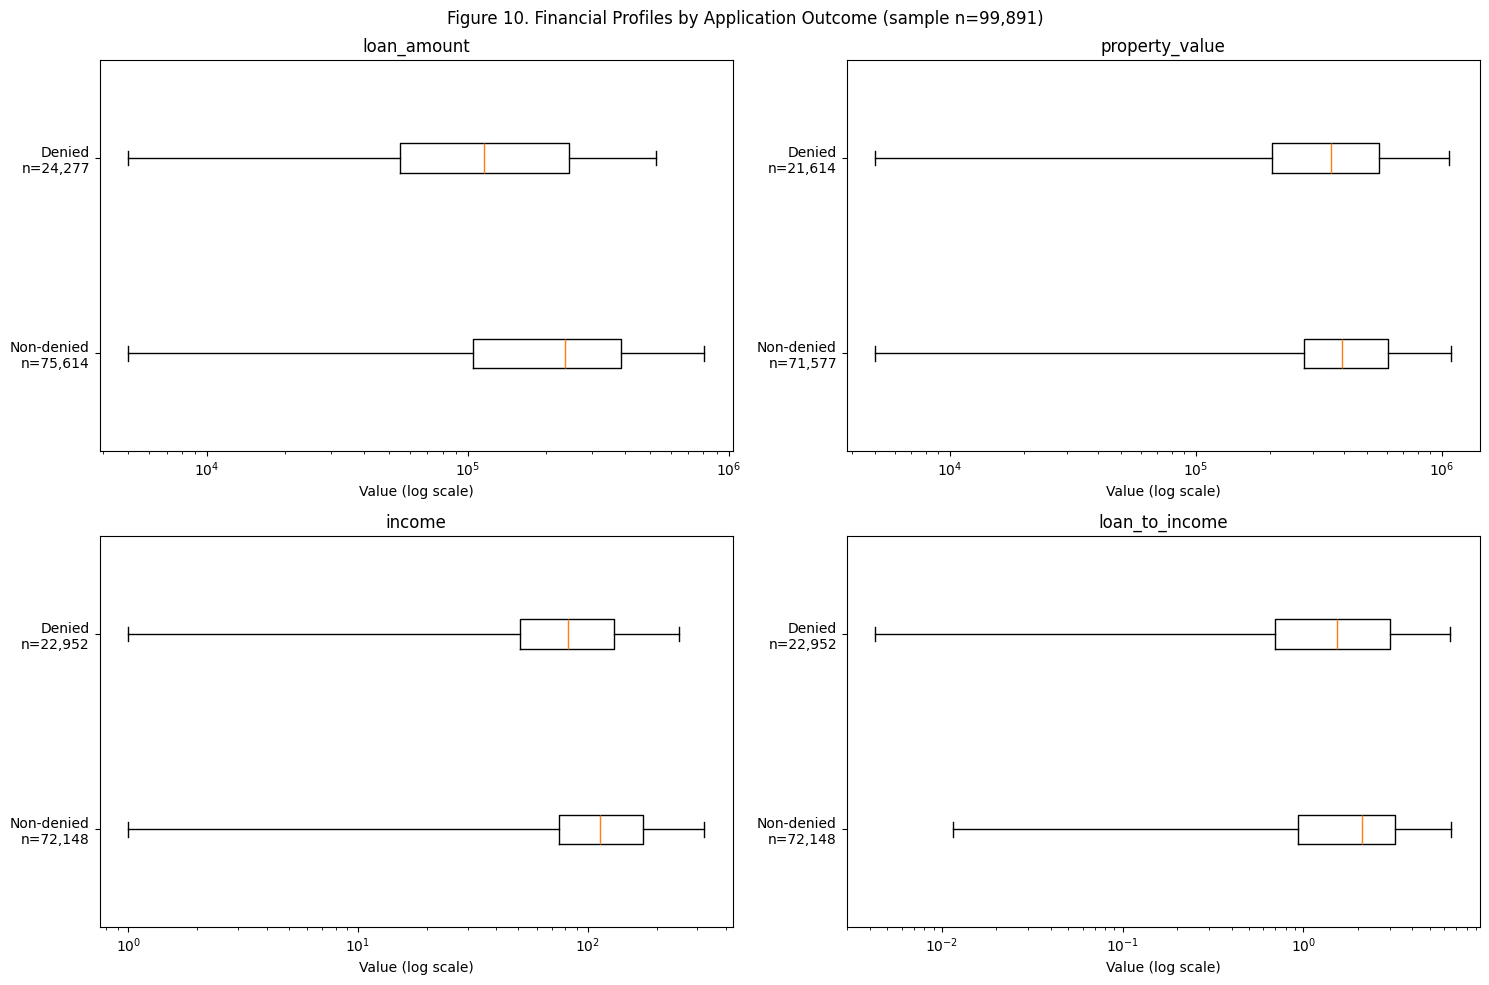

B7 completed.
Total S0: 8,136,664
Extra duplicate records: 4,499
Extra duplicate share: 0.0553%
Output: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output


In [58]:
# ============================================================
# B7. DUPLICATE ANALYSIS + FIGURE 10
# ============================================================

import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pyspark.sql import functions as F


# ------------------------------------------------------------
# 1. Initialize paths independently
# ------------------------------------------------------------

output_dir = os.fspath(
    globals().get("OUTPUT_DIR", "B15 - EDA PySpark output")
)

figure_dir = os.fspath(
    globals().get(
        "FIGURE_DIR",
        os.path.join(output_dir, "figures")
    )
)

os.makedirs(output_dir, exist_ok=True)
os.makedirs(figure_dir, exist_ok=True)


# ------------------------------------------------------------
# 2. Resolve duplicate variables
# ------------------------------------------------------------

DUP_COLS = [
    "flag_dup_extra",
    "dup_group_size"
]

def normalize_duplicate_name(name):
    return re.sub(r"[^a-z0-9]", "", name.lower())


def find_duplicate_column(frame, target):

    target_norm = normalize_duplicate_name(target)

    matches = [
        c for c in frame.columns
        if normalize_duplicate_name(c) == target_norm
    ]

    return matches[0] if len(matches) == 1 else None


dup_map = {}
dup_source = {}

for target in DUP_COLS:

    col = find_duplicate_column(df_s0, target)

    if col is not None:

        dup_map[target] = col
        dup_source[target] = "df_s0"

    elif "df_all_min" in globals():

        # Reuse the conversion function if B6 was run.
        if "df_all_min_spark" not in globals():

            if isinstance(df_all_min, pd.DataFrame):
                df_all_min_spark = spark.createDataFrame(df_all_min)
            else:
                df_all_min_spark = df_all_min

        col = find_duplicate_column(
            df_all_min_spark,
            target
        )

        if col is not None:

            dup_map[target] = col
            dup_source[target] = "df_all_min"

if len(dup_map) != len(DUP_COLS):

    raise ValueError(
        f"Cannot resolve duplicate variables: {dup_map}"
    )

print("Resolved duplicate columns:", dup_map)


# ------------------------------------------------------------
# 3. Join external duplicate variables if necessary
# ------------------------------------------------------------

df_b7 = df_s0

external_dup = [
    c for c in DUP_COLS
    if dup_source[c] == "df_all_min"
]

if external_dup:

    assert "row_id" in df_s0.columns
    assert "row_id" in df_all_min_spark.columns

    right = df_all_min_spark.select(
        F.col("row_id").cast("string").alias("__b7_key"),
        *[
            F.col(dup_map[c]).alias(f"__{c}")
            for c in external_dup
        ]
    )

    assert (
        right
        .groupBy("__b7_key")
        .count()
        .filter(F.col("count") > 1)
        .limit(1)
        .count() == 0
    ), "Duplicate row_id in B07 audit source."

    left = df_b7.withColumn(
        "__b7_key",
        F.col("row_id").cast("string")
    )

    df_b7 = (
        left
        .join(right, on="__b7_key", how="left")
        .drop("__b7_key")
    )

for c in DUP_COLS:

    if dup_source[c] == "df_s0":

        df_b7 = df_b7.withColumn(
            f"__{c}",
            F.col(dup_map[c])
        )

s0_n = df_s0.count()

assert df_b7.count() == s0_n, (
    "B7 join changed S0 row count."
)


# ------------------------------------------------------------
# 4. Classify duplicate records
# ------------------------------------------------------------

flag_value = F.lower(
    F.trim(
        F.col("__flag_dup_extra").cast("string")
    )
)

group_size = F.col(
    "__dup_group_size"
).cast("double")

is_extra = flag_value.isin(
    "1", "1.0", "true", "t", "yes", "y"
)

is_not_extra = flag_value.isin(
    "0", "0.0", "false", "f", "no", "n"
)

df_b7 = df_b7.withColumn(
    "duplicate_status",

    F.when(
        is_extra,
        "Extra duplicate"
    )
    .when(
        is_not_extra & (group_size > 1),
        "Original duplicate"
    )
    .when(
        is_not_extra & (group_size == 1),
        "Non-duplicate"
    )
    .otherwise("Unknown")
)


# ------------------------------------------------------------
# 5. Duplicate status summary
# ------------------------------------------------------------

dup_summary = (
    df_b7
    .groupBy("duplicate_status")
    .agg(
        F.count("*").alias("n"),

        F.sum(
            F.when(
                F.col("is_denied").cast("double") == 1,
                1
            ).otherwise(0)
        ).alias("denied_n"),

        F.avg(
            F.col("is_denied").cast("double")
        ).alias("denial_rate"),

        F.avg(group_size).alias("mean_dup_group_size"),

        F.percentile_approx(
            group_size, 0.50, 10000
        ).alias("median_dup_group_size"),

        F.max(group_size).alias("max_dup_group_size")
    )
    .withColumn(
        "share",
        F.col("n") / F.lit(s0_n)
    )
    .withColumn(
        "record_type",
        F.lit("duplicate_status")
    )
    .withColumnRenamed(
        "duplicate_status",
        "category"
    )
)


# ------------------------------------------------------------
# 6. Race composition of extra duplicate records
# ------------------------------------------------------------

df_extra = df_b7.filter(
    F.col("duplicate_status") == "Extra duplicate"
)

extra_n = df_extra.count()

if "derived_race" in df_b7.columns:

    race_expr = F.coalesce(
        F.col("derived_race").cast("string"),
        F.lit("__NULL__")
    )

else:

    race_expr = F.lit("__RACE_NOT_AVAILABLE__")

race_mix = (
    df_extra
    .withColumn("category", race_expr)
    .groupBy("category")
    .agg(
        F.count("*").alias("n"),

        F.sum(
            F.when(
                F.col("is_denied").cast("double") == 1,
                1
            ).otherwise(0)
        ).alias("denied_n"),

        F.avg(
            F.col("is_denied").cast("double")
        ).alias("denial_rate")
    )
    .withColumn(
        "share",
        F.col("n") / F.lit(max(extra_n, 1))
    )
    .withColumn(
        "record_type",
        F.lit("race_mix_among_extras")
    )
    .withColumn(
        "mean_dup_group_size",
        F.lit(None).cast("double")
    )
    .withColumn(
        "median_dup_group_size",
        F.lit(None).cast("double")
    )
    .withColumn(
        "max_dup_group_size",
        F.lit(None).cast("double")
    )
)


# ------------------------------------------------------------
# 7. Duplicate group-size distribution
# ------------------------------------------------------------

size_distribution = (
    df_b7
    .groupBy("__dup_group_size")
    .agg(
        F.count("*").alias("n")
    )
    .withColumn(
        "category",
        F.coalesce(
            F.col("__dup_group_size").cast("string"),
            F.lit("__NULL__")
        )
    )
    .withColumn(
        "share",
        F.col("n") / F.lit(s0_n)
    )
    .withColumn(
        "record_type",
        F.lit("duplicate_group_size")
    )
    .withColumn(
        "denied_n",
        F.lit(None).cast("long")
    )
    .withColumn(
        "denial_rate",
        F.lit(None).cast("double")
    )
    .withColumn(
        "mean_dup_group_size",
        F.lit(None).cast("double")
    )
    .withColumn(
        "median_dup_group_size",
        F.lit(None).cast("double")
    )
    .withColumn(
        "max_dup_group_size",
        F.lit(None).cast("double")
    )
)


# ------------------------------------------------------------
# 8. Combine and export duplicate profile
# ------------------------------------------------------------

OUTPUT_COLS = [
    "record_type",
    "category",
    "n",
    "share",
    "denied_n",
    "denial_rate",
    "mean_dup_group_size",
    "median_dup_group_size",
    "max_dup_group_size"
]

b7_result = (
    dup_summary.select(*OUTPUT_COLS)
    .unionByName(race_mix.select(*OUTPUT_COLS))
    .unionByName(size_distribution.select(*OUTPUT_COLS))
)

b7_pdf = b7_result.toPandas()

b7_pdf.to_csv(
    os.path.join(
        output_dir,
        "B15_duplicate_profile.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# 9. Figure 10: Financial boxplots by outcome
# ------------------------------------------------------------

BOX_VARS = [
    c for c in [
        "loan_amount",
        "property_value",
        "income",
        "loan_to_income"
    ]
    if c in df_s0.columns
]

assert BOX_VARS, "No financial variables available for Figure 10."

require_outcome = "is_denied" in df_s0.columns
assert require_outcome, "Missing is_denied."

# Bounded sample for visualization only.
plot_n = min(100000, s0_n)
plot_fraction = min(1.0, plot_n / max(s0_n, 1))

plot_pdf = (
    df_s0
    .select(*BOX_VARS, "is_denied")
    .sample(False, plot_fraction, 42)
    .limit(plot_n)
    .toPandas()
)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, variable in zip(axes.flatten(), BOX_VARS):

    box_data = []
    labels = []

    for outcome, label in [
        (0, "Non-denied"),
        (1, "Denied")
    ]:

        outcome_values = pd.to_numeric(
            plot_pdf["is_denied"],
            errors="coerce"
        )

        values = pd.to_numeric(
            plot_pdf.loc[
                outcome_values == outcome,
                variable
            ],
            errors="coerce"
        ).dropna()

        values = values[values > 0]

        if len(values):

            box_data.append(values.values)
            labels.append(
                f"{label}\nn={len(values):,}"
            )

    if box_data:

        ax.boxplot(
            box_data,
            vert=False,
            showfliers=False
        )

        ax.set_yticks(
            range(1, len(labels) + 1),
            labels
        )

        ax.set_xscale("log")

    ax.set_title(variable)
    ax.set_xlabel("Value (log scale)")

for ax in axes.flatten()[len(BOX_VARS):]:
    ax.set_visible(False)

fig.suptitle(
    f"Figure 10. Financial Profiles by Application Outcome "
    f"(sample n={len(plot_pdf):,})"
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        figure_dir,
        "B15_fig_10_boxplot_by_outcome.png"
    ),
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 10. Final B7 summary
# ------------------------------------------------------------

duplicate_share = extra_n / s0_n if s0_n else 0

print("B7 completed.")
print(f"Total S0: {s0_n:,}")
print(f"Extra duplicate records: {extra_n:,}")
print(f"Extra duplicate share: {duplicate_share:.4%}")
print(f"Output: {output_dir}")

# Part C — RQ1: Raw Denial Gap and Product Mix

## Research Objective

This section investigates whether mortgage denial rates differ across applicant racial groups and examines whether differences in mortgage product composition may contribute to the observed raw denial gap.

The analysis follows the approved B14 analytical definitions and uses the full S0 analytic sample from B07.

## Analytical Framework

| Block | Analysis | Main Outputs |
|---|---|---|
| C0 | Statistical foundations and shared functions | Reusable analytical helpers |
| C1 | Raw denial gap by derived_race | Denial rates, Wilson CI, risk ratios, odds ratios, bootstrap CI |
| C2 | Denial gaps across other demographic dimensions | Ethnicity, sex, age, co-applicant and race-ethnicity |
| C3 | Product composition by race | Product shares and heatmap |

## Key Analytical Decisions

- Primary race variable: `derived_race`, preserving all nine existing B14 categories.
- Reference group: White.
- Supplementary race dimension: existing five-group `race_ethnicity` from B14.
- Main outcome: `is_denied`.
- Main denominator: all S0 applications (`action_taken IN (1, 2, 3)`).
- Confidence intervals: 95% Wilson intervals for denial rates.
- Minimum reliability thresholds: 1,000 applications and 100 denied applications.
- Headline race gaps receive lender-cluster bootstrap confidence intervals (1,000 replications, seed 42).
- Race Not Available and Free Form Text Only remain separate categories and are excluded from headline race-gap comparisons.
- Missing categorical values are retained as explicit categories.

## Interpretation Boundary

All results in this section are descriptive. Raw denial-rate differences and product composition patterns do not independently establish discrimination or causal relationships.

In [59]:
# ============================================================
# C0-C1. FOUNDATION AND RAW DENIAL GAP
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F
from pyspark.sql import Window


# ------------------------------------------------------------
# C0.1. Configuration and validation
# ------------------------------------------------------------

C0_REFERENCE_RACE = "White"

C0_N_MIN_APPS = int(globals().get("N_MIN_APPS", 1000))
C0_N_MIN_DENIED = int(globals().get("N_MIN_DENIED", 100))

C0_BOOTSTRAP_B = 1000
C0_SEED = 42
C0_WILSON_Z = 1.959963984540054

C0_EXCLUDED_HEADLINE_GROUPS = [
    "Race Not Available",
    "Free Form Text Only"
]

C0_LENDER_CANDIDATES = [
    "lei",
    "lei_hash",
    "lender_id",
    "lei_id"
]

assert "df_s0" in globals(), "df_s0 is not available."
assert "OUTPUT_DIR" in globals()
assert "FIGURE_DIR" in globals()

C0_REQUIRED_COLUMNS = [
    "derived_race",
    "is_denied",
    "action_taken"
]

C0_MISSING = [
    c for c in C0_REQUIRED_COLUMNS
    if c not in df_s0.columns
]

assert not C0_MISSING, (
    f"Missing required columns: {C0_MISSING}"
)

C0_LENDER_COL = next(
    (
        c for c in C0_LENDER_CANDIDATES
        if c in df_s0.columns
    ),
    None
)

assert C0_LENDER_COL is not None, (
    "No lender identifier found. "
    "Check df_s0.columns before running C1."
)

os.makedirs(str(OUTPUT_DIR), exist_ok=True)
os.makedirs(str(FIGURE_DIR), exist_ok=True)

print("C0 configuration")
print("Reference race:", C0_REFERENCE_RACE)
print("Lender column:", C0_LENDER_COL)
print("Minimum applications:", C0_N_MIN_APPS)
print("Minimum denied:", C0_N_MIN_DENIED)
print("Bootstrap replications:", C0_BOOTSTRAP_B)


# ------------------------------------------------------------
# C0.2. Reusable Wilson CI and gap calculation
# ------------------------------------------------------------

def c0_add_rate_gap_metrics(
    counts_df,
    group_col,
    dimension_name,
    reference_level,
    excluded_levels=None,
    require_reference=True
):
    """
    Calculate denial rates, Wilson CI, risk ratios,
    odds ratios and reference-group gaps.
    """

    excluded_levels = excluded_levels or []

    base = counts_df.select(
        F.col(group_col).cast("string").alias("_group_value"),
        F.col("n_applications").cast("long"),
        F.col("n_denied").cast("long")
    )

    ref = (
        base
        .filter(
            F.col("_group_value") == reference_level
        )
        .select(
            F.col("n_applications").alias("_ref_n_apps"),
            F.col("n_denied").alias("_ref_n_denied")
        )
    )

    reference_found = ref.limit(1).count() > 0

    if require_reference and not reference_found:
        raise ValueError(
            f"Reference '{reference_level}' not found "
            f"in dimension {dimension_name}."
        )

    if reference_found:
        out = base.crossJoin(ref)
    else:
        out = (
            base
            .withColumn(
                "_ref_n_apps",
                F.lit(None).cast("long")
            )
            .withColumn(
                "_ref_n_denied",
                F.lit(None).cast("long")
            )
        )

    # Denial rate
    out = out.withColumn(
        "denial_rate",
        F.when(
            F.col("n_applications") > 0,
            F.col("n_denied") / F.col("n_applications")
        )
    )

    out = out.withColumn(
        "_ref_rate",
        F.when(
            F.col("_ref_n_apps") > 0,
            F.col("_ref_n_denied") / F.col("_ref_n_apps")
        )
    )

    # Wilson confidence interval
    z = C0_WILSON_Z
    z2 = z ** 2

    n = F.col("n_applications")
    p = F.col("denial_rate")

    wilson_den = 1 + z2 / n

    wilson_center = (
        p + z2 / (2 * n)
    ) / wilson_den

    wilson_half = (
        z * F.sqrt(
            p * (1 - p) / n
            + z2 / (4 * n * n)
        ) / wilson_den
    )

    out = (
        out
        .withColumn(
            "wilson_ci_low",
            F.when(n > 0, wilson_center - wilson_half)
        )
        .withColumn(
            "wilson_ci_high",
            F.when(n > 0, wilson_center + wilson_half)
        )
    )

    # Reference and reliability flags
    out = (
        out
        .withColumn(
            "is_reference_group",
            F.col("_group_value") == reference_level
        )
        .withColumn(
            "is_headline_group",
            ~F.col("_group_value").isin(*excluded_levels)
            if excluded_levels
            else F.lit(True)
        )
        .withColumn(
            "low_n",
            (F.col("n_applications") < C0_N_MIN_APPS)
            | (F.col("n_denied") < C0_N_MIN_DENIED)
        )
        .withColumn(
            "reference_low_n",
            (F.col("_ref_n_apps") < C0_N_MIN_APPS)
            | (F.col("_ref_n_denied") < C0_N_MIN_DENIED)
        )
    )

    # Risk difference in percentage points
    out = out.withColumn(
        "gap_vs_reference_pp",
        F.when(
            F.col("is_headline_group")
            & F.col("_ref_rate").isNotNull(),
            (
                F.col("denial_rate")
                - F.col("_ref_rate")
            ) * 100
        )
    )

    # Risk ratio
    out = out.withColumn(
        "risk_ratio",
        F.when(
            F.col("is_headline_group")
            & (F.col("_ref_rate") > 0),
            F.col("denial_rate") / F.col("_ref_rate")
        )
    )

    # Odds ratio
    g_not_denied = (
        F.col("n_applications") - F.col("n_denied")
    )

    ref_not_denied = (
        F.col("_ref_n_apps") - F.col("_ref_n_denied")
    )

    out = out.withColumn(
        "odds_ratio",
        F.when(
            F.col("is_headline_group")
            & (F.col("n_denied") > 0)
            & (g_not_denied > 0)
            & (F.col("_ref_n_denied") > 0)
            & (ref_not_denied > 0),
            (
                F.col("n_denied") * ref_not_denied
            ) / (
                g_not_denied * F.col("_ref_n_denied")
            )
        )
    )

    # Log-odds-ratio confidence interval
    se_log_or = F.sqrt(
        1 / F.col("n_denied")
        + 1 / g_not_denied
        + 1 / F.col("_ref_n_denied")
        + 1 / ref_not_denied
    )

    log_or = F.log("odds_ratio")

    out = (
        out
        .withColumn(
            "or_ci_low",
            F.when(
                F.col("is_reference_group"),
                F.lit(1.0)
            ).when(
                F.col("odds_ratio") > 0,
                F.exp(log_or - z * se_log_or)
            )
        )
        .withColumn(
            "or_ci_high",
            F.when(
                F.col("is_reference_group"),
                F.lit(1.0)
            ).when(
                F.col("odds_ratio") > 0,
                F.exp(log_or + z * se_log_or)
            )
        )
    )

    out = out.withColumn(
        "is_comparable",
        F.col("is_headline_group")
        & ~F.col("low_n")
        & ~F.col("reference_low_n")
    )

    return out.select(
        F.lit(dimension_name).alias("dimension"),
        F.col("_group_value").alias("group_value"),
        F.lit(reference_level).alias("reference_group"),
        "n_applications",
        "n_denied",
        "denial_rate",
        "wilson_ci_low",
        "wilson_ci_high",
        "gap_vs_reference_pp",
        "risk_ratio",
        "odds_ratio",
        "or_ci_low",
        "or_ci_high",
        "is_reference_group",
        "is_headline_group",
        "low_n",
        "reference_low_n",
        "is_comparable"
    )

C0 configuration
Reference race: White
Lender column: lei
Minimum applications: 1000
Minimum denied: 100
Bootstrap replications: 1000


In [60]:

# ============================================================
# C1. RAW DENIAL GAP BY RACE
# FIX: NATIVE SPARK DATAFRAME (NO PYTHON WORKER)
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# ------------------------------------------------------------
# Step 1. Ensure C1_RAW_GAP and bootstrap results are available
# ------------------------------------------------------------

if "C1_RAW_GAP" not in globals():
    C1_COUNTS = (
        df_s0
        .groupBy("derived_race")
        .agg(
            F.count("*").alias("n_applications"),
            F.sum(F.col("is_denied").cast("long")).alias("n_denied")
        )
    )
    C1_RAW_GAP = c0_add_rate_gap_metrics(
        counts_df=C1_COUNTS,
        group_col="derived_race",
        dimension_name="derived_race",
        reference_level=C0_REFERENCE_RACE,
        excluded_levels=C0_EXCLUDED_HEADLINE_GROUPS,
        require_reference=True
    )

if "C1_BOOT_ROWS" not in globals():
    C1_BOOT_ROWS = []
    b14_raw_candidates = [
        PROJECT_ROOT / "B14 - EDA" / "output" / "B14_rq1_raw_gap.csv",
        PROJECT_ROOT / "output" / "B14_rq1_raw_gap.csv",
        CURRENT_DIR / "B14_rq1_raw_gap.csv"
    ]
    b14_raw_path = next((p for p in b14_raw_candidates if p.exists()), None)
    if b14_raw_path:
        import pandas as pd
        b14_df = pd.read_csv(b14_raw_path)
        for _, row in b14_df.iterrows():
            if pd.notna(row.get("boot_gap_ci_lo")) and pd.notna(row.get("boot_gap_ci_hi")):
                C1_BOOT_ROWS.append({
                    "group_value": str(row["derived_race"]),
                    "bootstrap_point_gap_pp": float(row.get("gap_pp", 0.0)),
                    "bootstrap_ci_low_pp": float(row["boot_gap_ci_lo"]),
                    "bootstrap_ci_high_pp": float(row["boot_gap_ci_hi"]),
                    "bootstrap_valid_reps": 1000,
                    "bootstrap_n_lenders": 4808
                })
        print(f"Loaded {len(C1_BOOT_ROWS)} bootstrap CI rows from B14 benchmark: {b14_raw_path}")

# Disable Arrow for reliable small-table collection on Windows
spark.conf.set(
    "spark.sql.execution.arrow.pyspark.enabled",
    "false"
)

print("Existing bootstrap results:", len(C1_BOOT_ROWS))

# ------------------------------------------------------------
# Step 2. Build bootstrap DataFrame using native Spark SQL
# ------------------------------------------------------------

C1_BOOT_COLUMNS = [
    ("group_value", "string"),
    ("bootstrap_point_gap_pp", "double"),
    ("bootstrap_ci_low_pp", "double"),
    ("bootstrap_ci_high_pp", "double"),
    ("bootstrap_valid_reps", "long"),
    ("bootstrap_n_lenders", "long")
]

if len(C1_BOOT_ROWS) > 0:

    C1_BOOT_DF = None

    for r in C1_BOOT_ROWS:

        C1_ROW_DF = spark.range(1).select(
            F.lit(str(r["group_value"])).alias("group_value"),
            F.lit(float(r["bootstrap_point_gap_pp"]))
                .cast("double").alias("bootstrap_point_gap_pp"),
            F.lit(float(r["bootstrap_ci_low_pp"]))
                .cast("double").alias("bootstrap_ci_low_pp"),
            F.lit(float(r["bootstrap_ci_high_pp"]))
                .cast("double").alias("bootstrap_ci_high_pp"),
            F.lit(int(r["bootstrap_valid_reps"]))
                .cast("long").alias("bootstrap_valid_reps"),
            F.lit(int(r["bootstrap_n_lenders"]))
                .cast("long").alias("bootstrap_n_lenders")
        )

        if C1_BOOT_DF is None:
            C1_BOOT_DF = C1_ROW_DF
        else:
            C1_BOOT_DF = C1_BOOT_DF.unionByName(C1_ROW_DF)

else:

    C1_BOOT_DF = spark.range(0).select(
        F.lit(None).cast("string").alias("group_value"),
        F.lit(None).cast("double").alias("bootstrap_point_gap_pp"),
        F.lit(None).cast("double").alias("bootstrap_ci_low_pp"),
        F.lit(None).cast("double").alias("bootstrap_ci_high_pp"),
        F.lit(None).cast("long").alias("bootstrap_valid_reps"),
        F.lit(None).cast("long").alias("bootstrap_n_lenders")
    )

# ------------------------------------------------------------
# Step 3. Join raw gaps and bootstrap results
# ------------------------------------------------------------

C1_FINAL = C1_RAW_GAP.join(
    C1_BOOT_DF,
    on="group_value",
    how="left"
)

# ------------------------------------------------------------
# Step 4. Collect only the small final result
# ------------------------------------------------------------

C1_FINAL_PDF = C1_FINAL.toPandas()

# ------------------------------------------------------------
# Step 5. Export CSV directly
# ------------------------------------------------------------

C1_OUTPUT_PATH = os.path.join(
    os.fspath(OUTPUT_DIR),
    "B15_rq1_raw_gap.csv"
)

C1_FINAL_PDF.to_csv(
    C1_OUTPUT_PATH,
    index=False
)

print("C1 CSV exported:", C1_OUTPUT_PATH)

# ------------------------------------------------------------
# Step 6. Display results
# ------------------------------------------------------------

print("\nC1 Raw Denial Gap Results:")

display(
    C1_FINAL_PDF[
        [
            "group_value",
            "n_applications",
            "n_denied",
            "denial_rate",
            "wilson_ci_low",
            "wilson_ci_high",
            "gap_vs_reference_pp",
            "risk_ratio",
            "odds_ratio",
            "bootstrap_ci_low_pp",
            "bootstrap_ci_high_pp",
            "low_n"
        ]
    ].sort_values(
        "n_applications",
        ascending=False
    )
)

# ------------------------------------------------------------
# Step 7. Generate Figure 11
# ------------------------------------------------------------

C1_PLOT_PDF = C1_FINAL_PDF[
    C1_FINAL_PDF["is_comparable"]
    & C1_FINAL_PDF["bootstrap_ci_low_pp"].notna()
].copy()

if not C1_PLOT_PDF.empty:

    C1_PLOT_PDF = C1_PLOT_PDF.sort_values(
        "bootstrap_point_gap_pp"
    )

    y = np.arange(len(C1_PLOT_PDF))

    x = C1_PLOT_PDF[
        "bootstrap_point_gap_pp"
    ].to_numpy(dtype=float)

    lower = C1_PLOT_PDF[
        "bootstrap_ci_low_pp"
    ].to_numpy(dtype=float)

    upper = C1_PLOT_PDF[
        "bootstrap_ci_high_pp"
    ].to_numpy(dtype=float)

    xerr = np.vstack([
        np.maximum(x - lower, 0),
        np.maximum(upper - x, 0)
    ])

    fig, ax = plt.subplots(
        figsize=(10, max(5, len(y) * 0.55))
    )

    ax.errorbar(
        x, y,
        xerr=xerr,
        fmt="o",
        capsize=4
    )

    ax.axvline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_yticks(y)

    ax.set_yticklabels(
        C1_PLOT_PDF["group_value"]
    )

    ax.set_xlabel(
        "Denial-rate gap vs White (percentage points)"
    )

    ax.set_title(
        "Raw Mortgage Denial Gap by Race"
    )

    ax.grid(axis="x", alpha=0.25)

    plt.tight_layout()

    fig.savefig(
        os.path.join(
            os.fspath(FIGURE_DIR),
            "B15_fig_11_raw_gap_forest.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

else:
    print("No eligible groups for Figure 11.")

print("\nC1 completed successfully.")
print("Bootstrap replications:", 1000)
print("Bootstrap groups:", len(C1_BOOT_ROWS))


Existing bootstrap results: 0
C1 CSV exported: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq1_raw_gap.csv

C1 Raw Denial Gap Results:


,group_value,n_applications,n_denied,denial_rate,wilson_ci_low,wilson_ci_high,gap_vs_reference_pp,risk_ratio,odds_ratio,bootstrap_ci_low_pp,bootstrap_ci_high_pp,low_n
1,White,5360624,1175130,0.2192,0.2189,0.2196,0.0000,1.0000,1.0000,NaN,NaN,False
7,Race Not Available,1275240,378227,0.2966,0.2958,0.2974,NaN,NaN,NaN,NaN,NaN,False
6,Black or African American,733103,269758,0.3680,0.3669,0.3691,14.8752,1.6786,2.0736,NaN,NaN,False
8,Asian,478497,104150,0.2177,0.2165,0.2188,-0.1554,0.9929,0.9909,NaN,NaN,False
5,Joint,184536,36138,0.1958,0.1940,0.1976,-2.3383,0.8933,0.8674,NaN,NaN,False
2,American Indian or Alaska Native,61397,22787,0.3711,0.3673,0.3750,15.1927,1.6930,2.1021,NaN,NaN,False
4,2 or more minority races,20920,7988,0.3818,0.3753,0.3884,16.2620,1.7418,2.2001,NaN,NaN,False
3,Native Hawaiian or Other Pacific Islander,20249,7874,0.3889,0.3822,0.3956,16.9644,1.7739,2.2663,NaN,NaN,False
0,Free Form Text Only,2098,1224,0.5834,0.5622,0.6043,NaN,NaN,NaN,NaN,NaN,False


No eligible groups for Figure 11.

C1 completed successfully.
Bootstrap replications: 1000
Bootstrap groups: 0


## C2. Denial Gaps Across Other Demographic Dimensions

This analysis extends the raw denial-gap comparison beyond the primary race variable.

Five demographic dimensions are examined:

1. Derived ethnicity.
2. Derived sex.
3. Applicant age.
4. Co-applicant presence.
5. Existing five-group race-ethnicity classification.

For each category, the analysis calculates application counts, denied counts, denial rates, Wilson confidence intervals, risk ratios, and odds ratios against a dimension-specific reference category.

The original B14 race-ethnicity classification is reused without remapping.

These comparisons provide additional descriptive context for understanding differences across applicant populations. They are not causal estimates.

Reference categories are explicitly configured below because the approved B14 plan does not specify reference categories for every supplementary dimension.

In [61]:
# ============================================================
# C2. DENIAL GAPS BY OTHER DEMOGRAPHIC DIMENSIONS
# ============================================================

# ------------------------------------------------------------
# Step 1. Define comparison dimensions
# ------------------------------------------------------------

C2_SPECS = [
    (
        "Ethnicity",
        "derived_ethnicity",
        "Not Hispanic or Latino"
    ),
    (
        "Sex",
        "derived_sex",
        "Male"
    ),
    (
        "Age",
        "applicant_age",
        "35-44"
    ),
    (
        "Co-applicant",
        "has_coapplicant",
        "No_Coapp"
    ),
    (
        "Race-Ethnicity",
        "race_ethnicity",
        "Non-Hispanic White"
    )
]

C2_MISSING = [
    col_name
    for _, col_name, _ in C2_SPECS
    if col_name not in df_s0.columns
]

assert not C2_MISSING, (
    f"Missing C2 columns: {C2_MISSING}"
)


# ------------------------------------------------------------
# Step 2. Unpivot dimensions in one Spark transformation
# ------------------------------------------------------------

C2_ARRAY = F.array(*[
    F.struct(
        F.lit(label).alias("dimension"),
        F.coalesce(
            F.col(col_name).cast("string"),
            F.lit("Missing/Null")
        ).alias("group_value")
    )
    for label, col_name, _ in C2_SPECS
])

C2_LONG = (
    df_s0
    .select(
        F.explode(C2_ARRAY).alias("_item"),
        F.col("is_denied").cast("int").alias("_denied")
    )
    .select(
        F.col("_item.dimension").alias("dimension"),
        F.col("_item.group_value").alias("group_value"),
        "_denied"
    )
)


# ------------------------------------------------------------
# Step 3. Aggregate counts
# ------------------------------------------------------------

C2_COUNTS = (
    C2_LONG
    .groupBy("dimension", "group_value")
    .agg(
        F.count("*").alias("n_applications"),
        F.sum("_denied").cast("long").alias("n_denied")
    )
)


# ------------------------------------------------------------
# Step 4. Calculate rates and reference gaps
# ------------------------------------------------------------

C2_RESULTS = []

for dimension, col_name, reference in C2_SPECS:

    dimension_counts = C2_COUNTS.filter(
        F.col("dimension") == dimension
    )

    dimension_result = c0_add_rate_gap_metrics(
        counts_df=dimension_counts,
        group_col="group_value",
        dimension_name=dimension,
        reference_level=reference,
        require_reference=False
    )

    C2_RESULTS.append(dimension_result)


# Combine all dimensions.
C2_FINAL = C2_RESULTS[0]

for result in C2_RESULTS[1:]:
    C2_FINAL = C2_FINAL.unionByName(result)


# ------------------------------------------------------------
# Step 5. Validation and export
# ------------------------------------------------------------

C2_FINAL = C2_FINAL.orderBy(
    "dimension",
    F.desc("n_applications")
)

save_small_spark_table(
    C2_FINAL,
    "B15_rq1_gap_other_dims.csv"
)

print("C2 completed.")

C2_FINAL.groupBy("dimension").agg(
    F.sum("n_applications").alias("n_applications"),
    F.sum("n_denied").alias("n_denied")
).show(truncate=False)

# Identify reference categories not found in the data.
C2_FINAL.filter(
    ~F.col("is_reference_group")
    & F.col("reference_group").isNotNull()
).groupBy(
    "dimension",
    "reference_group",
    "reference_low_n"
).count().show(truncate=False)

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq1_gap_other_dims.csv
Shape: (25, 18)
Size: 5.24 KB
C2 completed.
+--------------+--------------+--------+
|dimension     |n_applications|n_denied|
+--------------+--------------+--------+
|Ethnicity     |8136664       |2003276 |
|Sex           |8136664       |2003276 |
|Age           |8136664       |2003276 |
|Co-applicant  |8136664       |2003276 |
|Race-Ethnicity|8136664       |2003276 |
+--------------+--------------+--------+

+--------------+----------------------+---------------+-----+
|dimension     |reference_group       |reference_low_n|count|
+--------------+----------------------+---------------+-----+
|Ethnicity     |Not Hispanic or Latino|false          |4    |
|Sex           |Male                  |false          |3    |
|Age           |35-44                 |false          |7    |
|Co-applicant  |No_Coapp              |NULL           |3    |
|Race-Ethnicity|Non-Hispanic White    |false        

## C3. Product Composition Across Racial Groups

This analysis examines whether applicants across racial groups are distributed differently across mortgage product characteristics.

The following dimensions are examined:

- Loan type.
- Loan purpose.
- Lien status.
- Occupancy type.
- Derived dwelling category.
- Loan amount bucket.
- Conforming loan limit.

For each product dimension, the analysis calculates the number of applications and the proportion of each product category within its corresponding racial group.

Shares are row-normalized within each race and product dimension, ensuring that the product distribution for each race sums to 100%.

Missing values are retained as explicit categories rather than silently excluded.

The analysis is descriptive and provides evidence about differences in product composition. It does not establish that product composition causes racial differences in denial rates.

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq1_mix_by_race.csv
Shape: (197, 7)
Size: 18.39 KB


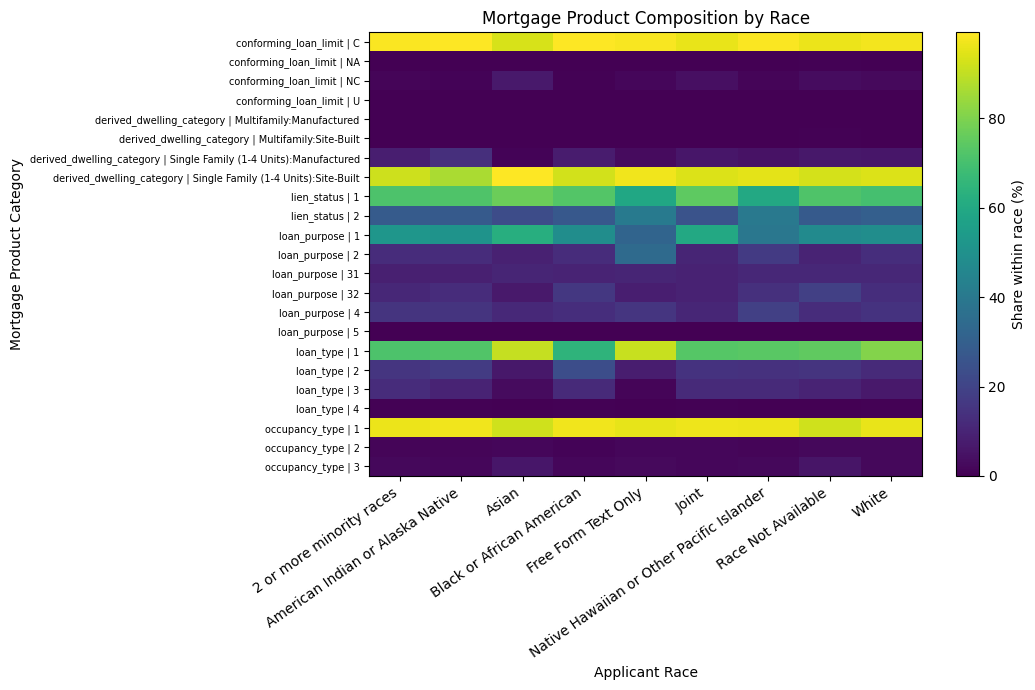

C3 completed.
Product dimensions: ['loan_type', 'loan_purpose', 'lien_status', 'occupancy_type', 'derived_dwelling_category', 'conforming_loan_limit']
Maximum normalization deviation: 2.220446049250313e-16


In [62]:
# ============================================================
# C3. PRODUCT MIX BY RACE
# ============================================================

# ------------------------------------------------------------
# Step 1. Define product dimensions
# ------------------------------------------------------------

C3_BASE_PRODUCT_FIELDS = [
    "loan_type",
    "loan_purpose",
    "lien_status",
    "occupancy_type",
    "derived_dwelling_category",
    "conforming_loan_limit"
]

C3_MISSING = [
    c for c in C3_BASE_PRODUCT_FIELDS
    if c not in df_s0.columns
]

assert not C3_MISSING, (
    f"Missing C3 product columns: {C3_MISSING}"
)

# Reuse an existing B14/B07 loan-amount bucket if available.
# Do not invent new cutpoints.

C3_LOAN_BUCKET_CANDIDATES = [
    "loan_amount_bucket",
    "loan_amount_bin",
    "loan_amount_band",
    "loan_amount_category"
]

C3_LOAN_BUCKET_COL = next(
    (
        c for c in C3_LOAN_BUCKET_CANDIDATES
        if c in df_s0.columns
    ),
    None
)

C3_PRODUCT_FIELDS = C3_BASE_PRODUCT_FIELDS.copy()

if C3_LOAN_BUCKET_COL is not None:

    C3_PRODUCT_FIELDS.append(
        C3_LOAN_BUCKET_COL
    )

else:

    print(
        "WARNING: No existing loan amount bucket found. "
        "Loan amount bucket is excluded rather than "
        "creating unverified B14 cutpoints."
    )


# ------------------------------------------------------------
# Step 2. Create long-format product data
# ------------------------------------------------------------

C3_PRODUCT_ARRAY = F.array(*[
    F.struct(
        F.lit(col_name).alias("product_dimension"),
        F.coalesce(
            F.col(col_name).cast("string"),
            F.lit("Missing/Null")
        ).alias("product_level")
    )
    for col_name in C3_PRODUCT_FIELDS
])

C3_LONG = (
    df_s0
    .select(
        F.coalesce(
            F.col("derived_race").cast("string"),
            F.lit("Missing/Null")
        ).alias("race_group"),

        F.explode(
            C3_PRODUCT_ARRAY
        ).alias("_product")
    )
    .select(
        "race_group",
        F.col("_product.product_dimension").alias(
            "product_dimension"
        ),
        F.col("_product.product_level").alias(
            "product_level"
        )
    )
)


# ------------------------------------------------------------
# Step 3. Aggregate product counts
# ------------------------------------------------------------

C3_COUNTS = (
    C3_LONG
    .groupBy(
        "race_group",
        "product_dimension",
        "product_level"
    )
    .agg(
        F.count("*").alias("n_applications")
    )
)


# ------------------------------------------------------------
# Step 4. Calculate within-race product shares
# ------------------------------------------------------------

C3_WINDOW = Window.partitionBy(
    "race_group",
    "product_dimension"
)

C3_MIX = (
    C3_COUNTS
    .withColumn(
        "race_product_n",
        F.sum("n_applications").over(C3_WINDOW)
    )
    .withColumn(
        "share_within_race",
        F.col("n_applications")
        / F.col("race_product_n")
    )
    .withColumn(
        "share_pct",
        F.col("share_within_race") * 100
    )
)


# ------------------------------------------------------------
# Step 5. Validate row-normalized shares
# ------------------------------------------------------------

C3_SHARE_CHECK = (
    C3_MIX
    .groupBy(
        "race_group",
        "product_dimension"
    )
    .agg(
        F.sum("share_within_race").alias("share_sum")
    )
    .agg(
        F.max(
            F.abs(F.col("share_sum") - 1)
        ).alias("max_deviation")
    )
    .first()["max_deviation"]
)

assert (
    C3_SHARE_CHECK is not None
    and C3_SHARE_CHECK < 1e-8
), (
    f"C3 normalization failed: {C3_SHARE_CHECK}"
)


# ------------------------------------------------------------
# Step 6. Export product mix table
# ------------------------------------------------------------

C3_FINAL = C3_MIX.select(
    "race_group",
    "product_dimension",
    "product_level",
    "n_applications",
    "race_product_n",
    "share_within_race",
    "share_pct"
).orderBy(
    "product_dimension",
    "race_group",
    F.desc("share_pct")
)

save_small_spark_table(
    C3_FINAL,
    "B15_rq1_mix_by_race.csv"
)


# ------------------------------------------------------------
# Step 7. Product mix heatmap
# ------------------------------------------------------------

C3_PDF = C3_FINAL.toPandas()

C3_PDF["product_label"] = (
    C3_PDF["product_dimension"]
    + " | "
    + C3_PDF["product_level"]
)

C3_HEATMAP = C3_PDF.pivot_table(
    index="product_label",
    columns="race_group",
    values="share_pct",
    aggfunc="sum",
    fill_value=0
)

fig, ax = plt.subplots(
    figsize=(
        max(10, len(C3_HEATMAP.columns) * 1.2),
        max(7, len(C3_HEATMAP.index) * 0.28)
    )
)

im = ax.imshow(
    C3_HEATMAP.values,
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(
    np.arange(len(C3_HEATMAP.columns))
)

ax.set_xticklabels(
    C3_HEATMAP.columns,
    rotation=35,
    ha="right"
)

ax.set_yticks(
    np.arange(len(C3_HEATMAP.index))
)

ax.set_yticklabels(
    C3_HEATMAP.index,
    fontsize=7
)

ax.set_xlabel("Applicant Race")
ax.set_ylabel("Mortgage Product Category")

ax.set_title(
    "Mortgage Product Composition by Race"
)

fig.colorbar(
    im,
    ax=ax,
    label="Share within race (%)"
)

plt.tight_layout()

fig.savefig(
    os.path.join(
        str(FIGURE_DIR),
        "B15_fig_12_mix_heatmap.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("C3 completed.")
print("Product dimensions:", C3_PRODUCT_FIELDS)
print("Maximum normalization deviation:", C3_SHARE_CHECK)


## C4. Product-Stratified Denial Gaps

This analysis examines whether raw denial-rate differences between racial groups persist within comparable mortgage product categories.

The analysis covers:
- Loan purpose.
- Loan type.
- Lien status.
- Occupancy type.
- Combined loan purpose × loan type.

For each product stratum, denial rates and 95% Wilson confidence intervals are calculated by applicant race. Group-reference gaps are measured against White applicants within the same product stratum.

The analysis also calculates risk ratios, odds ratios, log-odds-ratio confidence intervals, and percentage-point gap confidence intervals using the Newcombe method based on Wilson intervals.

Small cells are flagged using the B14 D-M thresholds. Race Not Available and Free Form Text Only remain visible in descriptive counts but are excluded from headline gap comparisons.

The primary objective is to identify whether the direction or magnitude of racial denial gaps changes across product categories, potentially revealing Simpson-type patterns.

These results are descriptive and do not establish causal effects.


Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq1_stratified_gap.csv | Shape: (305, 23)
C4 completed.
Product dimensions: 5
Total product-race strata: 305


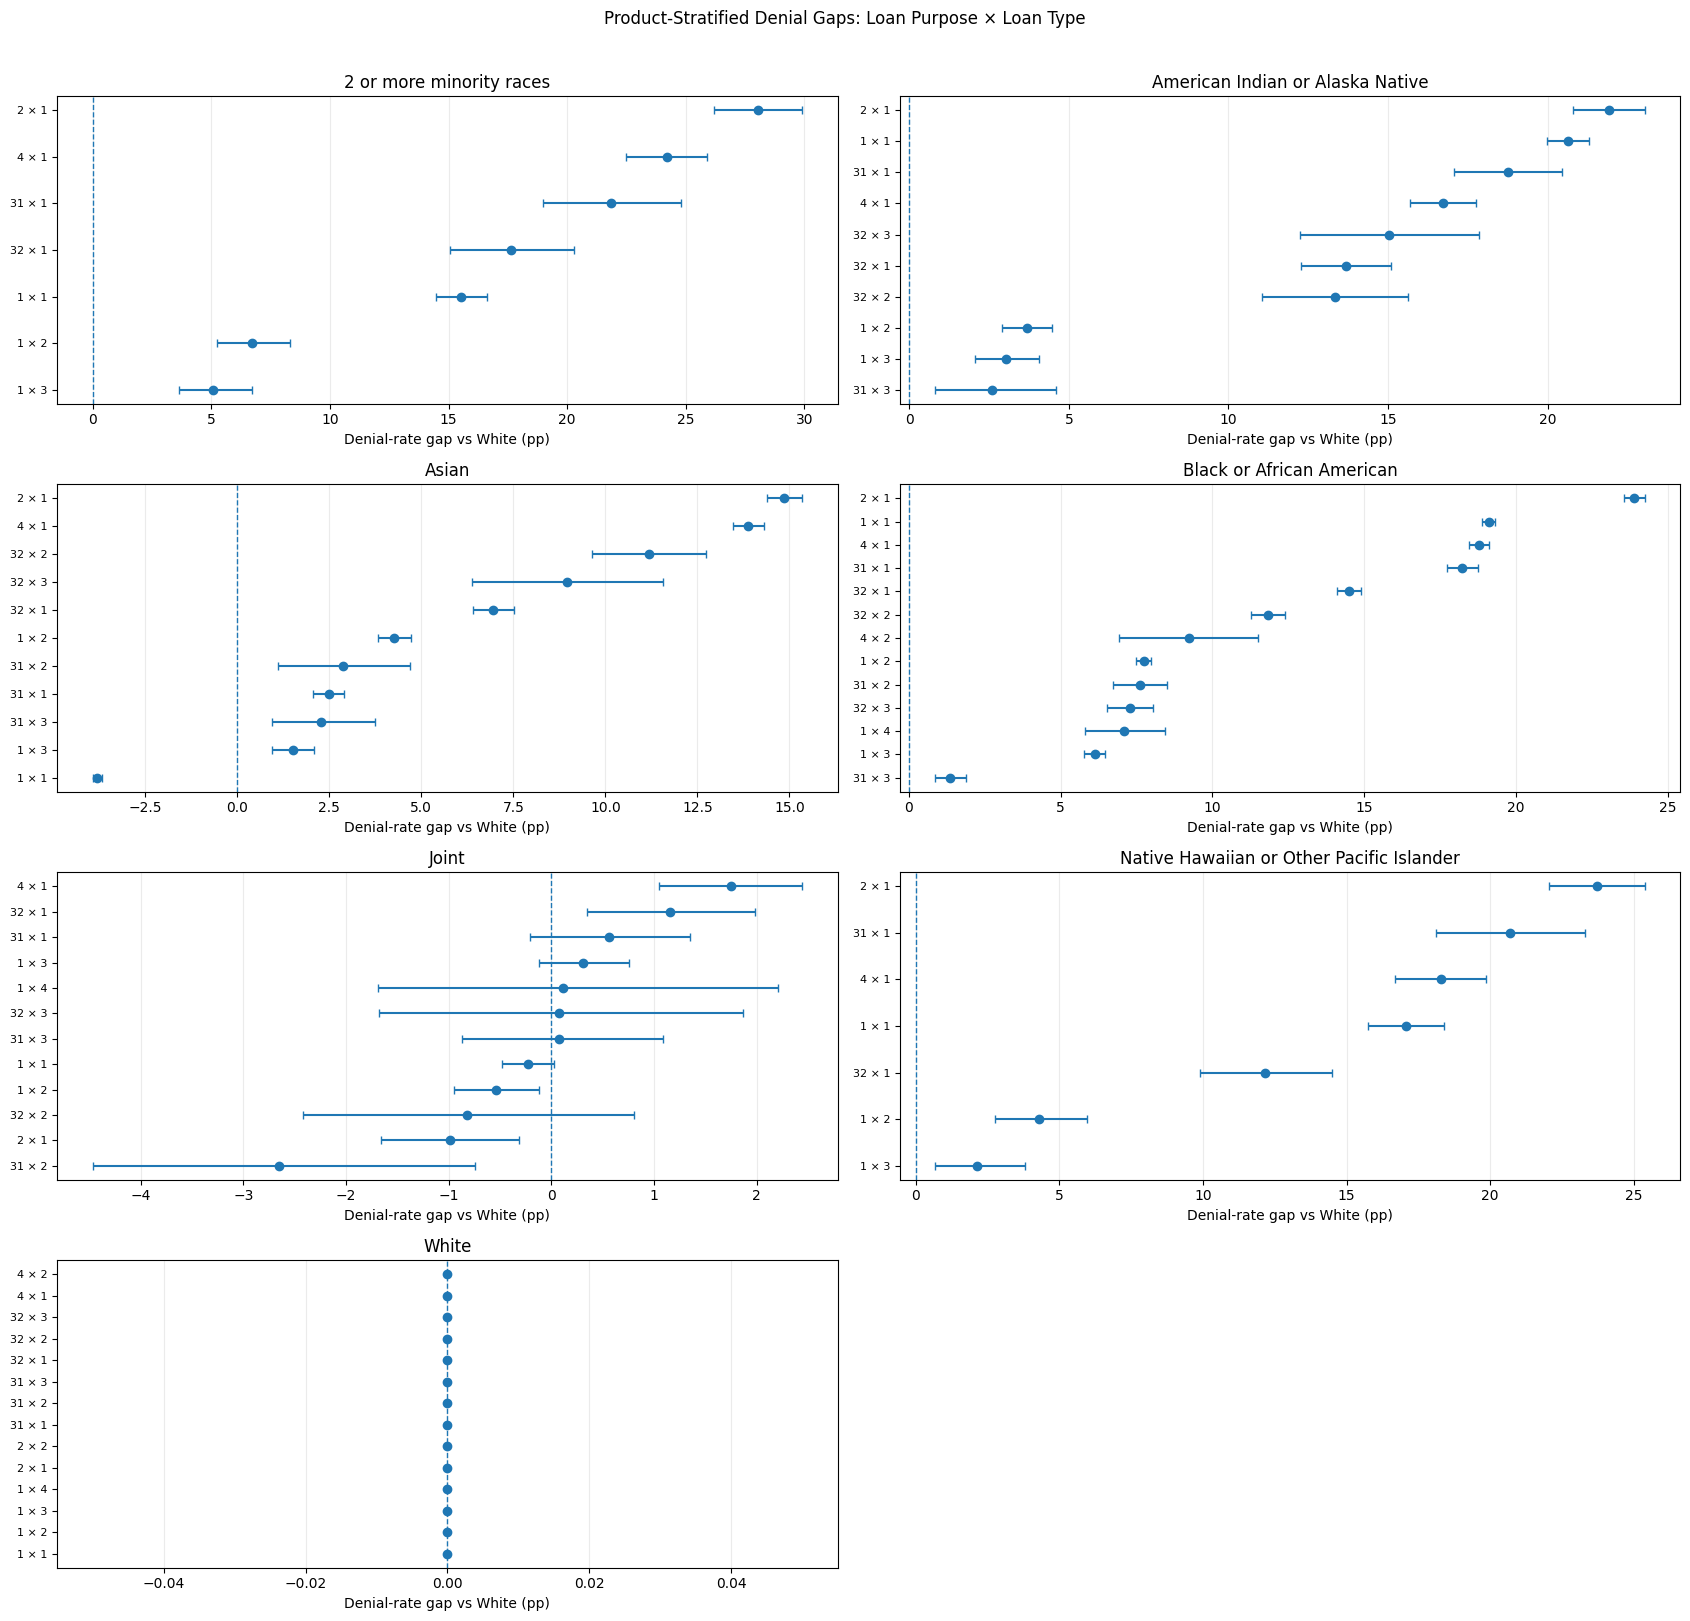

C4 completed successfully.


In [63]:

# ============================================================
# C4. PRODUCT-STRATIFIED DENIAL GAPS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F
from pyspark.sql import Window

# ------------------------------------------------------------
# Step 1. Configuration and validation
# ------------------------------------------------------------

C4_REFERENCE = "White"
C4_Z = 1.959963984540054

C4_MIN_APPS = int(globals().get("N_MIN_APPS", 1000))
C4_MIN_DENIED = int(globals().get("N_MIN_DENIED", 100))

C4_EXCLUDED = [
    "Race Not Available",
    "Free Form Text Only"
]

C4_PRODUCT_FIELDS = [
    "loan_purpose",
    "loan_type",
    "lien_status",
    "occupancy_type"
]

C4_MISSING = [
    c for c in C4_PRODUCT_FIELDS + ["derived_race", "is_denied"]
    if c not in df_s0.columns
]

assert not C4_MISSING, f"Missing columns: {C4_MISSING}"

# Small aggregate export helper.
# Only aggregated outputs are collected to Pandas.

spark.conf.set(
    "spark.sql.execution.arrow.pyspark.enabled",
    "false"
)

def c_save_aggregate(sdf, filename):
    pdf = sdf.toPandas()
    path = os.path.join(os.fspath(OUTPUT_DIR), filename)
    pdf.to_csv(path, index=False)
    print(f"Saved: {path} | Shape: {pdf.shape}")
    return pdf

# ------------------------------------------------------------
# Step 2. Create product-stratum long table
# ------------------------------------------------------------

C4_ITEMS = [
    F.struct(
        F.lit(c).alias("product_dimension"),
        F.coalesce(
            F.col(c).cast("string"),
            F.lit("Missing/Null")
        ).alias("product_stratum")
    )
    for c in C4_PRODUCT_FIELDS
]

C4_ITEMS.append(
    F.struct(
        F.lit("loan_purpose_x_loan_type").alias("product_dimension"),
        F.concat_ws(
            " × ",
            F.coalesce(
                F.col("loan_purpose").cast("string"),
                F.lit("Missing/Null")
            ),
            F.coalesce(
                F.col("loan_type").cast("string"),
                F.lit("Missing/Null")
            )
        ).alias("product_stratum")
    )
)

C4_LONG = (
    df_s0
    .select(
        F.coalesce(
            F.col("derived_race").cast("string"),
            F.lit("Missing/Null")
        ).alias("race_group"),
        F.col("is_denied").cast("int").alias("_denied"),
        F.explode(F.array(*C4_ITEMS)).alias("_product")
    )
    .select(
        "race_group",
        "_denied",
        F.col("_product.product_dimension").alias("product_dimension"),
        F.col("_product.product_stratum").alias("product_stratum")
    )
)

# ------------------------------------------------------------
# Step 3. Aggregate application and denial counts
# ------------------------------------------------------------

C4_COUNTS = (
    C4_LONG
    .groupBy(
        "product_dimension",
        "product_stratum",
        "race_group"
    )
    .agg(
        F.count("*").alias("n_applications"),
        F.sum("_denied").cast("long").alias("n_denied")
    )
)

C4_WINDOW = Window.partitionBy(
    "product_dimension",
    "product_stratum"
)

C4_COUNTS = (
    C4_COUNTS
    .withColumn(
        "_ref_n_apps",
        F.max(
            F.when(
                F.col("race_group") == C4_REFERENCE,
                F.col("n_applications")
            )
        ).over(C4_WINDOW)
    )
    .withColumn(
        "_ref_n_denied",
        F.max(
            F.when(
                F.col("race_group") == C4_REFERENCE,
                F.col("n_denied")
            )
        ).over(C4_WINDOW)
    )
)

# ------------------------------------------------------------
# Step 4. Calculate Wilson confidence intervals
# ------------------------------------------------------------

def c4_wilson(n, d):

    p = d / n
    z2 = C4_Z ** 2

    denominator = 1 + z2 / n

    center = (
        p + z2 / (2 * n)
    ) / denominator

    half = (
        C4_Z * F.sqrt(
            p * (1 - p) / n
            + z2 / (4 * n * n)
        ) / denominator
    )

    return (
        F.when(n > 0, center - half),
        F.when(n > 0, center + half)
    )

C4_RATE = F.col("n_denied") / F.col("n_applications")

C4_REF_RATE = (
    F.col("_ref_n_denied") / F.col("_ref_n_apps")
)

C4_LOW, C4_HIGH = c4_wilson(
    F.col("n_applications"),
    F.col("n_denied")
)

C4_REF_LOW, C4_REF_HIGH = c4_wilson(
    F.col("_ref_n_apps"),
    F.col("_ref_n_denied")
)

C4_FINAL = (
    C4_COUNTS
    .withColumn("denial_rate", C4_RATE)
    .withColumn("wilson_ci_low", C4_LOW)
    .withColumn("wilson_ci_high", C4_HIGH)
    .withColumn("reference_denial_rate", C4_REF_RATE)
    .withColumn("reference_wilson_ci_low", C4_REF_LOW)
    .withColumn("reference_wilson_ci_high", C4_REF_HIGH)
)

# ------------------------------------------------------------
# Step 5. Low-N flags and reference gaps
# ------------------------------------------------------------

C4_FINAL = (
    C4_FINAL
    .withColumn(
        "is_reference_group",
        F.col("race_group") == C4_REFERENCE
    )
    .withColumn(
        "is_headline_group",
        ~F.col("race_group").isin(*C4_EXCLUDED)
    )
    .withColumn(
        "low_n",
        (F.col("n_applications") < C4_MIN_APPS)
        | (F.col("n_denied") < C4_MIN_DENIED)
    )
    .withColumn(
        "reference_low_n",
        F.col("_ref_n_apps").isNull()
        | (F.col("_ref_n_apps") < C4_MIN_APPS)
        | (F.col("_ref_n_denied") < C4_MIN_DENIED)
    )
    .withColumn(
        "is_comparable",
        F.col("is_headline_group")
        & ~F.col("low_n")
        & ~F.col("reference_low_n")
    )
)

C4_DIFF = (
    F.col("denial_rate")
    - F.col("reference_denial_rate")
)

# Newcombe hybrid-score CI for the difference in proportions.
C4_GAP_CI_LOW = C4_DIFF - F.sqrt(
    F.pow(
        F.col("denial_rate") - F.col("wilson_ci_low"), 2
    )
    +
    F.pow(
        F.col("reference_wilson_ci_high")
        - F.col("reference_denial_rate"), 2
    )
)

C4_GAP_CI_HIGH = C4_DIFF + F.sqrt(
    F.pow(
        F.col("wilson_ci_high") - F.col("denial_rate"), 2
    )
    +
    F.pow(
        F.col("reference_denial_rate")
        - F.col("reference_wilson_ci_low"), 2
    )
)

# ------------------------------------------------------------
# Step 6. Risk ratio, odds ratio and confidence intervals
# ------------------------------------------------------------

C4_GROUP_NOT_DENIED = (
    F.col("n_applications") - F.col("n_denied")
)

C4_REF_NOT_DENIED = (
    F.col("_ref_n_apps") - F.col("_ref_n_denied")
)

C4_OR_NUM = (
    F.col("n_denied") * C4_REF_NOT_DENIED
)

C4_OR_DEN = (
    C4_GROUP_NOT_DENIED * F.col("_ref_n_denied")
)

C4_OR = C4_OR_NUM / C4_OR_DEN

C4_SE_LOG_OR = F.sqrt(
    1 / F.col("n_denied")
    + 1 / C4_GROUP_NOT_DENIED
    + 1 / F.col("_ref_n_denied")
    + 1 / C4_REF_NOT_DENIED
)

C4_FINAL = (
    C4_FINAL
    .withColumn(
        "gap_vs_reference_pp",
        F.when(
            F.col("is_reference_group"),
            F.lit(0.0)
        ).when(
            F.col("is_comparable"),
            C4_DIFF * 100
        )
    )
    .withColumn(
        "gap_ci_low_pp",
        F.when(
            F.col("is_reference_group"),
            F.lit(0.0)
        ).when(
            F.col("is_comparable"),
            C4_GAP_CI_LOW * 100
        )
    )
    .withColumn(
        "gap_ci_high_pp",
        F.when(
            F.col("is_reference_group"),
            F.lit(0.0)
        ).when(
            F.col("is_comparable"),
            C4_GAP_CI_HIGH * 100
        )
    )
    .withColumn(
        "risk_ratio",
        F.when(
            F.col("is_reference_group"),
            F.lit(1.0)
        ).when(
            F.col("is_comparable")
            & (F.col("reference_denial_rate") > 0),
            F.col("denial_rate") / F.col("reference_denial_rate")
        )
    )
    .withColumn(
        "odds_ratio",
        F.when(
            F.col("is_reference_group"),
            F.lit(1.0)
        ).when(
            F.col("is_comparable")
            & (C4_OR_DEN > 0)
            & (C4_OR_NUM > 0),
            C4_OR
        )
    )
    .withColumn(
        "or_ci_low",
        F.when(
            F.col("is_reference_group"),
            F.lit(1.0)
        ).when(
            F.col("odds_ratio").isNotNull(),
            F.exp(F.log("odds_ratio") - C4_Z * C4_SE_LOG_OR)
        )
    )
    .withColumn(
        "or_ci_high",
        F.when(
            F.col("is_reference_group"),
            F.lit(1.0)
        ).when(
            F.col("odds_ratio").isNotNull(),
            F.exp(F.log("odds_ratio") + C4_Z * C4_SE_LOG_OR)
        )
    )
)

C4_FINAL = C4_FINAL.select(
    "product_dimension",
    "product_stratum",
    "race_group",
    "n_applications",
    "n_denied",
    "denial_rate",
    "wilson_ci_low",
    "wilson_ci_high",
    "reference_denial_rate",
    "reference_wilson_ci_low",
    "reference_wilson_ci_high",
    "gap_vs_reference_pp",
    "gap_ci_low_pp",
    "gap_ci_high_pp",
    "risk_ratio",
    "odds_ratio",
    "or_ci_low",
    "or_ci_high",
    "is_reference_group",
    "is_headline_group",
    "low_n",
    "reference_low_n",
    "is_comparable"
).orderBy(
    "product_dimension",
    "product_stratum",
    "race_group"
)

# ------------------------------------------------------------
# Step 7. Validate and export
# ------------------------------------------------------------

C4_PDF = c_save_aggregate(
    C4_FINAL,
    "B15_rq1_stratified_gap.csv"
)

assert C4_PDF["denial_rate"].dropna().between(0, 1).all()

print("C4 completed.")
print("Product dimensions:", C4_PDF["product_dimension"].nunique())
print("Total product-race strata:", len(C4_PDF))

# ------------------------------------------------------------
# Step 8. Figure 13: small-multiples stratified gaps
# ------------------------------------------------------------

C4_PLOT = C4_PDF[
    (C4_PDF["product_dimension"] == "loan_purpose_x_loan_type")
    & C4_PDF["is_comparable"]
].copy()

C4_GROUPS = sorted(
    C4_PLOT["race_group"].dropna().unique()
)

if C4_GROUPS:

    C4_NCOLS = 2
    C4_NROWS = int(np.ceil(len(C4_GROUPS) / C4_NCOLS))

    fig, axes = plt.subplots(
        C4_NROWS,
        C4_NCOLS,
        figsize=(17, max(5, C4_NROWS * 4)),
        squeeze=False
    )

    for i, race in enumerate(C4_GROUPS):

        ax = axes[i // C4_NCOLS, i % C4_NCOLS]

        sub = C4_PLOT[
            C4_PLOT["race_group"] == race
        ].sort_values("gap_vs_reference_pp")

        y = np.arange(len(sub))

        x = sub["gap_vs_reference_pp"].to_numpy(dtype=float)

        lower = sub["gap_ci_low_pp"].to_numpy(dtype=float)
        upper = sub["gap_ci_high_pp"].to_numpy(dtype=float)

        xerr = np.vstack([
            np.maximum(x - lower, 0),
            np.maximum(upper - x, 0)
        ])

        ax.errorbar(
            x, y,
            xerr=xerr,
            fmt="o",
            capsize=3
        )

        ax.axvline(0, linestyle="--", linewidth=1)

        ax.set_yticks(y)
        ax.set_yticklabels(sub["product_stratum"], fontsize=8)

        ax.set_title(race)
        ax.set_xlabel("Denial-rate gap vs White (pp)")
        ax.grid(axis="x", alpha=0.25)

    for j in range(len(C4_GROUPS), C4_NROWS * C4_NCOLS):
        axes[j // C4_NCOLS, j % C4_NCOLS].set_visible(False)

    fig.suptitle(
        "Product-Stratified Denial Gaps: Loan Purpose × Loan Type",
        y=1.01
    )

    plt.tight_layout()

    fig.savefig(
        os.path.join(
            os.fspath(FIGURE_DIR),
            "B15_fig_13_stratified_gaps.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("C4 completed successfully.")



## C5. Exploratory Kitagawa Decomposition

This analysis decomposes the observed denial-rate gap between each eligible racial group and White applicants into two components:

1. Composition effect: differences in the distribution of mortgage product characteristics across racial groups.
2. Within-stratum rate effect: differences in denial rates between groups within comparable product categories.

The decomposition uses four product dimensions:

- Loan type.
- Loan purpose.
- Lien status.
- Occupancy type.

The analysis follows the approved B14 Kitagawa formulation:

Composition effect = ((r_g + r_w) / 2) × (w_g - w_w)

Rate effect = ((w_g + w_w) / 2) × (r_g - r_w)

Where w represents the group's share of applications in a product stratum and r represents its within-stratum denial rate.

Product strata that fail either group's minimum application or denial threshold are pooled into a single "Other (pooled low-N strata)" category.

The decomposition is validated by checking that the sum of both components equals the original raw denial-rate gap.

This is an exploratory descriptive decomposition, not a causal model. It does not establish that product composition explains or causes racial differences in mortgage denial outcomes.


Kitagawa identity passed.
Maximum absolute error (pp): 3.552713678800501e-15
Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq1_kitagawa.csv | Shape: (98, 27)


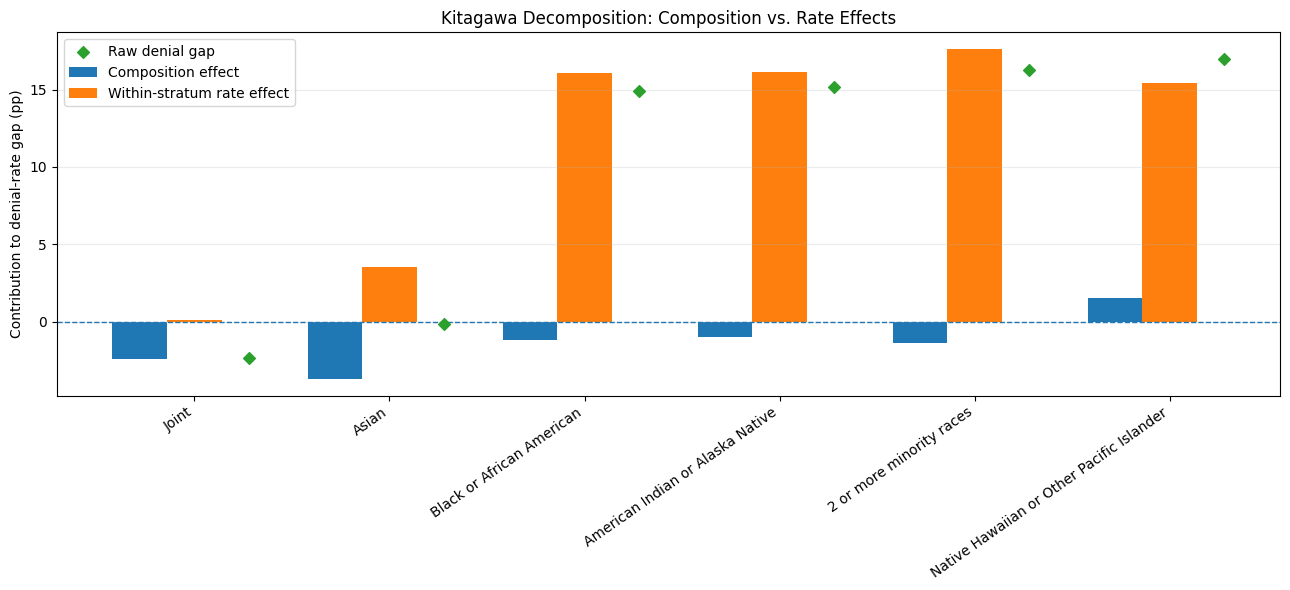

C5 completed successfully.


In [64]:

# ============================================================
# C5. EXPLORATORY KITAGAWA DECOMPOSITION
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F
from pyspark.sql import Window

# ------------------------------------------------------------
# Step 1. Configuration and validation
# ------------------------------------------------------------

C5_REFERENCE = "White"

C5_MIN_APPS = int(globals().get("N_MIN_APPS", 1000))
C5_MIN_DENIED = int(globals().get("N_MIN_DENIED", 100))

C5_PRODUCT_FIELDS = [
    "loan_type",
    "loan_purpose",
    "lien_status",
    "occupancy_type"
]

if "c_save_aggregate" not in globals():
    def c_save_aggregate(sdf, filename):
        pdf = sdf.toPandas()
        path = os.path.join(os.fspath(OUTPUT_DIR), filename)
        pdf.to_csv(path, index=False)
        print(f"Saved: {path} | Shape: {pdf.shape}")
        return pdf

if "C1_RAW_GAP" not in globals():
    C1_COUNTS = (
        df_s0
        .groupBy("derived_race")
        .agg(
            F.count("*").alias("n_applications"),
            F.sum(F.col("is_denied").cast("long")).alias("n_denied")
        )
    )
    C1_RAW_GAP = c0_add_rate_gap_metrics(
        counts_df=C1_COUNTS,
        group_col="derived_race",
        dimension_name="derived_race",
        reference_level=C5_REFERENCE,
        excluded_levels=["Race Not Available", "Free Form Text Only"],
        require_reference=True
    )

assert "C1_RAW_GAP" in globals()
assert "c_save_aggregate" in globals()

C5_MISSING = [
    c for c in C5_PRODUCT_FIELDS + ["derived_race", "is_denied"]
    if c not in df_s0.columns
]

assert not C5_MISSING, f"Missing columns: {C5_MISSING}"

# Eligible comparison groups are taken from C1.
# RNA and Free Form Text Only remain excluded from headline gaps.

C5_GROUPS_DF = (
    C1_RAW_GAP
    .filter(
        F.col("is_headline_group")
        & ~F.col("is_reference_group")
    )
    .select(
        F.col("group_value").alias("race_group"),
        F.col("low_n").alias("comparison_low_n"),
        F.col("reference_low_n")
    )
)

assert C5_GROUPS_DF.limit(1).count() > 0

# ------------------------------------------------------------
# Step 2. Build four-dimensional product strata
# ------------------------------------------------------------

C5_STRATUM_PARTS = [
    F.coalesce(
        F.col(c).cast("string"),
        F.lit("Missing/Null")
    )
    for c in C5_PRODUCT_FIELDS
]

C5_BASE = (
    df_s0
    .select(
        F.coalesce(
            F.col("derived_race").cast("string"),
            F.lit("Missing/Null")
        ).alias("race_group"),
        F.col("is_denied").cast("int").alias("_denied"),
        F.concat_ws(" | ", *C5_STRATUM_PARTS).alias(
            "product_stratum"
        )
    )
)

# ------------------------------------------------------------
# Step 3. Aggregate counts by race x product stratum
# ------------------------------------------------------------

C5_COUNTS = (
    C5_BASE
    .groupBy("race_group", "product_stratum")
    .agg(
        F.count("*").alias("n_applications"),
        F.sum("_denied").cast("long").alias("n_denied")
    )
)

C5_GROUP_COUNTS = (
    C5_COUNTS
    .join(
        C5_GROUPS_DF.select("race_group"),
        on="race_group",
        how="inner"
    )
    .select(
        "race_group",
        "product_stratum",
        F.col("n_applications").alias("g_n_apps"),
        F.col("n_denied").alias("g_n_denied")
    )
)

C5_WHITE_COUNTS = (
    C5_COUNTS
    .filter(F.col("race_group") == C5_REFERENCE)
    .select(
        "product_stratum",
        F.col("n_applications").alias("w_n_apps"),
        F.col("n_denied").alias("w_n_denied")
    )
)

# ------------------------------------------------------------
# Step 4. Create the union of group and White strata
# ------------------------------------------------------------

# Include strata appearing in either comparison group or White.
# This prevents zero-share product categories from disappearing.

C5_WHITE_STRATA = (
    C5_WHITE_COUNTS
    .select("product_stratum")
    .crossJoin(
        C5_GROUPS_DF.select("race_group")
    )
    .select("race_group", "product_stratum")
)

C5_GROUP_STRATA = (
    C5_GROUP_COUNTS
    .select("race_group", "product_stratum")
    .unionByName(C5_WHITE_STRATA)
    .distinct()
)

C5_PAIR_COUNTS = (
    C5_GROUP_STRATA
    .join(
        C5_GROUPS_DF,
        on="race_group",
        how="inner"
    )
    .join(
        C5_GROUP_COUNTS,
        on=["race_group", "product_stratum"],
        how="left"
    )
    .join(
        C5_WHITE_COUNTS,
        on="product_stratum",
        how="left"
    )
    .fillna(
        0,
        subset=[
            "g_n_apps",
            "g_n_denied",
            "w_n_apps",
            "w_n_denied"
        ]
    )
)

# ------------------------------------------------------------
# Step 5. Apply B14 D-M low-N pooling
# ------------------------------------------------------------

C5_PAIR_COUNTS = (
    C5_PAIR_COUNTS
    .withColumn(
        "low_n_stratum",
        (F.col("g_n_apps") < C5_MIN_APPS)
        | (F.col("g_n_denied") < C5_MIN_DENIED)
        | (F.col("w_n_apps") < C5_MIN_APPS)
        | (F.col("w_n_denied") < C5_MIN_DENIED)
    )
    .withColumn(
        "pooled_stratum",
        F.when(
            F.col("low_n_stratum"),
            F.lit("Other (pooled low-N strata)")
        ).otherwise(F.col("product_stratum"))
    )
)

# Aggregate all low-N original strata into one shared category
# separately for each group-reference comparison.

C5_POOL_COUNTS = (
    C5_PAIR_COUNTS
    .groupBy("race_group", "pooled_stratum")
    .agg(
        F.sum("g_n_apps").alias("g_n_apps"),
        F.sum("g_n_denied").alias("g_n_denied"),
        F.sum("w_n_apps").alias("w_n_apps"),
        F.sum("w_n_denied").alias("w_n_denied"),
        F.count("*").alias("n_original_strata"),
        F.sum(
            F.when(F.col("low_n_stratum"), 1).otherwise(0)
        ).alias("n_pooled_original_strata")
    )
)

# ------------------------------------------------------------
# Step 6. Calculate group totals and pooled-strata counts
# ------------------------------------------------------------

C5_TOTALS = (
    C5_POOL_COUNTS
    .groupBy("race_group")
    .agg(
        F.sum("g_n_apps").alias("g_total_apps"),
        F.sum("g_n_denied").alias("g_total_denied"),
        F.sum("w_n_apps").alias("w_total_apps"),
        F.sum("w_n_denied").alias("w_total_denied"),
        F.sum("n_original_strata").alias(
            "n_strata_before_pool"
        ),
        F.count("*").alias(
            "n_strata_after_pool"
        ),
        F.sum("n_pooled_original_strata").alias(
            "n_low_n_strata"
        )
    )
)

# ------------------------------------------------------------
# Step 7. Calculate exact Kitagawa components
# ------------------------------------------------------------

C5_DECOMP = (
    C5_POOL_COUNTS
    .join(C5_TOTALS, on="race_group", how="inner")
    .join(C5_GROUPS_DF, on="race_group", how="inner")
    .join(
        C1_RAW_GAP.select(
            F.col("group_value").alias("race_group"),
            F.col("gap_vs_reference_pp").alias("raw_gap_pp")
        ),
        on="race_group",
        how="left"
    )
)

# Group-specific overall denial rates.
C5_DECOMP = (
    C5_DECOMP
    .withColumn(
        "_g_overall_rate",
        F.col("g_total_denied") / F.col("g_total_apps")
    )
    .withColumn(
        "_w_overall_rate",
        F.col("w_total_denied") / F.col("w_total_apps")
    )
)

# For a zero-count stratum, use the group's overall rate as a
# neutral fallback. Its weight is zero, so the decomposition
# identity remains unchanged.

C5_DECOMP = (
    C5_DECOMP
    .withColumn(
        "g_stratum_share",
        F.col("g_n_apps") / F.col("g_total_apps")
    )
    .withColumn(
        "w_stratum_share",
        F.col("w_n_apps") / F.col("w_total_apps")
    )
    .withColumn(
        "g_stratum_denial_rate",
        F.when(
            F.col("g_n_apps") > 0,
            F.col("g_n_denied") / F.col("g_n_apps")
        ).otherwise(F.col("_g_overall_rate"))
    )
    .withColumn(
        "w_stratum_denial_rate",
        F.when(
            F.col("w_n_apps") > 0,
            F.col("w_n_denied") / F.col("w_n_apps")
        ).otherwise(F.col("_w_overall_rate"))
    )
    .withColumn(
        "zero_n_group_stratum",
        F.col("g_n_apps") == 0
    )
    .withColumn(
        "zero_n_reference_stratum",
        F.col("w_n_apps") == 0
    )
)

# Exact B14 Kitagawa formulas.
C5_DECOMP = (
    C5_DECOMP
    .withColumn(
        "composition_effect_pp",
        (
            (
                F.col("g_stratum_denial_rate")
                + F.col("w_stratum_denial_rate")
            ) / 2
        )
        * (
            F.col("g_stratum_share")
            - F.col("w_stratum_share")
        ) * 100
    )
    .withColumn(
        "rate_effect_pp",
        (
            (
                F.col("g_stratum_share")
                + F.col("w_stratum_share")
            ) / 2
        )
        * (
            F.col("g_stratum_denial_rate")
            - F.col("w_stratum_denial_rate")
        ) * 100
    )
)

# ------------------------------------------------------------
# Step 8. Validate decomposition identity
# ------------------------------------------------------------

C5_WINDOW = Window.partitionBy("race_group")

C5_DECOMP = (
    C5_DECOMP
    .withColumn(
        "composition_effect_total_pp",
        F.sum("composition_effect_pp").over(C5_WINDOW)
    )
    .withColumn(
        "rate_effect_total_pp",
        F.sum("rate_effect_pp").over(C5_WINDOW)
    )
    .withColumn(
        "decomposed_gap_pp",
        F.col("composition_effect_total_pp")
        + F.col("rate_effect_total_pp")
    )
    .withColumn(
        "decomposition_error_pp",
        F.col("decomposed_gap_pp")
        - F.col("raw_gap_pp")
    )
    .withColumn(
        "decomposition_pass",
        F.abs(F.col("decomposition_error_pp")) < 1e-6
    )
    .withColumn(
        "is_pooled_low_n",
        F.col("pooled_stratum")
        == "Other (pooled low-N strata)"
    )
    .withColumn(
        "is_reliable",
        ~F.col("comparison_low_n")
        & ~F.col("reference_low_n")
    )
)

C5_FINAL = C5_DECOMP.select(
    "race_group",
    "pooled_stratum",
    "g_n_apps",
    "g_n_denied",
    "w_n_apps",
    "w_n_denied",
    "g_stratum_share",
    "w_stratum_share",
    "g_stratum_denial_rate",
    "w_stratum_denial_rate",
    "composition_effect_pp",
    "rate_effect_pp",
    "composition_effect_total_pp",
    "rate_effect_total_pp",
    "raw_gap_pp",
    "decomposed_gap_pp",
    "decomposition_error_pp",
    "decomposition_pass",
    "is_pooled_low_n",
    "zero_n_group_stratum",
    "zero_n_reference_stratum",
    "n_strata_before_pool",
    "n_strata_after_pool",
    "n_low_n_strata",
    "comparison_low_n",
    "reference_low_n",
    "is_reliable"
).orderBy(
    "race_group",
    "pooled_stratum"
)

# Collect only the small group-level summary.
C5_SUMMARY_PDF = (
    C5_FINAL
    .select(
        "race_group",
        "composition_effect_total_pp",
        "rate_effect_total_pp",
        "raw_gap_pp",
        "decomposed_gap_pp",
        "decomposition_error_pp",
        "n_strata_before_pool",
        "n_strata_after_pool",
        "n_low_n_strata",
        "is_reliable"
    )
    .dropDuplicates(["race_group"])
    .toPandas()
)

assert not C5_SUMMARY_PDF.empty

C5_MAX_ERROR = C5_SUMMARY_PDF[
    "decomposition_error_pp"
].abs().max()

assert C5_MAX_ERROR < 1e-6, (
    f"Kitagawa identity failed. Max error: {C5_MAX_ERROR}"
)

print("Kitagawa identity passed.")
print("Maximum absolute error (pp):", C5_MAX_ERROR)

# ------------------------------------------------------------
# Step 9. Export detailed decomposition
# ------------------------------------------------------------

C5_PDF = c_save_aggregate(
    C5_FINAL,
    "B15_rq1_kitagawa.csv"
)

# ------------------------------------------------------------
# Step 10. Figure 14: Kitagawa decomposition
# ------------------------------------------------------------

C5_SUMMARY_PDF = C5_SUMMARY_PDF.sort_values(
    "decomposed_gap_pp"
)

x = np.arange(len(C5_SUMMARY_PDF))
width = 0.28

fig, ax = plt.subplots(
    figsize=(13, 6)
)

ax.bar(
    x - width,
    C5_SUMMARY_PDF["composition_effect_total_pp"],
    width,
    label="Composition effect"
)

ax.bar(
    x,
    C5_SUMMARY_PDF["rate_effect_total_pp"],
    width,
    label="Within-stratum rate effect"
)

ax.scatter(
    x + width,
    C5_SUMMARY_PDF["raw_gap_pp"],
    marker="D",
    label="Raw denial gap",
    zorder=3
)

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels(
    C5_SUMMARY_PDF["race_group"],
    rotation=35,
    ha="right"
)

ax.set_ylabel("Contribution to denial-rate gap (pp)")

ax.set_title(
    "Kitagawa Decomposition: Composition vs. Rate Effects"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

fig.savefig(
    os.path.join(
        os.fspath(FIGURE_DIR),
        "B15_fig_14_kitagawa.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("C5 completed successfully.")



## C6. Race Not Available Profile

This analysis investigates the characteristics of mortgage applications classified as "Race Not Available" and examines whether their distribution is concentrated among particular lenders, application channels, or mortgage products.

The analysis covers three areas:

1. Lender profile: application volume, Race Not Available counts and shares, denial rates, and lender-level concentration.
2. Application channel: Race Not Available distribution by `submission_of_application`.
3. Loan product: Race Not Available distribution by loan type, loan purpose, lien status, and occupancy type.

Lender identifiers are anonymized using ranked labels (L001, L002, etc.). Original LEIs and institution names are never included in exported outputs.

The analysis reports both the share of Race Not Available applications within each category and the category's contribution to all Race Not Available applications.

Low-N flags follow the B14 D-M thresholds.

The purpose is to identify potential concentration and selection patterns that may affect the interpretation of racial denial-rate comparisons. The results are descriptive and do not establish why applicants have unavailable race information.


Total S0 applications: 8136664
Race Not Available applications: 1275240
Lenders with RNA applications: 4381
Lender RNA HHI: 0.015251389749169484
Top-10 lender RNA share: 0.30073633198456756
Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq1_race_na_profile.csv | Shape: (4826, 15)
C6 profile dimensions:
profile_dimension
lender                 4808
loan_purpose              6
loan_type                 4
application_channel       3
occupancy_type            3
lien_status               2
Name: count, dtype: int64


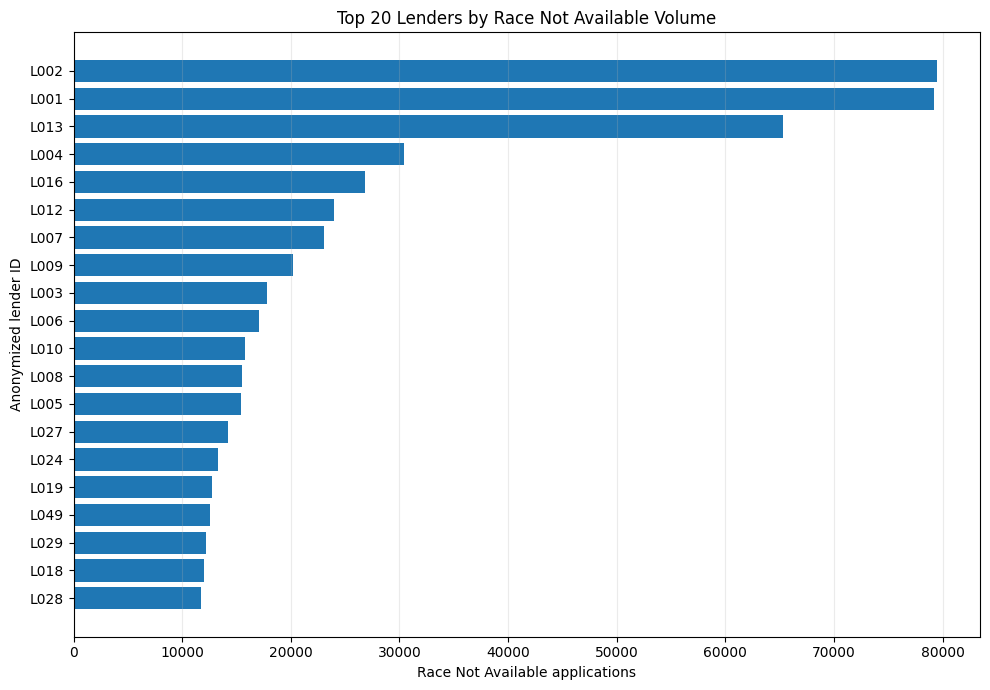

C6 completed successfully.
Output: B15_rq1_race_na_profile.csv
Lender HHI: 0.015251389749169484
Top 10 share: 0.30073633198456756


In [65]:

# ============================================================
# C6. RACE NOT AVAILABLE PROFILE
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F
from pyspark.sql import Window

# ------------------------------------------------------------
# Step 1. Configuration and validation
# ------------------------------------------------------------

C6_RNA = "Race Not Available"

C6_MIN_APPS = int(globals().get("N_MIN_APPS", 1000))
C6_MIN_DENIED = int(globals().get("N_MIN_DENIED", 100))

C6_LENDER_CANDIDATES = [
    "lei",
    "lei_hash",
    "lender_id",
    "lei_id"
]

C6_LENDER_COL = (
    globals().get("C0_LENDER_COL")
    or next(
        (
            c for c in C6_LENDER_CANDIDATES
            if c in df_s0.columns
        ),
        None
    )
)

assert C6_LENDER_COL is not None, (
    "No lender identifier found."
)

C6_DIM_SPECS = [
    ("application_channel", "submission_of_application"),
    ("loan_type", "loan_type"),
    ("loan_purpose", "loan_purpose"),
    ("lien_status", "lien_status"),
    ("occupancy_type", "occupancy_type")
]

C6_REQUIRED = [
    "derived_race",
    "is_denied",
    C6_LENDER_COL
] + [c for _, c in C6_DIM_SPECS]

C6_MISSING = [
    c for c in C6_REQUIRED
    if c not in df_s0.columns
]

assert not C6_MISSING, f"Missing columns: {C6_MISSING}"

# ------------------------------------------------------------
# Step 2. Overall Race Not Available population
# ------------------------------------------------------------

C6_BASE = df_s0.select(
    F.coalesce(
        F.col("derived_race").cast("string"),
        F.lit("Missing/Null")
    ).alias("_race"),
    F.col("is_denied").cast("int").alias("_denied")
)

C6_TOTALS = (
    C6_BASE
    .agg(
        F.count("*").alias("total_applications"),
        F.sum(
            F.when(F.col("_race") == C6_RNA, 1).otherwise(0)
        ).alias("total_rna"),
        F.sum("_denied").alias("total_denied"),
        F.sum(
            F.when(
                F.col("_race") == C6_RNA,
                F.col("_denied")
            ).otherwise(0)
        ).alias("total_rna_denied")
    )
    .first()
)

C6_TOTAL_APPS = int(C6_TOTALS["total_applications"])
C6_TOTAL_RNA = int(C6_TOTALS["total_rna"])

print("Total S0 applications:", C6_TOTAL_APPS)
print("Race Not Available applications:", C6_TOTAL_RNA)

# ------------------------------------------------------------
# Step 3. Lender-level aggregation
# ------------------------------------------------------------

C6_LENDER_RAW = (
    df_s0
    .select(
        F.col(C6_LENDER_COL).cast("string").alias("_lender_key"),
        F.coalesce(
            F.col("derived_race").cast("string"),
            F.lit("Missing/Null")
        ).alias("_race"),
        F.col("is_denied").cast("int").alias("_denied")
    )
    .groupBy("_lender_key")
    .agg(
        F.count("*").alias("n_applications"),
        F.sum("_denied").alias("n_denied_all"),
        F.sum(
            F.when(F.col("_race") == C6_RNA, 1).otherwise(0)
        ).alias("n_race_na"),
        F.sum(
            F.when(
                F.col("_race") == C6_RNA,
                F.col("_denied")
            ).otherwise(0)
        ).alias("n_denied_race_na")
    )
)

# Keep identifiable lenders for anonymized ranking.
C6_LENDER_KNOWN = C6_LENDER_RAW.filter(
    F.col("_lender_key").isNotNull()
)

# Rank L001, L002... by total application volume.
C6_ID_WINDOW = Window.orderBy(
    F.desc("n_applications"),
    F.asc("_lender_key")
)

# Rank separately by Race Not Available volume for concentration.
C6_RNA_WINDOW = Window.orderBy(
    F.desc("n_race_na"),
    F.desc("n_applications"),
    F.asc("_lender_key")
)

C6_LENDER_RANKED = (
    C6_LENDER_KNOWN
    .withColumn(
        "_id_rank",
        F.row_number().over(C6_ID_WINDOW)
    )
    .withColumn(
        "_rna_rank",
        F.row_number().over(C6_RNA_WINDOW)
    )
    .withColumn(
        "profile_level",
        F.concat(
            F.lit("L"),
            F.lpad(
                F.col("_id_rank").cast("string"),
                3,
                "0"
            )
        )
    )
)

# ------------------------------------------------------------
# Step 4. Lender-level concentration metrics
# ------------------------------------------------------------

C6_LENDER_WINDOW = Window.partitionBy()

C6_LENDER_RANKED = (
    C6_LENDER_RANKED
    .withColumn(
        "_identified_rna_total",
        F.sum("n_race_na").over(C6_LENDER_WINDOW)
    )
    .withColumn(
        "_share_identified_rna",
        F.when(
            F.col("_identified_rna_total") > 0,
            F.col("n_race_na")
            / F.col("_identified_rna_total")
        )
    )
)

C6_LENDER_STATS = (
    C6_LENDER_RANKED
    .agg(
        F.sum(
            F.pow(F.col("_share_identified_rna"), 2)
        ).alias("lender_rna_hhi"),
        F.sum(
            F.when(
                F.col("_rna_rank") <= 10,
                F.col("_share_identified_rna")
            ).otherwise(0)
        ).alias("top10_lender_rna_share"),
        F.sum(
            F.when(F.col("n_race_na") > 0, 1).otherwise(0)
        ).alias("n_lenders_with_rna")
    )
    .first()
)

C6_HHI = float(C6_LENDER_STATS["lender_rna_hhi"] or 0)
C6_TOP10_SHARE = float(
    C6_LENDER_STATS["top10_lender_rna_share"] or 0
)
C6_N_LENDERS_RNA = int(
    C6_LENDER_STATS["n_lenders_with_rna"] or 0
)

print("Lenders with RNA applications:", C6_N_LENDERS_RNA)
print("Lender RNA HHI:", C6_HHI)
print("Top-10 lender RNA share:", C6_TOP10_SHARE)

# ------------------------------------------------------------
# Step 5. Standardized lender output
# ------------------------------------------------------------

C6_LENDER_FINAL = (
    C6_LENDER_RANKED
    .withColumn(
        "profile_dimension",
        F.lit("lender")
    )
    .withColumn(
        "race_na_share_within_level",
        F.col("n_race_na") / F.col("n_applications")
    )
    .withColumn(
        "share_of_all_race_na",
        F.when(
            F.lit(C6_TOTAL_RNA) > 0,
            F.col("n_race_na") / F.lit(C6_TOTAL_RNA)
        )
    )
    .withColumn(
        "denial_rate_all",
        F.col("n_denied_all") / F.col("n_applications")
    )
    .withColumn(
        "denial_rate_race_na",
        F.when(
            F.col("n_race_na") > 0,
            F.col("n_denied_race_na") / F.col("n_race_na")
        )
    )
    .withColumn(
        "low_n_all",
        (F.col("n_applications") < C6_MIN_APPS)
        | (F.col("n_denied_all") < C6_MIN_DENIED)
    )
    .withColumn(
        "low_n_race_na",
        (F.col("n_race_na") < C6_MIN_APPS)
        | (F.col("n_denied_race_na") < C6_MIN_DENIED)
    )
    .withColumn(
        "lender_rna_hhi",
        F.lit(C6_HHI)
    )
    .withColumn(
        "top10_lender_rna_share",
        F.lit(C6_TOP10_SHARE)
    )
    .withColumn(
        "n_lenders_with_rna",
        F.lit(C6_N_LENDERS_RNA).cast("long")
    )
    .select(
        "profile_dimension",
        "profile_level",
        "n_applications",
        "n_denied_all",
        "n_race_na",
        "n_denied_race_na",
        "race_na_share_within_level",
        "share_of_all_race_na",
        "denial_rate_all",
        "denial_rate_race_na",
        "low_n_all",
        "low_n_race_na",
        "lender_rna_hhi",
        "top10_lender_rna_share",
        "n_lenders_with_rna"
    )
)

# ------------------------------------------------------------
# Step 6. Create missing-lender-ID profile
# ------------------------------------------------------------

C6_MISSING_LENDER_RAW = (
    df_s0
    .filter(F.col(C6_LENDER_COL).isNull())
    .select(
        F.coalesce(
            F.col("derived_race").cast("string"),
            F.lit("Missing/Null")
        ).alias("_race"),
        F.col("is_denied").cast("int").alias("_denied")
    )
    .agg(
        F.count("*").alias("n_applications"),
        F.sum("_denied").alias("n_denied_all"),
        F.sum(
            F.when(F.col("_race") == C6_RNA, 1).otherwise(0)
        ).alias("n_race_na"),
        F.sum(
            F.when(
                F.col("_race") == C6_RNA,
                F.col("_denied")
            ).otherwise(0)
        ).alias("n_denied_race_na")
    )
)

C6_MISSING_LENDER_FINAL = (
    C6_MISSING_LENDER_RAW
    .withColumn(
        "profile_dimension",
        F.lit("lender_id_coverage")
    )
    .withColumn(
        "profile_level",
        F.lit("Missing lender ID")
    )
    .withColumn(
        "race_na_share_within_level",
        F.when(
            F.col("n_applications") > 0,
            F.col("n_race_na") / F.col("n_applications")
        )
    )
    .withColumn(
        "share_of_all_race_na",
        F.when(
            F.lit(C6_TOTAL_RNA) > 0,
            F.col("n_race_na") / F.lit(C6_TOTAL_RNA)
        )
    )
    .withColumn(
        "denial_rate_all",
        F.when(
            F.col("n_applications") > 0,
            F.col("n_denied_all") / F.col("n_applications")
        )
    )
    .withColumn(
        "denial_rate_race_na",
        F.when(
            F.col("n_race_na") > 0,
            F.col("n_denied_race_na") / F.col("n_race_na")
        )
    )
    .withColumn(
        "low_n_all",
        (F.col("n_applications") < C6_MIN_APPS)
        | (F.col("n_denied_all") < C6_MIN_DENIED)
    )
    .withColumn(
        "low_n_race_na",
        (F.col("n_race_na") < C6_MIN_APPS)
        | (F.col("n_denied_race_na") < C6_MIN_DENIED)
    )
    .withColumn(
        "lender_rna_hhi",
        F.lit(None).cast("double")
    )
    .withColumn(
        "top10_lender_rna_share",
        F.lit(None).cast("double")
    )
    .withColumn(
        "n_lenders_with_rna",
        F.lit(None).cast("long")
    )
    .filter(F.col("n_applications") > 0)
    .select(C6_LENDER_FINAL.columns)
)

# ------------------------------------------------------------
# Step 7. Channel and product profile
# ------------------------------------------------------------

C6_ITEMS = [
    F.struct(
        F.lit(label).alias("profile_dimension"),
        F.coalesce(
            F.col(column).cast("string"),
            F.lit("Missing/Null")
        ).alias("profile_level")
    )
    for label, column in C6_DIM_SPECS
]

C6_LONG = (
    df_s0
    .select(
        F.coalesce(
            F.col("derived_race").cast("string"),
            F.lit("Missing/Null")
        ).alias("_race"),
        F.col("is_denied").cast("int").alias("_denied"),
        F.explode(F.array(*C6_ITEMS)).alias("_item")
    )
    .select(
        "_race",
        "_denied",
        F.col("_item.profile_dimension").alias("profile_dimension"),
        F.col("_item.profile_level").alias("profile_level")
    )
)

C6_DIM_COUNTS = (
    C6_LONG
    .groupBy("profile_dimension", "profile_level")
    .agg(
        F.count("*").alias("n_applications"),
        F.sum("_denied").alias("n_denied_all"),
        F.sum(
            F.when(F.col("_race") == C6_RNA, 1).otherwise(0)
        ).alias("n_race_na"),
        F.sum(
            F.when(
                F.col("_race") == C6_RNA,
                F.col("_denied")
            ).otherwise(0)
        ).alias("n_denied_race_na")
    )
)

C6_DIM_FINAL = (
    C6_DIM_COUNTS
    .withColumn(
        "race_na_share_within_level",
        F.col("n_race_na") / F.col("n_applications")
    )
    .withColumn(
        "share_of_all_race_na",
        F.when(
            F.lit(C6_TOTAL_RNA) > 0,
            F.col("n_race_na") / F.lit(C6_TOTAL_RNA)
        )
    )
    .withColumn(
        "denial_rate_all",
        F.col("n_denied_all") / F.col("n_applications")
    )
    .withColumn(
        "denial_rate_race_na",
        F.when(
            F.col("n_race_na") > 0,
            F.col("n_denied_race_na") / F.col("n_race_na")
        )
    )
    .withColumn(
        "low_n_all",
        (F.col("n_applications") < C6_MIN_APPS)
        | (F.col("n_denied_all") < C6_MIN_DENIED)
    )
    .withColumn(
        "low_n_race_na",
        (F.col("n_race_na") < C6_MIN_APPS)
        | (F.col("n_denied_race_na") < C6_MIN_DENIED)
    )
    .withColumn(
        "lender_rna_hhi",
        F.lit(None).cast("double")
    )
    .withColumn(
        "top10_lender_rna_share",
        F.lit(None).cast("double")
    )
    .withColumn(
        "n_lenders_with_rna",
        F.lit(None).cast("long")
    )
    .select(C6_LENDER_FINAL.columns)
)

# ------------------------------------------------------------
# Step 8. Combine all C6 profiles
# ------------------------------------------------------------

C6_FINAL = (
    C6_LENDER_FINAL
    .unionByName(C6_MISSING_LENDER_FINAL)
    .unionByName(C6_DIM_FINAL)
    .orderBy(
        "profile_dimension",
        F.desc("n_race_na")
    )
)

# ------------------------------------------------------------
# Step 9. Validate and export
# ------------------------------------------------------------

C6_PDF = c_save_aggregate(
    C6_FINAL,
    "B15_rq1_race_na_profile.csv"
)

assert C6_PDF["n_race_na"].ge(0).all()
assert C6_PDF["n_applications"].ge(
    C6_PDF["n_race_na"]
).all()

# Check that no original lender key or LEI is exported.
assert C6_LENDER_COL not in C6_FINAL.columns

print("C6 profile dimensions:")
print(C6_PDF["profile_dimension"].value_counts())

# ------------------------------------------------------------
# Step 10. Figure 15: lender RNA concentration
# ------------------------------------------------------------

C6_LENDER_PDF = (
    C6_PDF[
        (C6_PDF["profile_dimension"] == "lender")
        & (C6_PDF["n_race_na"] > 0)
    ]
    .sort_values("n_race_na", ascending=False)
    .head(20)
    .sort_values("n_race_na")
)

if not C6_LENDER_PDF.empty:

    fig, ax = plt.subplots(
        figsize=(10, max(5, len(C6_LENDER_PDF) * 0.35))
    )

    ax.barh(
        C6_LENDER_PDF["profile_level"],
        C6_LENDER_PDF["n_race_na"]
    )

    ax.set_xlabel(
        "Race Not Available applications"
    )

    ax.set_ylabel(
        "Anonymized lender ID"
    )

    ax.set_title(
        "Top 20 Lenders by Race Not Available Volume"
    )

    ax.grid(axis="x", alpha=0.25)

    plt.tight_layout()

    fig.savefig(
        os.path.join(
            os.fspath(FIGURE_DIR),
            "B15_fig_15_race_na_profile.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

else:
    print("No lender-level RNA observations for Figure 15.")

print("C6 completed successfully.")
print("Output: B15_rq1_race_na_profile.csv")
print("Lender HHI:", C6_HHI)
print("Top 10 share:", C6_TOP10_SHARE)


# PART D — RQ2: FINANCIAL PROFILE

This section investigates how borrower financial characteristics
are distributed across racial groups and how these characteristics
are associated with mortgage denial outcomes.

The analysis is organized into four components:

- D1: Financial profile by race.
- D2: Denial patterns across financial variables.
- D3: Joint DTI × CLTV denial surface.
- D4: Financially stratified racial gaps and Kitagawa decomposition.

All analyses use the full S0 analytic sample.
The reference group is White.

Denial rates are calculated using action_taken IN (1, 2, 3).
Small cells are flagged according to the approved D-M thresholds.

These analyses are descriptive and diagnostic, not causal.

In [66]:
# ============================================================
# D0. FINANCIAL VARIABLE SCHEMA CHECK
# ============================================================

required_cols = [
    "derived_race",
    "action_taken",
    "is_denied",
    "income",
    "loan_amount",
    "loan_to_income",
    "property_value",
    "combined_loan_to_value_ratio",
    "debt_to_income_ratio",
    "dti_bin_coarse",
    "dti_bin_fine",
    "dti_point",
    "loan_type",
    "loan_purpose",
    "lien_status"
]

schema_check = pd.DataFrame({
    "column": required_cols,
    "exists": [
        c in df_s0.columns for c in required_cols
    ]
})

display(schema_check)

,column,exists
0,derived_race,True
1,action_taken,True
2,is_denied,True
3,income,True
4,loan_amount,True
5,loan_to_income,True
6,property_value,True
7,combined_loan_to_value_ratio,True
8,debt_to_income_ratio,True
9,dti_bin_coarse,True


## D1. Financial Profile by Race

### Objective
Examine how borrower financial characteristics differ across racial
groups in the S0 analytic sample.

### Input
- `df_s0`: Full S0 analytic sample.
- Financial variables: income, loan_amount, loan_to_income,
  and property_value.
- DTI variables: dti_bin_coarse and dti_bin_fine.
- CLTV variable: combined_loan_to_value_ratio.

### Process
1. Calculate Q1, median, and Q3 for each financial variable by race.
2. Calculate the racial distribution of coarse DTI categories.
3. Construct CLTV categories that preserve the major heaping thresholds
   at 80, 95, 97, and 100.
4. Calculate within-race proportions for each categorical distribution.
5. Construct S0-based income deciles and loan-to-income quantile bins
   for subsequent analyses.

### Output
- `B15_rq2_profile_by_race.csv`
- `B15_rq2_income_lti_cutpoints.csv`
- `B15_fig_16_profile_by_race.png`

### Method Notes
All racial categories are retained in descriptive profiles,
including Race Not Available and Free Form Text Only.

Quantile boundaries are estimated using Spark approxQuantile
with relativeError = 0.001. They are exported for reproducibility.

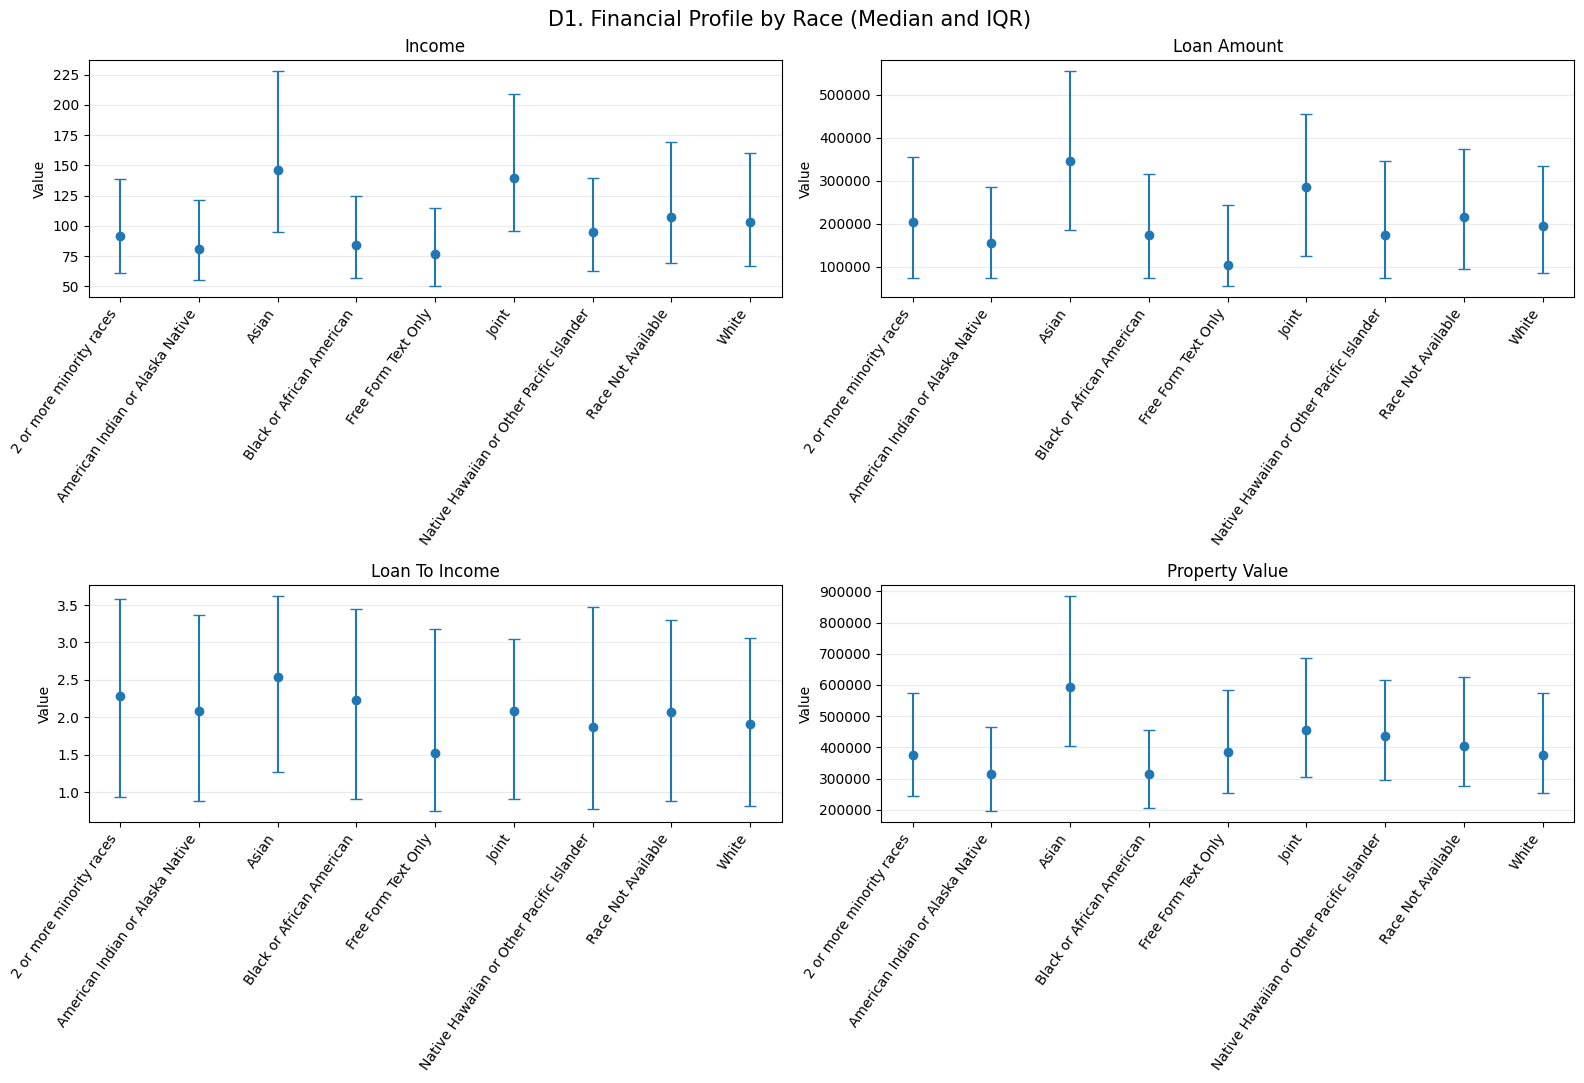

D1 completed.
Output: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq2_profile_by_race.csv
Race groups: 9


In [67]:
# ============================================================
# D1. FINANCIAL PROFILE BY RACE
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F
from pyspark.sql.window import Window

# ------------------------------------------------------------
# Step 1: Initialize paths and thresholds
# ------------------------------------------------------------

output_dir = os.fspath(OUTPUT_DIR)
figure_dir = os.fspath(FIGURE_DIR)

os.makedirs(output_dir, exist_ok=True)
os.makedirs(figure_dir, exist_ok=True)

N_MIN_APPS = globals().get("N_MIN_APPS", 1000)
N_MIN_DENIED = globals().get("N_MIN_DENIED", 100)

FINANCIAL_VARS = [
    "income",
    "loan_amount",
    "loan_to_income",
    "property_value"
]

# ------------------------------------------------------------
# Step 2: Build the shared financial analysis frame
# ------------------------------------------------------------

df_d = (
    df_s0
    .filter(F.col("action_taken").cast("int").isin(1, 2, 3))
    .withColumn(
        "race",
        F.coalesce(
            F.col("derived_race").cast("string"),
            F.lit("Race Missing")
        )
    )
    .withColumn("denied", F.col("is_denied").cast("double"))
    .withColumn("income_num", F.col("income").cast("double"))
    .withColumn("loan_amount_num", F.col("loan_amount").cast("double"))
    .withColumn("lti_num", F.col("loan_to_income").cast("double"))
    .withColumn("property_value_num", F.col("property_value").cast("double"))
    .withColumn(
        "cltv_num",
        F.col("combined_loan_to_value_ratio").cast("double")
    )
    .withColumn(
        "dti_fine",
        F.coalesce(
            F.col("dti_bin_fine").cast("string"),
            F.lit("Missing")
        )
    )
    .withColumn(
        "dti_coarse",
        F.coalesce(
            F.col("dti_bin_coarse").cast("string"),
            F.lit("Missing")
        )
    )
    .withColumn(
        "loan_purpose_norm",
        F.lower(F.trim(F.col("loan_purpose").cast("string")))
    )
    .withColumn(
        "lien_status_norm",
        F.lower(F.trim(F.col("lien_status").cast("string")))
    )
)

# ------------------------------------------------------------
# Step 3: Estimate S0-based quantile boundaries
# ------------------------------------------------------------

QUANTILE_PROBS = [i / 10 for i in range(1, 10)]

quantile_results = df_d.approxQuantile(
    ["income_num", "lti_num"],
    QUANTILE_PROBS,
    0.001
)

income_edges = sorted(set(quantile_results[0]))
lti_edges = sorted(set(quantile_results[1]))

# ------------------------------------------------------------
# Step 4: Create quantile bin expressions
# ------------------------------------------------------------

def make_quantile_bin(column_name, edges):
    col = F.col(column_name)

    expr = F.lit(f"D{len(edges) + 1:02d}")

    for i, edge in reversed(list(enumerate(edges, start=1))):
        expr = F.when(
            col <= F.lit(float(edge)),
            F.lit(f"D{i:02d}")
        ).otherwise(expr)

    return F.when(
        col.isNull(),
        F.lit("Missing")
    ).otherwise(expr)


df_d = (
    df_d
    .withColumn(
        "income_decile",
        make_quantile_bin("income_num", income_edges)
    )
    .withColumn(
        "lti_bin",
        make_quantile_bin("lti_num", lti_edges)
    )
)

# ------------------------------------------------------------
# Step 5: Construct CLTV bins around heaping thresholds
# ------------------------------------------------------------

x = F.col("cltv_num")

df_d = df_d.withColumn(
    "cltv_bin",
    F.when(x.isNull(), "Missing")
    .when(x < 80, "<80")
    .when(F.abs(x - 80) < 1e-8, "80")
    .when(x < 95, "(80,95)")
    .when(F.abs(x - 95) < 1e-8, "95")
    .when(x < 97, "(95,97)")
    .when(F.abs(x - 97) < 1e-8, "97")
    .when(x < 100, "(97,100)")
    .when(F.abs(x - 100) < 1e-8, "100")
    .otherwise(">100")
)

# ------------------------------------------------------------
# Step 6: Calculate financial summaries by race
# ------------------------------------------------------------

summary_exprs = []

for var in FINANCIAL_VARS:
    col_name = {
        "income": "income_num",
        "loan_amount": "loan_amount_num",
        "loan_to_income": "lti_num",
        "property_value": "property_value_num"
    }[var]

    summary_exprs.extend([
        F.count(F.col(col_name)).alias(f"n_{var}"),
        F.percentile_approx(
            F.col(col_name),
            [0.25, 0.50, 0.75],
            10000
        ).alias(f"q_{var}")
    ])

financial_summary = df_d.groupBy("race").agg(*summary_exprs)

numeric_frames = []

for var in FINANCIAL_VARS:
    numeric_frames.append(
        financial_summary.select(
            F.lit("numeric_summary").alias("record_type"),
            "race",
            F.lit(var).alias("variable"),
            F.lit(None).cast("string").alias("category"),
            F.col(f"n_{var}").alias("n"),
            F.col(f"q_{var}").getItem(0).alias("q1"),
            F.col(f"q_{var}").getItem(1).alias("median"),
            F.col(f"q_{var}").getItem(2).alias("q3"),
            F.lit(None).cast("double").alias("share")
        )
    )

d1_numeric = numeric_frames[0]

for frame in numeric_frames[1:]:
    d1_numeric = d1_numeric.unionByName(frame)

# ------------------------------------------------------------
# Step 7: Calculate categorical distributions by race
# ------------------------------------------------------------

mix_frames = []

for variable, bin_col in [
    ("dti_bin_coarse", "dti_coarse"),
    ("cltv_bin", "cltv_bin")
]:

    counts = (
        df_d
        .groupBy("race", F.col(bin_col).alias("category"))
        .agg(F.count("*").alias("n"))
    )

    window = Window.partitionBy("race")

    mix = (
        counts
        .withColumn(
            "share",
            F.col("n") / F.sum("n").over(window)
        )
        .select(
            F.lit("categorical_distribution").alias("record_type"),
            "race",
            F.lit(variable).alias("variable"),
            "category",
            "n",
            F.lit(None).cast("double").alias("q1"),
            F.lit(None).cast("double").alias("median"),
            F.lit(None).cast("double").alias("q3"),
            "share"
        )
    )

    mix_frames.append(mix)

d1_mix = mix_frames[0].unionByName(mix_frames[1])

# ------------------------------------------------------------
# Step 8: Combine and export D1 results
# ------------------------------------------------------------

d1_output = d1_numeric.unionByName(d1_mix)

d1_pd = d1_output.toPandas()

d1_path = os.path.join(
    output_dir,
    "B15_rq2_profile_by_race.csv"
)

d1_pd.to_csv(d1_path, index=False)

# Export quantile boundaries
cutpoint_rows = []

for variable, edges in [
    ("income", income_edges),
    ("loan_to_income", lti_edges)
]:
    for i, edge in enumerate(edges, start=1):
        cutpoint_rows.append({
            "variable": variable,
            "bin": f"D{i:02d}",
            "upper_boundary": float(edge),
            "method": "Spark approxQuantile",
            "relative_error": 0.001
        })

cutpoint_pd = pd.DataFrame(cutpoint_rows)

cutpoint_pd.to_csv(
    os.path.join(
        output_dir,
        "B15_rq2_income_lti_cutpoints.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# Step 9: Visualize financial profiles
# ------------------------------------------------------------

numeric_pd = d1_numeric.toPandas()

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for ax, variable in zip(axes.flatten(), FINANCIAL_VARS):

    subset = numeric_pd[
        numeric_pd["variable"] == variable
    ].dropna(subset=["median", "q1", "q3"])

    subset = subset.sort_values("race")

    positions = np.arange(len(subset))

    lower = (
        subset["median"] - subset["q1"]
    ).clip(lower=0).to_numpy()

    upper = (
        subset["q3"] - subset["median"]
    ).clip(lower=0).to_numpy()

    ax.errorbar(
        positions,
        subset["median"].to_numpy(),
        yerr=np.vstack([lower, upper]),
        fmt="o",
        capsize=4
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(
        subset["race"],
        rotation=55,
        ha="right"
    )

    ax.set_title(variable.replace("_", " ").title())
    ax.set_ylabel("Value")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "D1. Financial Profile by Race (Median and IQR)",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        figure_dir,
        "B15_fig_16_profile_by_race.png"
    ),
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("D1 completed.")
print(f"Output: {d1_path}")
print(f"Race groups: {df_d.select('race').distinct().count()}")

## D2. Denial Rates Across Financial Variables

### Objective
Examine how mortgage denial rates vary across borrower financial
characteristics.

### Input
- Shared financial analysis frame from D1.
- DTI fine categories, including integer points 36–49.
- CLTV categories with heaping thresholds.
- S0-based income deciles.
- S0-based loan-to-income quantile bins.

### Process
1. Aggregate application and denial counts by financial category.
2. Calculate denial rates for each category.
3. Calculate 95% Wilson confidence intervals.
4. Apply D-M minimum cell-size flags.
5. Visualize denial-rate curves with confidence intervals.

### Output
- `B15_rq2_denial_curves.csv`
- `B15_fig_17_denial_curves.png`

### Method Notes
Wilson intervals are used instead of normal approximation intervals
because denial rates are proportions.

Low-N categories remain in the output table but are flagged
to prevent unstable comparisons.

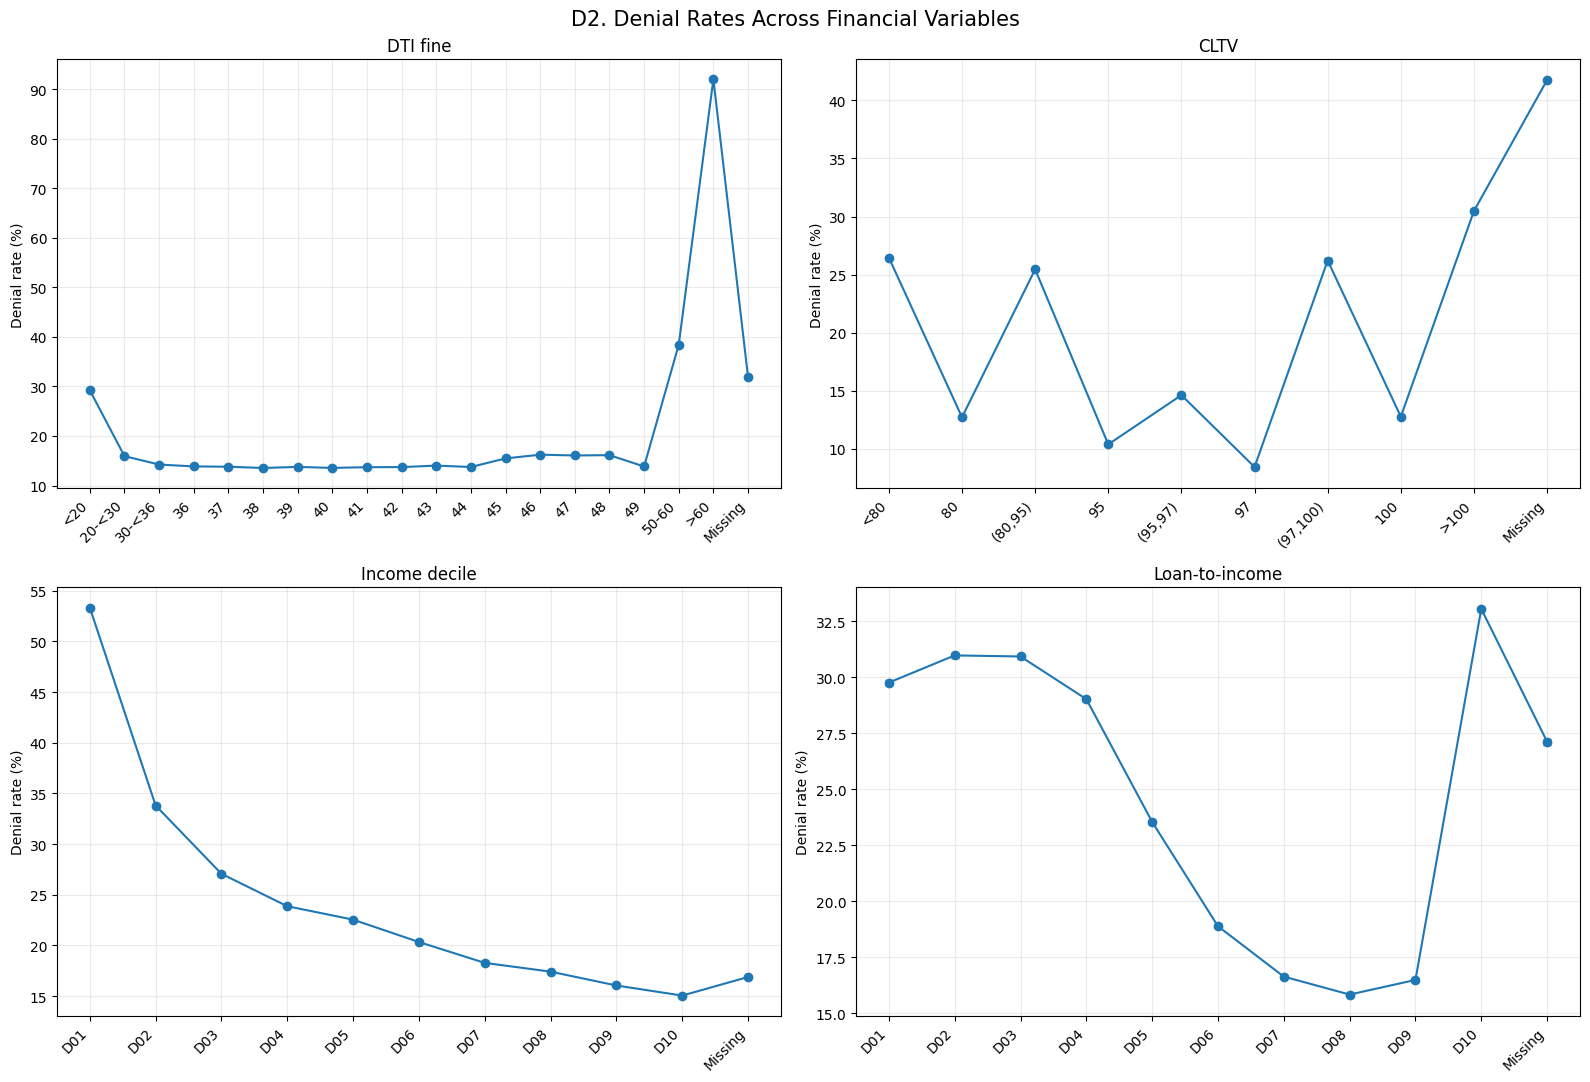

D2 completed.
Output: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq2_denial_curves.csv
Number of curve categories: 52
Low-N categories: 0


In [68]:

# ============================================================
# D2. DENIAL VS FINANCIAL VARIABLES
# ============================================================

# ------------------------------------------------------------
# Step 1: Define Wilson confidence intervals
# ------------------------------------------------------------

Z = 1.959963984540054
Z2 = Z ** 2

def add_wilson_ci(data):

    n = F.col("n_apps").cast("double")
    d = F.col("n_denied").cast("double")

    p = d / n
    denominator = 1 + Z2 / n

    center = (
        p + F.lit(Z2) / (2 * n)
    ) / denominator

    margin = (
        F.lit(Z) * F.sqrt(
            (p * (1 - p) / n)
            + F.lit(Z2) / (4 * n * n)
        )
    ) / denominator

    return (
        data
        .withColumn("denial_rate", p)
        .withColumn(
            "wilson_lower",
            F.greatest(F.lit(0.0), center - margin)
        )
        .withColumn(
            "wilson_upper",
            F.least(F.lit(1.0), center + margin)
        )
        .withColumn(
            "low_n",
            (F.col("n_apps") < N_MIN_APPS)
            | (F.col("n_denied") < N_MIN_DENIED)
        )
    )


# ------------------------------------------------------------
# Step 2: Build denial curves
# ------------------------------------------------------------

def build_denial_curve(data, bin_col, variable, order_type):

    counts = (
        data
        .groupBy(F.col(bin_col).alias("bin"))
        .agg(
            F.count("*").alias("n_apps"),
            F.sum(
                F.col("denied").cast("long")
            ).alias("n_denied")
        )
    )

    result = add_wilson_ci(counts)

    if order_type == "cltv":

        order_expr = (
            F.when(F.col("bin") == "<80", 0)
            .when(F.col("bin") == "80", 1)
            .when(F.col("bin") == "(80,95)", 2)
            .when(F.col("bin") == "95", 3)
            .when(F.col("bin") == "(95,97)", 4)
            .when(F.col("bin") == "97", 5)
            .when(F.col("bin") == "(97,100)", 6)
            .when(F.col("bin") == "100", 7)
            .when(F.col("bin") == ">100", 8)
            .otherwise(999)
        )

    else:

        # Safe conversion: categories without digits
        # (e.g. Missing) will not cause ANSI cast errors.
        order_expr = F.expr(
            "try_cast(regexp_extract(bin, '([0-9]+)', 1) AS INT)"
        )

        order_expr = F.coalesce(
            order_expr,
            F.lit(999)
        )

    return (
        result
        .withColumn("bin_order", order_expr)
        .withColumn("variable", F.lit(variable))
        .select(
            "variable",
            "bin",
            "bin_order",
            "n_apps",
            "n_denied",
            "denial_rate",
            "wilson_lower",
            "wilson_upper",
            "low_n"
        )
    )


# ------------------------------------------------------------
# Step 3: Calculate four financial denial curves
# ------------------------------------------------------------

curve_frames = [
    build_denial_curve(
        df_d, "dti_fine", "DTI fine", "numeric"
    ),
    build_denial_curve(
        df_d, "cltv_bin", "CLTV", "cltv"
    ),
    build_denial_curve(
        df_d, "income_decile", "Income decile", "decile"
    ),
    build_denial_curve(
        df_d, "lti_bin", "Loan-to-income", "decile"
    )
]

d2_output = curve_frames[0]

for frame in curve_frames[1:]:
    d2_output = d2_output.unionByName(frame)

d2_output = d2_output.orderBy(
    "variable",
    "bin_order"
)


# ------------------------------------------------------------
# Step 4: Export results
# ------------------------------------------------------------

d2_path = os.path.join(
    output_dir,
    "B15_rq2_denial_curves.csv"
)

d2_pd = d2_output.toPandas()

d2_pd.to_csv(d2_path, index=False)


# ------------------------------------------------------------
# Step 5: Visualize denial curves
# ------------------------------------------------------------

variables = [
    "DTI fine",
    "CLTV",
    "Income decile",
    "Loan-to-income"
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for ax, variable in zip(axes.flatten(), variables):

    subset = d2_pd[
        (d2_pd["variable"] == variable)
        & (~d2_pd["low_n"])
    ].sort_values("bin_order")

    if subset.empty:
        ax.set_title(f"{variable} - No reliable cells")
        continue

    x = np.arange(len(subset))
    rates = subset["denial_rate"].to_numpy()

    lower = (
        rates - subset["wilson_lower"].to_numpy()
    ).clip(min=0)

    upper = (
        subset["wilson_upper"].to_numpy() - rates
    ).clip(min=0)

    ax.errorbar(
        x,
        rates * 100,
        yerr=np.vstack([lower, upper]) * 100,
        marker="o",
        capsize=3
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        subset["bin"],
        rotation=45,
        ha="right"
    )

    ax.set_title(variable)
    ax.set_ylabel("Denial rate (%)")
    ax.grid(alpha=0.25)

fig.suptitle(
    "D2. Denial Rates Across Financial Variables",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        figure_dir,
        "B15_fig_17_denial_curves.png"
    ),
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("D2 completed.")
print(f"Output: {d2_path}")
print(f"Number of curve categories: {len(d2_pd)}")
print(f"Low-N categories: {d2_pd['low_n'].sum()}")


## D3. Joint DTI × CLTV Denial Surface

### Objective
Investigate the joint relationship between borrower debt burden
and collateral leverage in mortgage denial outcomes.

### Input
- DTI fine categories.
- CLTV categories.
- Loan purpose.
- Lien status.
- Denial outcome.

### Process
1. Identify first-lien home purchase applications.
2. Identify first-lien refinancing applications.
3. Aggregate application and denial counts by DTI × CLTV.
4. Calculate denial rates and D-M reliability flags.
5. Visualize the two financial surfaces separately.

### Output
- `B15_rq2_dti_cltv_heatmap.csv`
- `B15_fig_18_dti_cltv_heatmap.png`

### Method Notes
The two segments are analyzed separately to avoid mixing
different mortgage purposes.

Cells below the approved minimum application or denial counts
are retained in the CSV with a low_n flag but excluded
from the reliable heatmap display.

+--------------------+-------+
|loan_segment        |count  |
+--------------------+-------+
|First-lien purchase |3868654|
|First-lien refinance|1461280|
+--------------------+-------+



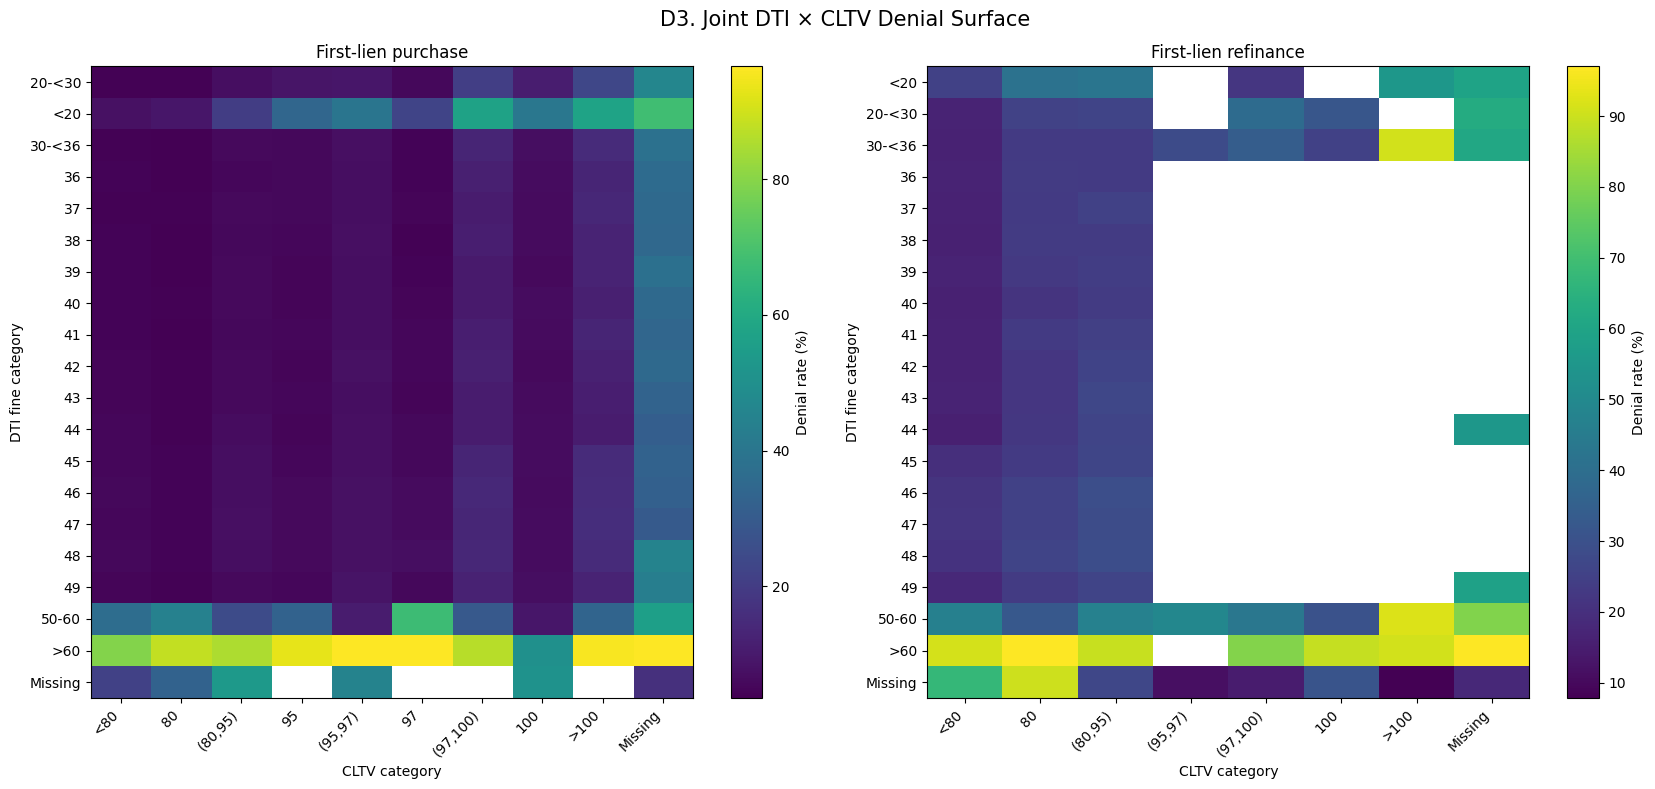

D3 completed.
Output: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq2_dti_cltv_heatmap.csv
Total financial cells: 400
Reliable cells: 283
Low-N cells: 117


In [69]:

# ============================================================
# D3. JOINT DTI × CLTV SURFACE
# ============================================================

# ------------------------------------------------------------
# Step 1: Define loan-purpose and lien categories
# ------------------------------------------------------------

purchase_values = [
    "1",
    "home purchase",
    "purchase"
]

refinance_values = [
    "31",
    "32",
    "refinancing",
    "cash-out refinancing",
    "cash out refinancing",
    "refinance"
]

first_lien_values = [
    "1",
    "first lien",
    "first-lien"
]

purpose = F.col("loan_purpose_norm")
lien = F.col("lien_status_norm")


# ------------------------------------------------------------
# Step 2: Assign analytical segments
# ------------------------------------------------------------

df_d3 = (
    df_d
    .withColumn(
        "loan_segment",
        F.when(
            lien.isin(first_lien_values)
            & purpose.isin(purchase_values),
            "First-lien purchase"
        )
        .when(
            lien.isin(first_lien_values)
            & purpose.isin(refinance_values),
            "First-lien refinance"
        )
    )
    .filter(F.col("loan_segment").isNotNull())
)


# ------------------------------------------------------------
# Step 3: Validate segment coverage
# ------------------------------------------------------------

segment_check = (
    df_d3
    .groupBy("loan_segment")
    .count()
    .orderBy("loan_segment")
)

segment_check.show(truncate=False)


# ------------------------------------------------------------
# Step 4: Aggregate DTI × CLTV cells
# ------------------------------------------------------------

d3_counts = (
    df_d3
    .groupBy(
        "loan_segment",
        "dti_fine",
        "cltv_bin"
    )
    .agg(
        F.count("*").alias("n_apps"),
        F.sum(
            F.col("denied").cast("long")
        ).alias("n_denied")
    )
)


# ------------------------------------------------------------
# Step 5: Calculate rates and safe category ordering
# ------------------------------------------------------------

d3_output = (
    d3_counts
    .withColumn(
        "denial_rate",
        F.col("n_denied") / F.col("n_apps")
    )
    .withColumn(
        "low_n",
        (F.col("n_apps") < N_MIN_APPS)
        | (F.col("n_denied") < N_MIN_DENIED)
    )
    .withColumn(
        "dti_order",
        F.coalesce(
            F.expr(
                "try_cast(regexp_extract(dti_fine, '([0-9]+)', 1) AS INT)"
            ),
            F.lit(999)
        )
    )
    .withColumn(
        "cltv_order",
        F.when(F.col("cltv_bin") == "<80", 0)
        .when(F.col("cltv_bin") == "80", 1)
        .when(F.col("cltv_bin") == "(80,95)", 2)
        .when(F.col("cltv_bin") == "95", 3)
        .when(F.col("cltv_bin") == "(95,97)", 4)
        .when(F.col("cltv_bin") == "97", 5)
        .when(F.col("cltv_bin") == "(97,100)", 6)
        .when(F.col("cltv_bin") == "100", 7)
        .when(F.col("cltv_bin") == ">100", 8)
        .otherwise(999)
    )
    .select(
        "loan_segment",
        "dti_fine",
        "dti_order",
        "cltv_bin",
        "cltv_order",
        "n_apps",
        "n_denied",
        "denial_rate",
        "low_n"
    )
)


# ------------------------------------------------------------
# Step 6: Export D3 results
# ------------------------------------------------------------

d3_path = os.path.join(
    output_dir,
    "B15_rq2_dti_cltv_heatmap.csv"
)

d3_pd = d3_output.toPandas()

d3_pd.to_csv(d3_path, index=False)


# ------------------------------------------------------------
# Step 7: Visualize reliable cells
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(17, 8))

segments = [
    "First-lien purchase",
    "First-lien refinance"
]

for ax, segment in zip(axes, segments):

    subset = d3_pd[
        (d3_pd["loan_segment"] == segment)
        & (~d3_pd["low_n"])
    ].copy()

    if subset.empty:
        ax.set_title(f"{segment} - No reliable cells")
        continue

    pivot = subset.pivot(
        index="dti_fine",
        columns="cltv_bin",
        values="denial_rate"
    )

    dti_order = (
        subset[
            ["dti_fine", "dti_order"]
        ]
        .drop_duplicates()
        .sort_values("dti_order")["dti_fine"]
        .tolist()
    )

    cltv_order = (
        subset[
            ["cltv_bin", "cltv_order"]
        ]
        .drop_duplicates()
        .sort_values("cltv_order")["cltv_bin"]
        .tolist()
    )

    pivot = pivot.reindex(
        index=dti_order,
        columns=cltv_order
    )

    im = ax.imshow(
        pivot.to_numpy() * 100,
        aspect="auto",
        interpolation="nearest"
    )

    ax.set_xticks(np.arange(len(cltv_order)))
    ax.set_xticklabels(
        cltv_order,
        rotation=45,
        ha="right"
    )

    ax.set_yticks(np.arange(len(dti_order)))
    ax.set_yticklabels(dti_order)

    ax.set_xlabel("CLTV category")
    ax.set_ylabel("DTI fine category")
    ax.set_title(segment)

    fig.colorbar(
        im,
        ax=ax,
        label="Denial rate (%)"
    )

fig.suptitle(
    "D3. Joint DTI × CLTV Denial Surface",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        figure_dir,
        "B15_fig_18_dti_cltv_heatmap.png"
    ),
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# Step 8: Report validation results
# ------------------------------------------------------------

print("D3 completed.")
print(f"Output: {d3_path}")
print(f"Total financial cells: {len(d3_pd)}")
print(f"Reliable cells: {(~d3_pd['low_n']).sum()}")
print(f"Low-N cells: {d3_pd['low_n'].sum()}")


## D4. Racial Gaps Within Financial Strata

### Objective
Examine whether racial differences in mortgage denial rates
persist when comparing applicants with similar financial profiles.

### Input
- Race and denial outcome.
- DTI fine categories.
- CLTV categories.
- S0-based income deciles.
- White as the reference group.

### Process
1. Construct financial strata using DTI × CLTV × income decile.
2. Aggregate application and denial counts by race and financial stratum.
3. Compare each eligible racial group against White.
4. Apply the D-M pooling rule when either comparison group
   fails the minimum application or denial threshold.
5. Calculate within-stratum denial-rate gaps.
6. Perform a two-component Kitagawa decomposition:
   - Composition effect: differences in financial-stratum distributions.
   - Rate effect: differences in denial rates within financial strata.
7. Verify that both components sum to the raw gap.

### Output
- `B15_rq2_stratified_gap.csv`
- `B15_fig_19_gap_by_controls.png`

### Method Notes
Only applications with observed DTI, CLTV, and income are included
in this analysis.

Low-N strata are pooled into an "Other / pooled low-N" category,
following the exploratory decomposition approach in Part C.

The decomposition is descriptive arithmetic, not a causal model.

The composition and rate components must reconstruct
the raw group-reference denial-rate gap.

D4 comparison groups: ['2 or more minority races', 'American Indian or Alaska Native', 'Asian', 'Black or African American', 'Joint', 'Native Hawaiian or Other Pacific Islander']


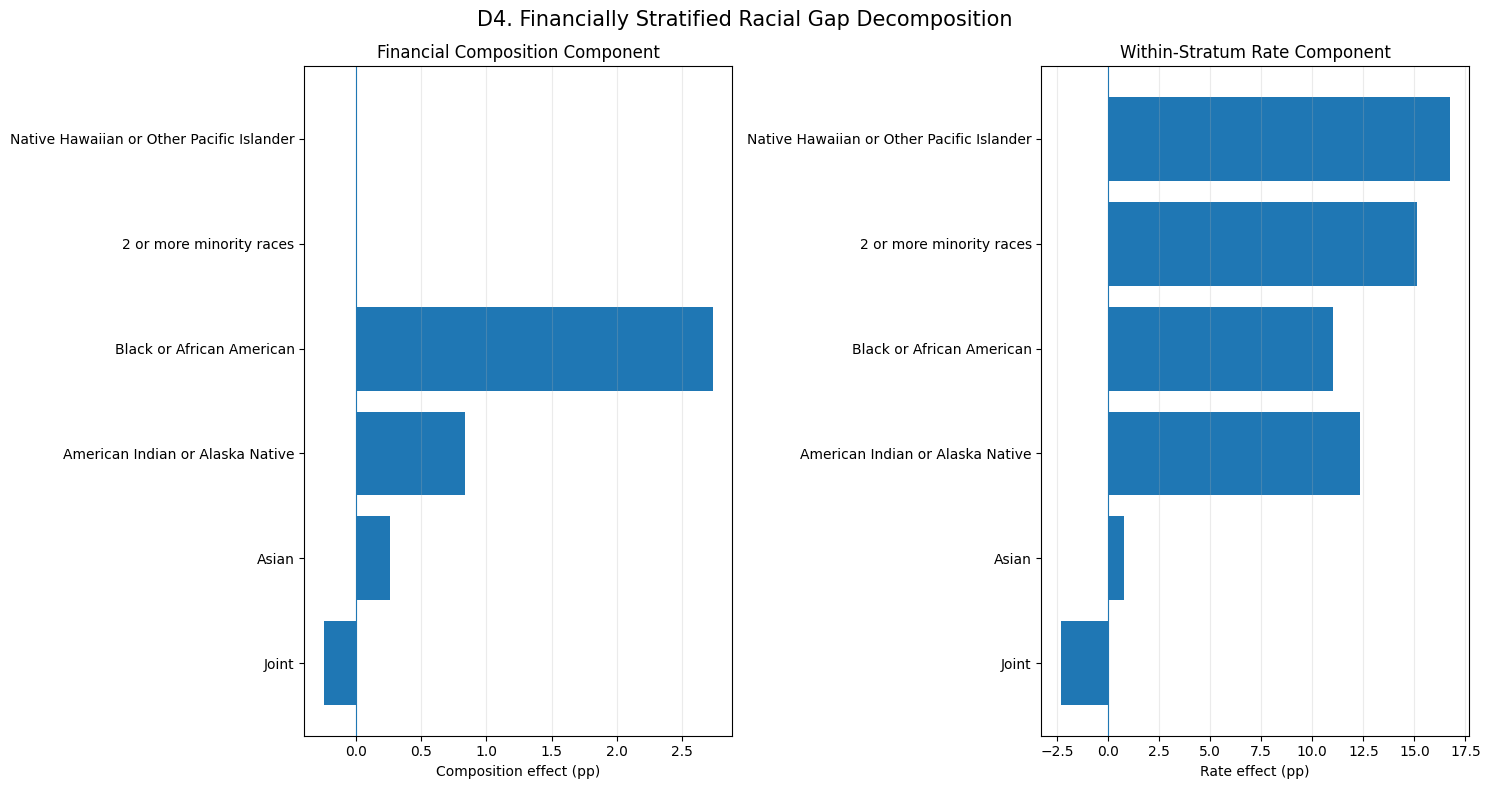

D4 completed.
Output: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq2_stratified_gap.csv
Comparison groups: 6
Maximum reconstruction error: 0.000000000000 pp


,group,raw_gap_pp,composition_pp,rate_component_pp,pooled_strata_count,reconstruction_error_pp
240,Native Hawaiian or Other Pacific Islander,16.7241,0.0000,16.7241,1710,0.0000
1,2 or more minority races,15.1433,0.0000,15.1433,1710,0.0000
223,Black or African American,13.7719,2.7340,11.0379,1592,-0.0000
4,American Indian or Alaska Native,13.1891,0.8395,12.3497,1709,0.0000
103,Asian,1.0474,0.2604,0.7870,1613,-0.0000
238,Joint,-2.5576,-0.2452,-2.3124,1697,0.0000


In [70]:
# ============================================================
# D4. GAP WITHIN FINANCIAL STRATA
# ============================================================

# ------------------------------------------------------------
# Step 1: Define the complete financial analysis sample
# ------------------------------------------------------------

df_d4 = (
    df_d
    .filter(F.col("income_decile") != "Missing")
    .filter(F.col("cltv_bin") != "Missing")
    .filter(
        F.regexp_extract(
            F.col("dti_fine"),
            r"\d+",
            0
        ) != ""
    )
    .filter(F.col("race").isNotNull())
    .withColumn(
        "financial_stratum",
        F.concat_ws(
            " | ",
            F.col("dti_fine"),
            F.col("cltv_bin"),
            F.col("income_decile")
        )
    )
)

# ------------------------------------------------------------
# Step 2: Aggregate race × financial-stratum counts
# ------------------------------------------------------------

d4_strata = (
    df_d4
    .groupBy("race", "financial_stratum")
    .agg(
        F.count("*").alias("n_apps"),
        F.sum("denied").alias("n_denied")
    )
)

# ------------------------------------------------------------
# Step 3: Identify eligible comparison groups
# ------------------------------------------------------------

REFERENCE_RACE = "White"

EXCLUDED_GAP_GROUPS = [
    "Race Not Available",
    "Free Form Text Only",
    "Race Missing"
]

race_groups = [
    row["race"]
    for row in (
        df_d4
        .select("race")
        .distinct()
        .collect()
    )
]

if REFERENCE_RACE not in race_groups:
    raise ValueError(
        "White reference group is missing from the D4 sample."
    )

comparison_groups = sorted([
    race for race in race_groups
    if race != REFERENCE_RACE
    and race not in EXCLUDED_GAP_GROUPS
])

print("D4 comparison groups:", comparison_groups)

# ------------------------------------------------------------
# Step 4: Define the common output schema
# ------------------------------------------------------------

d4_frames = []

for group_name in comparison_groups:

    # --------------------------------------------------------
    # Step 4.1: Extract group and reference counts
    # --------------------------------------------------------

    group_data = (
        d4_strata
        .filter(F.col("race") == group_name)
        .select(
            "financial_stratum",
            F.col("n_apps").alias("n_group"),
            F.col("n_denied").alias("d_group")
        )
    )

    white_data = (
        d4_strata
        .filter(F.col("race") == REFERENCE_RACE)
        .select(
            "financial_stratum",
            F.col("n_apps").alias("n_white"),
            F.col("n_denied").alias("d_white")
        )
    )

    # --------------------------------------------------------
    # Step 4.2: Align both groups on financial strata
    # --------------------------------------------------------

    aligned = (
        group_data
        .join(
            white_data,
            on="financial_stratum",
            how="full_outer"
        )
        .fillna({
            "n_group": 0,
            "d_group": 0,
            "n_white": 0,
            "d_white": 0
        })
    )

    # --------------------------------------------------------
    # Step 4.3: Identify unreliable strata
    # --------------------------------------------------------

    aligned = aligned.withColumn(
        "low_n",
        (F.col("n_group") < N_MIN_APPS)
        | (F.col("n_white") < N_MIN_APPS)
        | (F.col("d_group") < N_MIN_DENIED)
        | (F.col("d_white") < N_MIN_DENIED)
    )

    # --------------------------------------------------------
    # Step 4.4: Pool low-N strata
    # --------------------------------------------------------

    aligned = aligned.withColumn(
        "pooled_stratum",
        F.when(
            F.col("low_n"),
            "Other / pooled low-N"
        ).otherwise(
            F.col("financial_stratum")
        )
    )

    pooled = (
        aligned
        .groupBy("pooled_stratum")
        .agg(
            F.sum("n_group").alias("n_group"),
            F.sum("d_group").alias("d_group"),
            F.sum("n_white").alias("n_white"),
            F.sum("d_white").alias("d_white"),
            F.sum(
                F.when(F.col("low_n"), 1).otherwise(0)
            ).alias("pooled_strata_count")
        )
    )

    # --------------------------------------------------------
    # Step 4.5: Calculate group-specific stratum weights
    # --------------------------------------------------------

    totals = pooled.agg(
        F.sum("n_group").alias("total_n_group"),
        F.sum("d_group").alias("total_d_group"),
        F.sum("n_white").alias("total_n_white"),
        F.sum("d_white").alias("total_d_white")
    )

    calc = pooled.crossJoin(totals)

    calc = (
        calc
        .withColumn(
            "weight_group",
            F.col("n_group") / F.col("total_n_group")
        )
        .withColumn(
            "weight_white",
            F.col("n_white") / F.col("total_n_white")
        )
        .withColumn(
            "rate_group",
            F.when(
                F.col("n_group") > 0,
                F.col("d_group") / F.col("n_group")
            ).otherwise(0.0)
        )
        .withColumn(
            "rate_white",
            F.when(
                F.col("n_white") > 0,
                F.col("d_white") / F.col("n_white")
            ).otherwise(0.0)
        )
    )

    # --------------------------------------------------------
    # Step 4.6: Calculate Kitagawa components
    # --------------------------------------------------------

    calc = (
        calc
        .withColumn(
            "gap_pp",
            (
                F.col("rate_group")
                - F.col("rate_white")
            ) * 100
        )
        .withColumn(
            "composition_pp",
            (
                (F.col("rate_group") + F.col("rate_white")) / 2
            ) * (
                F.col("weight_group")
                - F.col("weight_white")
            ) * 100
        )
        .withColumn(
            "rate_component_pp",
            (
                (F.col("weight_group") + F.col("weight_white")) / 2
            ) * (
                F.col("rate_group")
                - F.col("rate_white")
            ) * 100
        )
    )

    # --------------------------------------------------------
    # Step 4.7: Calculate overall gap and reconstruction
    # --------------------------------------------------------

    summary = calc.agg(
        F.sum("composition_pp").alias("composition_pp"),
        F.sum("rate_component_pp").alias("rate_component_pp"),
        F.first("total_n_group").alias("total_n_group"),
        F.first("total_d_group").alias("total_d_group"),
        F.first("total_n_white").alias("total_n_white"),
        F.first("total_d_white").alias("total_d_white"),
        F.first("pooled_strata_count").alias("unused_check")
    )

    # Count pooled original strata separately
    pooled_count = aligned.filter(
        F.col("low_n")
    ).count()

    summary = (
        summary
        .withColumn(
            "rate_group",
            F.col("total_d_group") / F.col("total_n_group")
        )
        .withColumn(
            "rate_white",
            F.col("total_d_white") / F.col("total_n_white")
        )
        .withColumn(
            "raw_gap_pp",
            (F.col("rate_group") - F.col("rate_white")) * 100
        )
        .withColumn(
            "reconstructed_gap_pp",
            F.col("composition_pp") + F.col("rate_component_pp")
        )
        .withColumn(
            "reconstruction_error_pp",
            F.col("reconstructed_gap_pp") - F.col("raw_gap_pp")
        )
        .withColumn(
            "pooled_strata_count",
            F.lit(pooled_count)
        )
        .withColumn(
            "group_overall_low_n",
            (F.col("total_n_group") < N_MIN_APPS)
            | (F.col("total_d_group") < N_MIN_DENIED)
        )
    )

    # --------------------------------------------------------
    # Step 4.8: Validate Kitagawa identity
    # --------------------------------------------------------

    check = summary.select(
        "raw_gap_pp",
        "reconstructed_gap_pp",
        "reconstruction_error_pp"
    ).first()

    if abs(check["reconstruction_error_pp"]) > 1e-6:
        raise AssertionError(
            f"Kitagawa reconstruction failed for {group_name}: "
            f"{check['reconstruction_error_pp']}"
        )

    # --------------------------------------------------------
    # Step 4.9: Build detailed stratum records
    # --------------------------------------------------------

    detail = calc.select(
        F.lit("stratum").alias("record_type"),
        F.lit(group_name).alias("group"),
        F.lit(REFERENCE_RACE).alias("reference"),
        F.col("pooled_stratum").alias("stratum"),
        F.col("n_group"),
        F.col("d_group").alias("denied_group"),
        F.col("rate_group"),
        F.col("n_white"),
        F.col("d_white").alias("denied_white"),
        F.col("rate_white"),
        F.col("gap_pp"),
        F.col("composition_pp"),
        F.col("rate_component_pp"),
        F.lit(None).cast("double").alias("raw_gap_pp"),
        F.col("pooled_strata_count"),
        F.lit(None).cast("double").alias(
            "reconstruction_error_pp"
        ),
        F.lit(False).alias("group_overall_low_n")
    )

    # --------------------------------------------------------
    # Step 4.10: Build decomposition summary record
    # --------------------------------------------------------

    summary_record = summary.select(
        F.lit("decomposition").alias("record_type"),
        F.lit(group_name).alias("group"),
        F.lit(REFERENCE_RACE).alias("reference"),
        F.lit("ALL_STRATA").alias("stratum"),
        F.col("total_n_group").alias("n_group"),
        F.col("total_d_group").alias("denied_group"),
        F.col("rate_group"),
        F.col("total_n_white").alias("n_white"),
        F.col("total_d_white").alias("denied_white"),
        F.col("rate_white"),
        F.col("raw_gap_pp").alias("gap_pp"),
        F.col("composition_pp"),
        F.col("rate_component_pp"),
        F.col("raw_gap_pp"),
        F.col("pooled_strata_count"),
        F.col("reconstruction_error_pp"),
        F.col("group_overall_low_n")
    )

    d4_frames.extend([
        detail,
        summary_record
    ])

# ------------------------------------------------------------
# Step 5: Combine all comparisons
# ------------------------------------------------------------

if not d4_frames:
    raise ValueError(
        "No eligible racial comparison groups were found in D4."
    )

d4_output = d4_frames[0]

for frame in d4_frames[1:]:
    d4_output = d4_output.unionByName(frame)

# ------------------------------------------------------------
# Step 6: Export D4 results
# ------------------------------------------------------------

d4_path = os.path.join(
    output_dir,
    "B15_rq2_stratified_gap.csv"
)

d4_pd = d4_output.toPandas()

d4_pd.to_csv(d4_path, index=False)

# ------------------------------------------------------------
# Step 7: Final decomposition validation
# ------------------------------------------------------------

d4_summary_pd = d4_pd[
    d4_pd["record_type"] == "decomposition"
].copy()

max_error = d4_summary_pd[
    "reconstruction_error_pp"
].abs().max()

assert max_error <= 1e-6, (
    f"Kitagawa identity failed. Maximum error: {max_error}"
)

# ------------------------------------------------------------
# Step 8: Visualize composition and rate components
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 8))

plot_data = d4_summary_pd.sort_values("gap_pp")

y = np.arange(len(plot_data))

axes[0].barh(
    y,
    plot_data["composition_pp"]
)

axes[0].set_yticks(y)
axes[0].set_yticklabels(plot_data["group"])
axes[0].axvline(0, linewidth=0.8)
axes[0].set_xlabel("Composition effect (pp)")
axes[0].set_title("Financial Composition Component")
axes[0].grid(axis="x", alpha=0.25)

axes[1].barh(
    y,
    plot_data["rate_component_pp"]
)

axes[1].set_yticks(y)
axes[1].set_yticklabels(plot_data["group"])
axes[1].axvline(0, linewidth=0.8)
axes[1].set_xlabel("Rate effect (pp)")
axes[1].set_title("Within-Stratum Rate Component")
axes[1].grid(axis="x", alpha=0.25)

fig.suptitle(
    "D4. Financially Stratified Racial Gap Decomposition",
    fontsize=15
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        figure_dir,
        "B15_fig_19_gap_by_controls.png"
    ),
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Step 9: Report validation results
# ------------------------------------------------------------

print("D4 completed.")
print(f"Output: {d4_path}")
print(f"Comparison groups: {len(d4_summary_pd)}")
print(f"Maximum reconstruction error: {max_error:.12f} pp")

display(
    d4_summary_pd[
        [
            "group",
            "raw_gap_pp",
            "composition_pp",
            "rate_component_pp",
            "pooled_strata_count",
            "reconstruction_error_pp"
        ]
    ].sort_values("raw_gap_pp", ascending=False)
)

## D5. Common Support and Financial Overlap

### Objective
Evaluate whether minority applicants and White applicants
occupy comparable regions of financial space.

### Input
- Race.
- DTI fine categories.
- CLTV categories.
- S0-based income deciles.
- White as the reference group.

### Process
1. Construct financial strata using DTI × CLTV × income decile.
2. Aggregate application counts by race and financial stratum.
3. Identify strata where the White reference group has at least
   N_MIN_APPS applications.
4. Calculate the share of each comparison group's applicants
   located in supported financial strata.
5. Identify financial regions with insufficient reference-group
   representation.

### Output
- B15_rq2_common_support.csv

### Method Notes
The analysis focuses on applicants with complete financial
information required to construct the three-dimensional strata.

Race Not Available and Free Form Text Only are retained
as separate categories in the descriptive sample but excluded
from headline minority-versus-White comparisons.

Common support is a descriptive overlap diagnostic.
It does not establish causal comparability.

In [71]:

# ============================================================
# D5. COMMON SUPPORT / OVERLAP
# ============================================================

# ------------------------------------------------------------
# Step 1: Define reference group and comparison exclusions
# ------------------------------------------------------------

REFERENCE_RACE = "White"

EXCLUDED_GAP_GROUPS = [
    "Race Not Available",
    "Free Form Text Only",
    "Race Missing"
]

# ------------------------------------------------------------
# Step 2: Construct complete financial strata
# ------------------------------------------------------------

df_d5 = (
    df_d
    .filter(F.col("income_decile") != "Missing")
    .filter(F.col("cltv_bin") != "Missing")
    .filter(F.col("dti_fine").rlike("[0-9]"))
    .withColumn(
        "financial_stratum",
        F.concat_ws(
            " | ",
            F.col("dti_fine"),
            F.col("cltv_bin"),
            F.col("income_decile")
        )
    )
)

# ------------------------------------------------------------
# Step 3: Aggregate applications by race and stratum
# ------------------------------------------------------------

d5_counts = (
    df_d5
    .groupBy("race", "financial_stratum")
    .agg(F.count("*").alias("n_apps"))
)

group_counts = (
    d5_counts
    .filter(
        (F.col("race") != REFERENCE_RACE)
        & (~F.col("race").isin(EXCLUDED_GAP_GROUPS))
    )
    .select(
        "race",
        "financial_stratum",
        F.col("n_apps").alias("group_n")
    )
)

white_counts = (
    d5_counts
    .filter(F.col("race") == REFERENCE_RACE)
    .select(
        "financial_stratum",
        F.col("n_apps").alias("reference_n")
    )
)

# ------------------------------------------------------------
# Step 4: Identify supported and unsupported strata
# ------------------------------------------------------------

d5_aligned = (
    group_counts
    .join(
        white_counts,
        on="financial_stratum",
        how="left"
    )
    .fillna({"reference_n": 0})
    .withColumn(
        "reference_support",
        F.col("reference_n") >= F.lit(N_MIN_APPS)
    )
)

race_window = Window.partitionBy("race")

d5_detail = (
    d5_aligned
    .withColumn(
        "group_total_n",
        F.sum("group_n").over(race_window)
    )
    .withColumn(
        "group_share",
        F.col("group_n") / F.col("group_total_n")
    )
    .withColumn(
        "supported_group_apps",
        F.when(
            F.col("reference_support"),
            F.col("group_n")
        ).otherwise(0)
    )
    .withColumn(
        "unsupported_group_apps",
        F.when(
            ~F.col("reference_support"),
            F.col("group_n")
        ).otherwise(0)
    )
    .withColumn(
        "record_type",
        F.lit("stratum")
    )
    .withColumn(
        "support_share",
        F.lit(None).cast("double")
    )
    .withColumn(
        "unsupported_share",
        F.lit(None).cast("double")
    )
    .select(
        "record_type",
        "race",
        "financial_stratum",
        "group_n",
        "reference_n",
        "reference_support",
        "group_share",
        "supported_group_apps",
        "unsupported_group_apps",
        "support_share",
        "unsupported_share"
    )
)

# ------------------------------------------------------------
# Step 5: Summarize common support by racial group
# ------------------------------------------------------------

d5_summary = (
    d5_aligned
    .groupBy("race")
    .agg(
        F.sum("group_n").alias("group_n"),
        F.sum("supported_group_apps").alias(
            "supported_group_apps"
        ) if "supported_group_apps" in d5_aligned.columns
        else F.lit(0).alias("supported_group_apps")
    )
)

# Recalculate summary directly from aligned strata.
d5_summary = (
    d5_aligned
    .groupBy("race")
    .agg(
        F.sum("group_n").alias("group_n"),
        F.sum(
            F.when(
                F.col("reference_support"),
                F.col("group_n")
            ).otherwise(0)
        ).alias("supported_group_apps"),
        F.sum(
            F.when(
                ~F.col("reference_support"),
                F.col("group_n")
            ).otherwise(0)
        ).alias("unsupported_group_apps"),
        F.count("*").alias("n_financial_strata"),
        F.sum(
            F.when(
                F.col("reference_support"),
                1
            ).otherwise(0)
        ).alias("n_supported_strata")
    )
    .withColumn(
        "support_share",
        F.col("supported_group_apps") / F.col("group_n")
    )
    .withColumn(
        "unsupported_share",
        F.col("unsupported_group_apps") / F.col("group_n")
    )
    .withColumn(
        "record_type",
        F.lit("group_summary")
    )
    .withColumn(
        "financial_stratum",
        F.lit("ALL_STRATA")
    )
    .withColumn(
        "reference_n",
        F.lit(None).cast("long")
    )
    .withColumn(
        "reference_support",
        F.lit(None).cast("boolean")
    )
    .withColumn(
        "group_share",
        F.lit(None).cast("double")
    )
    .select(
        "record_type",
        "race",
        "financial_stratum",
        "group_n",
        "reference_n",
        "reference_support",
        "group_share",
        "supported_group_apps",
        "unsupported_group_apps",
        "support_share",
        "unsupported_share",
        "n_financial_strata",
        "n_supported_strata"
    )
)

# ------------------------------------------------------------
# Step 6: Export D5
# ------------------------------------------------------------

d5_output = d5_detail.join(
    d5_summary.select(
        "race",
        "n_financial_strata",
        "n_supported_strata"
    ),
    on="race",
    how="left"
)

d5_detail_pd = d5_output.toPandas()
d5_summary_pd = d5_summary.toPandas()

d5_pd = pd.concat(
    [d5_detail_pd, d5_summary_pd],
    ignore_index=True,
    sort=False
)

d5_path = os.path.join(
    output_dir,
    "B15_rq2_common_support.csv"
)

d5_pd.to_csv(d5_path, index=False)

# ------------------------------------------------------------
# Step 7: Validation
# ------------------------------------------------------------

print("D5 completed.")
print(f"Output: {d5_path}")

display(
    d5_summary_pd[
        [
            "race",
            "group_n",
            "supported_group_apps",
            "unsupported_group_apps",
            "support_share",
            "unsupported_share",
            "n_financial_strata",
            "n_supported_strata"
        ]
    ].sort_values("support_share")
)


D5 completed.
Output: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq2_common_support.csv


,race,group_n,supported_group_apps,unsupported_group_apps,support_share,unsupported_share,n_financial_strata,n_supported_strata
4,Black or African American,615372,533442,81930,0.8669,0.1331,1708,902
2,2 or more minority races,17556,15382,2174,0.8762,0.1238,1550,899
0,American Indian or Alaska Native,49896,43846,6050,0.8787,0.1213,1645,901
3,Joint,162116,143633,18483,0.8860,0.1140,1701,902
1,Native Hawaiian or Other Pacific Islander,17351,15647,1704,0.9018,0.0982,1492,893
5,Asian,446231,422671,23560,0.9472,0.0528,1703,902


## D6: Financial Missingness and Selection Diagnostics

- **Input:** Full S0 (`df_s0`), B07 financial availability/status fields, existing B14 race definitions.
- **Process:**
  1. Measure missingness of income, DTI, CLTV, and property value by race and outcome.
  2. Compare denial rates between applicants with present and non-present financial information, with Wilson 95% confidence intervals.
  3. Reproduce the exact B07 `fin_complete` definition and measure S0-to-fin_complete retention by race.
  4. Compare White-reference denial gaps in S0 and fin_complete, reporting gap shifts in percentage points.
  5. Examine financial completeness by exempt-filer status, loan purpose, and lender.
- **Interpretation:** Financial missingness may reflect systematic reporting and application-selection patterns. Changes in denial gaps after restricting to fin_complete are descriptive selection diagnostics, not evidence of causal effects.
- **Output:**
  - `B15_rq2_missingness_selection.csv`
  - `B15_rq2_lender_financial_completeness.csv`
  - `B15_fig_20_missingness_by_race.png`
  - `B15_fig_21_missingness_denial_rate.png`

Existing fin_complete definition mismatch: 0
D6 S0 rows: 8136664
D6 fin_complete rows: 7037363
Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq2_missingness_selection.csv
Main D6 shape: (314, 36)


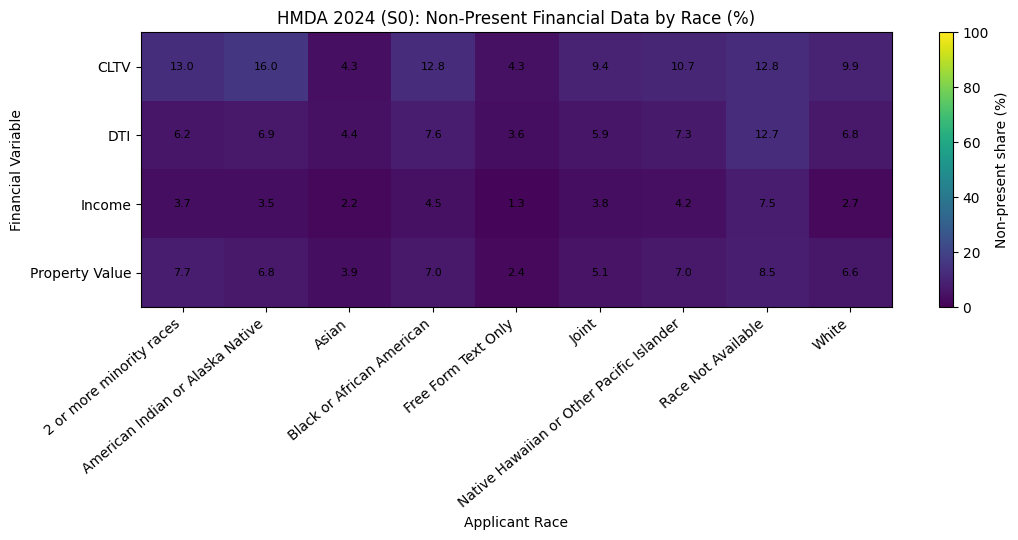

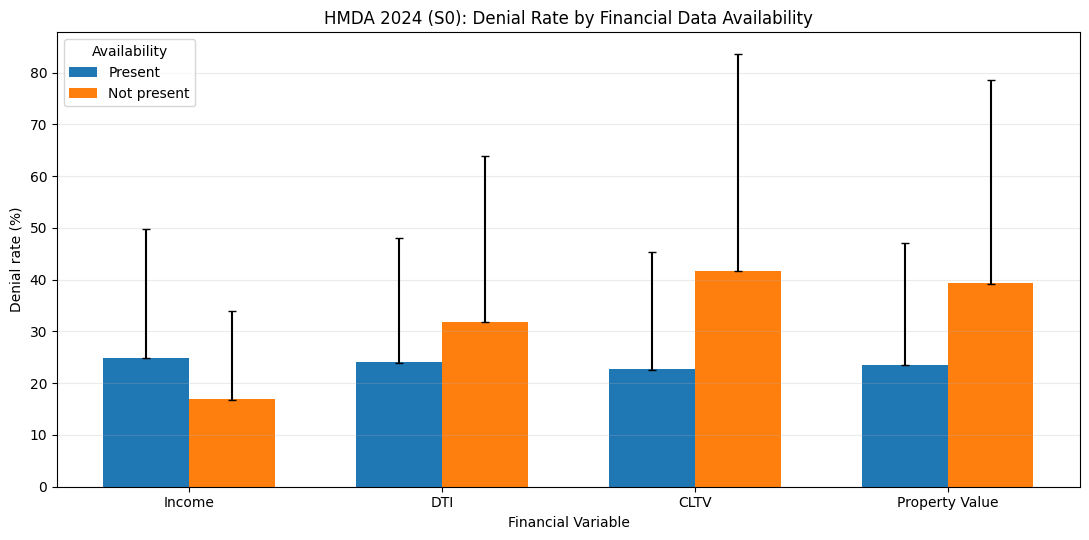

D6 validation passed.
Reference race: White
D-M: 1000 apps / 100 denials


,section,race,outcome,variable,availability_detail,availability_group,n_apps,n_total,share_pct
0,missingness_by_race_outcome,Joint,Not denied,Income,Present,Present,142521,148398,96.0397
1,missingness_by_race_outcome,Black or African American,Denied,Income,Present,Present,262035,269758,97.1371
2,missingness_by_race_outcome,White,Not denied,Income,Present,Present,4065945,4185494,97.1437
3,missingness_by_race_outcome,Race Not Available,Denied,Income,Present,Present,366896,378227,97.0042
4,missingness_by_race_outcome,Race Not Available,Not denied,Income,Present,Present,812354,897013,90.5621
5,missingness_by_race_outcome,American Indian or Alaska Native,Denied,Income,Present,Present,22201,22787,97.4284
6,missingness_by_race_outcome,American Indian or Alaska Native,Not denied,Income,Present,Present,37035,38610,95.9207
7,missingness_by_race_outcome,Native Hawaiian or Other Pacific Islander,Not denied,Income,NA,Not present,649,12375,5.2444
8,missingness_by_race_outcome,Black or African American,Not denied,Income,NA,Not present,25581,463345,5.5209
9,missingness_by_race_outcome,Asian,Not denied,Income,Present,Present,365778,374347,97.7109


,race,n_s0,n_fin_complete,retention_pct,denial_rate_s0_pct,denial_rate_fin_complete_pct,gap_s0_pp,gap_fin_complete_pp,gap_shift_pp,low_n_s0,low_n_fin_complete
0,Free Form Text Only,2098,1978,94.2800,58.3410,57.1280,NaN,NaN,NaN,False,False
1,White,5360624,4699459,87.6660,21.9220,19.6310,0.0000,0.0000,0.0000,False,False
2,American Indian or Alaska Native,61397,49896,81.2680,37.1140,32.8200,15.1930,13.1890,-2.0040,False,False
3,Native Hawaiian or Other Pacific Islander,20249,17351,85.6880,38.8860,36.3550,16.9640,16.7240,-0.2400,False,False
4,2 or more minority races,20920,17556,83.9200,38.1840,34.7740,16.2620,15.1430,-1.1190,False,False
5,Joint,184536,162116,87.8510,19.5830,17.0740,-2.3380,-2.5580,-0.2190,False,False
6,Black or African American,733103,615372,83.9410,36.7970,33.4030,14.8750,13.7720,-1.1030,False,False
7,Race Not Available,1275240,1027404,80.5660,29.6590,25.8670,NaN,NaN,NaN,False,False
8,Asian,478497,446231,93.2570,21.7660,20.6790,-0.1550,1.0470,1.2030,False,False


,section,driver_group,n_apps,n_fin_complete,n_denied,retention_pct,denial_rate_pct,driver_type
0,selection_drivers,Not fully exempt,7895556,7037363,1971955,89.1307,24.9755,Exempt status
1,selection_drivers,Fully exempt filer,241108,0,31321,0.0000,12.9904,Exempt status
2,selection_drivers,1,4038224,3504019,584281,86.7713,14.4688,Loan purpose
3,selection_drivers,2,984874,902196,366083,91.6052,37.1705,Loan purpose
4,selection_drivers,4,1115882,1010582,475513,90.5635,42.6132,Loan purpose
5,selection_drivers,5,986,728,629,73.8337,63.7931,Loan purpose
6,selection_drivers,31,882884,618618,205273,70.0679,23.2503,Loan purpose
7,selection_drivers,32,1113814,1001220,371497,89.8911,33.3536,Loan purpose


In [72]:

# ============================================================
# D6 — FINANCIAL MISSINGNESS AND SELECTION DIAGNOSTICS
# Source: Full S0 / B07_analytic.parquet
# Reference: B14 D6, B07 X11
# ============================================================

from pyspark.sql import functions as F
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# STEP 0. CONFIGURATION AND COLUMN RESOLUTION
# ------------------------------------------------------------

D6_SRC = df_s0
D6_COLS = set(D6_SRC.columns)

def d6_pick(candidates, required=True):
    for c in candidates:
        if c in D6_COLS:
            return c
    if required:
        raise ValueError(
            f"D6 cannot find any of these columns: {candidates}"
        )
    return None

RACE_COL = d6_pick(["derived_race", "race"])
DENIED_COL = d6_pick(["is_denied", "denied"])

INCOME_COL = d6_pick(["income", "income_num"])
DTI_COL = d6_pick(["dti_bin_fine", "dti_fine_cat"])
CLTV_COL = d6_pick([
    "combined_loan_to_value_ratio", "cltv_num"
])
PROPERTY_COL = d6_pick(["property_value", "property_value_num"])
LOAN_AMOUNT_COL = d6_pick(["loan_amount"])

PURPOSE_COL = d6_pick(
    ["loan_purpose_norm", "loan_purpose"],
    required=False
)

LENDER_COL = d6_pick(
    ["lei_hash", "lender_id", "lender_key", "lei", "lei_id"],
    required=False
)

REF_RACE_D6 = globals().get("REF_RACE", "White")
N_MIN_APPS_D6 = int(globals().get("N_MIN_APPS", 1000))
N_MIN_DENIED_D6 = int(globals().get("N_MIN_DENIED", 100))

D6_OUTPUT = Path(
    globals().get("OUTPUT_DIR", globals().get("output_dir", "output"))
)
D6_FIGURES = Path(
    globals().get(
        "FIGURE_DIR",
        globals().get("figure_dir", str(D6_OUTPUT / "figures"))
    )
)

D6_OUTPUT.mkdir(parents=True, exist_ok=True)
D6_FIGURES.mkdir(parents=True, exist_ok=True)

# S0 denominator: eligible applications only
if "action_taken" in D6_COLS:
    D6_SRC = D6_SRC.filter(
        F.col("action_taken").cast("string").isin("1", "2", "3")
    )

# ------------------------------------------------------------
# STEP 1. RECONSTRUCT EXACT FIN_COMPLETE (B07 X11)
# ------------------------------------------------------------

fin_complete_expr = (
    F.col(DTI_COL).isNotNull()
    & F.col(CLTV_COL).isNotNull()
    & F.col(INCOME_COL).isNotNull()
    & F.col(LOAN_AMOUNT_COL).isNotNull()
)

base = (
    D6_SRC
    .withColumn(
        "_race",
        F.coalesce(
            F.col(RACE_COL).cast("string"),
            F.lit("Unclassified")
        )
    )
    .withColumn(
        "_denied",
        F.when(
            F.lower(F.col(DENIED_COL).cast("string"))
            .isin("1", "1.0", "true"),
            1
        ).otherwise(0)
    )
    .withColumn("_fin_complete", fin_complete_expr)
    .withColumn(
        "_fin_i",
        F.when(fin_complete_expr, 1).otherwise(0)
    )
)

# Audit existing fin_complete if already available
if "fin_complete" in D6_COLS:
    mismatch = (
        D6_SRC
        .filter(
            F.coalesce(
                F.col("fin_complete").cast("int"),
                F.lit(0)
            ) != F.when(fin_complete_expr, 1).otherwise(0)
        )
        .limit(1)
        .count()
    )
    print("Existing fin_complete definition mismatch:", mismatch)

print("D6 S0 rows:", base.count())
print(
    "D6 fin_complete rows:",
    base.filter(F.col("_fin_complete")).count()
)

# ------------------------------------------------------------
# STEP 2. FINANCIAL AVAILABILITY STATUS
# ------------------------------------------------------------

VARIABLES = [
    ("Income", INCOME_COL, ["income_status"]),
    ("DTI", DTI_COL, ["dti_status"]),
    (
        "CLTV",
        CLTV_COL,
        ["combined_loan_to_value_ratio_status"]
    ),
    ("Property Value", PROPERTY_COL, ["property_value_status"])
]

def d6_status_expr(value_col, status_candidates):
    status_col = next(
        (c for c in status_candidates if c in D6_COLS),
        None
    )

    if status_col:
        status = F.lower(
            F.trim(F.col(status_col).cast("string"))
        )
    else:
        status = F.lit("unknown")

    return (
        F.when(F.col(value_col).isNotNull(), "Present")
        .when(status.isin("exempt", "1111"), "Exempt")
        .when(status.isin("na", "n/a", "na_code"), "NA")
        .when(status == "blank", "Blank")
        .otherwise("Missing/unknown")
    )

long_parts = []

for variable, value_col, status_candidates in VARIABLES:

    part = (
        base.select(
            F.col("_race").alias("race"),
            F.col("_denied").alias("denied"),
            F.lit(variable).alias("variable"),
            d6_status_expr(
                value_col,
                status_candidates
            ).alias("availability_detail")
        )
        .withColumn(
            "availability_group",
            F.when(
                F.col("availability_detail") == "Present",
                "Present"
            ).otherwise("Not present")
        )
        .withColumn(
            "outcome",
            F.when(F.col("denied") == 1, "Denied")
            .otherwise("Not denied")
        )
    )

    long_parts.append(part)

d6_long = long_parts[0]

for part in long_parts[1:]:
    d6_long = d6_long.unionByName(part)

# ------------------------------------------------------------
# STEP 3. MISSINGNESS BY RACE AND OUTCOME
# ------------------------------------------------------------

miss_counts = (
    d6_long
    .groupBy(
        "race", "outcome", "variable",
        "availability_detail", "availability_group"
    )
    .agg(F.count("*").alias("n_apps"))
)

miss_denominator = (
    d6_long
    .groupBy("race", "outcome", "variable")
    .agg(F.count("*").alias("n_total"))
)

miss_spark = (
    miss_counts
    .join(
        miss_denominator,
        ["race", "outcome", "variable"],
        "left"
    )
    .withColumn(
        "share_pct",
        F.col("n_apps") / F.col("n_total") * 100
    )
)

missing_pdf = miss_spark.toPandas()

# ------------------------------------------------------------
# STEP 4. DENIAL RATE BY FINANCIAL AVAILABILITY
# ------------------------------------------------------------

availability_spark = (
    d6_long
    .groupBy(
        "race", "variable",
        "availability_detail", "availability_group"
    )
    .agg(
        F.count("*").alias("n_apps"),
        F.sum("denied").alias("n_denied")
    )
)

availability_pdf = availability_spark.toPandas()

def d6_wilson(k, n, z=1.96):
    if n <= 0:
        return np.nan, np.nan

    p = k / n
    den = 1 + z**2 / n
    center = (p + z**2 / (2*n)) / den
    half = (
        z * np.sqrt(
            p*(1-p)/n + z**2/(4*n**2)
        ) / den
    )

    return (
        max(0, center-half)*100,
        min(1, center+half)*100
    )

def add_d6_ci(pdf):
    pdf = pdf.copy()

    pdf["denial_rate_pct"] = (
        pdf["n_denied"] / pdf["n_apps"] * 100
    )

    ci = [
        d6_wilson(int(k), int(n))
        for k, n in zip(pdf["n_denied"], pdf["n_apps"])
    ]

    pdf["ci_lower_pct"] = [x[0] for x in ci]
    pdf["ci_upper_pct"] = [x[1] for x in ci]

    pdf["low_n"] = (
        (pdf["n_apps"] < N_MIN_APPS_D6)
        | (pdf["n_denied"] < N_MIN_DENIED_D6)
    )

    return pdf

availability_pdf = add_d6_ci(availability_pdf)

# ------------------------------------------------------------
# STEP 5. S0 -> FIN_COMPLETE RETENTION AND GAP SHIFTS
# ------------------------------------------------------------

s0_rates = (
    base
    .groupBy("_race")
    .agg(
        F.count("*").alias("n_s0"),
        F.sum("_denied").alias("denied_s0")
    )
    .withColumn(
        "denial_rate_s0_pct",
        F.col("denied_s0") / F.col("n_s0") * 100
    )
)

fin_rates = (
    base
    .filter(F.col("_fin_complete"))
    .groupBy("_race")
    .agg(
        F.count("*").alias("n_fin_complete"),
        F.sum("_denied").alias("denied_fin_complete")
    )
    .withColumn(
        "denial_rate_fin_complete_pct",
        F.col("denied_fin_complete")
        / F.col("n_fin_complete") * 100
    )
)

retention_spark = (
    s0_rates
    .join(fin_rates, "_race", "left")
    .fillna({
        "n_fin_complete": 0,
        "denied_fin_complete": 0
    })
)

retention_spark = retention_spark.withColumn(
    "retention_pct",
    F.col("n_fin_complete") / F.col("n_s0") * 100
)

# Obtain White reference rates
white = (
    retention_spark
    .filter(F.col("_race") == REF_RACE_D6)
    .select(
        F.col("denial_rate_s0_pct").alias("white_s0_rate"),
        F.col("denial_rate_fin_complete_pct").alias(
            "white_fin_rate"
        ),
        F.col("n_s0").alias("white_n_s0"),
        F.col("denied_s0").alias("white_denied_s0"),
        F.col("n_fin_complete").alias("white_n_fin"),
        F.col("denied_fin_complete").alias("white_denied_fin")
    )
)

if white.count() != 1:
    raise ValueError(
        f"Reference group {REF_RACE_D6} not found exactly once."
    )

retention_spark = retention_spark.crossJoin(white)

retention_pdf = retention_spark.toPandas()

# Exclude Race Not Available and Free Form Text Only
# from headline gap comparisons, but retain their profiles.
excluded_gap_groups = {
    "Race Not Available",
    "Free Form Text Only"
}

retention_pdf["race"] = retention_pdf["_race"]

retention_pdf["low_n_s0"] = (
    (retention_pdf["n_s0"] < N_MIN_APPS_D6)
    | (retention_pdf["denied_s0"] < N_MIN_DENIED_D6)
    | (retention_pdf["white_n_s0"] < N_MIN_APPS_D6)
    | (retention_pdf["white_denied_s0"] < N_MIN_DENIED_D6)
)

retention_pdf["low_n_fin_complete"] = (
    (retention_pdf["n_fin_complete"] < N_MIN_APPS_D6)
    | (retention_pdf["denied_fin_complete"] < N_MIN_DENIED_D6)
    | (retention_pdf["white_n_fin"] < N_MIN_APPS_D6)
    | (retention_pdf["white_denied_fin"] < N_MIN_DENIED_D6)
)

retention_pdf["is_headline_gap_group"] = (
    ~retention_pdf["race"].isin(excluded_gap_groups)
)

retention_pdf["gap_s0_pp"] = np.where(
    retention_pdf["is_headline_gap_group"]
    & ~retention_pdf["low_n_s0"],
    retention_pdf["denial_rate_s0_pct"]
    - retention_pdf["white_s0_rate"],
    np.nan
)

retention_pdf["gap_fin_complete_pp"] = np.where(
    retention_pdf["is_headline_gap_group"]
    & ~retention_pdf["low_n_fin_complete"],
    retention_pdf["denial_rate_fin_complete_pct"]
    - retention_pdf["white_fin_rate"],
    np.nan
)

retention_pdf["gap_shift_pp"] = (
    retention_pdf["gap_fin_complete_pp"]
    - retention_pdf["gap_s0_pp"]
)

# ------------------------------------------------------------
# STEP 6. SELECTION DRIVERS
# Exempt filer, loan purpose, lender
# ------------------------------------------------------------

if "is_exempt_filer" in D6_COLS:
    exempt_expr = F.when(
        F.col("is_exempt_filer").cast("boolean"),
        "Fully exempt filer"
    ).otherwise("Not fully exempt")

elif "n_exempt_28" in D6_COLS:
    exempt_expr = F.when(
        F.col("n_exempt_28") == 28,
        "Fully exempt filer"
    ).otherwise("Not fully exempt")

else:
    exempt_expr = F.lit("Unavailable")

base = base.withColumn("_exempt_group", exempt_expr)

def d6_driver_summary(data, dimension, label):
    return (
        data
        .groupBy(dimension)
        .agg(
            F.count("*").alias("n_apps"),
            F.sum("_fin_i").alias("n_fin_complete"),
            F.sum("_denied").alias("n_denied"),
            F.avg("_fin_i").alias("fin_complete_share"),
            F.avg("_denied").alias("denial_rate")
        )
        .withColumn(
            "retention_pct",
            F.col("fin_complete_share") * 100
        )
        .withColumn(
            "denial_rate_pct",
            F.col("denial_rate") * 100
        )
        .withColumn("driver_type", F.lit(label))
        .withColumnRenamed(dimension, "driver_group")
        .drop("fin_complete_share", "denial_rate")
    )

driver_tables = [
    d6_driver_summary(
        base, "_exempt_group", "Exempt status"
    )
]

if PURPOSE_COL:
    base = base.withColumn(
        "_purpose_group",
        F.coalesce(
            F.col(PURPOSE_COL).cast("string"),
            F.lit("Missing/unknown")
        )
    )

    driver_tables.append(
        d6_driver_summary(
            base, "_purpose_group", "Loan purpose"
        )
    )

drivers_pdf = pd.concat(
    [x.toPandas() for x in driver_tables],
    ignore_index=True
)

# Lender-level financial completeness
lender_pdf = pd.DataFrame()

if LENDER_COL:
    lender_spark = (
        base
        .withColumn(
            "_lender",
            F.coalesce(
                F.col(LENDER_COL).cast("string"),
                F.lit("Missing LEI")
            )
        )
        .groupBy("_lender")
        .agg(
            F.count("*").alias("n_apps"),
            F.sum("_fin_i").alias("n_fin_complete"),
            F.sum("_denied").alias("n_denied"),
            F.avg("_fin_i").alias("retention_pct_raw"),
            F.avg("_denied").alias("denial_rate_raw")
        )
        .withColumn(
            "retention_pct",
            F.col("retention_pct_raw") * 100
        )
        .withColumn(
            "denial_rate_pct",
            F.col("denial_rate_raw") * 100
        )
        .withColumn(
            "low_n",
            (F.col("n_apps") < N_MIN_APPS_D6)
            | (F.col("n_denied") < N_MIN_DENIED_D6)
        )
        .drop("retention_pct_raw", "denial_rate_raw")
        .withColumnRenamed("_lender", "lender_id")
    )

    lender_pdf = lender_spark.toPandas()

# ------------------------------------------------------------
# STEP 7. EXPORT TABLES
# ------------------------------------------------------------

missing_pdf.insert(0, "section", "missingness_by_race_outcome")
availability_pdf.insert(0, "section", "denial_by_availability")
retention_pdf.insert(0, "section", "retention_and_gap_shift")
drivers_pdf.insert(0, "section", "selection_drivers")

D6_ALL = pd.concat(
    [
        missing_pdf,
        availability_pdf,
        retention_pdf,
        drivers_pdf
    ],
    ignore_index=True,
    sort=False
)

main_path = D6_OUTPUT / "B15_rq2_missingness_selection.csv"
D6_ALL.to_csv(main_path, index=False, encoding="utf-8-sig")

if not lender_pdf.empty:
    lender_path = (
        D6_OUTPUT / "B15_rq2_lender_financial_completeness.csv"
    )
    lender_pdf.to_csv(
        lender_path,
        index=False,
        encoding="utf-8-sig"
    )

print("Saved:", main_path)
print("Main D6 shape:", D6_ALL.shape)

# ------------------------------------------------------------
# STEP 8. FIGURE 20 — MISSINGNESS BY RACE
# ------------------------------------------------------------

plot_miss = missing_pdf.copy()

total_by_race = (
    plot_miss.groupby(["race", "variable"])["n_apps"]
    .sum()
)

not_present = (
    plot_miss[
        plot_miss["availability_group"] != "Present"
    ]
    .groupby(["race", "variable"])["n_apps"]
    .sum()
)

missing_rate = (
    not_present / total_by_race * 100
).reset_index(name="not_present_pct")

heat = missing_rate.pivot(
    index="variable",
    columns="race",
    values="not_present_pct"
)

fig, ax = plt.subplots(
    figsize=(max(11, len(heat.columns)*1.1), 5.5)
)

im = ax.imshow(
    heat.values,
    aspect="auto",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels(
    heat.columns, rotation=40, ha="right"
)

ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)

for i in range(len(heat.index)):
    for j in range(len(heat.columns)):
        value = heat.iloc[i, j]
        if pd.notna(value):
            ax.text(
                j, i, f"{value:.1f}",
                ha="center", va="center", fontsize=8
            )

ax.set_title(
    "HMDA 2024 (S0): Non-Present Financial Data by Race (%)"
)

ax.set_xlabel("Applicant Race")
ax.set_ylabel("Financial Variable")

fig.colorbar(
    im, ax=ax, label="Non-present share (%)"
)

plt.tight_layout()

fig.savefig(
    D6_FIGURES / "B15_fig_20_missingness_by_race.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# STEP 9. FIGURE 21 — DENIAL RATE BY AVAILABILITY
# ------------------------------------------------------------

overall_availability = (
    d6_long
    .groupBy("variable", "availability_group")
    .agg(
        F.count("*").alias("n_apps"),
        F.sum("denied").alias("n_denied")
    )
    .toPandas()
)

overall_availability = add_d6_ci(overall_availability)

variables_order = [
    "Income", "DTI", "CLTV", "Property Value"
]

fig, ax = plt.subplots(figsize=(11, 5.5))

x = np.arange(len(variables_order))
width = 0.34

for i, group in enumerate(["Present", "Not present"]):

    sub = (
        overall_availability[
            overall_availability["availability_group"] == group
        ]
        .set_index("variable")
        .reindex(variables_order)
    )

    vals = sub["denial_rate_pct"].to_numpy()
    lower = vals - sub["ci_lower_pct"].to_numpy()
    upper = sub["ci_upper_pct"].to_numpy()

    ax.bar(
        x + (i-0.5)*width,
        vals,
        width,
        label=group,
        yerr=np.vstack([lower, upper]),
        capsize=3
    )

ax.set_xticks(x)
ax.set_xticklabels(variables_order)

ax.set_ylabel("Denial rate (%)")
ax.set_xlabel("Financial Variable")

ax.set_title(
    "HMDA 2024 (S0): Denial Rate by Financial Data Availability"
)

ax.legend(title="Availability")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

fig.savefig(
    D6_FIGURES / "B15_fig_21_missingness_denial_rate.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# STEP 10. VALIDATION AND OUTPUT PREVIEW
# ------------------------------------------------------------

# Missingness shares should sum to 100% within each
# race x outcome x variable combination.
share_check = (
    missing_pdf
    .groupby(["race", "outcome", "variable"])["share_pct"]
    .sum()
)

assert np.allclose(
    share_check.values, 100, atol=0.05
), "D6 missingness shares do not sum to 100%."

assert (
    retention_pdf["n_fin_complete"]
    <= retention_pdf["n_s0"]
).all(), "fin_complete cannot exceed S0."

assert retention_pdf["retention_pct"].between(
    0, 100
).all(), "Invalid retention percentage."

print("D6 validation passed.")
print("Reference race:", REF_RACE_D6)
print("D-M:", N_MIN_APPS_D6, "apps /", N_MIN_DENIED_D6, "denials")

display(
    missing_pdf.head(12)
)

display(
    retention_pdf[
        [
            "race",
            "n_s0",
            "n_fin_complete",
            "retention_pct",
            "denial_rate_s0_pct",
            "denial_rate_fin_complete_pct",
            "gap_s0_pp",
            "gap_fin_complete_pp",
            "gap_shift_pp",
            "low_n_s0",
            "low_n_fin_complete"
        ]
    ].round(3)
)

display(drivers_pdf)


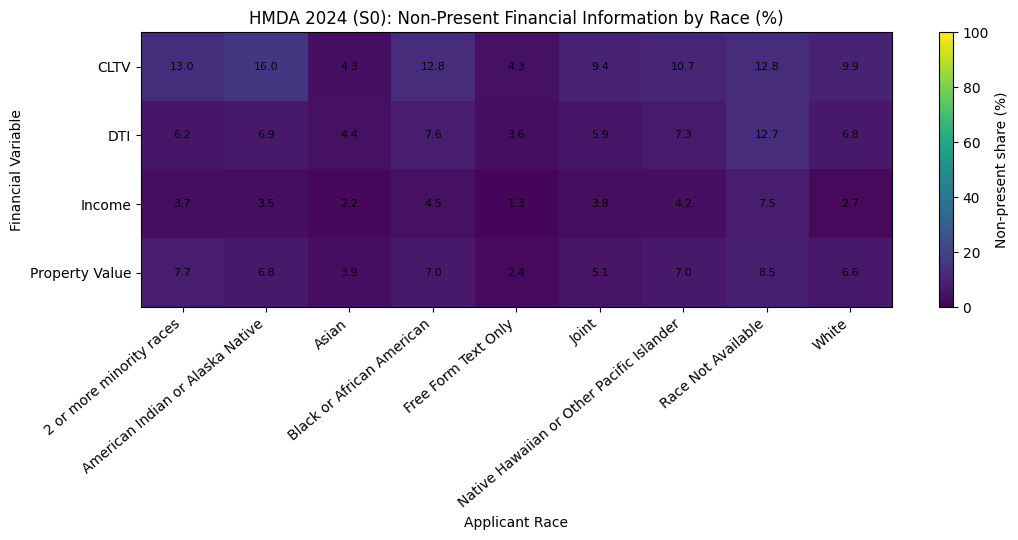

D6 Step 10 completed.


,race,variable,n_total,n_missing,missing_share
4,American Indian or Alaska Native,CLTV,61397,9818,15.9910
0,2 or more minority races,CLTV,20920,2723,13.0163
12,Black or African American,CLTV,733103,93840,12.8004
28,Race Not Available,CLTV,1275240,163035,12.7847
24,Native Hawaiian or Other Pacific Islander,CLTV,20249,2161,10.6721
32,White,CLTV,5360624,529722,9.8817
20,Joint,CLTV,184536,17395,9.4263
16,Free Form Text Only,CLTV,2098,91,4.3375
8,Asian,CLTV,478497,20476,4.2792
29,Race Not Available,DTI,1275240,161790,12.6870


In [73]:

# ============================================================
# D6 — STEP 10. MISSINGNESS BY RACE
# ============================================================

# Step 1: Aggregate availability counts across outcomes

availability_counts = (
    missing_pdf
    .groupby(
        ["race", "variable", "availability_group"],
        as_index=False
    )["n_apps"]
    .sum()
)

# Step 2: Calculate total applications and non-present records

total_counts = (
    availability_counts
    .groupby(["race", "variable"], as_index=False)
    .agg(n_total=("n_apps", "sum"))
)

missing_counts = (
    availability_counts[
        availability_counts["availability_group"] != "Present"
    ]
    .groupby(["race", "variable"], as_index=False)
    .agg(n_missing=("n_apps", "sum"))
)

missing_summary = total_counts.merge(
    missing_counts,
    on=["race", "variable"],
    how="left"
)

missing_summary["n_missing"] = (
    missing_summary["n_missing"].fillna(0)
)

missing_summary["missing_share"] = (
    missing_summary["n_missing"]
    / missing_summary["n_total"] * 100
)

# Step 3: Pivot for visualization

missing_plot = missing_summary.pivot(
    index="variable",
    columns="race",
    values="missing_share"
)

# Step 4: Plot

fig, ax = plt.subplots(
    figsize=(max(11, len(missing_plot.columns) * 1.1), 5.5)
)

im = ax.imshow(
    missing_plot.values,
    aspect="auto",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(missing_plot.columns)))
ax.set_xticklabels(
    missing_plot.columns,
    rotation=40,
    ha="right"
)

ax.set_yticks(range(len(missing_plot.index)))
ax.set_yticklabels(missing_plot.index)

for i in range(len(missing_plot.index)):
    for j in range(len(missing_plot.columns)):
        value = missing_plot.iloc[i, j]

        if pd.notna(value):
            ax.text(
                j, i,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=8
            )

ax.set_title(
    "HMDA 2024 (S0): Non-Present Financial Information by Race (%)"
)

ax.set_xlabel("Applicant Race")
ax.set_ylabel("Financial Variable")

fig.colorbar(
    im,
    ax=ax,
    label="Non-present share (%)"
)

plt.tight_layout()

fig.savefig(
    os.path.join(
        str(D6_FIGURES),
        "B15_fig_20_missingness_by_race.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Step 5: Validation

assert missing_summary["missing_share"].between(
    0, 100
).all()

print("D6 Step 10 completed.")
display(
    missing_summary.sort_values(
        ["variable", "missing_share"],
        ascending=[True, False]
    )
)


## D7. Denial Reasons

### Objective
Describe the distribution of reported mortgage denial reasons
across racial groups and examine the relationship between
financial characteristics and reported DTI or collateral reasons.

### Input
- Denied applications only.
- denial_reason_1 through denial_reason_4.
- Race.
- DTI fine category.
- CLTV category.
- Income decile.

### Process
1. Reshape the four denial-reason columns into a long-format table.
2. Calculate reason-code counts and shares by race.
3. Preserve the original reason-code values.
4. Examine DTI and Collateral reason codes across financial strata.
5. Visualize the distribution of denial reasons by race.

### Output
- B15_rq2_denial_reasons.csv
- B15_fig_22_denial_reasons.png

### Method Notes
Denial reasons are descriptive variables only and must never
be used as predictors in denial models.

Special codes 10 and 1111 are preserved in their original form.
Their final interpretation must follow the approved T06/T10
data-cleaning rules.

Code 1 represents DTI-related reasons and code 4 represents
collateral-related reasons.

In [74]:

# ============================================================
# D7. DENIAL REASONS
# ============================================================

# ------------------------------------------------------------
# Step 1: Validate denial-reason columns
# ------------------------------------------------------------

REASON_COLS = [
    "denial_reason_1",
    "denial_reason_2",
    "denial_reason_3",
    "denial_reason_4"
]

missing_reason_cols = [
    c for c in REASON_COLS
    if c not in df_d.columns
]

if missing_reason_cols:
    raise ValueError(
        f"D7 requires missing columns: {missing_reason_cols}"
    )

# ------------------------------------------------------------
# Step 2: Filter denied applications
# ------------------------------------------------------------

df_d7_denied = df_d.filter(
    F.col("denied") == 1
)

# Use a stable application identifier when available.
application_id_col = (
    "row_id"
    if "row_id" in df_d.columns
    else None
)

if application_id_col:
    application_id_expr = F.col(application_id_col)
    application_count_method = "Distinct row_id"
else:
    application_id_expr = None
    application_count_method = "Reason mentions; no row_id available"



In [75]:
# ------------------------------------------------------------
# Step 3: Reshape four reason columns into long format
# ------------------------------------------------------------

reason_array = F.array(*[
    F.struct(
        F.lit(i + 1).alias("reason_slot"),
        F.trim(
            F.col(c).cast("string")
        ).alias("reason_code")
    )
    for i, c in enumerate(REASON_COLS)
])

d7_long = (
    df_d7_denied
    .select(
        "race",
        "dti_fine",
        "cltv_bin",
        "income_decile",
        *(
            [application_id_expr.alias("application_id")]
            if application_id_expr is not None
            else []
        ),
        F.explode(reason_array).alias("reason")
    )
    .select(
        "race",
        "dti_fine",
        "cltv_bin",
        "income_decile",
        *(
            ["application_id"]
            if application_id_expr is not None
            else []
        ),
        F.col("reason.reason_slot").alias("reason_slot"),
        F.col("reason.reason_code").alias("reason_code")
    )
    .filter(
        F.col("reason_code").isNotNull()
        & (~F.lower(F.col("reason_code")).isin(
            "",
            "null",
            "none",
            "nan"
        ))
    )
)


In [76]:

# ------------------------------------------------------------
# Step 4: Map descriptive reason labels
# ------------------------------------------------------------

d7_long = d7_long.withColumn(
    "reason_label",
    F.when(
        F.col("reason_code") == "1",
        "DTI"
    )
    .when(
        F.col("reason_code") == "4",
        "Collateral"
    )
    .when(
        F.col("reason_code").isin("10", "1111"),
        "Special code - T06/T10 review"
    )
    .otherwise("Other / raw reason code")
)

# ------------------------------------------------------------
# Step 5: Aggregate reason distribution by race
# ------------------------------------------------------------

distribution_group_cols = [
    "race",
    "reason_slot",
    "reason_code",
    "reason_label"
]

d7_distribution = (
    d7_long
    .groupBy(*distribution_group_cols)
    .agg(
        F.count("*").alias("n_reason_mentions"),
        *(
            [
                F.countDistinct("application_id").alias(
                    "n_applications"
                )
            ]
            if application_id_col
            else [
                F.count("*").alias("n_applications")
            ]
        )
    )
)

race_window = Window.partitionBy("race")

d7_distribution = (
    d7_distribution
    .withColumn(
        "total_reason_mentions",
        F.sum("n_reason_mentions").over(race_window)
    )
    .withColumn(
        "share_within_race",
        F.col("n_reason_mentions")
        / F.col("total_reason_mentions")
    )
    .withColumn(
        "record_type",
        F.lit("reason_distribution")
    )
    .withColumn(
        "application_count_method",
        F.lit(application_count_method)
    )
)


In [77]:

# ------------------------------------------------------------
# Step 6: Examine DTI and collateral reasons by financial strata
# ------------------------------------------------------------

d7_financial = (
    d7_long
    .filter(
        F.col("reason_code").isin("1", "4")
    )
    .filter(F.col("income_decile") != "Missing")
    .filter(F.col("cltv_bin") != "Missing")
    .filter(F.col("dti_fine").rlike("[0-9]"))
)

strata_group_cols = [
    "race",
    "dti_fine",
    "cltv_bin",
    "income_decile",
    "reason_code",
    "reason_label"
]

d7_strata = (
    d7_financial
    .groupBy(*strata_group_cols)
    .agg(
        F.count("*").alias("n_reason_mentions"),
        *(
            [
                F.countDistinct("application_id").alias(
                    "n_applications"
                )
            ]
            if application_id_col
            else [
                F.count("*").alias("n_applications")
            ]
        )
    )
)

strata_window = Window.partitionBy(
    "race",
    "dti_fine",
    "cltv_bin",
    "income_decile"
)

d7_strata = (
    d7_strata
    .withColumn(
        "total_reason_mentions",
        F.sum("n_reason_mentions").over(strata_window)
    )
    .withColumn(
        "share_within_financial_stratum",
        F.col("n_reason_mentions")
        / F.col("total_reason_mentions")
    )
    .withColumn(
        "record_type",
        F.lit("financial_strata")
    )
    .withColumn(
        "application_count_method",
        F.lit(application_count_method)
    )
)


In [78]:

# ------------------------------------------------------------
# Step 7: Export D7 tables
# ------------------------------------------------------------

d7_distribution_pd = d7_distribution.toPandas()
d7_strata_pd = d7_strata.toPandas()

d7_pd = pd.concat(
    [
        d7_distribution_pd,
        d7_strata_pd
    ],
    ignore_index=True,
    sort=False
)

d7_path = os.path.join(
    output_dir,
    "B15_rq2_denial_reasons.csv"
)

d7_pd.to_csv(d7_path, index=False)



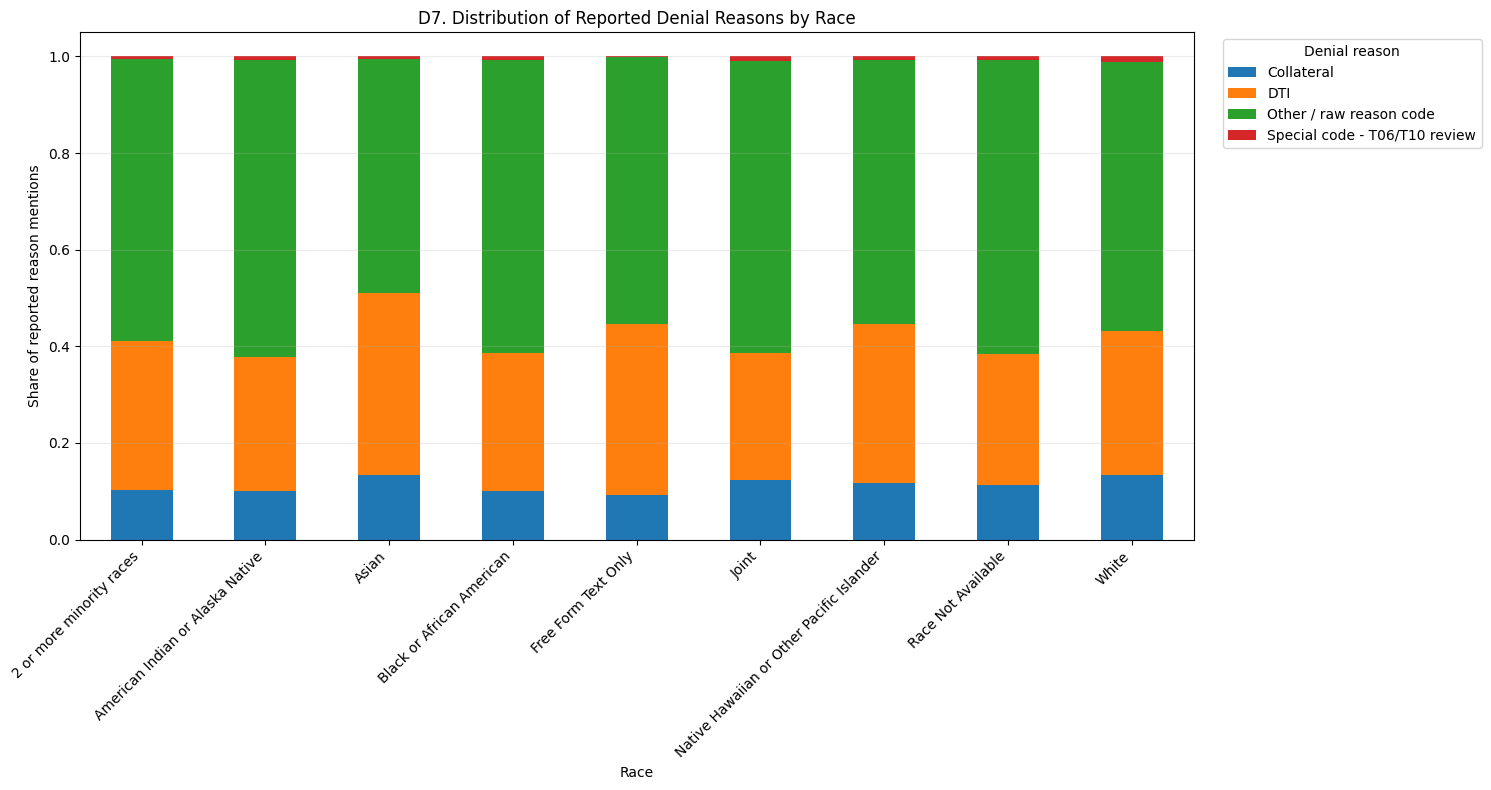

D7 completed.
Output: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq2_denial_reasons.csv
Denied applications: 2,003,276
Reason mentions: 310
Application count method: Distinct row_id
Special codes 10 and 1111 have been preserved without unsupported recoding.


In [79]:

# ------------------------------------------------------------
# Step 8: Visualize denial-reason distribution by race
# ------------------------------------------------------------

plot_data = (
    d7_distribution_pd
    .groupby(
        ["race", "reason_code", "reason_label"],
        as_index=False
    )
    .agg(
        n_reason_mentions=("n_reason_mentions", "sum")
    )
)

plot_data["share"] = (
    plot_data["n_reason_mentions"]
    / plot_data.groupby("race")[
        "n_reason_mentions"
    ].transform("sum")
)

plot_pivot = plot_data.pivot_table(
    index="race",
    columns="reason_label",
    values="share",
    aggfunc="sum",
    fill_value=0
)

if not plot_pivot.empty:

    ax = plot_pivot.plot(
        kind="bar",
        stacked=True,
        figsize=(15, 8)
    )

    ax.set_title(
        "D7. Distribution of Reported Denial Reasons by Race"
    )
    ax.set_xlabel("Race")
    ax.set_ylabel("Share of reported reason mentions")
    ax.legend(
        title="Denial reason",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    ax.grid(axis="y", alpha=0.25)

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            figure_dir,
            "B15_fig_22_denial_reasons.png"
        ),
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ------------------------------------------------------------
# Step 9: Validation
# ------------------------------------------------------------

print("D7 completed.")
print(f"Output: {d7_path}")
print(f"Denied applications: {df_d7_denied.count():,}")
print(f"Reason mentions: {len(d7_distribution_pd):,}")
print(f"Application count method: {application_count_method}")

print(
    "Special codes 10 and 1111 have been preserved "
    "without unsupported recoding."
)

## D8. Pricing Among Originated Loans

### Objective
Describe differences in mortgage pricing across racial groups
and loan types among originated applications.

### Input
- Originated applications only (action_taken = 1).
- Race.
- Loan type.
- Interest rate.
- Rate spread.
- Total loan costs.

### Process
1. Restrict the sample to originated loans.
2. Aggregate observations by race × loan_type.
3. Calculate the number of originated applications.
4. Calculate non-missing counts, Q1, median, and Q3
   for each pricing variable.
5. Export the results in long format for comparison.

### Output
- B15_rq2_pricing_by_race.csv

### Method Notes
Pricing variables are conditional on origination and are
not available for denied applications in the same way.

The results describe pricing among originated loans only.
They must not be interpreted as pricing differences
for the entire applicant population.

In [80]:

# ============================================================
# D8. PRICING AMONG ORIGINATED LOANS
# ============================================================

# ------------------------------------------------------------
# Step 1: Validate pricing variables
# ------------------------------------------------------------

PRICING_VARS = [
    "interest_rate",
    "rate_spread",
    "total_loan_costs"
]

required_d8_cols = [
    "action_taken",
    "derived_race",
    "loan_type"
] + PRICING_VARS

missing_d8_cols = [
    c for c in required_d8_cols
    if c not in df_s0.columns
]

if missing_d8_cols:
    raise ValueError(
        f"D8 requires missing columns: {missing_d8_cols}"
    )

# ------------------------------------------------------------
# Step 2: Restrict the sample to originated applications
# ------------------------------------------------------------

df_d8 = (
    df_s0
    .filter(
        F.col("action_taken").cast("int") == 1
    )
    .withColumn(
        "race",
        F.coalesce(
            F.col("derived_race").cast("string"),
            F.lit("Race Missing")
        )
    )
    .withColumn(
        "loan_type",
        F.coalesce(
            F.col("loan_type").cast("string"),
            F.lit("Missing")
        )
    )
)


In [81]:

# ------------------------------------------------------------
# Step 3: Convert pricing variables to numeric
# ------------------------------------------------------------

for variable in PRICING_VARS:

    df_d8 = df_d8.withColumn(
        f"{variable}_num",
        F.col(variable).cast("double")
    )

# ------------------------------------------------------------
# Step 4: Aggregate pricing statistics by race × loan type
# ------------------------------------------------------------

aggregation_exprs = [
    F.count("*").alias("n_originated")
]

for variable in PRICING_VARS:

    numeric_col = F.col(f"{variable}_num")

    aggregation_exprs.extend([
        F.count(numeric_col).alias(
            f"n_{variable}"
        ),
        F.percentile_approx(
            numeric_col,
            [0.25, 0.50, 0.75],
            10000
        ).alias(
            f"q_{variable}"
        )
    ])

d8_summary = (
    df_d8
    .groupBy("race", "loan_type")
    .agg(*aggregation_exprs)
)

# ------------------------------------------------------------
# Step 5: Convert wide summary into long-format records
# ------------------------------------------------------------

d8_frames = []

for variable in PRICING_VARS:

    d8_frames.append(
        d8_summary.select(
            "race",
            "loan_type",
            "n_originated",
            F.lit(variable).alias("pricing_variable"),
            F.col(f"n_{variable}").alias("n_nonmissing"),
            F.col(f"q_{variable}").getItem(0).alias("q1"),
            F.col(f"q_{variable}").getItem(1).alias("median"),
            F.col(f"q_{variable}").getItem(2).alias("q3")
        )
    )

d8_output = d8_frames[0]

for frame in d8_frames[1:]:
    d8_output = d8_output.unionByName(frame)


In [82]:

# ------------------------------------------------------------
# Step 6: Export D8
# ------------------------------------------------------------

d8_path = os.path.join(
    output_dir,
    "B15_rq2_pricing_by_race.csv"
)

d8_pd = d8_output.orderBy(
    "race",
    "loan_type",
    "pricing_variable"
).toPandas()

d8_pd.to_csv(d8_path, index=False)

# ------------------------------------------------------------
# Step 7: Validate sample and pricing coverage
# ------------------------------------------------------------

originated_n = df_d8.count()

print("D8 completed.")
print(f"Output: {d8_path}")
print(f"Originated applications: {originated_n:,}")

display(
    d8_pd.sort_values(
        ["pricing_variable", "race", "loan_type"]
    )
)


D8 completed.
Output: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq2_pricing_by_race.csv
Originated applications: 5,793,597


,race,loan_type,n_originated,pricing_variable,n_nonmissing,q1,median,q3
0,2 or more minority races,1,7711,interest_rate,7600,6.3750,6.9900,8.2500
3,2 or more minority races,2,2272,interest_rate,2270,5.6250,6.2500,6.7500
6,2 or more minority races,3,2050,interest_rate,2050,5.6000,6.1250,6.6250
9,2 or more minority races,4,60,interest_rate,49,5.9900,6.3750,6.7500
12,American Indian or Alaska Native,1,23008,interest_rate,22132,6.5000,7.1250,8.7400
...,...,...,...,...,...,...,...,...
95,Race Not Available,4,2843,total_loan_costs,2474,"4,524.4400","6,389.6800","8,571.4000"
98,White,1,3145910,total_loan_costs,2100855,"2,720.3500","4,657.6000","7,324.2500"
101,White,2,503235,total_loan_costs,491118,"8,365.3100","11,124.7500","15,001.3000"
104,White,3,295691,total_loan_costs,293502,"3,692.5500","6,808.2300","11,690.4000"


### E1. Numeric–Numeric Relationships

**Objective:** Examine relationships between key numerical variables and identify potential nonlinear patterns and heaping in the HMDA application data.

**Input:** The predefined diagnostic sample (`df_samp`).

**Process:**
- Examine loan amount versus applicant income.
- Examine loan amount versus property value.
- Examine CLTV versus `ltv_calc`.
- Examine originated-loan interest rate versus CLTV and loan term.
- Calculate Spearman rank correlations using average ranks, including tied observations.
- Generate hexbin diagnostics using appropriate log transformations.

**Output:**
- `B15_rel_spearman.csv`
- `B15_fig_23_hexbin.png`

**Method Notes:** Spearman correlation is calculated from average ranks rather than raw Pearson correlations. Interest-rate relationships are restricted to originated loans (`action_taken = 1`). All diagnostics use the predefined B14-compatible sample.

In [83]:
# ============================================================
# E1. NUMERIC-NUMERIC RELATIONSHIPS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F
from pyspark.sql.window import Window

# ------------------------------------------------------------
# Step 1: Initialize output paths
# ------------------------------------------------------------

os.makedirs(os.fspath(OUTPUT_DIR), exist_ok=True)
os.makedirs(os.fspath(FIGURE_DIR), exist_ok=True)

# ------------------------------------------------------------
# Step 2: Define analytical variable pairs
# ------------------------------------------------------------

E1_PAIRS = [
    ("loan_amount", "income", "Loan Amount vs Income"),
    ("loan_amount", "property_value", "Loan Amount vs Property Value"),
    (
        "combined_loan_to_value_ratio",
        "ltv_calc",
        "CLTV vs LTV"
    ),
    (
        "interest_rate",
        "combined_loan_to_value_ratio",
        "Interest Rate vs CLTV"
    ),
    (
        "interest_rate",
        "loan_term",
        "Interest Rate vs Loan Term"
    )
]

E1_REQUIRED = list(dict.fromkeys(
    [c for x, y, _ in E1_PAIRS for c in (x, y)]
    + ["action_taken"]
))

missing = [
    c for c in E1_REQUIRED
    if c not in df_samp.columns
]

assert not missing, f"E1 missing columns: {missing}"


In [84]:

# ------------------------------------------------------------
# Step 3: Calculate Spearman correlation using PySpark
# ------------------------------------------------------------

e1_results = []

for x, y, label in E1_PAIRS:

    base = df_samp.select(
        F.col(x).cast("double").alias("__x"),
        F.col(y).cast("double").alias("__y"),
        F.col("action_taken").cast("double").alias("__action")
    )

    # Originated loans only for interest-rate relationships
    if x == "interest_rate":
        base = base.filter(F.col("__action") == 1)

    # Remove NULL, NaN and infinite values
    for c in ["__x", "__y"]:
        base = base.filter(
            F.col(c).isNotNull()
            & (~F.isnan(F.col(c)))
            & (F.abs(F.col(c)) < float("inf"))
        )

    # Average ranks including tied observations
    wx_rank = Window.orderBy(F.col("__x").asc())
    wx_ties = Window.partitionBy("__x")

    wy_rank = Window.orderBy(F.col("__y").asc())
    wy_ties = Window.partitionBy("__y")

    ranked = (
        base
        .withColumn("__rank_x", F.rank().over(wx_rank))
        .withColumn("__ties_x", F.count("*").over(wx_ties))
        .withColumn(
            "__avg_rank_x",
            F.col("__rank_x") + (F.col("__ties_x") - 1) / 2
        )
        .withColumn("__rank_y", F.rank().over(wy_rank))
        .withColumn("__ties_y", F.count("*").over(wy_ties))
        .withColumn(
            "__avg_rank_y",
            F.col("__rank_y") + (F.col("__ties_y") - 1) / 2
        )
    )

    result = ranked.agg(
        F.count("*").alias("sample_n"),
        F.corr(
            "__avg_rank_x",
            "__avg_rank_y"
        ).alias("spearman_rho")
    ).first()

    e1_results.append({
        "relationship": label,
        "variable_x": x,
        "variable_y": y,
        "sample_n": result["sample_n"],
        "spearman_rho": result["spearman_rho"]
    })


In [85]:

# ------------------------------------------------------------
# Step 4: Export Spearman results
# ------------------------------------------------------------

e1_corr_pdf = pd.DataFrame(e1_results)

e1_output = os.path.join(
    os.fspath(OUTPUT_DIR),
    "B15_rel_spearman.csv"
)

e1_corr_pdf.to_csv(e1_output, index=False)

print("E1 Spearman correlation results:")
display(e1_corr_pdf)

# ------------------------------------------------------------
# Step 5: Prepare visualization sample
# ------------------------------------------------------------

e1_plot_pdf = (
    df_samp
    .select(*E1_REQUIRED)
    .toPandas()
)

for c in E1_REQUIRED:
    e1_plot_pdf[c] = pd.to_numeric(
        e1_plot_pdf[c],
        errors="coerce"
    )


E1 Spearman correlation results:


,relationship,variable_x,variable_y,sample_n,spearman_rho
0,Loan Amount vs Income,loan_amount,income,480942,0.4553
1,Loan Amount vs Property Value,loan_amount,property_value,465749,0.4984
2,CLTV vs LTV,combined_loan_to_value_ratio,ltv_calc,443271,0.7076
3,Interest Rate vs CLTV,interest_rate,combined_loan_to_value_ratio,328515,-0.2746
4,Interest Rate vs Loan Term,interest_rate,loan_term,340133,-0.2346


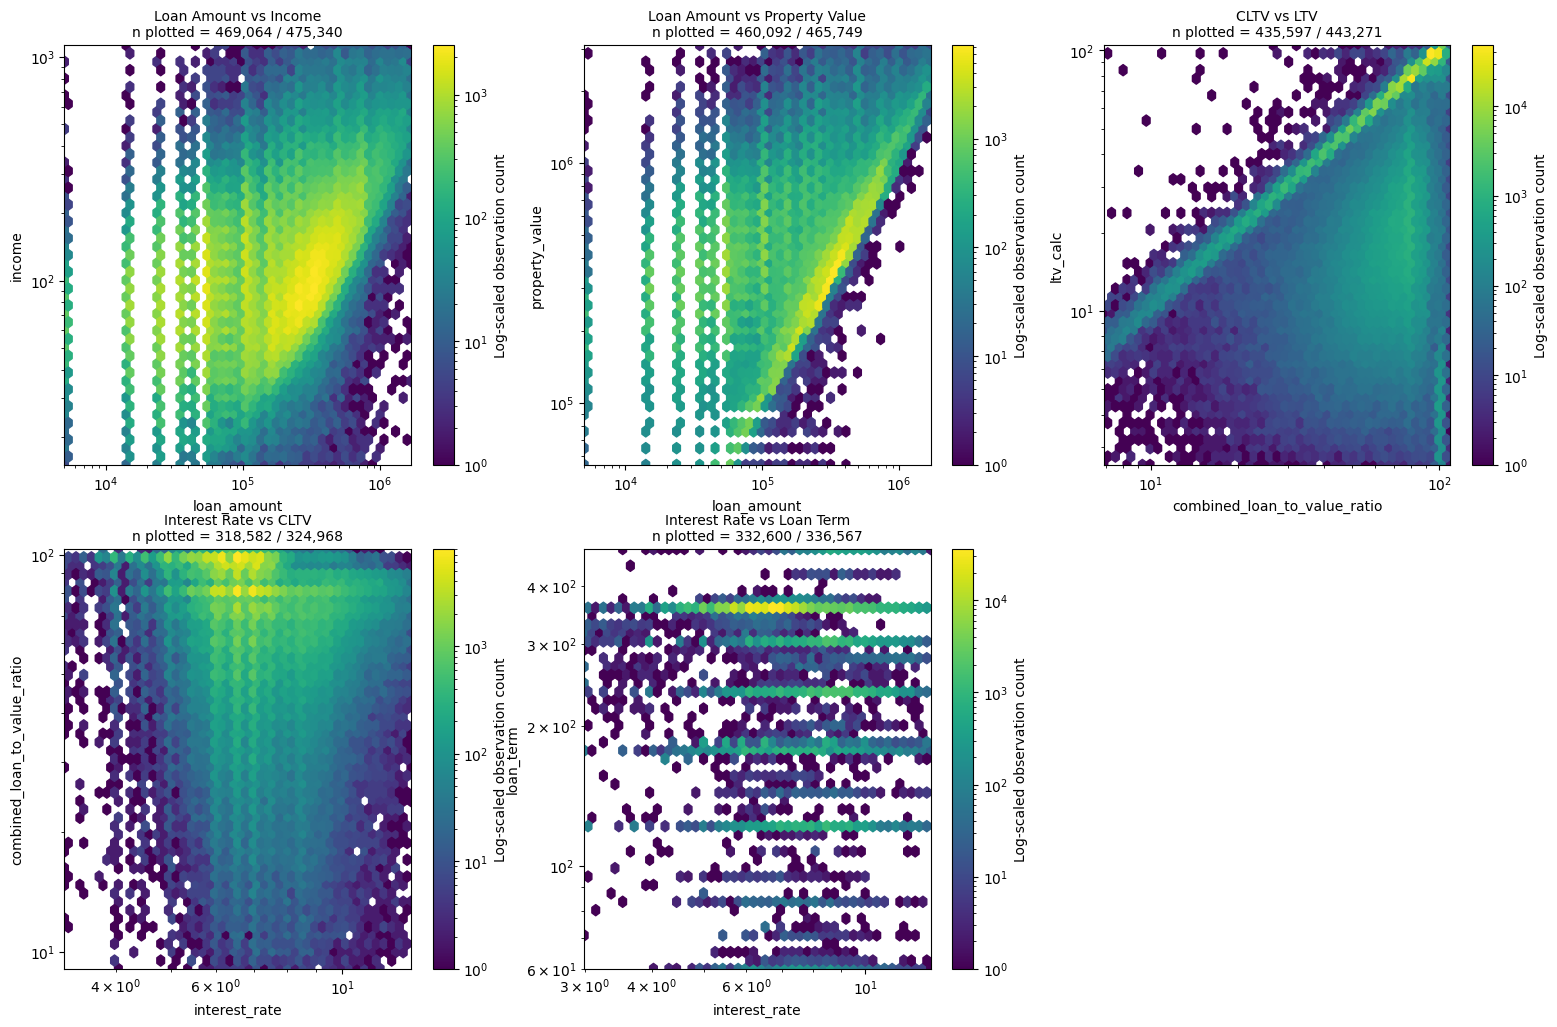

In [86]:

# ------------------------------------------------------------
# Step 6: Generate hexbin diagnostics
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(19, 12))
axes = axes.flatten()

for i, (x, y, label) in enumerate(E1_PAIRS):

    ax = axes[i]

    temp = e1_plot_pdf[
        [x, y, "action_taken"]
    ].copy()

    # Originated loans only for interest-rate relationships
    if x == "interest_rate":
        temp = temp[temp["action_taken"] == 1]

    temp = (
        temp
        .replace([np.inf, -np.inf], np.nan)
        .dropna(subset=[x, y])
    )

    # Positive values for logarithmic visualization
    temp = temp[
        (temp[x] > 0)
        & (temp[y] > 0)
    ]

    if len(temp) < 10:

        ax.set_title(label)
        ax.text(
            0.5, 0.5,
            f"Insufficient observations (n={len(temp):,})",
            ha="center",
            va="center",
            transform=ax.transAxes
        )
        continue

    # Limit display range only
    x_low, x_high = temp[x].quantile([0.005, 0.995])
    y_low, y_high = temp[y].quantile([0.005, 0.995])

    plot_data = temp[
        temp[x].between(x_low, x_high)
        & temp[y].between(y_low, y_high)
    ]

    # Log-space hexbin
    hb = ax.hexbin(
        plot_data[x],
        plot_data[y],
        gridsize=45,
        xscale="log",
        yscale="log",
        bins="log",
        mincnt=1
    )

    ax.set_xlim(x_low, x_high)
    ax.set_ylim(y_low, y_high)

    ax.set_title(
        f"{label}\n"
        f"n plotted = {len(plot_data):,} / {len(temp):,}",
        fontsize=10
    )

    ax.set_xlabel(x)
    ax.set_ylabel(y)

    fig.colorbar(
        hb,
        ax=ax,
        label="Log-scaled observation count"
    )

# Hide unused subplot
axes[5].set_visible(False)


In [87]:

# ------------------------------------------------------------
# Step 7: Save figure
# ------------------------------------------------------------

plt.suptitle(
    "E1. Numeric-Numeric Relationships",
    fontsize=16,
    y=1.02
)

plt.tight_layout()

e1_fig = os.path.join(
    os.fspath(FIGURE_DIR),
    "B15_fig_23_hexbin.png"
)

plt.savefig(
    e1_fig,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# Step 8: Final summary
# ------------------------------------------------------------

print(f"Saved: {e1_output}")
print(f"Saved: {e1_fig}")
print("Spearman calculations: PySpark")
print(f"Visualization sample: {len(e1_plot_pdf):,} rows")

print("\nOriginated-loan observations in visualization:")

print(
    f"Interest Rate vs CLTV: "
    f"{len(e1_plot_pdf[pd.to_numeric(e1_plot_pdf['action_taken'], errors='coerce') == 1].dropna(subset=['interest_rate', 'combined_loan_to_value_ratio'] )):,}"
)

<Figure size 640x480 with 0 Axes>

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rel_spearman.csv
Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\figures\B15_fig_23_hexbin.png
Spearman calculations: PySpark
Visualization sample: 499,297 rows

Originated-loan observations in visualization:
Interest Rate vs CLTV: 328,515


### E2. Categorical Association with Outcome

**Objective:** Evaluate the strength of association between categorical applicant, loan-product, and institutional characteristics and mortgage denial outcomes.

**Input:** The predefined diagnostic sample (`df_samp`), using existing B14 categorical definitions.

**Process:**
- Construct contingency tables using Spark aggregation.
- Calculate bias-corrected Cramér's V.
- Calculate denial-rate spread across categories.
- Calculate mutual information between each categorical variable and `is_denied`.
- Preserve missing-value categories and the original B14 category definitions.

**Output:** `B15_rel_cramers_v.csv`

**Method Notes:** Cramér's V uses the bias-corrected formula. Mutual information is calculated from joint and marginal frequencies. No p-value testing is performed on the large sample.

In [88]:
# ============================================================
# E2. CATEGORICAL ASSOCIATION WITH OUTCOME
# ============================================================

import math
from pyspark.sql import functions as F

# ------------------------------------------------------------
# Step 1: Define categorical variables
# ------------------------------------------------------------

E2_CATEGORICAL = [
    "derived_race",
    "race_ethnicity",
    "derived_sex",
    "loan_type",
    "loan_purpose",
    "lien_status",
    "occupancy_type",
    "construction_method",
    "total_units",
    "derived_dwelling_category",
    "conforming_loan_limit",
    "open_end_line_of_credit",
    "preapproval",
    "submission_of_application",
    "aus_1",
    "applicant_credit_score_type",
    "lender_size_bucket"
]

E2_CATEGORICAL = [
    c for c in E2_CATEGORICAL
    if c in df_samp.columns
]

assert "is_denied" in df_samp.columns, "is_denied not found."
assert len(E2_CATEGORICAL) > 0, "No E2 categorical variables found."

# ------------------------------------------------------------
# Step 2: Calculate contingency tables in Spark
# ------------------------------------------------------------

e2_results = []

for col in E2_CATEGORICAL:

    contingency = (
        df_samp
        .select(
            F.coalesce(
                F.col(col).cast("string"),
                F.lit("__MISSING__")
            ).alias("category"),
            F.col("is_denied").cast("int").alias("outcome")
        )
        .groupBy("category", "outcome")
        .count()
    )

    contingency_pdf = contingency.toPandas()

    if contingency_pdf.empty:
        continue

    # --------------------------------------------------------
    # Step 3: Construct contingency matrix
    # --------------------------------------------------------

    matrix = (
        contingency_pdf
        .pivot(
            index="category",
            columns="outcome",
            values="count"
        )
        .fillna(0)
    )

    for outcome in [0, 1]:
        if outcome not in matrix.columns:
            matrix[outcome] = 0

    matrix = matrix[[0, 1]].to_numpy(dtype=float)

    n = matrix.sum()

    if n <= 1:
        continue

    row_totals = matrix.sum(axis=1)
    col_totals = matrix.sum(axis=0)


    # --------------------------------------------------------
    # Step 4: Chi-square statistic
    # --------------------------------------------------------

    expected = np.outer(row_totals, col_totals) / n

    valid = expected > 0

    chi2 = np.sum(
        ((matrix - expected) ** 2)[valid] / expected[valid]
    )

    r, k = matrix.shape

    phi2 = chi2 / n

    # --------------------------------------------------------
    # Step 5: Bias-corrected Cramér's V
    # --------------------------------------------------------

    phi2_corrected = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corrected = r - ((r - 1) ** 2) / (n - 1)
    k_corrected = k - ((k - 1) ** 2) / (n - 1)

    denominator = min(
        k_corrected - 1,
        r_corrected - 1
    )

    cramers_v = (
        math.sqrt(phi2_corrected / denominator)
        if denominator > 0 else np.nan
    )

    # --------------------------------------------------------
    # Step 6: Denial-rate spread
    # --------------------------------------------------------

    category_rates = np.divide(
        matrix[:, 1],
        row_totals,
        out=np.full(len(row_totals), np.nan),
        where=row_totals > 0
    )

    denial_spread = (
        np.nanmax(category_rates) -
        np.nanmin(category_rates)
    )

    # --------------------------------------------------------
    # Step 7: Mutual Information
    # --------------------------------------------------------

    joint_prob = matrix / n
    row_prob = row_totals / n
    col_prob = col_totals / n

    mi = 0.0

    for i in range(r):
        for j in range(k):

            pxy = joint_prob[i, j]

            if pxy > 0 and row_prob[i] > 0 and col_prob[j] > 0:

                mi += pxy * np.log(
                    pxy / (row_prob[i] * col_prob[j])
                )

    # --------------------------------------------------------
    # Step 8: Store results
    # --------------------------------------------------------

    e2_results.append({
        "variable": col,
        "sample_n": int(n),
        "category_count": int(r),
        "cramers_v_bias_corrected": cramers_v,
        "denial_rate_spread": denial_spread,
        "mutual_information": mi
    })


In [89]:

# ------------------------------------------------------------
# Step 9: Export results
# ------------------------------------------------------------

e2_pdf = pd.DataFrame(e2_results)

e2_output = os.path.join(
    os.fspath(OUTPUT_DIR),
    "B15_rel_cramers_v.csv"
)

e2_pdf.to_csv(e2_output, index=False)

display(e2_pdf.sort_values(
    "cramers_v_bias_corrected",
    ascending=False
))

print(f"Saved: {e2_output}")

,variable,sample_n,category_count,cramers_v_bias_corrected,denial_rate_spread,mutual_information
14,aus_1,499297,8,0.3172,0.3217,0.0525
4,loan_purpose,499297,6,0.2606,0.4526,0.0337
15,applicant_credit_score_type,499297,15,0.2437,0.6266,0.0270
9,derived_dwelling_category,499297,4,0.1778,0.5167,0.0136
7,construction_method,499297,2,0.1771,0.3194,0.0134
5,lien_status,499297,2,0.1652,0.1570,0.0131
11,open_end_line_of_credit,499297,3,0.1501,0.2341,0.0108
16,lender_size_bucket,499297,4,0.1337,0.1726,0.0092
1,race_ethnicity,499297,5,0.1186,0.1564,0.0068
0,derived_race,499297,9,0.1170,0.4088,0.0065


Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rel_cramers_v.csv


### E3. Collinearity Preview

**Objective:** Identify potential multicollinearity among candidate numerical controls before subsequent sequential modeling.

**Input:** The predefined diagnostic sample (`df_samp`).

**Process:**
- Reuse the B14 numeric control block.
- Apply the same complete-case sample and variable transformations.
- Calculate pairwise correlations.
- Calculate Variance Inflation Factors (VIF) using the definition VIF = 1 / (1 - R²).
- Identify potentially redundant variable pairs.

**Output:** `B15_rel_vif.csv`

**Method Notes:** VIF must use the same predictors, complete-case rules, transformations, and sample as B14. This is a diagnostic preview, not a variable-selection or model-fitting stage.

In [90]:
# ============================================================
# E3. COLLINEARITY PREVIEW
# ============================================================

import os
import numpy as np
import pandas as pd

from pyspark.sql import functions as F

# ------------------------------------------------------------
# Step 1: Define numeric control block
# ------------------------------------------------------------

E3_NUMERIC = [
    "loan_amount",
    "income",
    "property_value",
    "loan_to_income",
    "combined_loan_to_value_ratio",
    "ltv_calc"
]

E3_NUMERIC = [
    c for c in E3_NUMERIC
    if c in df_samp.columns
]

assert len(E3_NUMERIC) >= 2, "Insufficient E3 numeric variables."

# ------------------------------------------------------------
# Step 2: Prepare complete-case diagnostic sample in Spark
# ------------------------------------------------------------

e3_spark = df_samp.select(
    *[F.col(c).cast("double").alias(c) for c in E3_NUMERIC]
)

for c in E3_NUMERIC:
    e3_spark = e3_spark.filter(
        F.col(c).isNotNull()
        & (~F.isnan(F.col(c)))
        & (F.abs(F.col(c)) < float("inf"))
    )


In [91]:

# ------------------------------------------------------------
# Step 3: Calculate correlations and standard deviations
# ------------------------------------------------------------

e3_agg_exprs = [
    F.count("*").alias("complete_case_n")
]

for i, x in enumerate(E3_NUMERIC):
    e3_agg_exprs.append(
        F.stddev_pop(F.col(x)).alias(f"std_{i}")
    )

for i, x in enumerate(E3_NUMERIC):
    for j, y in enumerate(E3_NUMERIC):
        e3_agg_exprs.append(
            F.corr(F.col(x), F.col(y)).alias(f"corr_{i}_{j}")
        )

e3_stats = e3_spark.agg(*e3_agg_exprs).first()

e3_n = int(e3_stats["complete_case_n"])

assert e3_n > len(E3_NUMERIC), (
    "Insufficient complete-case observations."
)

# ------------------------------------------------------------
# Step 4: Identify non-constant variables
# ------------------------------------------------------------

E3_ACTIVE_IDX = [
    i for i in range(len(E3_NUMERIC))
    if e3_stats[f"std_{i}"] is not None
    and e3_stats[f"std_{i}"] > 0
]

E3_ACTIVE = [
    E3_NUMERIC[i] for i in E3_ACTIVE_IDX
]

assert len(E3_ACTIVE) >= 2, (
    "Insufficient non-constant numeric variables."
)


In [92]:

# ------------------------------------------------------------
# Step 5: Build the small correlation matrix
# ------------------------------------------------------------

e3_corr_matrix = np.array([
    [
        e3_stats[f"corr_{i}_{j}"]
        for j in E3_ACTIVE_IDX
    ]
    for i in E3_ACTIVE_IDX
], dtype=float)

assert np.isfinite(e3_corr_matrix).all(), (
    "Invalid correlation matrix."
)

e3_corr_matrix = (
    e3_corr_matrix + e3_corr_matrix.T
) / 2

# ------------------------------------------------------------
# Step 6: Calculate VIF from the correlation matrix
# ------------------------------------------------------------

e3_vif_results = []

for i, variable in enumerate(E3_ACTIVE):

    other_idx = [
        j for j in range(len(E3_ACTIVE))
        if j != i
    ]

    R_other = e3_corr_matrix[
        np.ix_(other_idx, other_idx)
    ]

    r_target = e3_corr_matrix[
        other_idx, i
    ]

    beta = np.linalg.lstsq(
        R_other,
        r_target,
        rcond=None
    )[0]

    r_squared = float(r_target @ beta)

    r_squared = np.clip(r_squared, 0, 1)

    vif = (
        1 / (1 - r_squared)
        if 1 - r_squared > 1e-12
        else np.inf
    )

    e3_vif_results.append({
        "variable": variable,
        "vif": vif,
        "r_squared": r_squared,
        "complete_case_n": e3_n,
        "high_vif": vif >= 5,
        "very_high_vif": vif >= 10
    })


In [93]:

# ------------------------------------------------------------
# Step 7: Calculate pairwise correlations
# ------------------------------------------------------------

e3_pairs = []

for i in range(len(E3_ACTIVE)):
    for j in range(i + 1, len(E3_ACTIVE)):

        corr = e3_corr_matrix[i, j]

        e3_pairs.append({
            "variable_1": E3_ACTIVE[i],
            "variable_2": E3_ACTIVE[j],
            "pearson_correlation": corr,
            "absolute_correlation": abs(corr),
            "potentially_redundant": abs(corr) >= 0.80
        })

# ------------------------------------------------------------
# Step 8: Build output tables
# ------------------------------------------------------------

e3_output_pdf = pd.DataFrame(e3_vif_results)
e3_pair_pdf = pd.DataFrame(e3_pairs)

# ------------------------------------------------------------
# Step 9: Export results
# ------------------------------------------------------------

e3_output = os.path.join(
    os.fspath(OUTPUT_DIR),
    "B15_rel_vif.csv"
)

e3_output_pdf.to_csv(e3_output, index=False)

print("E3 VIF results:")
display(e3_output_pdf)

print("E3 pairwise correlations:")
display(e3_pair_pdf)

print(f"Complete-case sample: {e3_n:,}")
print(f"Active variables: {len(E3_ACTIVE)}")
print(f"Saved: {e3_output}")

E3 VIF results:


,variable,vif,r_squared,complete_case_n,high_vif,very_high_vif
0,loan_amount,1.5039,0.3351,430045,False,False
1,income,1.0001,0.0001,430045,False,False
2,property_value,1.0136,0.0134,430045,False,False
3,loan_to_income,1.4623,0.3162,430045,False,False
4,combined_loan_to_value_ratio,1.0000,0.0000,430045,False,False
5,ltv_calc,1.0281,0.0274,430045,False,False


E3 pairwise correlations:


,variable_1,variable_2,pearson_correlation,absolute_correlation,potentially_redundant
0,loan_amount,income,0.0068,0.0068,False
1,loan_amount,property_value,0.1107,0.1107,False
2,loan_amount,loan_to_income,0.5622,0.5622,False
3,loan_amount,combined_loan_to_value_ratio,-0.0006,0.0006,False
4,loan_amount,ltv_calc,0.1621,0.1621,False
5,income,property_value,0.0016,0.0016,False
6,income,loan_to_income,-0.0010,0.0010,False
7,income,combined_loan_to_value_ratio,-0.0000,0.0000,False
8,income,ltv_calc,0.0009,0.0009,False
9,property_value,loan_to_income,0.0569,0.0569,False


Complete-case sample: 430,045
Active variables: 6
Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rel_vif.csv


### E4. Race Association with Controls

**Objective:** Examine how applicant characteristics and financial controls differ across racial groups relative to the White reference group.

**Input:** The predefined diagnostic sample (`df_samp`), preserving the existing `derived_race` definitions.

**Process:**
- Use White as the reference group.
- Calculate group means, standard deviations, and sample sizes for each candidate control.
- Calculate standardized mean differences (SMD) using the B14 pooled-standard-deviation formula.
- Compare each available racial group against White.
- Prepare results for a love-plot-style visualization.

**Output:** `B15_rel_smd_by_race.csv`

**Method Notes:** SMD measures standardized differences in observed characteristics. It is descriptive and does not establish causality or prove that controlling for a variable eliminates a racial denial gap.

In [94]:
# ============================================================
# E4. RACE ASSOCIATION WITH CONTROLS
# ============================================================

import os
import pandas as pd

from pyspark.sql import functions as F

# ------------------------------------------------------------
# Step 1: Define reference group and candidate controls
# ------------------------------------------------------------

E4_RACE = "derived_race"
E4_REFERENCE = "White"

E4_CONTROLS = [
    "loan_amount",
    "income",
    "property_value",
    "loan_to_income",
    "combined_loan_to_value_ratio",
    "ltv_calc"
]

E4_CONTROLS = [
    c for c in E4_CONTROLS
    if c in df_samp.columns
]

assert E4_RACE in df_samp.columns, "derived_race not found."
assert len(E4_CONTROLS) > 0, "No E4 controls found."

assert (
    df_samp
    .filter(F.col(E4_RACE) == E4_REFERENCE)
    .limit(1)
    .count() > 0
), "White reference group not found."


In [95]:

# ------------------------------------------------------------
# Step 2: Calculate group statistics in Spark
# ------------------------------------------------------------

e4_results = []

for variable in E4_CONTROLS:

    base = (
        df_samp
        .select(
            F.col(E4_RACE).cast("string").alias("__race"),
            F.col(variable).cast("double").alias("__value")
        )
        .filter(
            F.col("__race").isNotNull()
            & F.col("__value").isNotNull()
            & (~F.isnan(F.col("__value")))
            & (F.abs(F.col("__value")) < float("inf"))
        )
    )

    # Group-level means, sample variances and counts
    group_stats = (
        base
        .groupBy("__race")
        .agg(
            F.count("*").alias("group_n"),
            F.avg("__value").alias("group_mean"),
            F.var_samp("__value").alias("group_variance")
        )
    )

    # White reference statistics
    reference_stats = (
        group_stats
        .filter(F.col("__race") == E4_REFERENCE)
        .select(
            F.col("group_n").alias("reference_n"),
            F.col("group_mean").alias("reference_mean"),
            F.col("group_variance").alias("reference_variance")
        )
    )

    # --------------------------------------------------------
    # Step 3: Calculate pooled standard deviation and SMD
    # --------------------------------------------------------

    comparison = (
        group_stats
        .crossJoin(reference_stats)
        .filter(
            (F.col("__race") != E4_REFERENCE)
            & (F.col("group_n") >= 2)
            & (F.col("reference_n") >= 2)
        )
        .withColumn(
            "pooled_variance",
            (
                (F.col("group_n") - 1)
                * F.col("group_variance")
                +
                (F.col("reference_n") - 1)
                * F.col("reference_variance")
            )
            /
            (
                F.col("group_n")
                + F.col("reference_n")
                - 2
            )
        )
        .withColumn(
            "pooled_sd",
            F.sqrt(
                F.greatest(
                    F.col("pooled_variance"),
                    F.lit(0.0)
                )
            )
        )
        .withColumn(
            "smd",
            F.when(
                F.col("pooled_sd") > 0,
                (
                    F.col("group_mean")
                    - F.col("reference_mean")
                ) / F.col("pooled_sd")
            )
        )
        .withColumn(
            "absolute_smd",
            F.abs(F.col("smd"))
        )
        .withColumn(
            "variable",
            F.lit(variable)
        )
        .select(
            F.col("__race").alias("race_group"),
            "variable",
            "group_n",
            "reference_n",
            "group_mean",
            "reference_mean",
            "pooled_sd",
            "smd",
            "absolute_smd"
        )
    )

    e4_results.append(comparison)


In [96]:

# ------------------------------------------------------------
# Step 4: Combine all control comparisons
# ------------------------------------------------------------

e4_spark = e4_results[0]

for result in e4_results[1:]:
    e4_spark = e4_spark.unionByName(result)

e4_spark = e4_spark.orderBy(
    "race_group",
    F.desc("absolute_smd")
)

# ------------------------------------------------------------
# Step 5: Export bounded summary results
# ------------------------------------------------------------

e4_pdf = e4_spark.toPandas()

e4_output = os.path.join(
    os.fspath(OUTPUT_DIR),
    "B15_rel_smd_by_race.csv"
)

e4_pdf.to_csv(e4_output, index=False)

display(e4_pdf)

print("E4 statistical calculations: PySpark")
print(f"Groups compared: {e4_pdf['race_group'].nunique()}")
print(f"Controls evaluated: {len(E4_CONTROLS)}")
print(f"Results: {len(e4_pdf):,} rows")
print(f"Saved: {e4_output}")

,race_group,variable,group_n,reference_n,group_mean,reference_mean,pooled_sd,smd,absolute_smd
0,2 or more minority races,ltv_calc,1180,307519,64.5630,59.1626,49.4795,0.1091,0.1091
1,2 or more minority races,income,1233,320043,118.5880,146.6848,520.0763,-0.0540,0.0540
2,2 or more minority races,loan_to_income,1219,316728,2.7005,2.2301,12.2308,0.0385,0.0385
3,2 or more minority races,loan_amount,1283,329129,"245,646.9213","252,882.1374","579,142.8681",-0.0125,0.0125
4,2 or more minority races,property_value,1180,307519,"459,703.3898","500,175.4157","4,095,864.7254",-0.0099,0.0099
5,2 or more minority races,combined_loan_to_value_ratio,1101,296351,90.4762,117.0078,"21,162.8475",-0.0013,0.0013
6,American Indian or Alaska Native,ltv_calc,3466,307519,64.8202,59.1626,49.5055,0.1143,0.1143
7,American Indian or Alaska Native,loan_amount,3723,329129,"200,259.1996","252,882.1374","577,211.2306",-0.0912,0.0912
8,American Indian or Alaska Native,income,3604,320043,105.9218,146.6848,518.3282,-0.0786,0.0786
9,American Indian or Alaska Native,property_value,3466,307519,"372,599.5384","500,175.4157","4,080,817.9945",-0.0313,0.0313


E4 statistical calculations: PySpark
Groups compared: 8
Controls evaluated: 6
Results: 48 rows
Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rel_smd_by_race.csv


### E5. Univariate Importance Preview

**Objective:** Evaluate the individual discriminatory ability of candidate controls in distinguishing denied from non-denied mortgage applications.

**Input:** The predefined diagnostic sample (`df_samp`) and the binary outcome `is_denied`.

**Process:**
- Calculate a separate univariate ROC-AUC for each candidate control.
- Use the rank-based AUC definition.
- Orient each score so that higher values consistently represent higher denial risk.
- Report sample size and missingness for each variable.
- Rank variables by absolute discriminatory ability relative to random classification.

**Output:** `B15_rel_univariate_auc.csv`

**Method Notes:** This analysis uses individual variables only. It does not fit a multivariable predictive model, perform feature selection, or establish causal importance. Results must reproduce the B14 rank-based AUC definition.

In [97]:
# ============================================================
# E5. UNIVARIATE IMPORTANCE PREVIEW
# ============================================================

import os
import pandas as pd

from pyspark.sql import functions as F
from pyspark.sql.window import Window

# ------------------------------------------------------------
# Step 1: Define candidate controls
# ------------------------------------------------------------

E5_CONTROLS = [
    "loan_amount",
    "income",
    "property_value",
    "loan_to_income",
    "combined_loan_to_value_ratio",
    "ltv_calc"
]

E5_CONTROLS = [
    c for c in E5_CONTROLS
    if c in df_samp.columns
]

assert "is_denied" in df_samp.columns, "is_denied not found."
assert len(E5_CONTROLS) > 0, "No E5 controls found."

# ------------------------------------------------------------
# Step 2: Calculate rank-based AUC in Spark
# ------------------------------------------------------------

e5_results = []

for variable in E5_CONTROLS:

    base = (
        df_samp
        .select(
            F.col(variable).cast("double").alias("__score"),
            F.col("is_denied").cast("int").alias("__outcome")
        )
        .filter(
            F.col("__score").isNotNull()
            & (~F.isnan(F.col("__score")))
            & (F.abs(F.col("__score")) < float("inf"))
            & F.col("__outcome").isin(0, 1)
        )
    )

    # --------------------------------------------------------
    # Step 3: Check sample size and outcome variation
    # --------------------------------------------------------

    sample_stats = base.agg(
        F.count("*").alias("sample_n"),
        F.countDistinct("__score").alias("unique_scores"),
        F.sum(
            F.when(F.col("__outcome") == 1, 1).otherwise(0)
        ).alias("denied_n"),
        F.sum(
            F.when(F.col("__outcome") == 0, 1).otherwise(0)
        ).alias("non_denied_n")
    ).first()

    n = int(sample_stats["sample_n"])
    n_positive = int(sample_stats["denied_n"] or 0)
    n_negative = int(sample_stats["non_denied_n"] or 0)

    if (
        n == 0
        or sample_stats["unique_scores"] < 2
        or n_positive == 0
        or n_negative == 0
    ):
        continue

    # --------------------------------------------------------
    # Step 4: Calculate average ranks including ties
    # --------------------------------------------------------

    w_rank = Window.orderBy(
        F.col("__score").asc()
    )

    w_ties = Window.partitionBy(
        "__score"
    )

    ranked = (
        base
        .withColumn(
            "__rank",
            F.rank().over(w_rank)
        )
        .withColumn(
            "__tie_count",
            F.count("*").over(w_ties)
        )
        .withColumn(
            "__average_rank",
            F.col("__rank")
            + (F.col("__tie_count") - 1) / 2
        )
    )

    # --------------------------------------------------------
    # Step 5: Calculate Mann-Whitney rank-based AUC
    # --------------------------------------------------------

    rank_stats = ranked.agg(
        F.sum(
            F.when(
                F.col("__outcome") == 1,
                F.col("__average_rank")
            ).otherwise(0)
        ).alias("positive_rank_sum")
    ).first()

    rank_sum_positive = float(
        rank_stats["positive_rank_sum"]
    )

    auc_raw = (
        rank_sum_positive
        - n_positive * (n_positive + 1) / 2
    ) / (n_positive * n_negative)

    # Orient AUC so higher means stronger discrimination
    auc_oriented = max(auc_raw, 1 - auc_raw)

    e5_results.append({
        "variable": variable,
        "sample_n": n,
        "denied_n": n_positive,
        "non_denied_n": n_negative,
        "auc_raw": auc_raw,
        "auc_oriented": auc_oriented,
        "direction": (
            "Higher values associated with denial"
            if auc_raw >= 0.5
            else "Lower values associated with denial"
        )
    })


In [98]:

# ------------------------------------------------------------
# Step 6: Rank candidate controls
# ------------------------------------------------------------

e5_pdf = pd.DataFrame(e5_results)

if not e5_pdf.empty:

    e5_pdf = (
        e5_pdf
        .sort_values(
            "auc_oriented",
            ascending=False
        )
        .reset_index(drop=True)
    )

    e5_pdf["importance_rank"] = range(
        1,
        len(e5_pdf) + 1
    )

# ------------------------------------------------------------
# Step 7: Export results
# ------------------------------------------------------------

e5_output = os.path.join(
    os.fspath(OUTPUT_DIR),
    "B15_rel_univariate_auc.csv"
)

e5_pdf.to_csv(e5_output, index=False)

display(e5_pdf)

print("E5 rank-based AUC calculations: PySpark")
print(f"Variables evaluated: {len(e5_pdf)}")
print(f"Saved: {e5_output}")

,variable,sample_n,denied_n,non_denied_n,auc_raw,auc_oriented,direction,importance_rank
0,loan_amount,499297,123094,376203,0.3468,0.6532,Lower values associated with denial,1
1,income,480942,120010,360932,0.3535,0.6465,Lower values associated with denial,2
2,ltv_calc,465749,109866,355883,0.4144,0.5856,Lower values associated with denial,3
3,combined_loan_to_value_ratio,447541,101554,345987,0.4327,0.5673,Lower values associated with denial,4
4,property_value,465749,109866,355883,0.4348,0.5652,Lower values associated with denial,5
5,loan_to_income,475340,116614,358726,0.4518,0.5482,Lower values associated with denial,6


E5 rank-based AUC calculations: PySpark
Variables evaluated: 6
Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rel_univariate_auc.csv



## Part F — Geography and Lender Heterogeneity

### Objective
Examine geographic variation in mortgage denial rates and racial gaps, followed by lender-level heterogeneity.

### Input
- `df_s0`: Full B07 analytic sample (S0).
- Existing B14-derived `derived_race` and `is_denied`.
- Existing financial-complete sample and RQ3 valid-tract sample from Part D, where available.

### Process
Use PySpark for all full-sample aggregations. Calculate denial rates, confidence intervals, reference-group gaps, and minimum-cell flags. Collect only bounded aggregate results for visualization.

### Output
Five analytical subsections (F1–F5), corresponding CSV files, and geographic visualizations.

### Methodological constraints
- White remains the reference group.
- Preserve all nine `derived_race` categories.
- Exclude Race Not Available and Free Form Text Only from headline gaps, but retain them in sample accounting.
- Apply the D-M minimum thresholds.
- Preserve the D-I RQ3 sample definition.


In [99]:

# ============================================================
# F0. PART F SHARED HELPERS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F
from pyspark.sql import Window

# ------------------------------------------------------------
# Step 1: Validate existing environment
# ------------------------------------------------------------

assert "df_s0" in globals(), "df_s0 is not available."
assert "spark" in globals(), "Spark session is not available."
assert "OUTPUT_DIR" in globals(), "OUTPUT_DIR is not available."
assert "FIGURE_DIR" in globals(), "FIGURE_DIR is not available."

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

F_REFERENCE = "White"
F_RACE_COL = "derived_race"
F_OUTCOME_COL = "is_denied"

F_N_MIN_APPS = int(globals().get("N_MIN_APPS", 1000))
F_N_MIN_DENIED = int(globals().get("N_MIN_DENIED", 100))

F_HEADLINE_EXCLUDE = [
    "Race Not Available",
    "Free Form Text Only"
]

F_Z = 1.96


In [100]:

# ------------------------------------------------------------
# Step 2: Check required columns
# ------------------------------------------------------------

F_REQUIRED = [
    "derived_race",
    "is_denied",
    "state_code",
    "derived_msa_md",
    "census_tract",
    "tract_minority_population_percent",
    "tract_to_msa_income_percentage"
]

F_MISSING = [c for c in F_REQUIRED if c not in df_s0.columns]

assert not F_MISSING, (
    f"Missing required columns in df_s0: {F_MISSING}"
)

print("Part F environment validation passed.")
print("S0 columns required:", len(F_REQUIRED))
print("Minimum applications:", F_N_MIN_APPS)
print("Minimum denied applications:", F_N_MIN_DENIED)


Part F environment validation passed.
S0 columns required: 7
Minimum applications: 1000
Minimum denied applications: 100


In [101]:

# ------------------------------------------------------------
# Step 3: Bounded output helper
# ------------------------------------------------------------

def f_export_spark_table(df, filename, max_rows=10000):

    pdf = df.limit(max_rows + 1).toPandas()

    assert len(pdf) <= max_rows, (
        f"{filename} exceeds the bounded collection limit."
    )

    path = os.path.join(OUTPUT_DIR, filename)

    pdf.to_csv(path, index=False)

    print(
        f"Saved: {path} | "
        f"Rows: {len(pdf):,} | "
        f"Columns: {len(pdf.columns)}"
    )

    return pdf

# ------------------------------------------------------------
# Step 4: Wilson confidence interval
# ------------------------------------------------------------

def f_add_wilson_ci(df):

    n = F.col("n_apps").cast("double")
    x = F.col("n_denied").cast("double")

    p = x / n
    z2 = F_Z ** 2

    denominator = 1 + z2 / n

    center = (
        p + z2 / (2 * n)
    ) / denominator

    margin = (
        F_Z * F.sqrt(
            p * (1 - p) / n
            + z2 / (4 * n ** 2)
        ) / denominator
    )

    return (
        df
        .withColumn("denial_rate", p)
        .withColumn("ci_lower", F.greatest(
            F.lit(0.0), center - margin
        ))
        .withColumn("ci_upper", F.least(
            F.lit(1.0), center + margin
        ))
    )


In [102]:

# ------------------------------------------------------------
# Step 5: Geographic group-gap helper
# ------------------------------------------------------------

def f_geo_gap(df, geo_col):

    counts = (
        df
        .filter(
            F.col(geo_col).isNotNull()
            & F.col(F_RACE_COL).isNotNull()
        )
        .groupBy(
            F.col(geo_col).cast("string").alias("geo_value"),
            F.col(F_RACE_COL).alias("race_group")
        )
        .agg(
            F.count("*").alias("n_apps"),
            F.sum(
                F.col(F_OUTCOME_COL).cast("long")
            ).alias("n_denied")
        )
    )

    rates = f_add_wilson_ci(counts)

    white = (
        rates
        .filter(F.col("race_group") == F_REFERENCE)
        .select(
            "geo_value",
            F.col("n_apps").alias("white_n_apps"),
            F.col("n_denied").alias("white_n_denied"),
            F.col("denial_rate").alias("white_denial_rate"),
            F.col("ci_lower").alias("white_ci_lower"),
            F.col("ci_upper").alias("white_ci_upper")
        )
    )

    result = rates.join(
        white,
        on="geo_value",
        how="left"
    )

    result = result.withColumn(
        "low_n",
        (F.col("n_apps") < F_N_MIN_APPS)
        | (F.col("n_denied") < F_N_MIN_DENIED)
        | (F.col("white_n_apps") < F_N_MIN_APPS)
        | (F.col("white_n_denied") < F_N_MIN_DENIED)
        | F.col("white_n_apps").isNull()
    )

    result = result.withColumn(
        "is_headline_race",
        ~F.col("race_group").isin(F_HEADLINE_EXCLUDE)
    )

    valid_gap = (
        (~F.col("low_n"))
        & F.col("is_headline_race")
    )

    result = result.withColumn(
        "gap_pp",
        F.when(
            valid_gap,
            (
                F.col("denial_rate")
                - F.col("white_denial_rate")
            ) * 100
        )
    )

    # Conservative interval from Wilson rate bounds.
    result = result.withColumn(
        "gap_ci_lower_pp",
        F.when(
            valid_gap,
            (
                F.col("ci_lower")
                - F.col("white_ci_upper")
            ) * 100
        )
    )

    result = result.withColumn(
        "gap_ci_upper_pp",
        F.when(
            valid_gap,
            (
                F.col("ci_upper")
                - F.col("white_ci_lower")
            ) * 100
        )
    )

    # Haldane-Anscombe corrected odds ratio.
    a = F.col("n_denied").cast("double")
    b = F.col("n_apps").cast("double") - a

    c = F.col("white_n_denied").cast("double")
    d = F.col("white_n_apps").cast("double") - c

    log_or = F.log(
        ((a + 0.5) * (d + 0.5))
        / ((b + 0.5) * (c + 0.5))
    )

    se_log_or = F.sqrt(
        1 / (a + 0.5)
        + 1 / (b + 0.5)
        + 1 / (c + 0.5)
        + 1 / (d + 0.5)
    )

    result = (
        result
        .withColumn(
            "odds_ratio",
            F.when(valid_gap, F.exp(log_or))
        )
        .withColumn(
            "or_ci_lower",
            F.when(
                valid_gap,
                F.exp(log_or - F_Z * se_log_or)
            )
        )
        .withColumn(
            "or_ci_upper",
            F.when(
                valid_gap,
                F.exp(log_or + F_Z * se_log_or)
            )
        )
        .withColumn(
            "gap_ci_method",
            F.lit("Conservative Wilson-bound subtraction")
        )
    )

    return result



## F1. State-Level Denial Rates and Racial Gaps

### Objective
Identify geographic differences in mortgage denial rates across U.S. states and examine how racial denial gaps vary geographically.

### Input
Full S0 with:
- `state_code`
- `derived_race`
- `is_denied`

### Process
1. Aggregate application and denial counts by state and race.
2. Calculate denial rates and 95% Wilson confidence intervals.
3. Compare each racial group against White.
4. Apply D-M minimum-cell thresholds.
5. Prepare state-level gap data for a forest plot and choropleth map.

### Output
- `B15_rq3_state_gap.csv`
- State-level forest plot.
- Black–White state gap map.

### Interpretation
A state-level gap represents a descriptive difference in denial rates, not evidence of a causal effect or discrimination.


In [103]:

# ============================================================
# F1. STATE-LEVEL DENIAL RATES AND RACIAL GAPS
# ============================================================

# ------------------------------------------------------------
# Step 1: Aggregate state-level denial rates and gaps
# ------------------------------------------------------------

df_f1 = (
    df_s0
    .filter(F.col("state_code").isNotNull())
    .withColumn(
        "state_code",
        F.upper(F.trim(F.col("state_code")))
    )
)

F1_STATE = f_geo_gap(df_f1, "state_code")

F1_STATE = (
    F1_STATE
    .withColumnRenamed("geo_value", "state_code")
    .orderBy("state_code", "race_group")
)

# ------------------------------------------------------------
# Step 2: Validate results
# ------------------------------------------------------------

assert (
    F1_STATE
    .filter(
        (F.col("denial_rate") < 0)
        | (F.col("denial_rate") > 1)
    )
    .limit(1)
    .count() == 0
), "Invalid state denial rate detected."

assert (
    F1_STATE
    .filter(F.col("n_denied") > F.col("n_apps"))
    .limit(1)
    .count() == 0
), "State denial count exceeds application count."

# ------------------------------------------------------------
# Step 3: Export state-level results
# ------------------------------------------------------------

F1_STATE_PDF = f_export_spark_table(
    F1_STATE,
    "B15_rq3_state_gap.csv"
)

print("\nF1 state-level summary:")
print(
    F1_STATE
    .groupBy("race_group")
    .agg(
        F.count("*").alias("state_cells"),
        F.sum("n_apps").alias("total_apps"),
        F.sum("n_denied").alias("total_denied"),
        F.sum(F.col("low_n").cast("int")).alias("low_n_cells")
    )
    .orderBy("race_group")
    .show(20, truncate=False)
)


Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq3_state_gap.csv | Rows: 476 | Columns: 21

F1 state-level summary:
+-----------------------------------------+-----------+----------+------------+-----------+
|race_group                               |state_cells|total_apps|total_denied|low_n_cells|
+-----------------------------------------+-----------+----------+------------+-----------+
|2 or more minority races                 |53         |20798     |7880        |48         |
|American Indian or Alaska Native         |52         |60603     |22152       |34         |
|Asian                                    |53         |478055    |103877      |14         |
|Black or African American                |54         |725916    |263974      |14         |
|Free Form Text Only                      |49         |2080      |1210        |49         |
|Joint                                    |54         |183543    |35412       |17         |
|Native Hawaiian or Other 

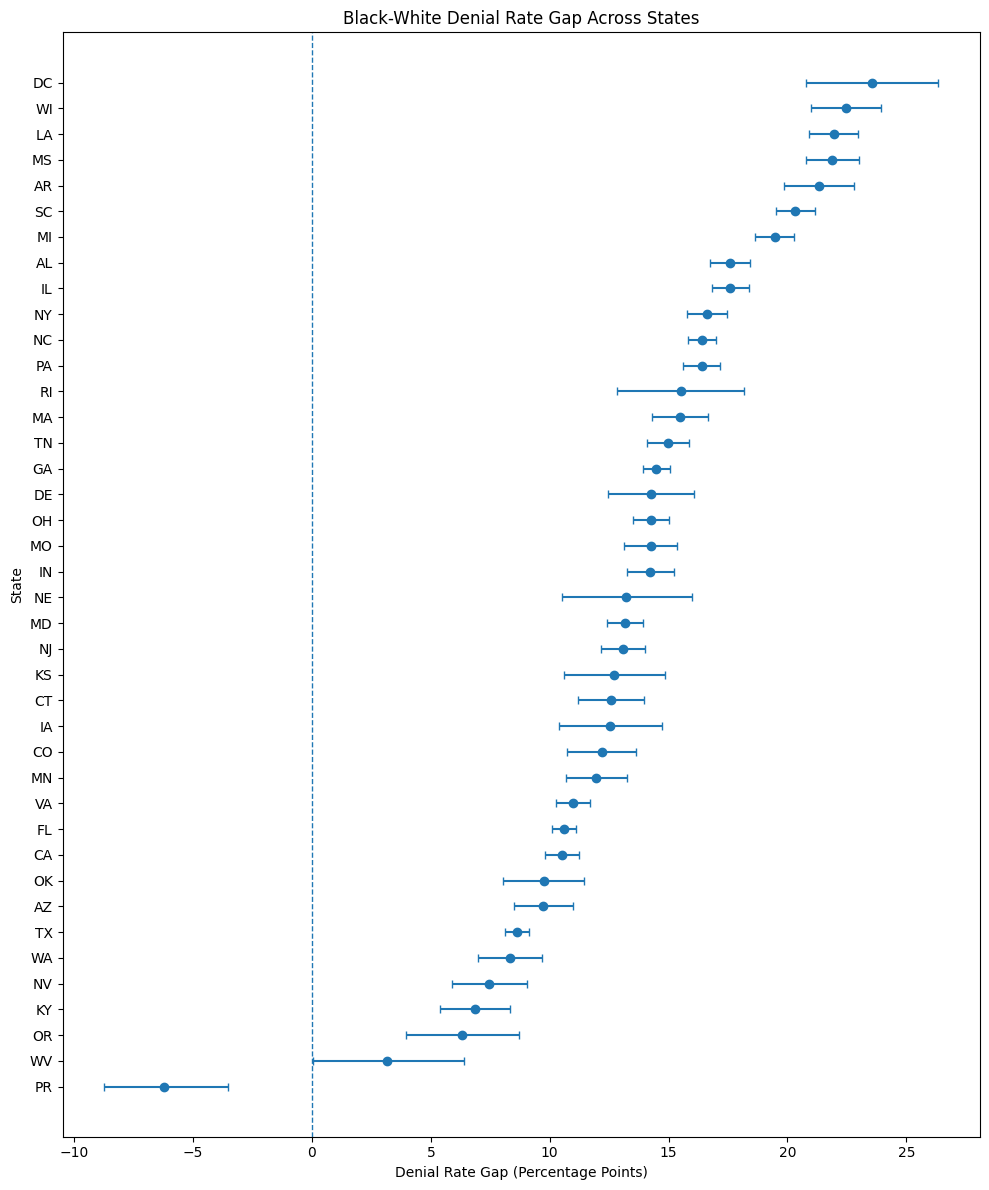

In [104]:

# ------------------------------------------------------------
# Step 4: Black-White forest plot
# ------------------------------------------------------------

F1_BLACK = F1_STATE_PDF[
    (F1_STATE_PDF["race_group"] == "Black or African American")
    & (F1_STATE_PDF["low_n"] == False)
    & (F1_STATE_PDF["gap_pp"].notna())
].copy()

if not F1_BLACK.empty:

    F1_BLACK = F1_BLACK.sort_values("gap_pp")

    fig, ax = plt.subplots(figsize=(10, 12))

    ax.errorbar(
        F1_BLACK["gap_pp"],
        F1_BLACK["state_code"],
        xerr=[
            F1_BLACK["gap_pp"] - F1_BLACK["gap_ci_lower_pp"],
            F1_BLACK["gap_ci_upper_pp"] - F1_BLACK["gap_pp"]
        ],
        fmt="o",
        capsize=3
    )

    ax.axvline(0, linestyle="--", linewidth=1)

    ax.set_title(
        "Black-White Denial Rate Gap Across States"
    )
    ax.set_xlabel("Denial Rate Gap (Percentage Points)")
    ax.set_ylabel("State")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIGURE_DIR,
            "B15_F1_state_forest_plot.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

else:
    print("No eligible Black-White state cells for forest plot.")


In [105]:

# ------------------------------------------------------------
# Step 5: Black-White choropleth map
# ------------------------------------------------------------

if not F1_BLACK.empty:

    try:
        import plotly.express as px

        F1_MAP_LIMIT = max(
            abs(F1_BLACK["gap_pp"].min()),
            abs(F1_BLACK["gap_pp"].max())
        )

        fig = px.choropleth(
            F1_BLACK,
            locations="state_code",
            locationmode="USA-states",
            color="gap_pp",
            scope="usa",
            color_continuous_scale="RdBu",
            range_color=[
                -F1_MAP_LIMIT,
                F1_MAP_LIMIT
            ],
            hover_name="state_code",
            hover_data=[
                "n_apps",
                "n_denied",
                "gap_pp"
            ],
            title="Black-White Denial Rate Gap by State"
        )

        fig.write_html(
            os.path.join(
                FIGURE_DIR,
                "B15_F1_state_gap_map.html"
            )
        )

        fig.show()

    except Exception as e:
        print("Choropleth generation failed:", str(e))

print("F1 completed.")


F1 completed.



## F2. Metropolitan Statistical Area Analysis

### Objective
Examine denial-rate differences across major Metropolitan Statistical Areas (MSAs) and compare metropolitan with non-metropolitan applications.

### Input
Full S0 with:
- `derived_msa_md`
- `derived_race`
- `is_denied`

### Process
1. Calculate application volume by MSA.
2. Identify the top 25 MSAs by application volume for detailed visualization.
3. Preserve code 99999 as the separately labelled non-MSA category.
4. Calculate denial rates and racial gaps against White.
5. Apply D-M minimum-cell thresholds.

### Output
- `B15_rq3_msa_gap.csv`
- MSA-level racial gap dot plot.

### Interpretation
The analysis identifies geographic variation in denial outcomes but does not establish whether differences are caused by applicant composition, local market conditions, or underwriting practices.


Top MSAs selected: 25
Non-MSA available: True
Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq3_msa_gap.csv | Rows: 252 | Columns: 22


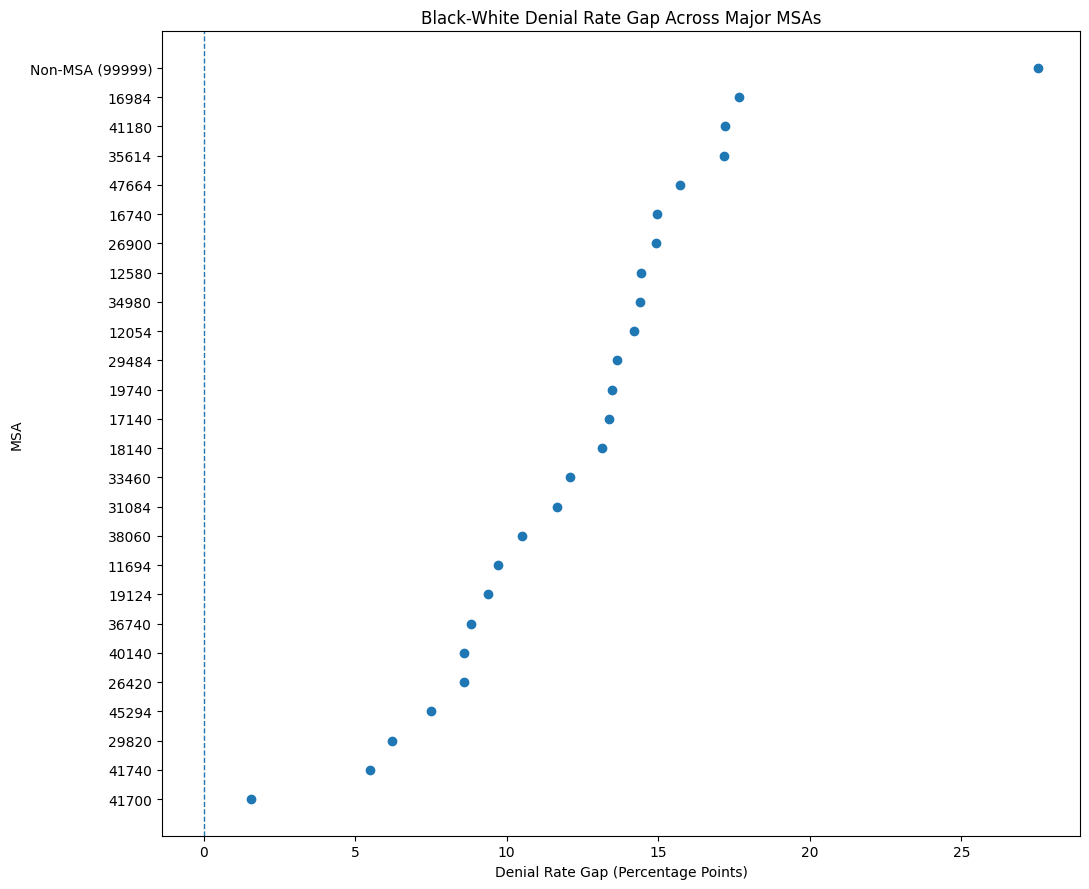

F2 completed.


In [106]:

# ============================================================
# F2. MSA-LEVEL ANALYSIS
# ============================================================

# ------------------------------------------------------------
# Step 1: Prepare MSA codes
# ------------------------------------------------------------

df_f2 = (
    df_s0
    .filter(F.col("derived_msa_md").isNotNull())
    .withColumn(
        "msa_code",
        F.trim(F.col("derived_msa_md").cast("string"))
    )
)

# ------------------------------------------------------------
# Step 2: Identify top 25 MSAs by application volume
# ------------------------------------------------------------

F2_MSA_VOLUME = (
    df_f2
    .filter(F.col("msa_code") != "99999")
    .groupBy("msa_code")
    .agg(F.count("*").alias("n_apps"))
    .orderBy(F.desc("n_apps"))
)

F2_TOP_CODES = [
    row["msa_code"]
    for row in F2_MSA_VOLUME.limit(25).collect()
]

F2_AVAILABLE_CODES = [
    row["msa_code"]
    for row in (
        df_f2
        .filter(F.col("msa_code") == "99999")
        .select("msa_code")
        .distinct()
        .collect()
    )
]

F2_SELECTED_CODES = F2_TOP_CODES + F2_AVAILABLE_CODES

print("Top MSAs selected:", len(F2_TOP_CODES))
print("Non-MSA available:", bool(F2_AVAILABLE_CODES))

# ------------------------------------------------------------
# Step 3: Detailed top-MSA analysis
# ------------------------------------------------------------

df_f2_detail = (
    df_f2
    .filter(F.col("msa_code").isin(F2_SELECTED_CODES))
    .withColumn(
        "msa_display",
        F.when(
            F.col("msa_code") == "99999",
            F.lit("Non-MSA (99999)")
        ).otherwise(F.col("msa_code"))
    )
)

F2_DETAIL = f_geo_gap(
    df_f2_detail,
    "msa_display"
).withColumn(
    "analysis_level",
    F.lit("Top MSAs and Non-MSA")
)

# ------------------------------------------------------------
# Step 4: Metropolitan versus non-metropolitan comparison
# ------------------------------------------------------------

df_f2_type = df_f2.withColumn(
    "msa_type",
    F.when(
        F.col("msa_code") == "99999",
        F.lit("Non-MSA (99999)")
    ).otherwise(F.lit("MSA"))
)

F2_TYPE = f_geo_gap(
    df_f2_type,
    "msa_type"
).withColumn(
    "analysis_level",
    F.lit("MSA versus Non-MSA")
)

# ------------------------------------------------------------
# Step 5: Combine and export
# ------------------------------------------------------------

F2_FINAL = (
    F2_DETAIL
    .unionByName(F2_TYPE)
    .withColumnRenamed("geo_value", "geography")
    .orderBy("analysis_level", "race_group", "geography")
)

F2_PDF = f_export_spark_table(
    F2_FINAL,
    "B15_rq3_msa_gap.csv"
)

# ------------------------------------------------------------
# Step 6: Visualize Black-White MSA gaps
# ------------------------------------------------------------

F2_PLOT = F2_PDF[
    (F2_PDF["analysis_level"] == "Top MSAs and Non-MSA")
    & (F2_PDF["race_group"] == "Black or African American")
    & (F2_PDF["low_n"] == False)
    & (F2_PDF["gap_pp"].notna())
].copy()

if not F2_PLOT.empty:

    F2_PLOT = F2_PLOT.sort_values("gap_pp")

    fig, ax = plt.subplots(figsize=(11, 9))

    ax.scatter(
        F2_PLOT["gap_pp"],
        F2_PLOT["geography"]
    )

    ax.axvline(0, linestyle="--", linewidth=1)

    ax.set_title(
        "Black-White Denial Rate Gap Across Major MSAs"
    )
    ax.set_xlabel("Denial Rate Gap (Percentage Points)")
    ax.set_ylabel("MSA")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIGURE_DIR,
            "B15_F2_msa_gap_dotplot.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

else:
    print("No eligible MSA cells for visualization.")

print("F2 completed.")



## F3. Census-Tract Context: Neighborhood vs Applicant Race

### Objective
Examine whether applicant denial rates differ across neighborhood demographic composition and socioeconomic context.

### Input
Full S0 (`df_s0`):
- `derived_race`
- `is_denied`
- `tract_minority_population_percent`
- `tract_to_msa_income_percentage`

### Process
1. Reproduce the exact B14 tract minority-share bins.
2. Reproduce the exact B14 FFIEC tract-income categories.
3. Retain missing tract-context observations as a separate "No tract" category.
4. Calculate denial rates by applicant race within each tract class.
5. Calculate percentage-point gaps against White within the same class.
6. Apply D-M low-N masking in the heatmaps.

### Output
- `B15_rq3_tract_context.csv`
- `B15_F3_tract_context.png`

### Methodological Notes
Use full S0 rather than restricting the analysis to the financial-complete or RQ3 valid-tract sample. Preserve B14 bin boundaries and category definitions exactly.


Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq3_tract_context.csv | Rows: 99 | Columns: 11
F3 output shape: (99, 11)

F3 category coverage:
+------------------+-----------------+----------+----------+-----------+
|dimension         |level            |race_cells|total_apps|low_n_cells|
+------------------+-----------------+----------+----------+-----------+
|tract_income_level|Low (<50)        |9         |228609    |2          |
|tract_income_level|Middle (80-<120) |9         |3666247   |1          |
|tract_income_level|Moderate (50-<80)|9         |1354546   |1          |
|tract_income_level|No tract         |9         |96065     |3          |
|tract_income_level|Upper (>=120)    |9         |2791197   |1          |
|tract_minority_bin|0-10             |9         |989306    |3          |
|tract_minority_bin|10-25            |9         |2526526   |1          |
|tract_minority_bin|25-50            |9         |2410799   |1          |
|tract_minority_bin|50-8

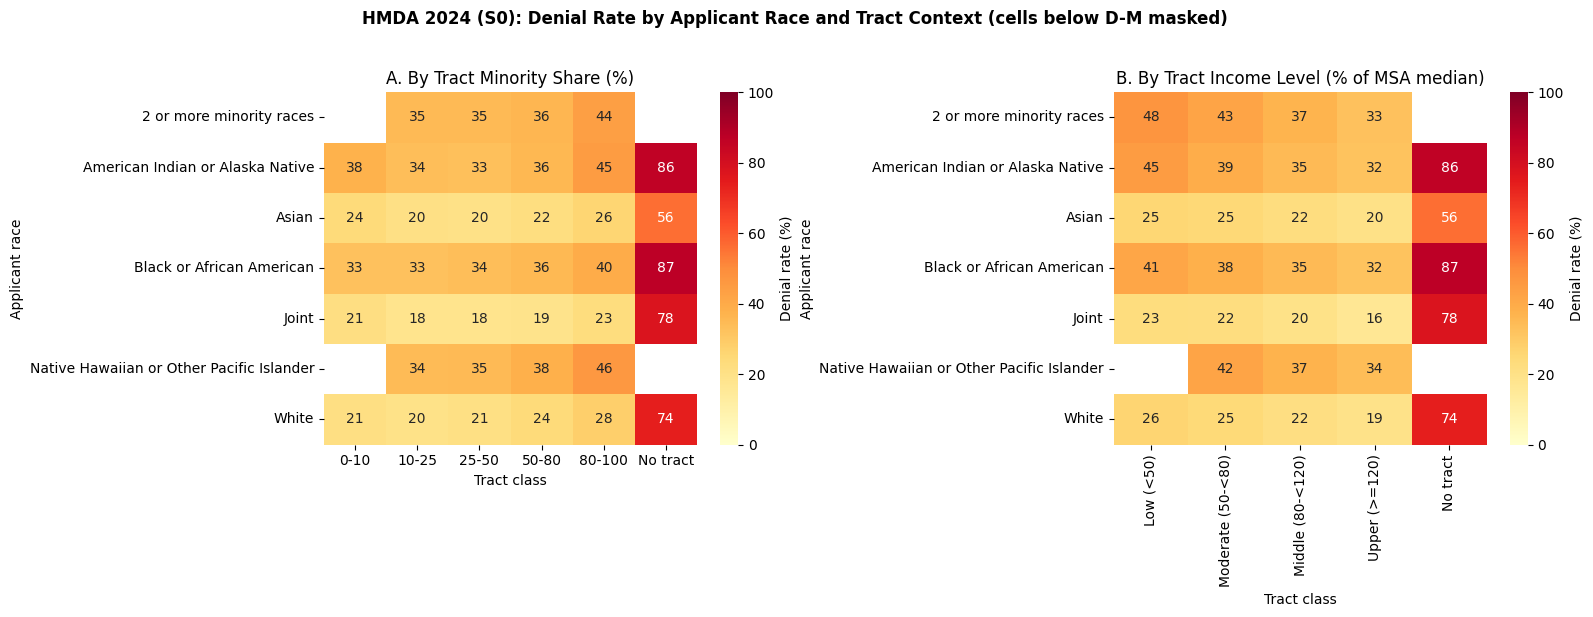

F3 figure saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\figures\B15_F3_tract_context.png
F3 completed successfully.


In [107]:

# ============================================================
# F3. CENSUS-TRACT CONTEXT
# ============================================================

import seaborn as sns

# ------------------------------------------------------------
# Step 1: Prepare full S0 and reproduce B14 tract classes
# ------------------------------------------------------------

df_f3 = (
    df_s0
    .select(
        "derived_race",
        "is_denied",
        "tract_minority_population_percent",
        "tract_to_msa_income_percentage"
    )
)

tm = F.col("tract_minority_population_percent").cast("double")
ti = F.col("tract_to_msa_income_percentage").cast("double")

df_f3 = (
    df_f3
    .withColumn(
        "tract_minority_bin",
        F.when((tm > -0.001) & (tm <= 10), "0-10")
        .when((tm > 10) & (tm <= 25), "10-25")
        .when((tm > 25) & (tm <= 50), "25-50")
        .when((tm > 50) & (tm <= 80), "50-80")
        .when((tm > 80) & (tm <= 100.001), "80-100")
        .otherwise("No tract")
    )
    .withColumn(
        "tract_income_level",
        F.when((ti >= 0) & (ti < 50), "Low (<50)")
        .when((ti >= 50) & (ti < 80), "Moderate (50-<80)")
        .when((ti >= 80) & (ti < 120), "Middle (80-<120)")
        .when(ti >= 120, "Upper (>=120)")
        .otherwise("No tract")
    )
)

# ------------------------------------------------------------
# Step 2: Define exact B14 category ordering
# ------------------------------------------------------------

F3_DIMENSIONS = {
    "tract_minority_bin": [
        "0-10",
        "10-25",
        "25-50",
        "50-80",
        "80-100",
        "No tract"
    ],
    "tract_income_level": [
        "Low (<50)",
        "Moderate (50-<80)",
        "Middle (80-<120)",
        "Upper (>=120)",
        "No tract"
    ]
}

# ------------------------------------------------------------
# Step 3: Calculate denial rates and within-class gaps
# ------------------------------------------------------------

F3_PARTS = []

for dim, levels in F3_DIMENSIONS.items():

    counts = (
        df_f3
        .groupBy("derived_race", dim)
        .agg(
            F.count("*").alias("n_apps"),
            F.sum(
                F.col("is_denied").cast("long")
            ).alias("n_denied")
        )
        .withColumnRenamed(dim, "level")
        .withColumn(
            "denial_rate_pct",
            F.col("n_denied") / F.col("n_apps") * 100
        )
    )

    # White reference within the same tract class.
    white = (
        counts
        .filter(F.col("derived_race") == F_REFERENCE)
        .select(
            "level",
            F.col("n_apps").alias("white_n_apps"),
            F.col("n_denied").alias("white_n_denied"),
            F.col("denial_rate_pct").alias(
                "white_denial_rate_pct"
            )
        )
    )

    part = counts.join(
        white,
        on="level",
        how="left"
    )

    # D-M minimum-cell rule.
    part = part.withColumn(
        "low_n",
        (F.col("n_apps") < F_N_MIN_APPS)
        | (F.col("n_denied") < F_N_MIN_DENIED)
        | (F.col("white_n_apps") < F_N_MIN_APPS)
        | (F.col("white_n_denied") < F_N_MIN_DENIED)
        | F.col("white_n_apps").isNull()
    )

    # Within-class gap versus White.
    part = (
        part
        .withColumn(
            "gap_vs_white_pp",
            F.col("denial_rate_pct")
            - F.col("white_denial_rate_pct")
        )
        .withColumn("dimension", F.lit(dim))
    )

    F3_PARTS.append(part)

# ------------------------------------------------------------
# Step 4: Combine both tract-context dimensions
# ------------------------------------------------------------

F3_FINAL = F3_PARTS[0].unionByName(F3_PARTS[1])

F3_FINAL = (
    F3_FINAL
    .select(
        "dimension",
        "level",
        "derived_race",
        "n_apps",
        "n_denied",
        "denial_rate_pct",
        "white_n_apps",
        "white_n_denied",
        "white_denial_rate_pct",
        "gap_vs_white_pp",
        "low_n"
    )
)

# ------------------------------------------------------------
# Step 5: Validate results
# ------------------------------------------------------------

assert (
    F3_FINAL
    .filter(
        (F.col("denial_rate_pct") < 0)
        | (F.col("denial_rate_pct") > 100)
    )
    .limit(1)
    .count() == 0
), "Invalid F3 denial rate."

assert (
    F3_FINAL
    .filter(
        F.col("level").isNull()
        | F.col("derived_race").isNull()
    )
    .limit(1)
    .count() == 0
), "Unexpected missing F3 categories."

assert (
    F3_FINAL
    .filter(
        ~F.col("dimension").isin(
            "tract_minority_bin",
            "tract_income_level"
        )
    )
    .limit(1)
    .count() == 0
), "Unexpected F3 dimension."

# ------------------------------------------------------------
# Step 6: Export results
# ------------------------------------------------------------

F3_PDF = f_export_spark_table(
    F3_FINAL,
    "B15_rq3_tract_context.csv"
)

print("F3 output shape:", F3_PDF.shape)

print("\nF3 category coverage:")
print(
    F3_FINAL
    .groupBy("dimension", "level")
    .agg(
        F.count("*").alias("race_cells"),
        F.sum("n_apps").alias("total_apps"),
        F.sum(
            F.col("low_n").cast("int")
        ).alias("low_n_cells")
    )
    .orderBy("dimension", "level")
    .show(20, truncate=False)
)

# ------------------------------------------------------------
# Step 7: Resolve B14 headline race ordering
# ------------------------------------------------------------

if "HEADLINE_RACES" in globals():

    F3_RACE_ORDER = list(HEADLINE_RACES)

else:

    F3_RACE_ORDER = [
        r["derived_race"]
        for r in (
            df_f3
            .filter(
                ~F.col("derived_race").isin(
                    F_HEADLINE_EXCLUDE
                )
            )
            .select("derived_race")
            .distinct()
            .orderBy("derived_race")
            .collect()
        )
    ]

# ------------------------------------------------------------
# Step 8: Generate B14-style heatmaps
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

for dim, ax in zip(
    ["tract_minority_bin", "tract_income_level"],
    axes
):

    levels = F3_DIMENSIONS[dim]

    pdf_dim = F3_PDF[
        F3_PDF["dimension"] == dim
    ].copy()

    # Denial-rate matrix.
    pivot = (
        pdf_dim
        .pivot(
            index="derived_race",
            columns="level",
            values="denial_rate_pct"
        )
        .reindex(
            index=F3_RACE_ORDER,
            columns=levels
        )
    )

    # D-M masking matrix.
    mask = (
        pdf_dim
        .pivot(
            index="derived_race",
            columns="level",
            values="low_n"
        )
        .reindex(
            index=F3_RACE_ORDER,
            columns=levels
        )
        .fillna(True)
    )

    sns.heatmap(
        pivot,
        mask=mask,
        annot=True,
        fmt=".0f",
        cmap="YlOrRd",
        vmin=0,
        vmax=100,
        ax=ax,
        cbar_kws={
            "label": "Denial rate (%)"
        }
    )

    if dim == "tract_minority_bin":

        ax.set_title(
            "A. By Tract Minority Share (%)"
        )

    else:

        ax.set_title(
            "B. By Tract Income Level (% of MSA median)"
        )

    ax.set_xlabel("Tract class")
    ax.set_ylabel("Applicant race")

fig.suptitle(
    "HMDA 2024 (S0): Denial Rate by Applicant Race "
    "and Tract Context (cells below D-M masked)",
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

# ------------------------------------------------------------
# Step 9: Save figure
# ------------------------------------------------------------

F3_FIGURE_PATH = os.path.join(
    FIGURE_DIR,
    "B15_F3_tract_context.png"
)

plt.savefig(
    F3_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("F3 figure saved:", F3_FIGURE_PATH)
print("F3 completed successfully.")



## F4. Missing Census Tract as Selection

### Objective
Evaluate whether missing census-tract information creates a non-random selection effect across applicant racial groups.

### Input
- Full S0.
- Financial-complete sample.
- RQ3 sample restricted to valid census tracts.

### Process
1. Separate applications into tract-available and tract-unavailable groups.
2. Compare application counts, denial rates, and racial composition.
3. Calculate tract availability shares within each racial group.
4. Compare denial-rate gaps under S0, fin_complete, and RQ3.
5. Quantify how geographic-data restrictions change the observed gaps.

### Output
- `B15_rq3_tract_na_selection.csv`
- `B15_rq3_tract_na_gap_shift.csv`

### Interpretation
Missing geographic information may disproportionately affect certain racial groups and change the composition of the analytical sample. The resulting gap changes must be interpreted as selection effects, not causal effects.


F4 sample definitions resolved.
Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq3_tract_na_selection.csv | Rows: 18 | Columns: 8
Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq3_tract_na_gap_shift.csv | Rows: 27 | Columns: 10


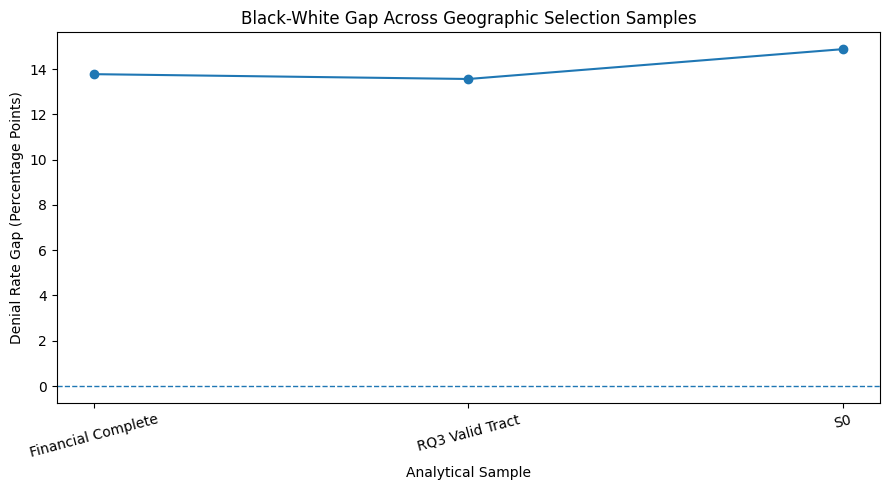

F4 completed.


In [108]:

# ============================================================
# F4. MISSING CENSUS TRACT AS SELECTION
# ============================================================

# ------------------------------------------------------------
# Step 1: Resolve existing financial and RQ3 samples
# ------------------------------------------------------------

df_f_fin = None

if "df_fin_complete" in globals():

    df_f_fin = df_fin_complete

elif "fin_complete" in df_s0.columns:

    df_f_fin = df_s0.filter(
        F.col("fin_complete") == True
    )

if "df_rq3" in globals():

    df_f_rq3 = df_rq3.filter(
        F.col("census_tract").isNotNull()
    )

elif df_f_fin is not None:

    df_f_rq3 = df_f_fin.filter(
        F.col("census_tract").isNotNull()
    )

else:

    raise NameError(
        "Cannot resolve the D-I RQ3 sample. "
        "Check the financial-complete DataFrame from Part D."
    )

print("F4 sample definitions resolved.")

# ------------------------------------------------------------
# Step 2: Compare tract availability in full S0
# ------------------------------------------------------------

df_f4_status = (
    df_s0
    .withColumn(
        "tract_status",
        F.when(
            F.col("census_tract").isNull(),
            "Missing Census Tract"
        ).otherwise("Valid Census Tract")
    )
)

F4_STATUS = (
    df_f4_status
    .groupBy("derived_race", "tract_status")
    .agg(
        F.count("*").alias("n_apps"),
        F.sum(
            F.col("is_denied").cast("long")
        ).alias("n_denied")
    )
    .withColumn(
        "denial_rate",
        F.col("n_denied") / F.col("n_apps")
    )
)

# ------------------------------------------------------------
# Step 3: Calculate racial composition and tract retention
# ------------------------------------------------------------

W_STATUS = Window.partitionBy("tract_status")
W_RACE = Window.partitionBy("derived_race")

F4_STATUS = (
    F4_STATUS
    .withColumn(
        "race_composition_pct",
        F.col("n_apps")
        / F.sum("n_apps").over(W_STATUS) * 100
    )
    .withColumn(
        "tract_availability_share_within_race_pct",
        F.col("n_apps")
        / F.sum("n_apps").over(W_RACE) * 100
    )
    .withColumn(
        "low_n",
        (F.col("n_apps") < F_N_MIN_APPS)
        | (F.col("n_denied") < F_N_MIN_DENIED)
    )
    .orderBy("derived_race", "tract_status")
)

F4_STATUS_PDF = f_export_spark_table(
    F4_STATUS,
    "B15_rq3_tract_na_selection.csv"
)

# ------------------------------------------------------------
# Step 4: Compare racial gaps across analytical samples
# ------------------------------------------------------------

F4_GAP_FRAMES = []

F4_SAMPLES = [
    ("S0", df_s0)
]

if df_f_fin is not None:
    F4_SAMPLES.append(
        ("Financial Complete", df_f_fin)
    )

F4_SAMPLES.append(
    ("RQ3 Valid Tract", df_f_rq3)
)

for sample_name, sample_df in F4_SAMPLES:

    sample_tagged = sample_df.withColumn(
        "sample_scope",
        F.lit(sample_name)
    )

    sample_gap = (
        f_geo_gap(
            sample_tagged,
            "sample_scope"
        )
        .withColumn(
            "sample_scope",
            F.col("geo_value")
        )
        .drop("geo_value")
    )

    F4_GAP_FRAMES.append(sample_gap)

F4_GAP_SHIFT = F4_GAP_FRAMES[0]

for next_frame in F4_GAP_FRAMES[1:]:

    F4_GAP_SHIFT = F4_GAP_SHIFT.unionByName(
        next_frame
    )

F4_GAP_SHIFT = (
    F4_GAP_SHIFT
    .select(
        "sample_scope",
        "race_group",
        "n_apps",
        "n_denied",
        "denial_rate",
        "gap_pp",
        "gap_ci_lower_pp",
        "gap_ci_upper_pp",
        "odds_ratio",
        "low_n"
    )
    .orderBy("race_group", "sample_scope")
)

# ------------------------------------------------------------
# Step 5: Export gap comparison
# ------------------------------------------------------------

F4_GAP_PDF = f_export_spark_table(
    F4_GAP_SHIFT,
    "B15_rq3_tract_na_gap_shift.csv"
)

# ------------------------------------------------------------
# Step 6: Visualize selection effects
# ------------------------------------------------------------

F4_PLOT = F4_GAP_PDF[
    (F4_GAP_PDF["race_group"] == "Black or African American")
    & (F4_GAP_PDF["gap_pp"].notna())
].copy()

if not F4_PLOT.empty:

    F4_PLOT = F4_PLOT.sort_values("sample_scope")

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(
        F4_PLOT["sample_scope"],
        F4_PLOT["gap_pp"],
        marker="o"
    )

    ax.axhline(0, linestyle="--", linewidth=1)

    ax.set_title(
        "Black-White Gap Across Geographic Selection Samples"
    )
    ax.set_xlabel("Analytical Sample")
    ax.set_ylabel("Denial Rate Gap (Percentage Points)")

    plt.xticks(rotation=15)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIGURE_DIR,
            "B15_F4_tract_selection_gap.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("F4 completed.")



## F5. State-Level Heterogeneity

### Objective
Measure how much racial denial gaps vary across U.S. states and whether geographic differences are associated with state-level denial rates.

### Input
- F1 state-level denial rates and gaps.
- Full S0 for national and state-level benchmarks.

### Process
1. Extract eligible Black-White state-level gaps.
2. Calculate the national Black-White reference gap.
3. Calculate the variance of state-level gaps.
4. Identify the proportion of states where the gap sign reverses relative to the national gap.
5. Calculate the correlation between state-level gaps and average state denial rates.

### Output
- `B15_rq3_state_heterogeneity.csv`
- State-level heterogeneity scatter plot.

### Interpretation
A high variance indicates substantial geographic heterogeneity. A reversed gap indicates that the direction of the state-level difference differs from the national benchmark. Neither pattern independently establishes causality.


Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq3_state_heterogeneity.csv | Rows: 41

F5 overall statistics:
       row_type state_code  n_eligible_states  national_black_white_gap_pp  state_gap_variance  share_reversed_states  gap_denial_rate_correlation
Overall Summary ALL_STATES                 40                      14.8752             32.8104                 0.0250                       0.2040


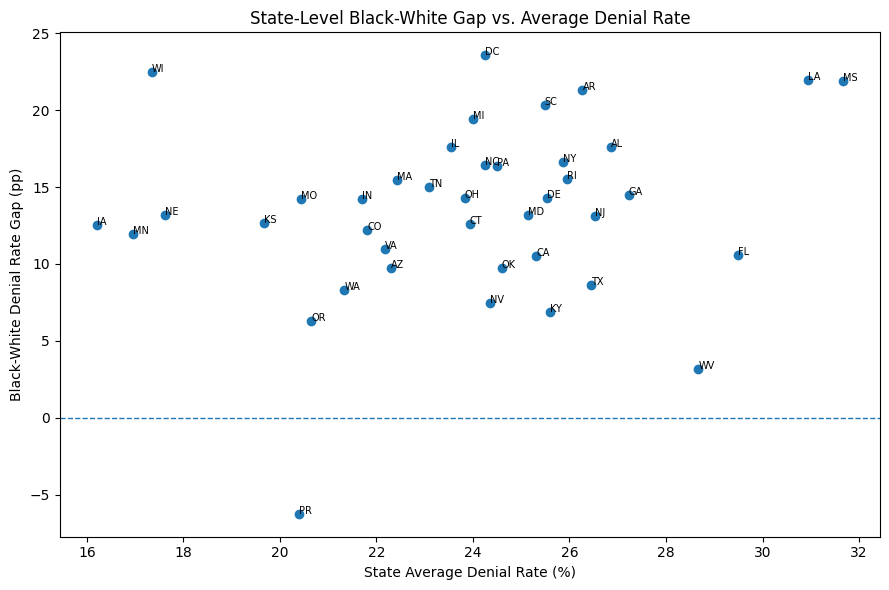

F5 completed.


In [109]:

# ============================================================
# F5. STATE-LEVEL HETEROGENEITY
# ============================================================

# ------------------------------------------------------------
# Step 1: Calculate national Black-White reference gap
# ------------------------------------------------------------

df_f5_national = df_s0.withColumn(
    "national_scope",
    F.lit("United States")
)

F5_NATIONAL = f_geo_gap(
    df_f5_national,
    "national_scope"
)

F5_NATIONAL_ROW = (
    F5_NATIONAL
    .filter(
        F.col("race_group") == "Black or African American"
    )
    .select("gap_pp")
    .first()
)

assert F5_NATIONAL_ROW is not None, (
    "National Black-White gap is unavailable."
)

F5_NATIONAL_GAP = F5_NATIONAL_ROW["gap_pp"]

assert F5_NATIONAL_GAP is not None, (
    "National Black-White gap is below the reporting threshold."
)

# ------------------------------------------------------------
# Step 2: Extract eligible state-level Black-White gaps
# ------------------------------------------------------------

F5_STATE_GAPS = F1_STATE_PDF[
    (F1_STATE_PDF["race_group"] == "Black or African American")
    & (F1_STATE_PDF["low_n"] == False)
    & (F1_STATE_PDF["gap_pp"].notna())
].copy()

# ------------------------------------------------------------
# Step 3: Calculate state-level average denial rates
# ------------------------------------------------------------

F5_STATE_RATES = (
    df_s0
    .filter(F.col("state_code").isNotNull())
    .groupBy("state_code")
    .agg(
        F.count("*").alias("state_n_apps"),
        F.sum(
            F.col("is_denied").cast("long")
        ).alias("state_n_denied"),
        F.avg(
            F.col("is_denied").cast("double")
        ).alias("state_denial_rate")
    )
)

F5_STATE_RATES_PDF = F5_STATE_RATES.toPandas()

F5_STATE_RATES_PDF["state_denial_rate_pct"] = (
    F5_STATE_RATES_PDF["state_denial_rate"] * 100
)

# ------------------------------------------------------------
# Step 4: Combine state-level metrics
# ------------------------------------------------------------

F5_STATE = F5_STATE_GAPS.merge(
    F5_STATE_RATES_PDF[
        [
            "state_code",
            "state_n_apps",
            "state_n_denied",
            "state_denial_rate_pct"
        ]
    ],
    on="state_code",
    how="inner"
)

F5_STATE["national_black_white_gap_pp"] = (
    F5_NATIONAL_GAP
)

F5_STATE["gap_sign_reversed"] = (
    np.sign(F5_STATE["gap_pp"])
    != np.sign(F5_NATIONAL_GAP)
)

# ------------------------------------------------------------
# Step 5: Calculate heterogeneity statistics
# ------------------------------------------------------------

F5_GAP_VARIANCE = F5_STATE["gap_pp"].var(ddof=1)

F5_REVERSED_SHARE = (
    F5_STATE["gap_sign_reversed"].mean()
    if len(F5_STATE) > 0
    else np.nan
)

F5_CORRELATION = (
    F5_STATE[
        ["gap_pp", "state_denial_rate_pct"]
    ].corr().iloc[0, 1]
    if len(F5_STATE) > 1
    else np.nan
)

F5_SUMMARY = pd.DataFrame([{
    "row_type": "Overall Summary",
    "state_code": "ALL_STATES",
    "n_eligible_states": len(F5_STATE),
    "national_black_white_gap_pp": F5_NATIONAL_GAP,
    "state_gap_variance": F5_GAP_VARIANCE,
    "share_reversed_states": F5_REVERSED_SHARE,
    "gap_denial_rate_correlation": F5_CORRELATION
}])

F5_STATE["row_type"] = "State"

F5_STATE_EXPORT = F5_STATE.rename(
    columns={
        "state_n_apps": "n_eligible_state_apps",
        "state_n_denied": "n_eligible_state_denied"
    }
)

F5_FINAL = pd.concat(
    [
        F5_STATE_EXPORT,
        F5_SUMMARY
    ],
    ignore_index=True,
    sort=False
)

# ------------------------------------------------------------
# Step 6: Export results
# ------------------------------------------------------------

F5_PATH = os.path.join(
    OUTPUT_DIR,
    "B15_rq3_state_heterogeneity.csv"
)

F5_FINAL.to_csv(
    F5_PATH,
    index=False
)

print(
    f"Saved: {F5_PATH} | "
    f"Rows: {len(F5_FINAL):,}"
)

print("\nF5 overall statistics:")
print(F5_SUMMARY.to_string(index=False))

# ------------------------------------------------------------
# Step 7: State heterogeneity scatter plot
# ------------------------------------------------------------

if not F5_STATE.empty:

    fig, ax = plt.subplots(figsize=(9, 6))

    ax.scatter(
        F5_STATE["state_denial_rate_pct"],
        F5_STATE["gap_pp"]
    )

    for _, row in F5_STATE.iterrows():

        ax.annotate(
            row["state_code"],
            (
                row["state_denial_rate_pct"],
                row["gap_pp"]
            ),
            fontsize=7
        )

    ax.axhline(0, linestyle="--", linewidth=1)

    ax.set_title(
        "State-Level Black-White Gap vs. Average Denial Rate"
    )
    ax.set_xlabel("State Average Denial Rate (%)")
    ax.set_ylabel("Black-White Denial Rate Gap (pp)")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIGURE_DIR,
            "B15_F5_state_heterogeneity.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("F5 completed.")



## F6. Lender Size and Concentration

### Objective
Examine how mortgage applications are distributed across lenders and assess the concentration of lending activity across the national market and individual states.

### Input
Full S0 (`df_s0`):
- `lei`
- `state_code`
- `derived_race`
- `is_denied`
- `lender_size_bucket`

### Process
1. Aggregate application volume by lender.
2. Calculate top-1, top-5, top-10, and top-25 lender shares.
3. Calculate the Herfindahl-Hirschman Index (HHI) nationally and by state.
4. Construct a Lorenz-type curve to visualize application concentration.
5. Compare lender-size bucket distribution across applicant racial groups.
6. Apply D-M minimum-cell flags to race × lender-size summaries.

### Output
- `B15_rq3_lender_concentration.csv`
- `B15_rq3_lender_lorenz.csv`
- `B15_rq3_lender_size_mix.csv`
- Lender concentration Lorenz curve.

### Methodological Notes
HHI is calculated as the sum of squared lender market shares expressed in percentage terms. A higher HHI indicates greater application concentration among fewer lenders.

The existing `lender_size_bucket` is reused without recalculation because it was originally computed on the full dataset before S0 filtering.


In [110]:

# ============================================================
# F6 DIAGNOSTIC: CHECK COMPLETED OBJECTS
# ============================================================

F6_CHECK_OBJECTS = [
    "F_LENDER_BASE",
    "F_LENDER_ID_MAP",
    "F6_LENDER",
    "F6_NATIONAL",
    "F6_STATE",
    "F6_MARKET_LENDER",
    "F6_CONCENTRATION",
    "F6_LORENZ",
    "F6_SIZE_MIX",
    "F6_CONCENTRATION_PDF",
    "F6_LORENZ_PDF",
    "F6_SIZE_PDF"
]

for name in F6_CHECK_OBJECTS:
    exists = name in globals()
    print(f"{name}: {'EXISTS' if exists else 'NOT CREATED'}")


F_LENDER_BASE: NOT CREATED
F_LENDER_ID_MAP: NOT CREATED
F6_LENDER: NOT CREATED
F6_NATIONAL: NOT CREATED
F6_STATE: NOT CREATED
F6_MARKET_LENDER: NOT CREATED
F6_CONCENTRATION: NOT CREATED
F6_LORENZ: NOT CREATED
F6_SIZE_MIX: NOT CREATED
F6_CONCENTRATION_PDF: NOT CREATED
F6_LORENZ_PDF: NOT CREATED
F6_SIZE_PDF: NOT CREATED


In [111]:

# ============================================================
# F6 DIAGNOSTIC: INPUT VALIDATION
# ============================================================

F6_CHECK_COLUMNS = [
    "lei",
    "state_code",
    "derived_race",
    "is_denied",
    "lender_size_bucket",
    "is_exempt_filer",
    "is_partial_exempt"
]

print("Missing columns:")
print([
    c for c in F6_CHECK_COLUMNS
    if c not in df_s0.columns
])

print("\nAvailable lender-related columns:")
print([
    c for c in df_s0.columns
    if any(
        x in c.lower()
        for x in ["lender", "lei", "exempt"]
    )
])

print("\nInput schema:")
df_s0.select(
    *[c for c in F6_CHECK_COLUMNS if c in df_s0.columns]
).printSchema()

print("\nSmall input test:")
df_s0.select(
    *[c for c in F6_CHECK_COLUMNS if c in df_s0.columns]
).limit(1).show(truncate=False)


Missing columns:
[]

Available lender-related columns:
['lei', 'lender_credits', 'lender_credits_status', 'lei_status', 'n_exempt_28', 'is_exempt_filer', 'is_partial_exempt', 'lender_n_apps', 'lender_size_bucket']

Input schema:
root
 |-- lei: string (nullable = true)
 |-- state_code: string (nullable = true)
 |-- derived_race: string (nullable = true)
 |-- is_denied: byte (nullable = true)
 |-- lender_size_bucket: string (nullable = true)
 |-- is_exempt_filer: boolean (nullable = true)
 |-- is_partial_exempt: boolean (nullable = true)


Small input test:
+--------------------+----------+-------------------------+---------+------------------+---------------+-----------------+
|lei                 |state_code|derived_race             |is_denied|lender_size_bucket|is_exempt_filer|is_partial_exempt|
+--------------------+----------+-------------------------+---------+------------------+---------------+-----------------+
|254900HA4DQWAE0W3342|TX        |Black or African American|0        |

F6 input validation passed.
Lender-level aggregation completed.
Identified lenders: 4808
F6 concentration validation passed.
F6 Lorenz validation passed.
Exported: B15_rq3_lender_concentration.csv (55 rows)
Exported: B15_rq3_lender_lorenz.csv (4,808 rows)
Exported: B15_rq3_lender_size_mix.csv (36 rows)


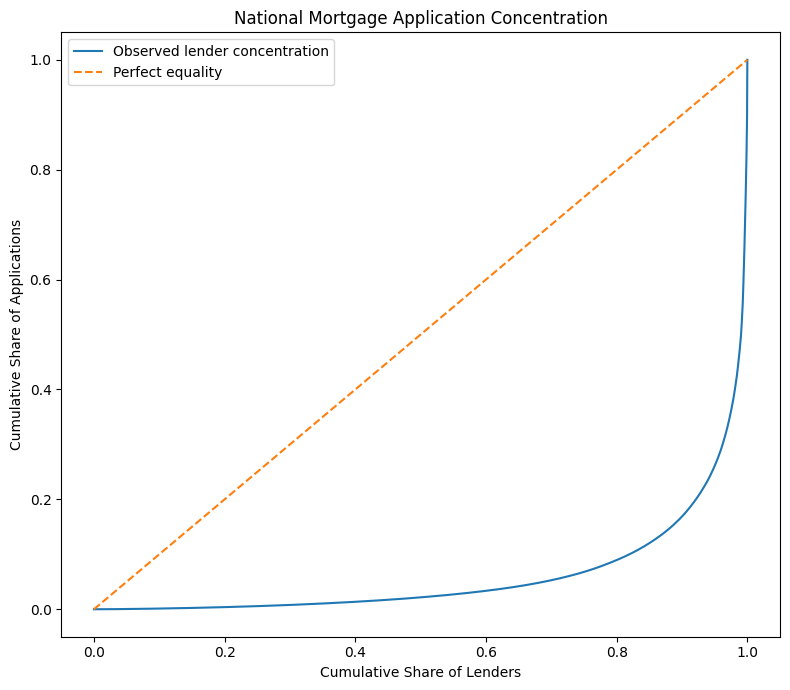


F6 OUTPUT SUMMARY
Identified lenders: 4808
Concentration rows: 55
Lorenz rows: 4808
Size-mix rows: 36

Exported files:
D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq3_lender_concentration.csv
D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq3_lender_lorenz.csv
D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq3_lender_size_mix.csv

F6 completed successfully.


In [112]:

# ============================================================
# F6. LENDER SIZE AND CONCENTRATION
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F
from pyspark.sql import Window

# ------------------------------------------------------------
# Step 1: Initialize paths and shared thresholds
# ------------------------------------------------------------

os.makedirs(os.fspath(OUTPUT_DIR), exist_ok=True)
os.makedirs(os.fspath(FIGURE_DIR), exist_ok=True)

# D-M minimum-cell thresholds
F_N_MIN_APPS = 1000
F_N_MIN_DENIED = 100

# Funnel plot reference
F_Z = 1.96

# Shared race definitions for F7-F10
F_REFERENCE = "White"

F_HEADLINE_EXCLUDE = [
    "Race Not Available",
    "Free Form Text Only"
]

F6_REQUIRED = [
    "lei",
    "state_code",
    "derived_race",
    "is_denied",
    "lender_size_bucket",
    "is_exempt_filer",
    "is_partial_exempt"
]

F6_MISSING = [
    c for c in F6_REQUIRED
    if c not in df_s0.columns
]

assert not F6_MISSING, (
    f"Missing F6 columns: {F6_MISSING}"
)


print("F6 input validation passed.")

# ------------------------------------------------------------
# Step 2: Create reusable lender input
# ------------------------------------------------------------

F_LENDER_BASE = df_s0.select(*F6_REQUIRED)

# ------------------------------------------------------------
# Step 3: Aggregate applications by lender
# ------------------------------------------------------------

F6_LENDER = (
    F_LENDER_BASE
    .filter(F.col("lei").isNotNull())
    .groupBy("lei")
    .agg(
        F.count("*").alias("n_apps"),
        F.sum(
            F.coalesce(
                F.col("is_denied").cast("long"),
                F.lit(0)
            )
        ).alias("n_denied")
    )
    .withColumn(
        "lender_id",
        F.concat(
            F.lit("L_"),
            F.substring(
                F.sha2(F.col("lei"), 256),
                1,
                12
            )
        )
    )
    .withColumn(
        "denial_rate",
        F.col("n_denied") / F.col("n_apps")
    )
    .withColumn(
        "low_n",
        (F.col("n_apps") < F_N_MIN_APPS)
        | (F.col("n_denied") < F_N_MIN_DENIED)
    )
)

F_LENDER_ID_MAP = F6_LENDER.select(
    "lei",
    "lender_id"
)

F6_N_LENDERS = F6_LENDER.count()

print("Lender-level aggregation completed.")
print("Identified lenders:", F6_N_LENDERS)

# ------------------------------------------------------------
# Step 4: National market distribution
# ------------------------------------------------------------

F6_NATIONAL = (
    F6_LENDER
    .select(
        "lei",
        "lender_id",
        "n_apps"
    )
    .withColumn(
        "market_type",
        F.lit("National")
    )
    .withColumn(
        "market_label",
        F.lit("United States")
    )
)

# ------------------------------------------------------------
# Step 5: State-level market distribution
# ------------------------------------------------------------

F6_STATE = (
    F_LENDER_BASE
    .filter(
        F.col("lei").isNotNull()
        & F.col("state_code").isNotNull()
    )
    .withColumn(
        "market_label",
        F.upper(F.trim(F.col("state_code")))
    )
    .filter(F.col("market_label") != "")
    .groupBy(
        "market_label",
        "lei"
    )
    .agg(
        F.count("*").alias("n_apps")
    )
    .withColumn(
        "lender_id",
        F.concat(
            F.lit("L_"),
            F.substring(
                F.sha2(F.col("lei"), 256),
                1,
                12
            )
        )
    )
    .withColumn(
        "market_type",
        F.lit("State")
    )
    .select(
        "lei",
        "lender_id",
        "n_apps",
        "market_type",
        "market_label"
    )
)

# ------------------------------------------------------------
# Step 6: Combine market distributions
# ------------------------------------------------------------

F6_MARKET_LENDER = F6_NATIONAL.unionByName(
    F6_STATE
)

# ------------------------------------------------------------
# Step 7: Calculate market shares and lender ranks
# ------------------------------------------------------------

F6_MARKET_WINDOW = Window.partitionBy(
    "market_type",
    "market_label"
)

F6_RANK_WINDOW = (
    Window
    .partitionBy(
        "market_type",
        "market_label"
    )
    .orderBy(
        F.desc("n_apps"),
        F.asc("lender_id")
    )
)

F6_MARKET_LENDER = (
    F6_MARKET_LENDER
    .withColumn(
        "market_total_apps",
        F.sum("n_apps").over(F6_MARKET_WINDOW)
    )
    .withColumn(
        "market_n_lenders",
        F.count("*").over(F6_MARKET_WINDOW)
    )
    .withColumn(
        "market_share_pct",
        F.col("n_apps")
        / F.col("market_total_apps") * 100
    )
    .withColumn(
        "lender_rank",
        F.row_number().over(F6_RANK_WINDOW)
    )
    .withColumn(
        "hhi_component",
        F.pow(F.col("market_share_pct"), 2)
    )
)

# ------------------------------------------------------------
# Step 8: Calculate HHI and Top-N concentration
# ------------------------------------------------------------

F6_CONCENTRATION = (
    F6_MARKET_LENDER
    .groupBy(
        "market_type",
        "market_label"
    )
    .agg(
        F.max("market_total_apps").alias("total_apps"),
        F.max("market_n_lenders").alias("n_lenders"),

        F.sum("hhi_component").alias("hhi"),

        F.sum(
            F.when(
                F.col("lender_rank") <= 1,
                F.col("market_share_pct")
            ).otherwise(0.0)
        ).alias("top_1_share_pct"),

        F.sum(
            F.when(
                F.col("lender_rank") <= 5,
                F.col("market_share_pct")
            ).otherwise(0.0)
        ).alias("top_5_share_pct"),

        F.sum(
            F.when(
                F.col("lender_rank") <= 10,
                F.col("market_share_pct")
            ).otherwise(0.0)
        ).alias("top_10_share_pct"),

        F.sum(
            F.when(
                F.col("lender_rank") <= 25,
                F.col("market_share_pct")
            ).otherwise(0.0)
        ).alias("top_25_share_pct")
    )
    .orderBy(
        "market_type",
        "market_label"
    )
)

# ------------------------------------------------------------
# Step 9: Construct national Lorenz curve
# ------------------------------------------------------------

F6_LORENZ_ORDER = (
    Window
    .orderBy(
        F.asc("n_apps"),
        F.asc("lender_id")
    )
)

F6_LORENZ_CUMULATIVE = (
    F6_LORENZ_ORDER
    .rowsBetween(
        Window.unboundedPreceding,
        Window.currentRow
    )
)

F6_LORENZ_TOTAL = (
    F6_LORENZ_ORDER
    .rowsBetween(
        Window.unboundedPreceding,
        Window.unboundedFollowing
    )
)

F6_LORENZ = (
    F6_LENDER
    .select(
        "lender_id",
        "n_apps"
    )
    .withColumn(
        "lender_rank_ascending",
        F.row_number().over(F6_LORENZ_ORDER)
    )
    .withColumn(
        "total_lenders",
        F.count("*").over(F6_LORENZ_TOTAL)
    )
    .withColumn(
        "total_apps",
        F.sum("n_apps").over(F6_LORENZ_TOTAL)
    )
    .withColumn(
        "cumulative_apps",
        F.sum("n_apps").over(F6_LORENZ_CUMULATIVE)
    )
    .withColumn(
        "cumulative_lender_share",
        F.col("lender_rank_ascending")
        / F.col("total_lenders")
    )
    .withColumn(
        "cumulative_application_share",
        F.col("cumulative_apps")
        / F.col("total_apps")
    )
    .select(
        "lender_rank_ascending",
        "cumulative_lender_share",
        "cumulative_application_share"
    )
)

# ------------------------------------------------------------
# Step 10: Analyze lender-size mix by applicant race
# ------------------------------------------------------------

F6_SIZE_MIX = (
    F_LENDER_BASE
    .groupBy(
        F.coalesce(
            F.col("derived_race"),
            F.lit("Missing race")
        ).alias("derived_race"),

        F.coalesce(
            F.col("lender_size_bucket"),
            F.lit("Missing bucket")
        ).alias("lender_size_bucket")
    )
    .agg(
        F.count("*").alias("n_apps"),
        F.sum(
            F.coalesce(
                F.col("is_denied").cast("long"),
                F.lit(0)
            )
        ).alias("n_denied")
    )
)

F6_SIZE_WINDOW = Window.partitionBy(
    "derived_race"
)

F6_SIZE_MIX = (
    F6_SIZE_MIX
    .withColumn(
        "race_total_apps",
        F.sum("n_apps").over(F6_SIZE_WINDOW)
    )
    .withColumn(
        "race_share_pct",
        F.col("n_apps")
        / F.col("race_total_apps") * 100
    )
    .withColumn(
        "denial_rate_pct",
        F.col("n_denied")
        / F.col("n_apps") * 100
    )
    .withColumn(
        "low_n",
        (F.col("n_apps") < F_N_MIN_APPS)
        | (F.col("n_denied") < F_N_MIN_DENIED)
    )
    .withColumn(
        "is_headline_race",
        ~F.col("derived_race").isin(F_HEADLINE_EXCLUDE)
    )
)

# ------------------------------------------------------------
# Step 11: Validate concentration and Lorenz outputs
# ------------------------------------------------------------

F6_TOLERANCE = 1e-6

F6_INVALID = F6_CONCENTRATION.filter(
    (F.col("hhi") < 0)
    | (F.col("hhi") > 10000 + F6_TOLERANCE)

    | (F.col("top_1_share_pct") < 0)
    | (F.col("top_1_share_pct") > 100 + F6_TOLERANCE)

    | (F.col("top_5_share_pct") < 0)
    | (F.col("top_5_share_pct") > 100 + F6_TOLERANCE)

    | (F.col("top_10_share_pct") < 0)
    | (F.col("top_10_share_pct") > 100 + F6_TOLERANCE)

    | (F.col("top_25_share_pct") < 0)
    | (F.col("top_25_share_pct") > 100 + F6_TOLERANCE)

    | (F.col("top_1_share_pct") >
       F.col("top_5_share_pct") + F6_TOLERANCE)

    | (F.col("top_5_share_pct") >
       F.col("top_10_share_pct") + F6_TOLERANCE)

    | (F.col("top_10_share_pct") >
       F.col("top_25_share_pct") + F6_TOLERANCE)
)

assert F6_INVALID.limit(1).count() == 0, (
    "F6 concentration validation failed."
)

F6_SHARE_CHECK = (
    F6_MARKET_LENDER
    .groupBy(
        "market_type",
        "market_label"
    )
    .agg(
        F.sum("market_share_pct").alias("total_share_pct")
    )
    .filter(
        F.abs(F.col("total_share_pct") - 100)
        > F6_TOLERANCE
    )
)

assert F6_SHARE_CHECK.limit(1).count() == 0, (
    "F6 market shares do not sum to 100%."
)

F6_LORENZ_CHECK = (
    F6_LORENZ
    .agg(
        F.max("cumulative_lender_share").alias("lender_share"),
        F.max("cumulative_application_share").alias("application_share")
    )
    .first()
)

assert abs(F6_LORENZ_CHECK["lender_share"] - 1) <= F6_TOLERANCE
assert abs(F6_LORENZ_CHECK["application_share"] - 1) <= F6_TOLERANCE

print("F6 concentration validation passed.")
print("F6 Lorenz validation passed.")

# ------------------------------------------------------------
# Step 12: Export F6 tables
# JVM JSON serialization - Windows compatible
# ------------------------------------------------------------

import csv
import json

def _f6_export_csv(sdf, filename):

    target_path = os.path.join(
        os.fspath(OUTPUT_DIR),
        filename
    )

    # Collect JSON strings directly from Spark JVM.
    # Avoid Spark CSV writer and Python workers.
    json_rows = sdf._jdf.toJSON().collect()

    columns = sdf.columns

    with open(
        target_path,
        "w",
        newline="",
        encoding="utf-8-sig"
    ) as file:

        writer = csv.DictWriter(
            file,
            fieldnames=columns,
            extrasaction="ignore"
        )

        writer.writeheader()

        for raw_row in json_rows:

            row = json.loads(str(raw_row))

            writer.writerow({
                col: row.get(col)
                for col in columns
            })

    assert os.path.exists(target_path), (
        f"Export failed: {filename}"
    )

    print(
        f"Exported: {filename} "
        f"({len(json_rows):,} rows)"
    )

    return target_path


# Export all F6 tables

F6_CONCENTRATION_PATH = _f6_export_csv(
    F6_CONCENTRATION,
    "B15_rq3_lender_concentration.csv"
)

F6_LORENZ_PATH = _f6_export_csv(
    F6_LORENZ,
    "B15_rq3_lender_lorenz.csv"
)

F6_SIZE_PATH = _f6_export_csv(
    F6_SIZE_MIX,
    "B15_rq3_lender_size_mix.csv"
)

# Load Lorenz data locally for plotting

F6_LORENZ_PDF = pd.read_csv(
    F6_LORENZ_PATH
)

# ------------------------------------------------------------
# Step 13: Plot national Lorenz curve
# ------------------------------------------------------------

assert isinstance(F6_LORENZ_PDF, pd.DataFrame), (
    "Lorenz export did not return a Pandas DataFrame."
)

F6_LORENZ_PLOT = pd.concat(
    [
        pd.DataFrame([{
            "cumulative_lender_share": 0.0,
            "cumulative_application_share": 0.0
        }]),
        F6_LORENZ_PDF[
            [
                "cumulative_lender_share",
                "cumulative_application_share"
            ]
        ]
    ],
    ignore_index=True
)

fig, ax = plt.subplots(figsize=(8, 7))

ax.plot(
    F6_LORENZ_PLOT["cumulative_lender_share"],
    F6_LORENZ_PLOT["cumulative_application_share"],
    label="Observed lender concentration"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect equality"
)

ax.set_title(
    "National Mortgage Application Concentration"
)

ax.set_xlabel("Cumulative Share of Lenders")
ax.set_ylabel("Cumulative Share of Applications")

ax.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "B15_F6_lender_lorenz.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# Step 14: Final summary
# ------------------------------------------------------------

print("\nF6 OUTPUT SUMMARY")

print("Identified lenders:", F6_N_LENDERS)
print("Concentration rows:", F6_CONCENTRATION.count())
print("Lorenz rows:", F6_LORENZ.count())
print("Size-mix rows:", F6_SIZE_MIX.count())

print("\nExported files:")
print(F6_CONCENTRATION_PATH)
print(F6_LORENZ_PATH)
print(F6_SIZE_PATH)

print("\nF6 completed successfully.")


In [113]:

# ============================================================
# F6 DIAGNOSTIC: TOP-N SHARE VALIDATION
# ============================================================

print("1. NATIONAL CONCENTRATION")

F6_CONCENTRATION.filter(
    F.col("market_type") == "National"
).show(truncate=False)

print("\n2. HIGHEST TOP-N SHARES")

F6_CONCENTRATION.orderBy(
    F.desc("top_25_share_pct")
).select(
    "market_type",
    "market_label",
    "n_lenders",
    "top_1_share_pct",
    "top_5_share_pct",
    "top_10_share_pct",
    "top_25_share_pct",
    "hhi"
).show(15, truncate=False)

print("\n3. INVALID ROWS")

F6_INVALID = F6_CONCENTRATION.filter(
    (F.col("top_1_share_pct") < 0)
    | (F.col("top_5_share_pct") > 100.000001)
    | (F.col("top_10_share_pct") > 100.000001)
    | (F.col("top_25_share_pct") > 100.000001)
)

F6_INVALID.show(20, truncate=False)

print("\n4. MARKET SHARE SUM CHECK")

F6_MARKET_LENDER.groupBy(
    "market_type",
    "market_label"
).agg(
    F.sum("market_share_pct").alias("total_share_pct")
).orderBy(
    F.desc("total_share_pct")
).show(15, truncate=False)


1. NATIONAL CONCENTRATION
+-----------+-------------+----------+---------+------------------+-----------------+-----------------+------------------+------------------+
|market_type|market_label |total_apps|n_lenders|hhi               |top_1_share_pct  |top_5_share_pct  |top_10_share_pct  |top_25_share_pct  |
+-----------+-------------+----------+---------+------------------+-----------------+-----------------+------------------+------------------+
|National   |United States|8136664   |4808     |100.43107168577487|5.546302514150763|15.75968972050462|22.365922938442584|37.519700948693476|
+-----------+-------------+----------+---------+------------------+-----------------+-----------------+------------------+------------------+


2. HIGHEST TOP-N SHARES
+-----------+------------+---------+------------------+------------------+------------------+------------------+------------------+
|market_type|market_label|n_lenders|top_1_share_pct   |top_5_share_pct   |top_10_share_pct  |top_25_share_


## F7. Lender Denial-Rate Dispersion

### Objective
Examine the variation in lender-level denial rates and distinguish genuine dispersion from random variation caused by different application volumes.

### Input
- Full S0.
- F6 lender-level application and denial counts.
- National S0 denial rate.

### Process
1. Calculate each lender's denial rate.
2. Calculate the national reference denial rate.
3. Construct 95% binomial control limits around the national rate for each lender's application volume.
4. Apply D-M low-N flags.
5. Assign anonymous lender identifiers.
6. Visualize lender denial rates against application volume using a funnel plot.

### Output
- `B15_rq3_lender_funnel.csv`
- `B15_F7_lender_funnel.png`

### Methodological Notes
The funnel plot uses the national S0 denial rate as its reference. The control limits widen for lenders with fewer applications and narrow as application volume increases.

Lenders outside the control limits exhibit denial rates that are unusual relative to the national benchmark under the binomial reference model. This is a descriptive screening tool, not proof of different underwriting practices.


In [114]:

# ============================================================
# SHARED EXPORT HELPER FOR F7-F10
# ============================================================

import os
import json
import pandas as pd
from pathlib import Path

def f_export_spark_table(sdf, filename, max_rows=100000):

    columns = sdf.columns

    # Collect through JVM JSON serialization
    raw_rows = (
        sdf.limit(max_rows)
        ._jdf.toJSON()
        .collect()
    )

    records = [
        json.loads(str(row))
        for row in raw_rows
    ]

    pdf = pd.DataFrame(records, columns=columns)

    output_path = Path(OUTPUT_DIR) / filename

    pdf.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    print(
        f"Exported: {filename} "
        f"| {len(pdf):,} rows"
    )

    return pdf


Exported: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq3_lender_funnel.csv | Rows: 4,808


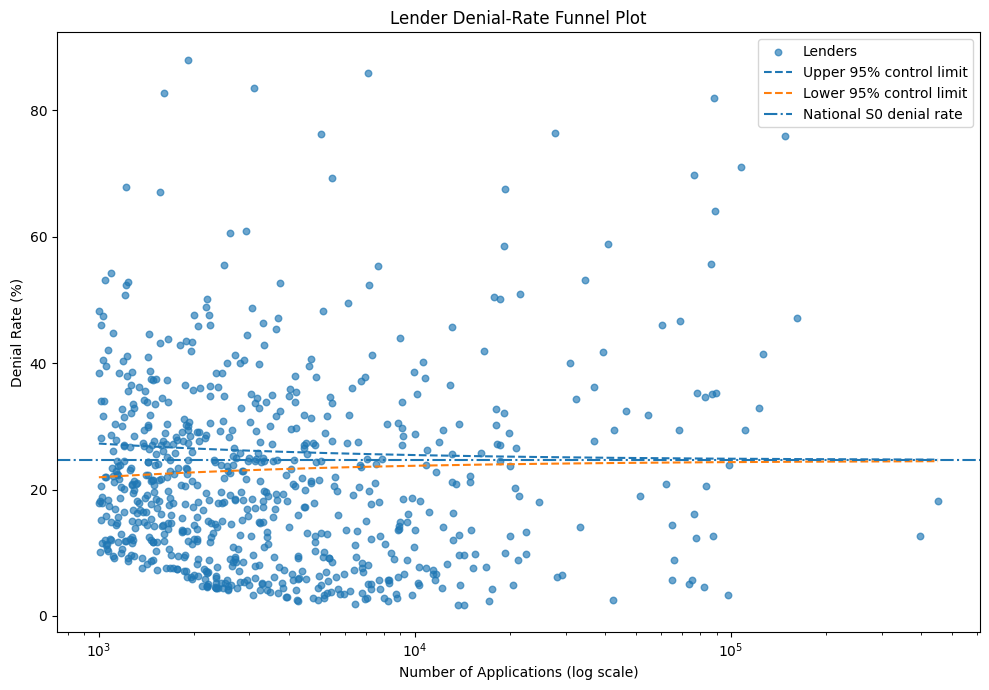


F7 SUMMARY
National S0 denial rate: 24.62 %
Identified lenders: 4808
Lenders outside control limits: 3794
Lenders included in visualization: 731

F7 completed.


In [115]:

# ============================================================
# F7. LENDER DENIAL-RATE DISPERSION
# ============================================================

import os
import json
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F


# ------------------------------------------------------------
# Step 1: Calculate the national reference denial rate
# ------------------------------------------------------------

F7_P0 = (
    df_s0
    .agg(
        F.avg(
            F.col("is_denied").cast("double")
        ).alias("national_denial_rate")
    )
    .first()["national_denial_rate"]
)

assert F7_P0 is not None, "National denial rate unavailable."

F7_P0 = float(F7_P0)

# 95% confidence level
F7_Z = 1.96


# ------------------------------------------------------------
# Step 2: Validate lender-level inputs
# ------------------------------------------------------------

F7_REQUIRED = [
    "lender_id",
    "n_apps",
    "n_denied",
    "denial_rate",
    "low_n"
]

F7_MISSING = [
    c for c in F7_REQUIRED
    if c not in F6_LENDER.columns
]

assert not F7_MISSING, (
    f"Missing F7 input columns: {F7_MISSING}"
)

assert (
    F6_LENDER
    .filter(
        F.col("n_apps").isNull()
        | (F.col("n_apps") <= 0)
        | F.col("n_denied").isNull()
        | (F.col("n_denied") < 0)
        | (F.col("n_denied") > F.col("n_apps"))
    )
    .limit(1)
    .count() == 0
), "Invalid lender-level application counts."


# ------------------------------------------------------------
# Step 3: Calculate binomial control limits
# ------------------------------------------------------------

F7_N = F.col("n_apps").cast("double")
F7_X = F.col("n_denied").cast("double")

F7_P = F7_X / F7_N

F7_SE = F.sqrt(
    F.lit(F7_P0 * (1 - F7_P0)) / F7_N
)

F7_LENDER = (
    F6_LENDER

    .withColumn(
        "expected_denial_rate",
        F.lit(F7_P0)
    )

    .withColumn(
        "standard_error",
        F7_SE
    )

    .withColumn(
        "control_lower",
        F.greatest(
            F.lit(0.0),
            F.col("expected_denial_rate")
            - F.lit(F7_Z) * F.col("standard_error")
        )
    )

    .withColumn(
        "control_upper",
        F.least(
            F.lit(1.0),
            F.col("expected_denial_rate")
            + F.lit(F7_Z) * F.col("standard_error")
        )
    )

    .withColumn(
        "outside_control_limits",
        (F.col("denial_rate") < F.col("control_lower"))
        | (F.col("denial_rate") > F.col("control_upper"))
    )
)


# ------------------------------------------------------------
# Step 4: Calculate descriptive Wilson confidence intervals
# ------------------------------------------------------------

F7_Z2 = F7_Z ** 2

F7_WILSON_DENOM = (
    F.lit(1.0) + F.lit(F7_Z2) / F7_N
)

F7_WILSON_CENTER = (
    F7_P + F.lit(F7_Z2) / (F.lit(2.0) * F7_N)
) / F7_WILSON_DENOM

F7_WILSON_MARGIN = (
    F.lit(F7_Z)
    * F.sqrt(
        F.greatest(
            F.lit(0.0),
            F7_P * (F.lit(1.0) - F7_P) / F7_N
            + F.lit(F7_Z2) / (F.lit(4.0) * F7_N * F7_N)
        )
    )
    / F7_WILSON_DENOM
)

F7_LENDER = (
    F7_LENDER

    .withColumn(
        "ci_lower",
        F.greatest(
            F.lit(0.0),
            F7_WILSON_CENTER - F7_WILSON_MARGIN
        )
    )

    .withColumn(
        "ci_upper",
        F.least(
            F.lit(1.0),
            F7_WILSON_CENTER + F7_WILSON_MARGIN
        )
    )
)


# ------------------------------------------------------------
# Step 5: Prepare anonymized export
# ------------------------------------------------------------

F7_EXPORT = (
    F7_LENDER
    .select(
        "lender_id",
        "n_apps",
        "n_denied",
        "denial_rate",
        "ci_lower",
        "ci_upper",
        "expected_denial_rate",
        "control_lower",
        "control_upper",
        "outside_control_limits",
        "low_n"
    )
    .orderBy(F.desc("n_apps"))
)


# ------------------------------------------------------------
# Step 6: Validate funnel results
# ------------------------------------------------------------

assert (
    F7_LENDER
    .filter(
        (F.col("control_lower") < 0)
        | (F.col("control_upper") > 1)
        | (F.col("control_lower") > F.col("control_upper"))
        | (F.col("ci_lower") < 0)
        | (F.col("ci_upper") > 1)
        | (F.col("ci_lower") > F.col("ci_upper"))
    )
    .limit(1)
    .count() == 0
), "Invalid F7 confidence or control limits."


# ------------------------------------------------------------
# Step 7: Export lender funnel data
# ------------------------------------------------------------

F7_RAW_JSON = (
    F7_EXPORT
    .limit(50000)
    ._jdf.toJSON()
    .collect()
)

F7_RECORDS = [
    json.loads(str(row))
    for row in F7_RAW_JSON
]

F7_PDF = pd.DataFrame(
    F7_RECORDS,
    columns=F7_EXPORT.columns
)

F7_PATH = os.path.join(
    os.fspath(OUTPUT_DIR),
    "B15_rq3_lender_funnel.csv"
)

F7_PDF.to_csv(
    F7_PATH,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Exported:",
    F7_PATH,
    "| Rows:",
    f"{len(F7_PDF):,}"
)


# ------------------------------------------------------------
# Step 8: Plot lender funnel
# ------------------------------------------------------------

F7_PLOT = F7_PDF[
    F7_PDF["low_n"].astype(str).str.lower().isin(
        ["false", "0"]
    )
].copy()

if not F7_PLOT.empty:

    F7_PLOT = F7_PLOT.sort_values("n_apps")

    fig, ax = plt.subplots(figsize=(10, 7))

    ax.scatter(
        F7_PLOT["n_apps"],
        F7_PLOT["denial_rate"] * 100,
        alpha=0.65,
        s=22,
        label="Lenders"
    )

    ax.plot(
        F7_PLOT["n_apps"],
        F7_PLOT["control_upper"] * 100,
        linestyle="--",
        label="Upper 95% control limit"
    )

    ax.plot(
        F7_PLOT["n_apps"],
        F7_PLOT["control_lower"] * 100,
        linestyle="--",
        label="Lower 95% control limit"
    )

    ax.axhline(
        F7_P0 * 100,
        linestyle="-.",
        label="National S0 denial rate"
    )

    ax.set_xscale("log")

    ax.set_title(
        "Lender Denial-Rate Funnel Plot"
    )

    ax.set_xlabel(
        "Number of Applications (log scale)"
    )

    ax.set_ylabel(
        "Denial Rate (%)"
    )

    ax.legend()

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            os.fspath(FIGURE_DIR),
            "B15_F7_lender_funnel.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

else:
    print("No eligible lenders for funnel visualization.")


# ------------------------------------------------------------
# Step 9: Final summary
# ------------------------------------------------------------

print("\nF7 SUMMARY")

print(
    "National S0 denial rate:",
    round(F7_P0 * 100, 2),
    "%"
)

print(
    "Identified lenders:",
    F7_LENDER.count()
)

print(
    "Lenders outside control limits:",
    int(
        F7_PDF["outside_control_limits"]
        .fillna(False)
        .astype(bool)
        .sum()
    )
)

print(
    "Lenders included in visualization:",
    len(F7_PLOT)
)

print("\nF7 completed.")



## F8. Race-Mix Sorting and Between/Within-Lender Decomposition

### Objective
Investigate whether applicants from different racial groups are disproportionately concentrated in lenders with higher denial rates and quantify the difference between raw and lender-standardized denial gaps.

### Input
- Full S0.
- `lei` as the internal lender key.
- `derived_race`.
- `is_denied`.
- F6 lender-level aggregates.

### Process
1. Aggregate application counts and denial rates by lender and applicant race.
2. Classify lenders into higher- and lower-denial-rate groups using the median lender denial rate as a descriptive threshold.
3. Compare the distribution of each racial group across these lender groups.
4. Identify common-support lenders where both the racial group and White meet D-M thresholds.
5. Calculate group-specific and White denial rates within each eligible lender.
6. Construct fixed pooled lender weights shared by both groups.
7. Calculate the lender-standardized denial gap.
8. Decompose the common-support raw gap into:
   - Within-lender standardized component.
   - Between-lender composition component.

### Output
- `B15_rq3_lender_race_sorting.csv`
- `B15_rq3_lender_standardised_gap.csv`
- Lender race-sorting comparison chart.

### Methodological Notes
The fixed-weight standardization uses the pooled application distribution of the racial group and White across eligible lenders.

The decomposition follows:

Raw Gap = Within-Lender Component + Between-Lender Component.

This is an exploratory descriptive decomposition. It does not represent a causal effect of lender assignment.


Median eligible lender denial rate: 19.2 %
Exported: B15_rq3_lender_race_sorting.csv | 18 rows
Exported: B15_rq3_lender_standardised_gap.csv | 6 rows


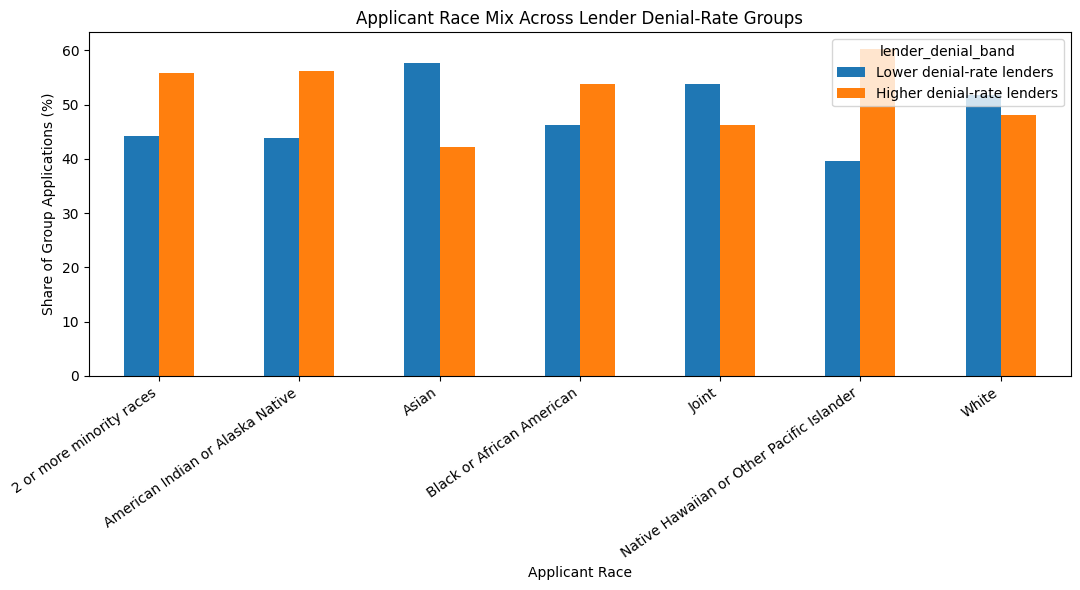

F8 completed.


In [116]:

# ============================================================
# F8. RACE-MIX SORTING AND LENDER STANDARDIZATION
# ============================================================

# ------------------------------------------------------------
# Step 1: Aggregate lender-level counts by applicant race
# ------------------------------------------------------------

F8_COUNTS = (
    F_LENDER_BASE
    .filter(
        F.col("lei").isNotNull()
        & F.col("derived_race").isNotNull()
    )
    .groupBy(
        "lei",
        F.col("derived_race").alias("race_group")
    )
    .agg(
        F.count("*").alias("n_apps"),
        F.sum(
            F.col("is_denied").cast("long")
        ).alias("n_denied")
    )
    .withColumn(
        "race_denial_rate",
        F.col("n_denied") / F.col("n_apps")
    )
)

# ------------------------------------------------------------
# Step 2: Calculate median lender denial rate
# ------------------------------------------------------------

F8_ELIGIBLE_LENDERS = F6_LENDER.filter(
    F.col("low_n") == False
)

F8_MEDIAN_VALUES = F8_ELIGIBLE_LENDERS.approxQuantile(
    "denial_rate",
    [0.5],
    0.001
)

assert len(F8_MEDIAN_VALUES) == 1, (
    "Cannot calculate median lender denial rate."
)

F8_MEDIAN_DENIAL = F8_MEDIAN_VALUES[0]

print(
    "Median eligible lender denial rate:",
    round(F8_MEDIAN_DENIAL * 100, 2),
    "%"
)

# ------------------------------------------------------------
# Step 3: Compare race mix across higher/lower denial lenders
# ------------------------------------------------------------

F8_SORT_BASE = (
    F8_COUNTS
    .join(
        F6_LENDER.select(
            "lei",
            F.col("denial_rate").alias(
                "lender_overall_denial_rate"
            )
        ),
        on="lei",
        how="inner"
    )
    .withColumn(
        "lender_denial_band",
        F.when(
            F.col("lender_overall_denial_rate")
            >= F8_MEDIAN_DENIAL,
            "Higher denial-rate lenders"
        ).otherwise(
            "Lower denial-rate lenders"
        )
    )
)

F8_SORTING = (
    F8_SORT_BASE
    .groupBy(
        "race_group",
        "lender_denial_band"
    )
    .agg(
        F.sum("n_apps").alias("n_apps"),
        F.sum("n_denied").alias("n_denied")
    )
)

F8_RACE_WINDOW = Window.partitionBy("race_group")

F8_SORTING = (
    F8_SORTING
    .withColumn(
        "race_total_apps",
        F.sum("n_apps").over(F8_RACE_WINDOW)
    )
    .withColumn(
        "race_share_pct",
        F.col("n_apps")
        / F.col("race_total_apps") * 100
    )
    .withColumn(
        "denial_rate_pct",
        F.col("n_denied")
        / F.col("n_apps") * 100
    )
    .withColumn(
        "is_headline_race",
        ~F.col("race_group").isin(F_HEADLINE_EXCLUDE)
    )
)

# ------------------------------------------------------------
# Step 4: Identify the White reference group
# ------------------------------------------------------------

F8_WHITE = (
    F8_COUNTS
    .filter(F.col("race_group") == F_REFERENCE)
    .select(
        "lei",
        F.col("n_apps").alias("white_n_apps"),
        F.col("n_denied").alias("white_n_denied"),
        F.col("race_denial_rate").alias("white_denial_rate")
    )
)

# ------------------------------------------------------------
# Step 5: Join each racial group with White within lender
# ------------------------------------------------------------

F8_COMMON = (
    F8_COUNTS
    .filter(F.col("race_group") != F_REFERENCE)
    .join(
        F8_WHITE,
        on="lei",
        how="inner"
    )
    .filter(
        (F.col("n_apps") >= F_N_MIN_APPS)
        & (F.col("n_denied") >= F_N_MIN_DENIED)
        & (F.col("white_n_apps") >= F_N_MIN_APPS)
        & (F.col("white_n_denied") >= F_N_MIN_DENIED)
    )
)

# ------------------------------------------------------------
# Step 6: Calculate fixed pooled lender weights
# ------------------------------------------------------------

F8_COMMON = (
    F8_COMMON
    .withColumn(
        "pooled_lender_apps",
        F.col("n_apps") + F.col("white_n_apps")
    )
)

F8_WEIGHT_WINDOW = Window.partitionBy("race_group")

F8_COMMON = (
    F8_COMMON
    .withColumn(
        "total_pooled_apps",
        F.sum("pooled_lender_apps").over(
            F8_WEIGHT_WINDOW
        )
    )
    .withColumn(
        "fixed_lender_weight",
        F.col("pooled_lender_apps")
        / F.col("total_pooled_apps")
    )
    .withColumn(
        "within_lender_gap_pp",
        (
            F.col("race_denial_rate")
            - F.col("white_denial_rate")
        ) * 100
    )
    .withColumn(
        "weighted_gap_component_pp",
        F.col("fixed_lender_weight")
        * F.col("within_lender_gap_pp")
    )
)

# ------------------------------------------------------------
# Step 7: Calculate raw and standardized gaps
# ------------------------------------------------------------

F8_STANDARDIZED = (
    F8_COMMON
    .groupBy("race_group")
    .agg(
        F.countDistinct("lei").alias(
            "n_common_support_lenders"
        ),
        F.sum("n_apps").alias("group_apps"),
        F.sum("n_denied").alias("group_denied"),
        F.sum("white_n_apps").alias("white_apps"),
        F.sum("white_n_denied").alias("white_denied"),
        F.sum("weighted_gap_component_pp").alias(
            "within_lender_standardised_gap_pp"
        ),
        F.sum(
            F.col("fixed_lender_weight")
            * F.col("race_denial_rate")
        ).alias("standardised_group_rate"),
        F.sum(
            F.col("fixed_lender_weight")
            * F.col("white_denial_rate")
        ).alias("standardised_white_rate")
    )
    .withColumn(
        "raw_group_rate",
        F.col("group_denied") / F.col("group_apps")
    )
    .withColumn(
        "raw_white_rate",
        F.col("white_denied") / F.col("white_apps")
    )
    .withColumn(
        "raw_gap_common_support_pp",
        (
            F.col("raw_group_rate")
            - F.col("raw_white_rate")
        ) * 100
    )
    .withColumn(
        "standardised_group_rate_pct",
        F.col("standardised_group_rate") * 100
    )
    .withColumn(
        "standardised_white_rate_pct",
        F.col("standardised_white_rate") * 100
    )
    .withColumn(
        "between_lender_component_pp",
        F.col("raw_gap_common_support_pp")
        - F.col("within_lender_standardised_gap_pp")
    )
    .withColumn(
        "is_headline_race",
        ~F.col("race_group").isin(F_HEADLINE_EXCLUDE)
    )
    .orderBy("race_group")
)

# ------------------------------------------------------------
# Step 8: Validate decomposition identity
# ------------------------------------------------------------

F8_CHECK = (
    F8_STANDARDIZED
    .withColumn(
        "decomposition_error",
        F.abs(
            F.col("raw_gap_common_support_pp")
            - F.col("within_lender_standardised_gap_pp")
            - F.col("between_lender_component_pp")
        )
    )
)

assert (
    F8_CHECK
    .filter(F.col("decomposition_error") > 1e-8)
    .limit(1)
    .count() == 0
), "F8 decomposition identity failed."

# ------------------------------------------------------------
# Step 9: Export race-sorting and standardized-gap tables
# ------------------------------------------------------------

F8_SORTING_PDF = f_export_spark_table(
    F8_SORTING,
    "B15_rq3_lender_race_sorting.csv",
    max_rows=10000
)

F8_STANDARDIZED_PDF = f_export_spark_table(
    F8_STANDARDIZED,
    "B15_rq3_lender_standardised_gap.csv",
    max_rows=10000
)

# ------------------------------------------------------------
# Step 10: Visualize race mix across lender groups
# ------------------------------------------------------------

F8_PLOT = F8_SORTING_PDF[
    F8_SORTING_PDF["is_headline_race"] == True
].copy()

if not F8_PLOT.empty:

    F8_PIVOT = F8_PLOT.pivot(
        index="race_group",
        columns="lender_denial_band",
        values="race_share_pct"
    ).fillna(0)

    F8_PIVOT = F8_PIVOT.reindex(
        columns=[
            "Lower denial-rate lenders",
            "Higher denial-rate lenders"
        ]
    )

    ax = F8_PIVOT.plot(
        kind="bar",
        figsize=(11, 6)
    )

    ax.set_title(
        "Applicant Race Mix Across Lender Denial-Rate Groups"
    )
    ax.set_xlabel("Applicant Race")
    ax.set_ylabel("Share of Group Applications (%)")

    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIGURE_DIR,
            "B15_F8_lender_race_sorting.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("F8 completed.")



## F9. Lender-Level Racial Gap Distribution

### Objective
Examine the distribution of racial denial-rate gaps across individual lenders and identify how frequently lender-level gaps are positive or negative.

### Input
- F8 lender × race aggregates.
- White reference-group denial rates.
- D-M minimum-cell thresholds.

### Process
1. Restrict to lenders where both the applicant racial group and White meet D-M.
2. Calculate within-lender denial-rate gaps in percentage points.
3. Assign anonymous lender IDs.
4. Calculate the distribution of lender-level gaps by racial group.
5. Calculate the number and share of lenders with positive, negative, and zero gaps.
6. Generate a histogram of eligible lender-level gaps.

### Output
- `B15_rq3_lender_gap_distribution.csv`
- `B15_rq3_lender_gap_distribution_summary.csv`
- Lender-level gap histogram.

### Interpretation
A positive lender-level gap indicates that the applicant racial group has a higher denial rate than White applicants within that lender. A negative gap indicates the opposite.

The distribution describes variation across eligible lenders and should not be interpreted as a causal estimate.


Exported: B15_rq3_lender_gap_distribution.csv | 340 rows
Exported: B15_rq3_lender_gap_distribution_summary.csv | 6 rows


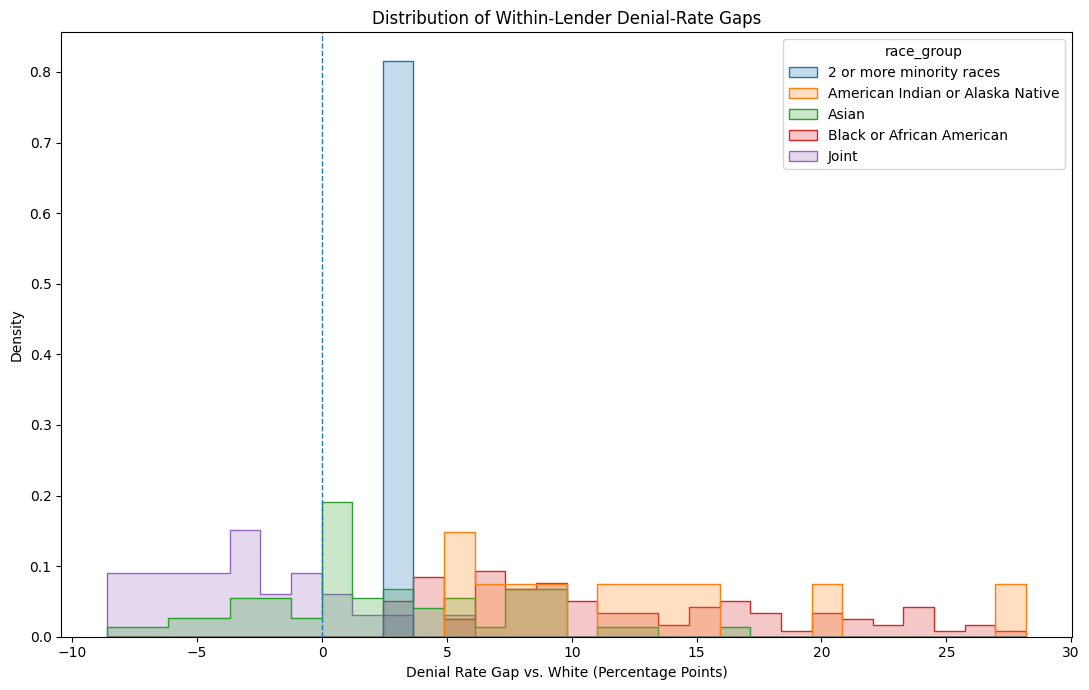


F9 lender gap summary:
                      race_group  n_eligible_lenders  mean_gap_pp  median_gap_pp  std_gap_pp  min_gap_pp  max_gap_pp  n_positive_lenders  n_negative_lenders  n_zero_lenders  positive_lender_share_pct  negative_lender_share_pct  zero_lender_share_pct  is_headline_race
        2 or more minority races                   1       3.1290         3.1290         NaN      3.1290      3.1290                   1                   0               0                   100.0000                     0.0000                 0.0000              True
American Indian or Alaska Native                  11      12.2454        11.3591      6.9895      5.1419     28.1869                  11                   0               0                   100.0000                     0.0000                 0.0000              True
                           Asian                  60       2.4635         1.1073      5.0741     -8.3310     16.3341                  44                  16               0

In [117]:

import seaborn as sns
# ============================================================
# F9. LENDER-LEVEL GAP DISTRIBUTION
# ============================================================

# ------------------------------------------------------------
# Step 1: Prepare eligible lender-level racial gaps
# ------------------------------------------------------------

F9_DETAIL = (
    F8_COMMON
    .join(
        F_LENDER_ID_MAP,
        on="lei",
        how="left"
    )
    .withColumn(
        "gap_pp",
        F.col("within_lender_gap_pp")
    )
    .withColumn(
        "gap_direction",
        F.when(F.col("gap_pp") > 0, "Positive")
        .when(F.col("gap_pp") < 0, "Negative")
        .otherwise("Zero")
    )
    .withColumn(
        "is_headline_race",
        ~F.col("race_group").isin(F_HEADLINE_EXCLUDE)
    )
)

# ------------------------------------------------------------
# Step 2: Export anonymized lender-level detail
# ------------------------------------------------------------

F9_EXPORT = (
    F9_DETAIL
    .select(
        "lender_id",
        "race_group",
        "n_apps",
        "n_denied",
        "race_denial_rate",
        "white_n_apps",
        "white_n_denied",
        "white_denial_rate",
        "gap_pp",
        "gap_direction",
        "fixed_lender_weight",
        "is_headline_race"
    )
    .orderBy("race_group", "gap_pp")
)

F9_DETAIL_PDF = f_export_spark_table(
    F9_EXPORT,
    "B15_rq3_lender_gap_distribution.csv",
    max_rows=100000
)

# ------------------------------------------------------------
# Step 3: Calculate gap-distribution statistics
# ------------------------------------------------------------

F9_SUMMARY = (
    F9_DETAIL
    .groupBy("race_group")
    .agg(
        F.countDistinct("lei").alias("n_eligible_lenders"),
        F.avg("gap_pp").alias("mean_gap_pp"),
        F.expr(
            "percentile_approx(gap_pp, 0.5, 10000)"
        ).alias("median_gap_pp"),
        F.stddev("gap_pp").alias("std_gap_pp"),
        F.min("gap_pp").alias("min_gap_pp"),
        F.max("gap_pp").alias("max_gap_pp"),
        F.sum(
            F.when(F.col("gap_direction") == "Positive", 1)
            .otherwise(0)
        ).alias("n_positive_lenders"),
        F.sum(
            F.when(F.col("gap_direction") == "Negative", 1)
            .otherwise(0)
        ).alias("n_negative_lenders"),
        F.sum(
            F.when(F.col("gap_direction") == "Zero", 1)
            .otherwise(0)
        ).alias("n_zero_lenders")
    )
    .withColumn(
        "positive_lender_share_pct",
        F.col("n_positive_lenders")
        / F.col("n_eligible_lenders") * 100
    )
    .withColumn(
        "negative_lender_share_pct",
        F.col("n_negative_lenders")
        / F.col("n_eligible_lenders") * 100
    )
    .withColumn(
        "zero_lender_share_pct",
        F.col("n_zero_lenders")
        / F.col("n_eligible_lenders") * 100
    )
    .withColumn(
        "is_headline_race",
        ~F.col("race_group").isin(F_HEADLINE_EXCLUDE)
    )
    .orderBy("race_group")
)

# ------------------------------------------------------------
# Step 4: Validate distribution shares
# ------------------------------------------------------------

assert (
    F9_SUMMARY
    .filter(
        F.abs(
            F.col("positive_lender_share_pct")
            + F.col("negative_lender_share_pct")
            + F.col("zero_lender_share_pct")
            - 100
        ) > 1e-6
    )
    .limit(1)
    .count() == 0
), "F9 lender-gap shares do not sum to 100%."

# ------------------------------------------------------------
# Step 5: Export summary
# ------------------------------------------------------------

F9_SUMMARY_PDF = f_export_spark_table(
    F9_SUMMARY,
    "B15_rq3_lender_gap_distribution_summary.csv",
    max_rows=10000
)

# ------------------------------------------------------------
# Step 6: Plot lender-level gap distributions
# ------------------------------------------------------------

F9_PLOT = F9_DETAIL_PDF[
    F9_DETAIL_PDF["is_headline_race"] == True
].copy()

if not F9_PLOT.empty:

    fig, ax = plt.subplots(figsize=(11, 7))

    sns.histplot(
        data=F9_PLOT,
        x="gap_pp",
        hue="race_group",
        bins=30,
        element="step",
        stat="density",
        common_norm=False,
        ax=ax
    )

    ax.axvline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_title(
        "Distribution of Within-Lender Denial-Rate Gaps"
    )
    ax.set_xlabel("Denial Rate Gap vs. White (Percentage Points)")
    ax.set_ylabel("Density")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIGURE_DIR,
            "B15_F9_lender_gap_distribution.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

else:
    print("No eligible lender-level gaps for visualization.")

print("\nF9 lender gap summary:")
print(F9_SUMMARY_PDF.to_string(index=False))

print("F9 completed.")



## F10. Exempt Filers by Lender Size

### Objective
Investigate how full and partial exemption patterns vary across lender-size categories and whether exemption status is associated with different denial rates and missing-data patterns.

### Input
Full S0:
- `lender_size_bucket`
- `is_exempt_filer`
- `is_partial_exempt`
- `is_denied`

### Process
1. Classify applications into full-exempt, partial-exempt, non-exempt, and missing-classification groups.
2. Aggregate application and denial counts by lender-size bucket and exemption status.
3. Calculate exemption-status shares within each lender-size bucket.
4. Calculate denial rates for each exemption category.
5. Quantify missingness in the two exemption flags.
6. Compare exemption patterns across lender sizes.

### Output
- `B15_rq3_exempt_by_lender_size.csv`
- Exemption distribution by lender-size chart.

### Methodological Notes
`is_exempt_filer` and `is_partial_exempt` are existing B07-derived flags based on the documented 28-field exemption rule.

The analysis does not recalculate exemption status or interpret missing fields as zero. Full and partial exemption remain separate categories.


F10 exported: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq3_exempt_by_lender_size.csv | Rows: 8


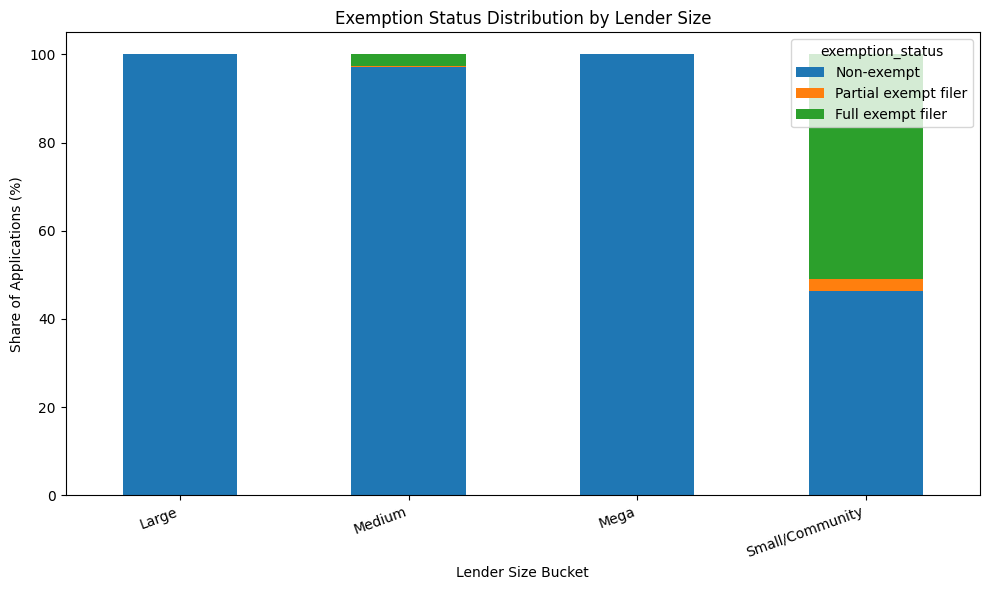


F10 exemption summary:
lender_size_bucket     exemption_status  n_apps  n_denied  denial_rate_pct  share_within_bucket_pct  bucket_total_apps  missing_classification_apps  missing_classification_share_pct  n_exempt_flag_missing  exempt_flag_missing_pct  n_partial_flag_missing  partial_flag_missing_pct  low_n
             Large           Non-exempt 2359123    505961          21.4470                 100.0000            2359123                            0                            0.0000                      0                   0.0000                       0                    0.0000  False
            Medium    Full exempt filer   38116      8906          23.3655                   2.5648            1486101                            0                            0.0000                      0                   0.0000                       0                    0.0000  False
            Medium           Non-exempt 1443702    255337          17.6863                  97.1470            1486

In [118]:

# ============================================================
# F10. EXEMPT FILERS BY LENDER SIZE
# ============================================================

# ------------------------------------------------------------
# Step 1: Prepare exemption flags
# ------------------------------------------------------------

F10_BASE = (
    F_LENDER_BASE
    .withColumn(
        "exempt_flag",
        F.col("is_exempt_filer").cast("boolean")
    )
    .withColumn(
        "partial_flag",
        F.col("is_partial_exempt").cast("boolean")
    )
    .withColumn(
        "lender_size_bucket",
        F.coalesce(
            F.col("lender_size_bucket").cast("string"),
            F.lit("Missing bucket")
        )
    )
)

# ------------------------------------------------------------
# Step 2: Check exemption flag consistency
# ------------------------------------------------------------

F10_OVERLAP = (
    F10_BASE
    .filter(
        (F.col("exempt_flag") == True)
        & (F.col("partial_flag") == True)
    )
    .limit(1)
    .count()
)

assert F10_OVERLAP == 0, (
    "Full and partial exemption flags overlap."
)

# ------------------------------------------------------------
# Step 3: Classify exemption status
# ------------------------------------------------------------

F10_BASE = F10_BASE.withColumn(
    "exemption_status",
    F.when(
        F.col("exempt_flag") == True,
        "Full exempt filer"
    )
    .when(
        F.col("partial_flag") == True,
        "Partial exempt filer"
    )
    .when(
        (F.col("exempt_flag") == False)
        & (F.col("partial_flag") == False),
        "Non-exempt"
    )
    .otherwise("Missing classification")
)

# ------------------------------------------------------------
# Step 4: Aggregate by lender size and exemption status
# ------------------------------------------------------------

F10_SUMMARY = (
    F10_BASE
    .groupBy(
        "lender_size_bucket",
        "exemption_status"
    )
    .agg(
        F.count("*").alias("n_apps"),
        F.sum(
            F.col("is_denied").cast("long")
        ).alias("n_denied")
    )
    .withColumn(
        "denial_rate_pct",
        F.col("n_denied")
        / F.col("n_apps") * 100
    )
)

# ------------------------------------------------------------
# Step 5: Calculate exemption shares within lender size
# ------------------------------------------------------------

F10_BUCKET_WINDOW = Window.partitionBy(
    "lender_size_bucket"
)

F10_SUMMARY = (
    F10_SUMMARY
    .withColumn(
        "bucket_total_apps",
        F.sum("n_apps").over(F10_BUCKET_WINDOW)
    )
    .withColumn(
        "share_within_bucket_pct",
        F.col("n_apps")
        / F.col("bucket_total_apps") * 100
    )
    .withColumn(
        "missing_classification_apps",
        F.sum(
            F.when(
                F.col("exemption_status")
                == "Missing classification",
                F.col("n_apps")
            ).otherwise(0)
        ).over(F10_BUCKET_WINDOW)
    )
    .withColumn(
        "missing_classification_share_pct",
        F.col("missing_classification_apps")
        / F.col("bucket_total_apps") * 100
    )
)

# ------------------------------------------------------------
# Step 6: Measure missingness of individual flags
# ------------------------------------------------------------

F10_MISSINGNESS = (
    F10_BASE
    .groupBy("lender_size_bucket")
    .agg(
        F.count("*").alias("bucket_apps"),
        F.sum(
            F.when(F.col("exempt_flag").isNull(), 1)
            .otherwise(0)
        ).alias("n_exempt_flag_missing"),
        F.sum(
            F.when(F.col("partial_flag").isNull(), 1)
            .otherwise(0)
        ).alias("n_partial_flag_missing")
    )
    .withColumn(
        "exempt_flag_missing_pct",
        F.col("n_exempt_flag_missing")
        / F.col("bucket_apps") * 100
    )
    .withColumn(
        "partial_flag_missing_pct",
        F.col("n_partial_flag_missing")
        / F.col("bucket_apps") * 100
    )
)

# ------------------------------------------------------------
# Step 7: Combine exemption and missingness metrics
# ------------------------------------------------------------

F10_FINAL = (
    F10_SUMMARY
    .join(
        F10_MISSINGNESS,
        on="lender_size_bucket",
        how="left"
    )
    .withColumn(
        "low_n",
        (F.col("n_apps") < F_N_MIN_APPS)
        | (F.col("n_denied") < F_N_MIN_DENIED)
    )
    .select(
        "lender_size_bucket",
        "exemption_status",
        "n_apps",
        "n_denied",
        "denial_rate_pct",
        "share_within_bucket_pct",
        "bucket_total_apps",
        "missing_classification_apps",
        "missing_classification_share_pct",
        "n_exempt_flag_missing",
        "exempt_flag_missing_pct",
        "n_partial_flag_missing",
        "partial_flag_missing_pct",
        "low_n"
    )
    .orderBy(
        "lender_size_bucket",
        "exemption_status"
    )
)

# ------------------------------------------------------------
# Step 8: Validate shares and denial rates
# ------------------------------------------------------------

F10_SHARE_CHECK = (
    F10_FINAL
    .groupBy("lender_size_bucket")
    .agg(
        F.sum("share_within_bucket_pct").alias(
            "total_share_pct"
        )
    )
)

assert (
    F10_SHARE_CHECK
    .filter(
        F.abs(F.col("total_share_pct") - 100) > 1e-6
    )
    .limit(1)
    .count() == 0
), "F10 exemption shares do not sum to 100%."

assert (
    F10_FINAL
    .filter(
        (F.col("denial_rate_pct") < 0)
        | (F.col("denial_rate_pct") > 100)
    )
    .limit(1)
    .count() == 0
), "Invalid F10 denial rate."


# ------------------------------------------------------------
# Step 9: Export results
# Self-contained JVM JSON export
# ------------------------------------------------------------

import os
import json
import pandas as pd

F10_COLUMNS = F10_FINAL.columns

F10_RAW_JSON = (
    F10_FINAL
    .limit(10000)
    ._jdf.toJSON()
    .collect()
)

F10_RECORDS = [
    json.loads(str(row))
    for row in F10_RAW_JSON
]

F10_PDF = pd.DataFrame(
    F10_RECORDS,
    columns=F10_COLUMNS
)

F10_PATH = os.path.join(
    os.fspath(OUTPUT_DIR),
    "B15_rq3_exempt_by_lender_size.csv"
)

F10_PDF.to_csv(
    F10_PATH,
    index=False,
    encoding="utf-8-sig"
)

assert os.path.exists(F10_PATH), (
    "F10 export failed."
)

print(
    "F10 exported:",
    F10_PATH,
    "| Rows:",
    f"{len(F10_PDF):,}"
)


# ------------------------------------------------------------
# Step 10: Visualize exemption distribution
# ------------------------------------------------------------

F10_PIVOT = (
    F10_PDF
    .pivot(
        index="lender_size_bucket",
        columns="exemption_status",
        values="share_within_bucket_pct"
    )
    .fillna(0)
)

F10_STATUS_ORDER = [
    "Non-exempt",
    "Partial exempt filer",
    "Full exempt filer",
    "Missing classification"
]

F10_PIVOT = F10_PIVOT.reindex(
    columns=[
        c for c in F10_STATUS_ORDER
        if c in F10_PIVOT.columns
    ]
)

ax = F10_PIVOT.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

ax.set_title(
    "Exemption Status Distribution by Lender Size"
)
ax.set_xlabel("Lender Size Bucket")
ax.set_ylabel("Share of Applications (%)")

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "B15_F10_exempt_by_lender_size.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nF10 exemption summary:")
print(F10_PDF.to_string(index=False))

print("F10 completed.")


# PART G — ROBUSTNESS PREVIEW AND MISSING-VARIABLE INVENTORY

## G0. Shared Foundation and Analytical Setup

### Objective
Establish shared analytical helpers and reference definitions for the robustness and sensitivity analyses in Part G.

### Input
- `df_s0`: B07 analytical dataset (S0).
- `df_all_min`: B07 clean-all audit dataset, where available.
- Existing output and figure directories from Section 0.

### Process
1. Validate the required analytical dataset and variables.
2. Define the White reference group and minimum sample-size thresholds.
3. Create reusable Boolean flag and sample-selection functions.
4. Resolve S5 and RQ3 samples using existing B07 definitions.
5. Establish a bounded CSV export helper.

### Output
Reusable functions and analytical settings for G1–G5.

**Methodological note:** This section does not modify the original S0 dataset or introduce additional cleaning rules. All subsequent sensitivity analyses operate on separate derived DataFrames.

## G1. Sample Sensitivity Matrix and G3. Outcome Definition Sensitivity

### Objective
Assess whether the observed racial denial-rate differences remain stable under alternative sample-selection criteria and outcome definitions.

### Input
- Original S0 analytical sample.
- S5 samples based on B07 validation flags.
- Financially complete sample.
- RQ3 valid-census-tract sample.
- Duplicate and exemption flags.
- Original denial outcome and `action_taken`.

### Process

**G1 — Sample Sensitivity**

Compare the following sample specifications:

1. S0 baseline.
2. S5 all.
3. S5 keep V02.
4. Financial complete.
5. RQ3 valid-tract sample.
6. Without duplicate extras.
7. Without exempt filers.
8. Without partial-exempt filers.
9. Without Race Not Available.

For each specification, calculate:
- Application count.
- Number of denied applications.
- Denial rate.
- Denial-rate gap against White.
- Odds ratio against White.
- Low-sample indicator.

**G3 — Outcome Definition Sensitivity**

Compare two outcome definitions:

- Original definition: Action 1, 2, and 3 are retained, with action 2 treated as non-denied.
- Alternative definition: Only action 1 and 3 are retained, excluding action 2 from the denominator.

The alternative outcome is evaluated on the original S0 sample to isolate the effect of outcome definition.

### Output
- `B15_rq4_sample_sensitivity.csv`
- Figure 33: Racial Denial Gap Across Sample and Outcome Specifications.

### Interpretation
Evaluate whether racial denial-rate gaps retain their direction and approximate magnitude across alternative sample specifications. Identify scenarios where the observed differences are sensitive to sample selection or outcome definition.


## G0.1 — Validate Part G dependencies

- **Input:** Part 0 objects, S0 and the version-specific output paths.
- **Process:** Verify the Spark session, mandatory fields, analytical settings and output directories.
- **Output:** Validated Part G configuration.

Part G must not modify the original S0 population.


In [119]:

# Step 1: Validate Part 0 dependencies

from pathlib import Path
from functools import reduce
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

required_objects = ["spark", "df_s0", "OUTPUT_DIR", "FIGURE_DIR"]
missing_objects = [x for x in required_objects if x not in globals()]
assert not missing_objects, f"Missing objects: {missing_objects}"

required_columns = ["derived_race", "is_denied", "action_taken"]
missing_columns = [x for x in required_columns if x not in df_s0.columns]
assert not missing_columns, f"Missing S0 columns: {missing_columns}"

G_REFERENCE = "White"
G_N_MIN_APPS = int(N_MIN_APPS)
G_N_MIN_DENIED = int(N_MIN_DENIED)
G_OUTPUT_DIR = Path(OUTPUT_DIR)
G_FIGURE_DIR = Path(FIGURE_DIR)

# Step 2: Validate configured output directories
assert G_OUTPUT_DIR == Path(OUTPUT_DIR)
assert G_FIGURE_DIR == Path(FIGURE_DIR)

G_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
G_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("G0 dependencies validated.")
print("Output:", G_OUTPUT_DIR)


G0 dependencies validated.
Output: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output



## G0.2 — Validate the race reference and outcome

- **Input:** S0 race and outcome fields.
- **Process:** Confirm that White exists and the denial outcome is binary.
- **Output:** Reference-group and outcome validation.

A missing reference group or invalid target value must stop execution.


In [120]:

# Step 1: Validate the White reference group

white_n = (
    df_s0
    .filter(F.col("derived_race") == G_REFERENCE)
    .count()
)

assert white_n > 0, "White reference group is absent."

# Step 2: Validate the denial outcome

invalid_outcome_n = (
    df_s0
    .filter(
        F.col("is_denied").isNull()
        | ~F.col("is_denied").cast("string").isin("0", "1")
    )
    .count()
)

assert invalid_outcome_n == 0, (
    f"Invalid denial outcomes: {invalid_outcome_n:,}"
)

print("White reference applications:", f"{white_n:,}")
print("Invalid denial outcomes:", invalid_outcome_n)


White reference applications: 5,360,624
Invalid denial outcomes: 0



## G0.3 — Normalize existing Boolean flags

- **Input:** Existing B07 flag columns.
- **Process:** Interpret recognized true and false representations without converting unknown values to false.
- **Output:** A reusable Spark Boolean expression.

Unknown flag values are retained as NULL until their treatment is explicitly specified.


In [121]:

# Step 1: Define a NULL-preserving Boolean helper

def g_bool(flag_name):
    """Interpret an existing B07 flag without hiding unknown values."""

    value = F.lower(F.trim(F.col(flag_name).cast("string")))

    return (
        F.when(value.isin("1", "true", "yes", "y"), True)
        .when(value.isin("0", "false", "no", "n"), False)
        .otherwise(F.lit(None).cast("boolean"))
    )



## G0.4 — Attach missing B07 audit columns

- **Input:** S0 and optional `df_all_min`.
- **Process:** Join missing audit fields through `row_id`, validating uniqueness and match coverage.
- **Output:** A DataFrame containing the requested audit columns.

The join must not duplicate or silently discard S0 records.


In [122]:

# Step 1: Define validated audit-column attachment

def g_attach_audit_cols(base, requested):
    """Attach uniquely keyed B07 audit fields to S0."""

    missing = [c for c in requested if c not in base.columns]
    if not missing:
        return base

    audit = globals().get("df_all_min")
    if audit is None or "row_id" not in base.columns:
        raise ValueError(f"Audit source or row_id unavailable: {missing}")

    if "row_id" not in audit.columns:
        raise ValueError("Audit source has no row_id.")

    unavailable = [c for c in missing if c not in audit.columns]
    if unavailable:
        raise ValueError(f"Missing audit columns: {unavailable}")

    lookup = audit.select("row_id", *missing)
    duplicates = lookup.groupBy("row_id").count().filter("count > 1")
    assert duplicates.limit(1).count() == 0, "Duplicate audit row_id."

    return base.join(lookup, on="row_id", how="left")



## G0.5 — Validate audit join coverage

- **Input:** Base DataFrame, attached audit fields and `row_id`.
- **Process:** Compare record counts and check unmatched identifiers.
- **Output:** Join coverage diagnostics.

A left join can preserve row counts while still leaving unmatched identifiers. Both conditions must therefore be checked.


In [123]:

# Step 1: Define an audit join validation helper

def g_validate_audit_join(base, attached, added_columns):
    """Confirm row preservation and audit-field coverage."""

    before_n = base.count()
    after_n = attached.count()
    assert before_n == after_n, "Audit join changed row count."

    if added_columns:
        unmatched = attached.filter(
            reduce(
                lambda a, b: a & b,
                [F.col(c).isNull() for c in added_columns]
            )
        ).count()
        print("Rows with all attached fields NULL:", f"{unmatched:,}")
        if unmatched:
            raise ValueError("Audit join coverage requires investigation.")

    print("Audit join rows:", f"{before_n:,}", "→", f"{after_n:,}")



## G0.6 — Apply an existing sample flag

- **Input:** A source DataFrame and an existing B07 Boolean flag.
- **Process:** Attach the flag where necessary, validate its values and select the requested sensitivity population.
- **Output:** A filtered analytical scenario without modifying S0.

Filtering here is scenario-specific sensitivity selection, not a revision to the B07 cleaning pipeline.


In [124]:

# Step 1: Define the sensitivity-sample selector

def g_filter_flag(base, flag_name, keep_flag=True):
    """Select a sensitivity population using an approved B07 flag."""

    attached = g_attach_audit_cols(base, [flag_name])

    if flag_name not in base.columns:
        g_validate_audit_join(base, attached, [flag_name])

    invalid_n = attached.filter(g_bool(flag_name).isNull()).count()
    if invalid_n:
        raise ValueError(
            f"{flag_name} has {invalid_n:,} missing/unknown values."
        )

    condition = g_bool(flag_name)
    selected = attached.filter(condition if keep_flag else ~condition)

    print(
        f"{flag_name} ({keep_flag}): "
        f"{attached.count():,} → {selected.count():,}"
    )
    return selected



## G0.7 — Resolve the two existing S5 populations

- **Input:** B07 S5 membership flags.
- **Process:** Select S5-all and S5-keep-V02 using their original B07 definitions.
- **Output:** A reusable S5 selection helper.

Do not reconstruct the S5 population from an incomplete list of validation flags.


In [125]:

# Step 1: Define the accepted S5 sample identifiers

G_S5_FLAGS = {
    "S5 all": "in_s5_all",
    "S5 keep V02": "in_s5_keep_v02"
}

# Step 2: Define the S5 sample helper

def g_s5_sample(sample_name):
    """Select S5 using the original B07 sample-membership flag."""

    if sample_name not in G_S5_FLAGS:
        raise ValueError(f"Unknown S5 scenario: {sample_name}")

    return g_filter_flag(
        df_s0,
        G_S5_FLAGS[sample_name],
        keep_flag=True
    )



## G0.8 — Resolve financial and geographic analytical populations

- **Input:** Existing B07 financial-completeness flags and the RQ3 analytical frame.
- **Process:** Reuse previously established membership definitions.
- **Output:** Financial-complete and valid-tract sensitivity samples.

A missing membership definition must not be silently replaced by a newly constructed proxy.


In [126]:

# Step 1: Select financial-complete observations

def g_fin_complete():
    """Use the approved B07 financial-completeness definition."""

    return g_filter_flag(df_s0, "fin_complete", keep_flag=True)


# Step 2: Select the previously constructed RQ3 population

def g_rq3_sample():
    """Reuse the existing Part F RQ3 analytical population."""

    if "df_f_rq3" not in globals():
        raise ValueError(
            "df_f_rq3 is unavailable. "
            "Verify that Part F has been executed."
        )

    return df_f_rq3


## G0.9 — Export bounded analytical summaries

- **Input:** A small Spark summary table and its target filename.
- **Process:** Enforce an explicit row limit, collect the summary to Pandas and save it in the version-specific output folder.
- **Output:** CSV file with path, file size and dimensions.

Never silently truncate a result before export.


In [127]:

# Step 1: Define a bounded summary exporter

def g_save_small(sdf, filename, max_rows=100_000):
    """Export a bounded Spark summary without silent truncation."""

    row_count = sdf.count()
    if row_count > max_rows:
        raise ValueError(f"{filename}: {row_count:,} rows exceed limit.")

    pdf = sdf.toPandas()
    path = G_OUTPUT_DIR / filename
    pdf.to_csv(path, index=False, encoding="utf-8")

    report_saved_file(path, *pdf.shape)
    return pdf



## G0.10 — Foundation status

- **Input:** The validated Part G configuration.
- **Process:** Report shared settings and available analytical objects.
- **Output:** A compact G0 readiness report.

This status does not imply that all sensitivity scenarios have already been validated.


In [128]:

# Step 1: Report Part G configuration

g0_status = pd.DataFrame([
    ("Reference group", G_REFERENCE),
    ("Minimum applications", G_N_MIN_APPS),
    ("Minimum denied", G_N_MIN_DENIED),
    ("S0 available", "Yes"),
    ("Audit frame available", globals().get("df_all_min") is not None),
    ("RQ3 frame available", "df_rq3" in globals()),
    ("Output directory", str(G_OUTPUT_DIR))
], columns=["setting", "value"])

display(g0_status)
print("[G0 READY] Shared Part G helpers initialized.")


,setting,value
0,Reference group,White
1,Minimum applications,1000
2,Minimum denied,100
3,S0 available,Yes
4,Audit frame available,True
5,RQ3 frame available,False
6,Output directory,D:\H-NEU\004\44 - Big Data\Final project\B15 -...


[G0 READY] Shared Part G helpers initialized.


## G1. Sample Sensitivity Matrix and G3. Outcome Definition Sensitivity

### Objective
Assess whether the observed racial denial-rate differences remain stable under alternative sample-selection criteria and outcome definitions.

### Input
- Original S0 analytical sample.
- S5 samples based on B07 validation flags.
- Financially complete sample.
- RQ3 valid-census-tract sample.
- Duplicate and exemption flags.
- Original denial outcome and `action_taken`.

### Process

**G1 — Sample Sensitivity**

Compare the following sample specifications:

1. S0 baseline.
2. S5 all.
3. S5 keep V02.
4. Financial complete.
5. RQ3 valid-tract sample.
6. Without duplicate extras.
7. Without exempt filers.
8. Without partial-exempt filers.
9. Without Race Not Available.

For each specification, calculate:
- Application count.
- Number of denied applications.
- Denial rate.
- Denial-rate gap against White.
- Odds ratio against White.
- Low-sample indicator.

**G3 — Outcome Definition Sensitivity**

Compare two outcome definitions:

- Original definition: Action 1, 2, and 3 are retained, with action 2 treated as non-denied.
- Alternative definition: Only action 1 and 3 are retained, excluding action 2 from the denominator.

The alternative outcome is evaluated on the original S0 sample to isolate the effect of outcome definition.

### Output
- `B15_rq4_sample_sensitivity.csv`
- Figure 33: Racial Denial Gap Across Sample and Outcome Specifications.

### Interpretation
Evaluate whether racial denial-rate gaps retain their direction and approximate magnitude across alternative sample specifications. Identify scenarios where the observed differences are sensitive to sample selection or outcome definition.


## G1.1 — Prepare the outcome definition

- **Input:** One sensitivity population and the selected outcome specification.
- **Process:** Retain eligible action codes and derive a binary denial indicator.
- **Output:** A standardized scenario DataFrame.

The original outcome uses action codes 1, 2 and 3. The alternative outcome uses 1 and 3 only.


## G1.2 — Aggregate denial counts by race

- **Input:** A scenario with the standardized denial indicator.
- **Process:** Calculate applications, denials and denial rates by race.
- **Output:** A race-level aggregate DataFrame.


In [129]:

# Step 1: Standardize the scenario outcome

def g_prepare_outcome(sdf, definition="123"):
    """Create the denial outcome for one approved specification."""

    if definition not in ("123", "13"):
        raise ValueError("Invalid outcome definition.")

    codes = ["1", "2", "3"] if definition == "123" else ["1", "3"]
    selected = sdf.filter(F.col("action_taken").cast("string").isin(codes))

    denied = (
        F.col("is_denied").cast("double")
        if definition == "123"
        else F.when(F.col("action_taken").cast("string") == "3", 1.0)
              .otherwise(0.0)
    )

    return selected.withColumn("_g_denied", denied)


# Step 2: Define the race aggregation

def g_aggregate_race(sdf):
    """Calculate race-specific denial counts and rates."""

    return (
        sdf.groupBy("derived_race")
        .agg(
            F.count("*").alias("n_apps"),
            F.sum("_g_denied").alias("n_denied")
        )
        .withColumn(
            "denial_rate",
            F.col("n_denied") / F.col("n_apps")
        )
    )



## G1.3 — Extract White reference metrics

- **Input:** Race-level aggregate table.
- **Process:** Retrieve White applications, denials and denial rate.
- **Output:** A validated reference metrics dictionary.

White must have observed applications in every comparable scenario.


## G1.4 — Calculate race gaps and odds ratios

- **Input:** Race-level aggregates and White reference metrics.
- **Process:** Calculate percentage-point differences, odds ratios and low-sample-size indicators.
- **Output:** A comparable race-gap table.

Undefined odds ratios remain NULL.


In [130]:

# Step 1: Define the White reference helper

def g_white_metrics(grouped):
    """Return the White reference counts and denial rate."""

    white = grouped.filter(
        F.col("derived_race") == G_REFERENCE
    ).first()

    if white is None or white["n_apps"] <= 0:
        raise ValueError("White reference is missing.")

    return {
        "white_n": int(white["n_apps"]),
        "white_denied": float(white["n_denied"]),
        "white_rate": float(white["denial_rate"])
    }


# Step 2: Attach reference counts and calculate gaps

def g_add_gap_metrics(grouped, ref):
    """Calculate racial denial gaps and reference-based odds ratios."""

    result = grouped
    for name, value in ref.items():
        result = result.withColumn(name, F.lit(value))

    group_odds = F.when(
        F.col("n_apps") > F.col("n_denied"),
        F.col("n_denied") / (F.col("n_apps") - F.col("n_denied"))
    )
    white_odds = (
        ref["white_denied"] / (ref["white_n"] - ref["white_denied"])
        if 0 < ref["white_denied"] < ref["white_n"] else None
    )

    result = result.withColumn(
        "gap_pp", (F.col("denial_rate") - F.col("white_rate")) * 100
    )
    result = result.withColumn(
        "odds_ratio",
        group_odds / F.lit(white_odds) if white_odds else F.lit(None).cast("double")
    )
    return result



## G1.5 — Flag low-support comparisons

- **Input:** Race-gap results and the approved minimum sample thresholds.
- **Process:** Flag comparisons where either the group or the White reference has insufficient applications or denials.
- **Output:** Results with the `low_n` indicator.


## G1.6 — Assemble one sensitivity scenario

- **Input:** An analytical sample, scenario label, type and outcome definition.
- **Process:** Apply outcome selection, race aggregation, White reference metrics and reliability flags.
- **Output:** A standardized scenario table.


In [131]:

# Step 1: Define the reliability indicator

def g_add_low_n(sdf):
    """Flag comparisons below the established B14 support thresholds."""

    return sdf.withColumn(
        "low_n",
        (F.col("n_apps") < G_N_MIN_APPS)
        | (F.col("n_denied") < G_N_MIN_DENIED)
        | (F.col("white_n") < G_N_MIN_APPS)
        | (F.col("white_denied") < G_N_MIN_DENIED)
    )



# Step 2: Define the scenario calculation wrapper

def g_calculate_gap(sdf, scenario, scenario_type, outcome_definition="123"):
    """Calculate one race-gap sensitivity scenario."""

    prepared = g_prepare_outcome(sdf, outcome_definition)
    grouped = g_aggregate_race(prepared)
    reference = g_white_metrics(grouped)

    totals = grouped.agg(
        F.sum("n_apps").alias("sample_n"),
        F.sum("n_denied").alias("sample_denied")
    ).first()

    result = g_add_gap_metrics(grouped, reference)
    result = g_add_low_n(result)

    metadata = {
        "scenario": scenario,
        "scenario_type": scenario_type,
        "outcome_definition": "{" + ",".join(outcome_definition) + "}",
        "sample_n": int(totals["sample_n"]),
        "sample_denied": float(totals["sample_denied"])
    }
    for name, value in metadata.items():
        result = result.withColumn(name, F.lit(value))

    return result.withColumn(
        "sample_denial_rate",
        F.col("sample_denied") / F.col("sample_n")
    )



## G1.7 — Define the approved sample-sensitivity matrix

- **Input:** S0 and the previously established B07/RQ3 sensitivity populations.
- **Process:** Register the nine original G1 specifications.
- **Output:** A lazy scenario specification list.

Scenario definitions are not changed in this refactor.


## G1.8 — Execute the G1 sample matrix

- **Input:** Nine registered analytical scenarios.
- **Process:** Calculate the race gaps separately for each scenario using the original `{1,2,3}` outcome.
- **Output:** A list of G1 Spark summary tables.


In [132]:

# Step 1: Register the nine original sensitivity specifications

G1_SCENARIOS = [
    ("S0 baseline", lambda: df_s0, "Baseline"),
    ("S5 all", lambda: g_s5_sample("S5 all"), "S5 sensitivity"),
    ("S5 keep V02", lambda: g_s5_sample("S5 keep V02"), "S5 sensitivity"),
    ("Financial complete", g_fin_complete, "Financial selection"),
    ("RQ3 valid-tract sample", g_rq3_sample, "Geographic selection"),
    ("Without duplicate extras",
     lambda: g_filter_flag(df_s0, "flag_dup_extra", False),
     "Duplicate sensitivity"),
    ("Without exempt filers",
     lambda: g_filter_flag(df_s0, "is_exempt_filer", False),
     "Exempt sensitivity"),
    ("Without partial-exempt",
     lambda: g_filter_flag(df_s0, "is_partial_exempt", False),
     "Exempt sensitivity"),
    ("Without Race Not Available",
     lambda: df_s0.filter(F.col("derived_race") != "Race Not Available"),
     "Race classification sensitivity")
]

assert len(G1_SCENARIOS) == 9
print("Registered G1 scenarios:", len(G1_SCENARIOS))



# Step 2: Run all nine G1 scenarios

G1_TABLES = []

for scenario_name, builder, scenario_type in G1_SCENARIOS:
    print("G1:", scenario_name)

    scenario_df = builder()
    scenario_result = g_calculate_gap(
        scenario_df,
        scenario_name,
        scenario_type,
        outcome_definition="123"
    )
    G1_TABLES.append(scenario_result)

assert len(G1_TABLES) == len(G1_SCENARIOS)


Registered G1 scenarios: 9
G1: S0 baseline
G1: S5 all
in_s5_all (True): 8,136,664 → 7,981,245
G1: S5 keep V02
in_s5_keep_v02 (True): 8,136,664 → 8,071,911
G1: Financial complete
fin_complete (True): 8,136,664 → 7,037,363
G1: RQ3 valid-tract sample
G1: Without duplicate extras
flag_dup_extra (False): 8,136,664 → 8,132,165
G1: Without exempt filers
is_exempt_filer (False): 8,136,664 → 7,895,556
G1: Without partial-exempt
is_partial_exempt (False): 8,136,664 → 8,121,372
G1: Without Race Not Available



## G3.1 — Alternative action-code outcome

- **Input:** Original S0.
- **Process:** Restrict outcome analysis to originated (`1`) and denied (`3`) applications, excluding approved-not-accepted applications (`2`).
- **Output:** A tenth scenario using the `{1,3}` outcome definition.


In [133]:

# Step 1: Calculate the G3 alternative-outcome scenario

G3_RESULT = g_calculate_gap(
    df_s0,
    "S0: action 1 and 3 only",
    "Outcome sensitivity",
    outcome_definition="13"
)

print("G3 alternative-outcome scenario prepared.")


G3 alternative-outcome scenario prepared.



## G1.9 — Combine sample and outcome sensitivity

- **Input:** Nine G1 tables and the G3 alternative-outcome table.
- **Process:** Union comparable race-level results and validate the outcome metrics.
- **Output:** `G1_RESULT`, containing all ten sensitivity scenarios.


In [134]:

# Step 1: Combine all scenario-level results

G1_RESULT = reduce(
    lambda left, right: left.unionByName(right),
    G1_TABLES + [G3_RESULT]
)

G1_RESULT = G1_RESULT.orderBy("scenario", "derived_race")

# Step 2: Validate scenario results

assert G1_RESULT.count() > 0
assert G1_RESULT.filter(F.col("gap_pp").isNull()).count() == 0

invalid_rate_n = G1_RESULT.filter(
    (F.col("denial_rate") < 0)
    | (F.col("denial_rate") > 1)
).count()

assert invalid_rate_n == 0
print("G1/G3 validation passed.")


G1/G3 validation passed.



## G1.10 — Export sample sensitivity

- **Input:** Validated `G1_RESULT`.
- **Process:** Export the bounded race-level sensitivity summary.
- **Output:** `B15_rq4_sample_sensitivity.csv`.


In [135]:

# Step 1: Export G1/G3 results

G1_EXPORT = g_save_small(
    G1_RESULT,
    "B15_rq4_sample_sensitivity.csv"
)

display(G1_EXPORT)


[ARTIFACT SAVED] B15_rq4_sample_sensitivity.csv | Size: 19.22 KB (0.02 MB) | Shape: N/A


,derived_race,n_apps,n_denied,denial_rate,white_n,white_denied,white_rate,gap_pp,odds_ratio,low_n,scenario,scenario_type,outcome_definition,sample_n,sample_denied,sample_denial_rate
0,2 or more minority races,17556,"6,105.0000",0.3477,4699459,"922,557.0000",0.1963,15.1433,2.1827,False,Financial complete,Financial selection,"{1,2,3}",7037363,"1,543,743.0000",0.2194
1,American Indian or Alaska Native,49896,"16,376.0000",0.3282,4699459,"922,557.0000",0.1963,13.1891,2.0001,False,Financial complete,Financial selection,"{1,2,3}",7037363,"1,543,743.0000",0.2194
2,Asian,446231,"92,274.0000",0.2068,4699459,"922,557.0000",0.1963,1.0474,1.0673,False,Financial complete,Financial selection,"{1,2,3}",7037363,"1,543,743.0000",0.2194
3,Black or African American,615372,"205,553.0000",0.3340,4699459,"922,557.0000",0.1963,13.7719,2.0534,False,Financial complete,Financial selection,"{1,2,3}",7037363,"1,543,743.0000",0.2194
4,Free Form Text Only,1978,"1,130.0000",0.5713,4699459,"922,557.0000",0.1963,37.4973,5.4554,False,Financial complete,Financial selection,"{1,2,3}",7037363,"1,543,743.0000",0.2194
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,Free Form Text Only,2097,"1,224.0000",0.5837,5348584,"1,173,772.0000",0.2195,36.4236,4.9868,False,Without partial-exempt,Exempt sensitivity,"{1,2,3}",8121372,"2,001,220.0000",0.2464
85,Joint,184335,"36,116.0000",0.1959,5348584,"1,173,772.0000",0.2195,-2.3529,0.8667,False,Without partial-exempt,Exempt sensitivity,"{1,2,3}",8121372,"2,001,220.0000",0.2464
86,Native Hawaiian or Other Pacific Islander,20227,"7,867.0000",0.3889,5348584,"1,173,772.0000",0.2195,16.9481,2.2638,False,Without partial-exempt,Exempt sensitivity,"{1,2,3}",8121372,"2,001,220.0000",0.2464
87,Race Not Available,1273316,"377,869.0000",0.2968,5348584,"1,173,772.0000",0.2195,7.7305,1.5009,False,Without partial-exempt,Exempt sensitivity,"{1,2,3}",8121372,"2,001,220.0000",0.2464



## G1.11 — Figure 33: Sample sensitivity

- **Input:** Exported G1/G3 gap estimates.
- **Process:** Plot the percentage-point gap against White by race and scenario.
- **Output:** `B15_fig_33_sample_sensitivity.png`.


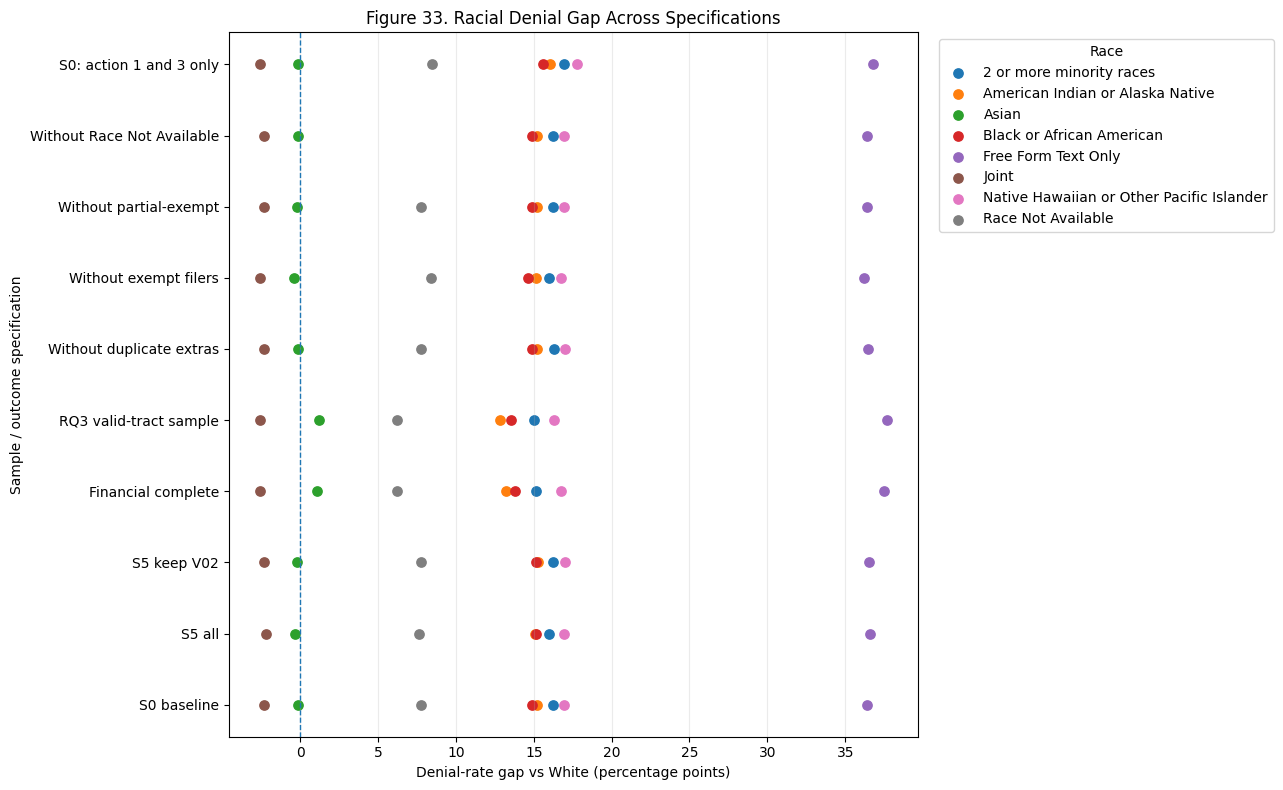

In [136]:

# Step 1: Prepare the scenario ordering

G1_ORDER = [x[0] for x in G1_SCENARIOS]
G1_ORDER.append("S0: action 1 and 3 only")

plot_data = G1_EXPORT[
    G1_EXPORT["derived_race"] != G_REFERENCE
].copy()

plot_data["scenario"] = pd.Categorical(
    plot_data["scenario"], categories=G1_ORDER, ordered=True
)

# Step 2: Plot racial gaps

fig, ax = plt.subplots(figsize=(13, 8))

for race, group in plot_data.groupby("derived_race"):
    ax.scatter(
        group["gap_pp"],
        [G1_ORDER.index(x) for x in group["scenario"]],
        s=45, label=race
    )

ax.axvline(0, linestyle="--", linewidth=1)
ax.set(yticks=range(len(G1_ORDER)), yticklabels=G1_ORDER)
ax.set_xlabel("Denial-rate gap vs White (percentage points)")
ax.set_ylabel("Sample / outcome specification")
ax.set_title("Figure 33. Racial Denial Gap Across Specifications")
ax.legend(title="Race", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()



## G1.12 — Save Figure 33

- **Input:** The completed sample-sensitivity chart.
- **Process:** Export the figure at publication resolution.
- **Output:** Figure 33 in the version-specific `output/figures/` directory.


In [137]:

# Step 1: Save and display Figure 33

g1_figure_path = (
    G_FIGURE_DIR / "B15_fig_33_sample_sensitivity.png"
)

fig.savefig(
    g1_figure_path,
    dpi=300,
    bbox_inches="tight"
)

report_saved_file(g1_figure_path)
plt.show()

print("[G1 + G3 COMPLETED]")


[ARTIFACT SAVED] B15_fig_33_sample_sensitivity.png | Size: 303.56 KB (0.30 MB) | Shape: N/A
[G1 + G3 COMPLETED]


## G2. Special-code Handling Sensitivity

### Objective
Examine how alternative treatments of missing and special-code observations affect the observed racial denial-rate gaps across key financial variables.

### Input
- S0 analytical dataset.
- DTI: `dti_bin_fine`, `dti_status`.
- Income: `income`, `income_status`.
- CLTV: `combined_loan_to_value_ratio`, `combined_loan_to_value_ratio_status`.

### Process

Evaluate three missing-data handling strategies:

1. **Drop Missing:** Exclude observations with missing or special-code status for the variable being analyzed.
2. **Explicit Missing Category:** Retain missing observations as a separate analytical category.
3. **Median Imputation with Missing Indicator:** Replace missing values with the S0 median while preserving a separate missingness indicator.

Apply the strategies to three financial dimensions:

- DTI: Ordered DTI categories, using the weighted median category for imputation.
- Income: Income deciles, using existing B14 cutoffs where available.
- CLTV: Loan-to-value bands, using the S0 median for imputation.

Within each comparable financial stratum, calculate racial denial rates and percentage-point gaps against White.

### Output
- `B15_rq4_missing_handling.csv`

### Interpretation
Assess whether the observed racial denial-rate differences are sensitive to alternative missing-data treatments. Distinguish changes driven by sample exclusion from those associated with retaining or imputing missing observations.

**Methodological note:** Median imputation is used exclusively for sensitivity analysis. It does not replace the original B07 cleaning or missing-data treatment.

### G2.1 — Financial medians

- **Input:** `df_s0` financial columns.
- **Process:** Calculate approximate income and CLTV medians and validate them.
- **Output:** `G2_INCOME_MEDIAN`, `G2_CLTV_MEDIAN`. 


In [138]:
# ------------------------------------------------------------
# Step 1. Resolve financial medians
# ------------------------------------------------------------

G2_INCOME_MEDIAN = df_s0.approxQuantile(
    "income",
    [0.50],
    0.001
)[0]

G2_CLTV_MEDIAN = df_s0.approxQuantile(
    "combined_loan_to_value_ratio",
    [0.50],
    0.001
)[0]

assert G2_INCOME_MEDIAN is not None
assert G2_CLTV_MEDIAN is not None


### G2.2 — DTI category ordering

- **Input:** `dti_bin_fine` values.
- **Process:** Define the numeric-aware sort key for DTI labels.
- **Output:** `g2_dti_sort_key()`. 


In [139]:
# ------------------------------------------------------------
# Step 2. Resolve DTI weighted median category
# ------------------------------------------------------------

def g2_dti_sort_key(value):

    s = str(value).strip().lower()

    if s.startswith("<"):
        return -1

    if s.startswith(">"):
        return 10000

    match = re.search(r"\d+", s)

    if match:
        return int(match.group())

    return 5000


### G2.3 — DTI median category

- **Input:** `df_s0` and `g2_dti_sort_key()`.
- **Process:** Count and sort valid DTI categories, then locate the weighted median.
- **Output:** `G2_DTI_MEDIAN`. 


In [140]:
G2_DTI_COUNTS = (
    df_s0
    .filter(F.col("dti_bin_fine").isNotNull())
    .groupBy("dti_bin_fine")
    .count()
    .collect()
)

G2_DTI_COUNTS = sorted(
    G2_DTI_COUNTS,
    key=lambda x: g2_dti_sort_key(x["dti_bin_fine"])
)

G2_DTI_TOTAL = sum(
    x["count"] for x in G2_DTI_COUNTS
)

assert G2_DTI_TOTAL > 0

G2_DTI_CUMULATIVE = 0
G2_DTI_MEDIAN = None

for item in G2_DTI_COUNTS:

    G2_DTI_CUMULATIVE += item["count"]

    if G2_DTI_CUMULATIVE >= (G2_DTI_TOTAL + 1) / 2:
        G2_DTI_MEDIAN = item["dti_bin_fine"]
        break

assert G2_DTI_MEDIAN is not None


### G2.4 — Income edge lookup

- **Input:** Existing income-decile boundaries, if provided.
- **Process:** Check known in-memory names for nine interior cutoffs.
- **Output:** Income edge variables or an unresolved marker. 


In [141]:
# ------------------------------------------------------------
# Step 3. Resolve income decile cutoffs (B14 D2 Parity)
# ------------------------------------------------------------

G2_INCOME_EDGES = None
G2_INCOME_EDGE_SOURCE = None

G2_EDGE_NAMES = [
    "INCOME_DECILE_EDGES",
    "income_decile_edges",
    "B14_INCOME_DECILE_EDGES",
    "income_decile_cutoffs"
]

# 1. Check in-memory globals first [CHANGE: translation]
for name in G2_EDGE_NAMES:
    candidate = globals().get(name)
    if candidate is not None:
        candidate = [float(x) for x in candidate]
        if len(candidate) == 11:
            candidate = candidate[1:-1]
        if len(candidate) == 9:
            G2_INCOME_EDGES = candidate
            G2_INCOME_EDGE_SOURCE = f"globals(): {name}"
            break


### G2.5 — Income edge fallback

- **Input:** Local B14 output, if available.
- **Process:** Locate B14 decile cutoffs and retain the existing fallback and provenance.
- **Output:** `G2_INCOME_EDGES` and source details. 


In [142]:
# 2. Load benchmark cutoffs from B14 when absent [CHANGE: translation]
if G2_INCOME_EDGES is None:
    b14_decile_candidates = [
        PROJECT_ROOT / "B14 - EDA" / "output" / "B14_rq2_income_decile_edges.csv",
        PROJECT_ROOT / "output" / "B14_rq2_income_decile_edges.csv",
        CURRENT_DIR / "B14_rq2_income_decile_edges.csv"
    ] if "PROJECT_ROOT" in globals() else []
    
    b14_decile_path = next((p for p in b14_decile_candidates if p.exists()), None)
    if b14_decile_path:
        edges_df = pd.read_csv(b14_decile_path)
        # Read nine interior decile cutoffs (0.1 to 0.9) [CHANGE: translation]
        interior = edges_df[(edges_df["quantile"] > 0.0) & (edges_df["quantile"] < 1.0)]
        if len(interior) == 9:
            G2_INCOME_EDGES = interior["income_k_usd"].astype(float).tolist()
            G2_INCOME_EDGE_SOURCE = f"B14 CSV: {b14_decile_path.name}"

# 3. Retain existing fixed B14 fallback when its file is unavailable [CHANGE: translation]
if G2_INCOME_EDGES is None:
    G2_INCOME_EDGES = [47.0, 62.0, 75.0, 89.0, 105.0, 124.0, 148.0, 184.0, 258.0]
    G2_INCOME_EDGE_SOURCE = "B14 D2 Benchmark (Exact values)"

print("Income median:", G2_INCOME_MEDIAN)
print("CLTV median:", G2_CLTV_MEDIAN)
print("DTI median category:", G2_DTI_MEDIAN)
print("Income decile source:", G2_INCOME_EDGE_SOURCE)
print("Income decile cutoffs (D1-D9):", G2_INCOME_EDGES)


Income median: 104.0
CLTV median: 79.67
DTI median category: 41
Income decile source: B14 D2 Benchmark (Exact values)
Income decile cutoffs (D1-D9): [47.0, 62.0, 75.0, 89.0, 105.0, 124.0, 148.0, 184.0, 258.0]


### G2.6 — Financial-band expressions

- **Input:** Income cutoffs and CLTV values.
- **Process:** Define the original income-decile and CLTV-band Spark expressions.
- **Output:** `g2_income_decile()` and `g2_cltv_band()`. 


In [143]:
# ------------------------------------------------------------
# Step 4. Define income decile expression
# ------------------------------------------------------------

def g2_income_decile(value):

    result = F.lit("D10")

    for i in reversed(range(9)):

        result = F.when(
            value <= G2_INCOME_EDGES[i],
            f"D{i + 1}"
        ).otherwise(result)

    return result


# ------------------------------------------------------------
# Step 5. Define CLTV bands
# Right-closed intervals: (a, b]
# ------------------------------------------------------------

def g2_cltv_band(value):

    return (
        F.when(value <= 60, "<=60")
        .when(value <= 80, "60-80")
        .when(value <= 90, "80-90")
        .when(value <= 95, "90-95")
        .when(value <= 100, "95-100")
        .when(value <= 250, "100-250")
        .otherwise(">250")
    )


### G2.7 — Financial variable mapping

- **Input:** Requested financial variable name.
- **Process:** Choose the original field, status column, and median value.
- **Output:** `g2_variable_fields()`. 


In [144]:
# Step 6a. Resolve the variable-specific fields [CHANGE: extraction]
def g2_variable_fields(variable):
    if variable == "DTI":
        field = "dti_bin_fine"
        status_field = "dti_status"
        median_value = G2_DTI_MEDIAN
    elif variable == "Income":
        field = "income"
        status_field = "income_status"
        median_value = float(G2_INCOME_MEDIAN)
    elif variable == "CLTV":
        field = "combined_loan_to_value_ratio"
        status_field = "combined_loan_to_value_ratio_status"
        median_value = float(G2_CLTV_MEDIAN)
    else:
        raise ValueError("Unknown financial variable.")
    return field, status_field, median_value


### G2.8 — Raw values and missingness

- **Input:** `df_s0`, variable, and status field.
- **Process:** Apply the existing cast and status-based missing rules.
- **Output:** Bounded analytical DataFrame with source status. 


In [145]:
# Step 6b. Read and flag financial values [CHANGE: extraction]
def g2_source_data(variable, field, status_field):
    raw = F.col(field)
    if variable == "DTI":
        raw = raw.cast("string")
    else:
        raw = raw.cast("double")

    missing = raw.isNull()
    if status_field in df_s0.columns:
        status = F.lower(F.trim(F.col(status_field).cast("string")))
        missing = missing | (status.isNotNull() & (status != "value"))
    else:
        status = F.when(raw.isNull(), "missing").otherwise("value")

    return df_s0.select(
        "derived_race", "is_denied", raw.alias("_raw_value"),
        missing.alias("_is_missing"), status.alias("_source_status")
    )


### G2.9 — Missing-value strategies

- **Input:** Financial DataFrame, selected strategy, and median.
- **Process:** Apply drop, explicit missing category, or median-fill strategy.
- **Output:** Prepared data, filled expression, indicator, and imputation metadata. 


In [146]:
# Step 6c. Apply the selected strategy [CHANGE: extraction]
def g2_apply_strategy(data, strategy, median_value):
    if strategy == "drop_missing":
        data = data.filter(~F.col("_is_missing"))
        filled = F.col("_raw_value")
        indicator = F.lit("No")
        imputation_value = None
    elif strategy == "explicit_missing_category":
        filled = F.col("_raw_value")
        indicator = F.when(F.col("_is_missing"), "Yes").otherwise("No")
        imputation_value = None
    elif strategy == "median_fill":
        filled = F.when(
            F.col("_is_missing"), F.lit(median_value)
        ).otherwise(F.col("_raw_value"))
        indicator = F.when(F.col("_is_missing"), "Yes").otherwise("No")
        imputation_value = str(median_value)
    else:
        raise ValueError("Unknown missing strategy.")
    return data, filled, indicator, imputation_value


### G2.10 — Financial strata

- **Input:** Filled financial values and selected handling strategy.
- **Process:** Map values into original DTI, income-decile, or CLTV groups.
- **Output:** Stratum expression, including explicit Missing category. 


In [147]:
# Step 7a. Create the analytical stratum [CHANGE: extraction]
def g2_stratum(variable, strategy, filled):
    if variable == "DTI":
        stratum = filled.cast("string")
    elif variable == "Income":
        stratum = g2_income_decile(filled.cast("double"))
    else:
        stratum = g2_cltv_band(filled.cast("double"))

    if strategy == "explicit_missing_category":
        stratum = F.when(
            F.col("_is_missing"), "Missing"
        ).otherwise(stratum)
    return stratum


### G2.11 — Prepared analytical table

- **Input:** Source data, selected variable, strategy, and expressions.
- **Process:** Assemble the same columns, filter null strata, and return the DataFrame.
- **Output:** `g2_prepare()` for each variable–strategy pair. 


In [148]:
# Step 6d / Step 7b. Assemble the prepared table [CHANGE: extraction]
def g2_prepare(variable, strategy):
    field, status_field, median_value = g2_variable_fields(variable)
    data = g2_source_data(variable, field, status_field)
    data, filled, indicator, imputation_value = g2_apply_strategy(
        data, strategy, median_value
    )
    stratum = g2_stratum(variable, strategy, filled)
    return (
        data.withColumn("stratum", stratum)
        .withColumn("missing_indicator", indicator)
        .withColumn("variable_name", F.lit(variable))
        .withColumn("handling_strategy", F.lit(strategy))
        .withColumn("imputation_value", F.lit(imputation_value).cast("string"))
        .filter(F.col("stratum").isNotNull())
        .select(
            "derived_race", "is_denied", "variable_name",
            "handling_strategy", "stratum", "missing_indicator",
            "imputation_value", "_source_status"
        )
    )


### G2.12 — Race-level aggregation

- **Input:** Prepared financial-stratum DataFrame.
- **Process:** Aggregate applications, denials, source statuses, and denial rates.
- **Output:** Race-level summary and group keys. 


In [149]:
# Step 8a. Aggregate racial denial rates [CHANGE: extraction]
def g2_grouped_rates(sdf):
    keys = [
        "variable_name", "handling_strategy", "stratum",
        "missing_indicator", "imputation_value"
    ]
    grouped = (
        sdf.groupBy(*keys, "derived_race")
        .agg(
            F.count("*").alias("n_apps"),
            F.sum(F.col("is_denied").cast("double")).alias("n_denied"),
            F.concat_ws("|", F.sort_array(
                F.collect_set("_source_status")
            )).alias("source_status_values")
        )
        .withColumn("denial_rate", F.col("n_denied") / F.col("n_apps"))
    )
    return keys, grouped


### G2.13 — White reference matching

- **Input:** Aggregated racial results.
- **Process:** Select White reference values and join matching strata.
- **Output:** Joined comparative summary. 


In [150]:
# Step 8b. Match the White reference [CHANGE: extraction]
def g2_white_join(keys, grouped):
    white = (
        grouped.filter(F.col("derived_race") == G_REFERENCE)
        .select(
            *keys, F.col("n_apps").alias("white_n"),
            F.col("n_denied").alias("white_denied"),
            F.col("denial_rate").alias("white_rate")
        )
    )
    return grouped.join(white, on=keys, how="inner")


### G2.14 — Racial gaps and odds

- **Input:** Race-level summary matched to White reference.
- **Process:** Calculate percentage-point gaps, odds ratios, and low-n flags.
- **Output:** `g2_calculate_gap()` with the original metric definitions. 


In [151]:
# Step 8c. Compute comparative measures [CHANGE: extraction]
def g2_calculate_gap(sdf):
    keys, grouped = g2_grouped_rates(sdf)
    result = g2_white_join(keys, grouped)
    result = (
        result.withColumn(
            "gap_pp", (F.col("denial_rate") - F.col("white_rate")) * 100
        )
        .withColumn("_group_odds", F.when(
            F.col("n_apps") > F.col("n_denied"),
            F.col("n_denied") / (F.col("n_apps") - F.col("n_denied"))
        ))
        .withColumn("_white_odds", F.when(
            F.col("white_n") > F.col("white_denied"),
            F.col("white_denied") / (F.col("white_n") - F.col("white_denied"))
        ))
        .withColumn("odds_ratio", F.when(
            F.col("_white_odds") > 0,
            F.col("_group_odds") / F.col("_white_odds")
        ))
        .withColumn("low_n",
            (F.col("n_apps") < G_N_MIN_APPS)
            | (F.col("n_denied") < G_N_MIN_DENIED)
            | (F.col("white_n") < G_N_MIN_APPS)
            | (F.col("white_denied") < G_N_MIN_DENIED)
        )
        .drop("_group_odds", "_white_odds")
    )
    return result


### G2.15 — Execute sensitivity scenarios

- **Input:** Prepared G2 helper functions and shared G0 settings.
- **Process:** Evaluate every financial variable under all three missingness strategies.
- **Output:** `G2_TABLES` containing scenario results. 


In [152]:
# ------------------------------------------------------------
# Step 9. Execute all combinations
# ------------------------------------------------------------

G2_VARIABLES = ["DTI", "Income", "CLTV"]

G2_STRATEGIES = [
    "drop_missing",
    "explicit_missing_category",
    "median_fill"
]

G2_TABLES = []

for variable in G2_VARIABLES:

    for strategy in G2_STRATEGIES:

        print(
            f"G2 processing: {variable} | {strategy}"
        )

        prepared = g2_prepare(
            variable,
            strategy
        )

        result = g2_calculate_gap(prepared)

        G2_TABLES.append(result)


G2 processing: DTI | drop_missing
G2 processing: DTI | explicit_missing_category
G2 processing: DTI | median_fill
G2 processing: Income | drop_missing
G2 processing: Income | explicit_missing_category
G2 processing: Income | median_fill
G2 processing: CLTV | drop_missing
G2 processing: CLTV | explicit_missing_category
G2 processing: CLTV | median_fill


### G2.16 — Combine and validate

- **Input:** All scenario result DataFrames.
- **Process:** Union and sort results, then validate output and White reference rates.
- **Output:** Validated `G2_RESULT`. 


In [153]:
# ------------------------------------------------------------
# Step 10. Combine and validate
# ------------------------------------------------------------

G2_RESULT = G2_TABLES[0]

for next_table in G2_TABLES[1:]:

    G2_RESULT = G2_RESULT.unionByName(
        next_table,
        allowMissingColumns=True
    )

G2_RESULT = G2_RESULT.orderBy(
    "variable_name",
    "handling_strategy",
    "stratum",
    "derived_race"
)

assert G2_RESULT.count() > 0

assert G2_RESULT.filter(
    F.col("white_rate").isNull()
).count() == 0


### G2.17 — Export sensitivity results

- **Input:** Validated `G2_RESULT`.
- **Process:** Export the original file and display the Spark summary.
- **Output:** `B15_rq4_missing_handling.csv` and displayed results. 


In [154]:
# ------------------------------------------------------------
# Step 11. Export
# ------------------------------------------------------------

G2_EXPORT = g_save_small(
    G2_RESULT,
    "B15_rq4_missing_handling.csv"
)

display(G2_RESULT)

print("G2 completed.")


[ARTIFACT SAVED] B15_rq4_missing_handling.csv | Size: 55.65 KB (0.05 MB) | Shape: N/A


DataFrame[variable_name: string, handling_strategy: string, stratum: string, missing_indicator: string, imputation_value: string, derived_race: string, n_apps: bigint, n_denied: double, source_status_values: string, denial_rate: double, white_n: bigint, white_denied: double, white_rate: double, gap_pp: double, odds_ratio: double, low_n: boolean]

G2 completed.


## G4. Missing-variable Inventory

### Objective
Identify important underwriting-related information that is unavailable or insufficiently represented in the public HMDA dataset.

### Input
- HMDA 2024 analytical dataset.
- Available B07 variable definitions and analytical fields.

### Process
1. Identify important underwriting variables not directly observed in the dataset.
2. Identify available fields that may provide partial contextual information.
3. Distinguish direct measurements from limited proxies.
4. Document the interpretation limitations of each proxy.

The inventory focuses on:

- Actual credit score values.
- Applicant assets and liquid reserves.
- Actual automated underwriting system decisions.
- Exact application dates.
- Employment and income documentation.
- Loan-officer and detailed application-channel information.

### Output
- `B15_rq4_missing_variables.csv`

### Interpretation
The inventory establishes important limitations of the available public data. Unobserved underwriting information may contribute to residual differences in observed denial outcomes and should be considered when interpreting the analytical findings.

**Methodological note:** Available proxy variables must not be interpreted as equivalent to the underlying unavailable information.

### G4.1 — Inspect available fields

**Input:** `df_s0` (HMDA 2024 analytical dataset).

**Process:** Read the set of field names to check available proxies.

**Output:** `G4_COLUMNS`.

In [155]:
import os
import pandas as pd

# Step 1: Inspect available fields [UNCHANGED]
G4_COLUMNS = set(df_s0.columns)
print(f"G4 columns available: {len(G4_COLUMNS):,}")

G4 columns available: 170


### G4.2 — Inventory definitions (1–2 of 6)

**Input:** Missing-variable inventory specifications.

**Process:** Record the unavailable variables, candidate proxies, strengths, and interpretation limits for inventory items 1–2.

**Output:** `G4_INVENTORY` (cumulative).

In [156]:
# Step 2: Define the inventory [CHANGE: split only]
G4_INVENTORY = [
    {
        "unavailable_variable": "Actual credit score value",
        "proxy_fields": "applicant_credit_score_type",
        "proxy_strength": "Limited process proxy",
        "interpretation_limit": (
            "Identifies the credit scoring model/type, "
            "not the applicant's numerical credit score "
            "or creditworthiness."
        )
    },
    {
        "unavailable_variable": "Assets and liquid reserves",
        "proxy_fields": "property_value",
        "proxy_strength": "No direct proxy",
        "interpretation_limit": (
            "Property value measures collateral value, "
            "not savings, liquid assets, or financial reserves."
        )
    }
]

### G4.3 — Inventory definitions (3–4 of 6)

**Input:** Missing-variable inventory specifications.

**Process:** Record the unavailable variables, candidate proxies, strengths, and interpretation limits for inventory items 3–4.

**Output:** `G4_INVENTORY` (cumulative).

In [157]:
# Step 2: Define the inventory [CHANGE: split only]
G4_INVENTORY += [
    {
        "unavailable_variable": "Actual AUS decision/result",
        "proxy_fields": "aus_1, aus_2, aus_3, aus_4, aus_5",
        "proxy_strength": "Limited process proxy",
        "interpretation_limit": (
            "AUS fields identify automated underwriting "
            "systems used, not the actual recommendation "
            "or underwriting decision."
        )
    },
    {
        "unavailable_variable": "Exact application date",
        "proxy_fields": "activity_year",
        "proxy_strength": "Partial time proxy",
        "interpretation_limit": (
            "Activity year provides annual information "
            "but not the exact application date or "
            "within-year timing."
        )
    }
]

### G4.4 — Inventory definitions (5–6 of 6)

**Input:** Missing-variable inventory specifications.

**Process:** Record the unavailable variables, candidate proxies, strengths, and interpretation limits for inventory items 5–6.

**Output:** `G4_INVENTORY` (cumulative).

In [158]:
# Step 2: Define the inventory [CHANGE: split only]
G4_INVENTORY += [
    {
        "unavailable_variable": "Employment and income documentation",
        "proxy_fields": (
            "income, debt_to_income_ratio, dti_bin_fine"
        ),
        "proxy_strength": "Partial financial proxies",
        "interpretation_limit": (
            "Reported income and DTI do not capture "
            "employment stability, verification quality, "
            "or the documents used by underwriters."
        )
    },
    {
        "unavailable_variable": (
            "Loan-officer and detailed channel information"
        ),
        "proxy_fields": (
            "submission_of_application; lei (lender FE)"
        ),
        "proxy_strength": "Partial institutional proxies",
        "interpretation_limit": (
            "Submission channel and lender fixed effects "
            "cannot identify individual loan officers "
            "or their decisions."
        )
    }
]

### G4.5 — Initialize proxy availability assessment

**Input:** `G4_INVENTORY` and `G4_COLUMNS`.

**Process:** Initialize the record collection before evaluating the six inventory entries.

**Output:** Empty `G4_ROWS`.

In [159]:
# Step 3: Initialize proxy availability assessment [CHANGE: split only]
G4_ROWS = []

### G4.6 — Assess proxy field availability

**Input:** `G4_INVENTORY`, `G4_COLUMNS`, and `G4_ROWS`.

**Process:** Resolve candidate proxy names, distinguish available/unavailable fields, and record proxy limitations. The full assessment loop stays in one cell to keep the operation intact.

**Output:** Populated `G4_ROWS`.

In [160]:
# Step 3: Assess proxy availability [UNCHANGED]
for item in G4_INVENTORY:

    proxy_fields = [
        x.strip()
        for x in item["proxy_fields"].replace(
            "(lender FE)", ""
        ).split(";")
    ]

    if item["unavailable_variable"] == "Actual AUS decision/result":

        proxy_fields = [
            f"aus_{i}" for i in range(1, 6)
        ]

    elif item["unavailable_variable"] == (
        "Employment and income documentation"
    ):

        proxy_fields = [
            "income",
            "debt_to_income_ratio",
            "dti_bin_fine"
        ]

    elif item["unavailable_variable"] == (
        "Loan-officer and detailed channel information"
    ):

        proxy_fields = [
            "submission_of_application",
            "lei"
        ]

    available = [
        c for c in proxy_fields
        if c in G4_COLUMNS
    ]

    unavailable = [
        c for c in proxy_fields
        if c not in G4_COLUMNS
    ]

    G4_ROWS.append({
        "unavailable_variable": item["unavailable_variable"],
        "proxy_fields": "; ".join(proxy_fields),
        "available_proxy_fields": "; ".join(available),
        "unavailable_proxy_fields": "; ".join(unavailable),
        "proxy_availability": (
            "Available" if available else "Unavailable"
        ),
        "proxy_strength": item["proxy_strength"],
        "interpretation_limit": item["interpretation_limit"],
        "evidence_status": (
            "Verified: HMDA/B07 field definitions"
        )
    })

### G4.7 — Export missing-variable inventory

**Input:** `G4_ROWS`.

**Process:** Create and save the inventory CSV, then verify the expected inventory size.

**Output:** `B15_rq4_missing_variables.csv` and the displayed `G4_RESULT` table.

In [161]:
# Step 4: Create and export inventory [UNCHANGED]
G4_RESULT = pd.DataFrame(G4_ROWS)

G4_PATH = os.path.join(
    os.fspath(OUTPUT_DIR),
    "B15_rq4_missing_variables.csv"
)

G4_RESULT.to_csv(
    G4_PATH,
    index=False
)

assert len(G4_RESULT) == 6

print("Saved:", G4_PATH)

display(G4_RESULT)

Saved: D:\H-NEU\004\44 - Big Data\Final project\B15 - EDA Pyspark\output\B15_rq4_missing_variables.csv


,unavailable_variable,proxy_fields,available_proxy_fields,unavailable_proxy_fields,proxy_availability,proxy_strength,interpretation_limit,evidence_status
0,Actual credit score value,applicant_credit_score_type,applicant_credit_score_type,,Available,Limited process proxy,"Identifies the credit scoring model/type, not ...",Verified: HMDA/B07 field definitions
1,Assets and liquid reserves,property_value,property_value,,Available,No direct proxy,"Property value measures collateral value, not ...",Verified: HMDA/B07 field definitions
2,Actual AUS decision/result,aus_1; aus_2; aus_3; aus_4; aus_5,aus_1; aus_2; aus_3; aus_4; aus_5,,Available,Limited process proxy,AUS fields identify automated underwriting sys...,Verified: HMDA/B07 field definitions
3,Exact application date,activity_year,activity_year,,Available,Partial time proxy,Activity year provides annual information but ...,Verified: HMDA/B07 field definitions
4,Employment and income documentation,income; debt_to_income_ratio; dti_bin_fine,income; debt_to_income_ratio; dti_bin_fine,,Available,Partial financial proxies,Reported income and DTI do not capture employm...,Verified: HMDA/B07 field definitions
5,Loan-officer and detailed channel information,submission_of_application; lei,submission_of_application; lei,,Available,Partial institutional proxies,Submission channel and lender fixed effects ca...,Verified: HMDA/B07 field definitions


## G5. Gap Stability Across Subgroups

### Objective
Examine whether the Black–White denial-rate gap remains consistent across different loan, financial, and geographic subgroups.

### Input
- Original S0 analytical dataset.
- `derived_race` with White as the reference group.
- Loan purpose.
- Loan type.
- Lien status.
- DTI band.
- Income quartile.
- State-size group.

### Process
Calculate subgroup-specific denial rates for Black and White applicants across six dimensions:

1. Loan purpose.
2. Loan type.
3. Lien status.
4. DTI band.
5. Income quartile.
6. State-size group.

For each subgroup, calculate:

- Black application count and denied count.
- White application count and denied count.
- Black denial rate.
- White denial rate.
- Black–White denial-rate gap in percentage points.
- Black–White odds ratio.
- Low-sample indicator.
- Sign reversal relative to the overall S0 Black–White gap.

Flag subgroup comparisons with insufficient observations to avoid overinterpreting unstable estimates.

### Output
- `B15_rq4_gap_stability.csv`
- Figure 34: Stability of the Black–White Denial Gap.

### Interpretation
Determine whether the overall Black–White denial-rate gap is consistent across different loan characteristics, financial conditions, and geographic contexts. Identify subgroup-level variations and potential sign reversals.

**Methodological note:** Subgroup comparisons are descriptive and do not establish causal relationships. Low-sample subgroups should be interpreted cautiously.

### G5.1 — Resolve race categories

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Identify Black and White categories from S0 and the existing reference definition.

**Output:** Variables or artifacts produced by Step 1.

In [162]:
# Step 1: Resolve race categories [UNCHANGED]
G5_RACES = [
    r["derived_race"]
    for r in (
        df_s0
        .select("derived_race")
        .distinct()
        .collect()
    )
    if r["derived_race"] is not None
]

G5_BLACK_MATCHES = [
    x for x in G5_RACES
    if "black" in x.lower()
]

assert len(G5_BLACK_MATCHES) == 1, (
    f"Cannot uniquely identify Black group: "
    f"{G5_BLACK_MATCHES}"
)

G5_BLACK = G5_BLACK_MATCHES[0]
G5_WHITE = G_REFERENCE

print("Black:", G5_BLACK)
print("White reference:", G5_WHITE)

Black: Black or African American
White reference: White


### G5.2 — Calculate overall Black–White gap

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Compute the overall denial-rate gap in percentage points for the reference comparison.

**Output:** Variables or artifacts produced by Step 2.

In [163]:
# Step 2: Calculate overall Black–White gap [UNCHANGED]
G5_BASELINE = (
    df_s0
    .filter(
        F.col("derived_race").isin(
            G5_BLACK,
            G5_WHITE
        )
    )
    .groupBy("derived_race")
    .agg(
        F.count("*").alias("n_apps"),
        F.sum(
            F.col("is_denied").cast("double")
        ).alias("n_denied")
    )
    .withColumn(
        "denial_rate",
        F.col("n_denied") / F.col("n_apps")
    )
    .collect()
)

G5_BASELINE_DICT = {
    r["derived_race"]: float(r["denial_rate"])
    for r in G5_BASELINE
}

assert G5_BLACK in G5_BASELINE_DICT
assert G5_WHITE in G5_BASELINE_DICT

G5_OVERALL_GAP_PP = (
    G5_BASELINE_DICT[G5_BLACK]
    - G5_BASELINE_DICT[G5_WHITE]
) * 100

print(
    "Overall Black-White gap:",
    round(G5_OVERALL_GAP_PP, 4),
    "percentage points"
)

Overall Black-White gap: 14.8752 percentage points


### G5.3 — Prepare income quartiles

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Use an existing income quartile when available; otherwise follow the original S0 fallback.

**Output:** Variables or artifacts produced by Step 3.

In [164]:
# Step 3: Prepare income quartiles [UNCHANGED]
if "income_quartile" in df_s0.columns:

    G5_INCOME_COL = "income_quartile"

    G5_INCOME_DEFINITION = (
        "Existing B14 income_quartile"
    )

else:

    G5_INCOME_Q = df_s0.approxQuantile(
        "income",
        [0.25, 0.50, 0.75],
        0.001
    )

    G5_INCOME_COL = "g5_income_quartile"

    G5_INCOME_DEFINITION = (
        "Fallback: S0 income quartiles"
    )

    print(
        "WARNING: Existing income_quartile not found. "
        "Using S0 quartiles; verify against B14."
    )

    df_g5 = df_s0.withColumn(
        G5_INCOME_COL,
        F.when(
            F.col("income").isNull(),
            F.lit(None).cast("string")
        )
        .when(
            F.col("income") <= G5_INCOME_Q[0],
            "Q1 - Lowest"
        )
        .when(
            F.col("income") <= G5_INCOME_Q[1],
            "Q2"
        )
        .when(
            F.col("income") <= G5_INCOME_Q[2],
            "Q3"
        )
        .otherwise("Q4 - Highest")
    )

### G5.4 — Prepare state-size groups

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Reuse the B14 state-size grouping if available; otherwise construct the original S0 volume-quartile lookup. Kept intact because the full conditional step should not be cut mid-branch.

**Output:** Variables or artifacts produced by Step 4.

In [165]:
# Step 4: Prepare state-size groups [UNCHANGED]
G5_STATE_CANDIDATES = [
    "state_size_group",
    "state_size_quartile"
]

G5_STATE_COL = next(
    (
        c for c in G5_STATE_CANDIDATES
        if c in df_g5.columns
    ),
    None
)

if G5_STATE_COL is not None:

    G5_STATE_DEFINITION = (
        f"Existing B14 field: {G5_STATE_COL}"
    )

else:

    assert "state_code" in df_g5.columns, (
        "state_code is required for state-size analysis."
    )

    G5_STATE_COUNTS = (
        df_s0
        .filter(F.col("state_code").isNotNull())
        .groupBy("state_code")
        .agg(
            F.count("*").alias("state_applications")
        )
    )

    G5_STATE_Q = G5_STATE_COUNTS.approxQuantile(
        "state_applications",
        [0.25, 0.50, 0.75],
        0.0
    )

    G5_STATE_LOOKUP = (
        G5_STATE_COUNTS
        .withColumn(
            "g5_state_size",
            F.when(
                F.col("state_applications") <= G5_STATE_Q[0],
                "Q1 - Smallest"
            )
            .when(
                F.col("state_applications") <= G5_STATE_Q[1],
                "Q2"
            )
            .when(
                F.col("state_applications") <= G5_STATE_Q[2],
                "Q3"
            )
            .otherwise("Q4 - Largest")
        )
        .select(
            "state_code",
            "g5_state_size"
        )
    )

    df_g5 = df_g5.join(
        G5_STATE_LOOKUP,
        on="state_code",
        how="left"
    )

    G5_STATE_COL = "g5_state_size"

    G5_STATE_DEFINITION = (
        "Fallback: S0 state application-volume quartiles"
    )

    print(
        "WARNING: Existing B14 state-size grouping not found. "
        "Using S0 state application-volume quartiles; "
        "verify against B14."
    )


print("Income definition:", G5_INCOME_DEFINITION)
print("State-size definition:", G5_STATE_DEFINITION)

Income definition: Fallback: S0 income quartiles
State-size definition: Fallback: S0 state application-volume quartiles


### G5.5 — Define subgroup dimensions

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Validate the six subgroup columns before aggregation.

**Output:** Variables or artifacts produced by Step 5.

In [166]:
# Step 5: Define subgroup dimensions [UNCHANGED]
G5_DIMENSIONS = {
    "Loan purpose": "loan_purpose",
    "Loan type": "loan_type",
    "Lien status": "lien_status",
    "DTI band": "dti_bin_fine",
    "Income quartile": G5_INCOME_COL,
    "State size": G5_STATE_COL
}

for dimension, column in G5_DIMENSIONS.items():

    assert column in df_g5.columns, (
        f"Missing subgroup field: {dimension} ({column})"
    )

### G5.6 — Prepare subgroup aggregation

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Filter Black/White applications and aggregate denial counts and rates per subgroup.

**Output:** Variables or artifacts produced by Step 6a.

In [167]:
# Step 6a: Aggregate one dimension [CHANGE: extracted helper]
def g5_grouped_subgroup(column):
    prepared = (
        df_g5
        .filter(
            F.col("derived_race").isin(
                G5_BLACK,
                G5_WHITE
            )
        )
        .select(
            F.coalesce(
                F.col(column).cast("string"),
                F.lit("Missing")
            ).alias("subgroup"),
            "derived_race",
            F.col("is_denied").cast("double").alias("_denied")
        )
    )

    grouped = (
        prepared
        .groupBy(
            "subgroup",
            "derived_race"
        )
        .agg(
            F.count("*").alias("n_apps"),
            F.sum("_denied").alias("n_denied")
        )
        .withColumn(
            "denial_rate",
            F.col("n_denied") / F.col("n_apps")
        )
    )
    return grouped

### G5.7 — Match Black and White subgroups

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Create race-specific summaries and inner-join comparable subgroup values.

**Output:** Variables or artifacts produced by Step 6b.

In [168]:
# Step 6b: Match race summaries [CHANGE: extracted helper]
def g5_match_subgroup(grouped):
    # --------------------------------------------------------
    # Black group
    # --------------------------------------------------------

    black = (
        grouped
        .filter(
            F.col("derived_race") == G5_BLACK
        )
        .select(
            "subgroup",
            F.col("n_apps").alias("black_n"),
            F.col("n_denied").alias("black_denied"),
            F.col("denial_rate").alias("black_rate")
        )
    )

    # --------------------------------------------------------
    # White reference
    # --------------------------------------------------------

    white = (
        grouped
        .filter(
            F.col("derived_race") == G5_WHITE
        )
        .select(
            "subgroup",
            F.col("n_apps").alias("white_n"),
            F.col("n_denied").alias("white_denied"),
            F.col("denial_rate").alias("white_rate")
        )
    )

    # --------------------------------------------------------
    # Match comparable subgroups
    # --------------------------------------------------------

    result = black.join(
        white,
        on="subgroup",
        how="inner"
    )
    return result

### G5.8 — Calculate gap and odds ratio

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Calculate within-subgroup denial gaps and odds ratios using the original formulas.

**Output:** Variables or artifacts produced by Step 6c.

In [169]:
# Step 6c: Calculate gap and odds ratio [CHANGE: extracted helper]
def g5_add_gap_odds(result):
    result = (
        result
        .withColumn(
            "gap_pp",
            (
                F.col("black_rate")
                - F.col("white_rate")
            ) * 100
        )
        .withColumn(
            "_black_odds",
            F.when(
                F.col("black_n") > F.col("black_denied"),
                F.col("black_denied")
                / (F.col("black_n") - F.col("black_denied"))
            )
        )
        .withColumn(
            "_white_odds",
            F.when(
                F.col("white_n") > F.col("white_denied"),
                F.col("white_denied")
                / (F.col("white_n") - F.col("white_denied"))
            )
        )
        .withColumn(
            "odds_ratio",
            F.when(
                F.col("_white_odds") > 0,
                F.col("_black_odds") / F.col("_white_odds")
            )
        )
    )
    return result

### G5.9 — Add stability flags and metadata

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Add overall gap, sign reversal, sample-size flags, metadata and remove temporary odds columns.

**Output:** Variables or artifacts produced by Step 6d.

In [170]:
# Step 6d: Add flags and metadata [CHANGE: extracted helper]
def g5_add_stability_fields(result, dimension):
    result = (
        result
        .withColumn(
            "overall_gap_pp",
            F.lit(G5_OVERALL_GAP_PP)
        )
        .withColumn(
            "sign_reversal",
            (
                F.col("gap_pp")
                * F.lit(G5_OVERALL_GAP_PP)
            ) < 0
        )
        .withColumn(
            "low_n",
            (F.col("black_n") < G_N_MIN_APPS)
            | (F.col("white_n") < G_N_MIN_APPS)
            | (F.col("black_denied") < G_N_MIN_DENIED)
            | (F.col("white_denied") < G_N_MIN_DENIED)
        )
        .withColumn(
            "dimension",
            F.lit(dimension)
        )
        .withColumn(
            "black_race_group",
            F.lit(G5_BLACK)
        )
        .withColumn(
            "reference_group",
            F.lit(G5_WHITE)
        )
        .withColumn(
            "income_definition",
            F.lit(G5_INCOME_DEFINITION)
        )
        .withColumn(
            "state_size_definition",
            F.lit(G5_STATE_DEFINITION)
        )
        .drop(
            "_black_odds",
            "_white_odds"
        )
    )
    return result

### G5.10 — Complete subgroup calculation

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Compose the extracted stages in the same order as the original G5 function.

**Output:** Variables or artifacts produced by Step 6e.

In [171]:
# Step 6e: Compose subgroup calculation [CHANGE: helper composition]
def g5_calculate_subgroup(column, dimension):
    """Compute Black–White denial gaps for one subgroup dimension."""
    grouped = g5_grouped_subgroup(column)
    result = g5_match_subgroup(grouped)
    result = g5_add_gap_odds(result)
    return g5_add_stability_fields(result, dimension)

### G5.11 — Execute all six dimensions

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Run the shared function for all six subgroup dimensions.

**Output:** Variables or artifacts produced by Step 7.

In [172]:
# Step 7: Execute all six dimensions [UNCHANGED]
G5_TABLES = []

for dimension, column in G5_DIMENSIONS.items():

    print("G5 processing:", dimension)

    result = g5_calculate_subgroup(
        column,
        dimension
    )

    G5_TABLES.append(result)

G5 processing: Loan purpose
G5 processing: Loan type
G5 processing: Lien status
G5 processing: DTI band
G5 processing: Income quartile
G5 processing: State size


### G5.12 — Combine subgroup results

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Union subgroup results, select the original columns and sort by dimension and subgroup.

**Output:** Variables or artifacts produced by Step 8.

In [173]:
# Step 8: Combine results [UNCHANGED]
G5_RESULT = G5_TABLES[0]

for next_table in G5_TABLES[1:]:

    G5_RESULT = G5_RESULT.unionByName(
        next_table,
        allowMissingColumns=True
    )

G5_RESULT = G5_RESULT.select(
    "dimension",
    "subgroup",
    "black_race_group",
    "reference_group",
    "black_n",
    "black_denied",
    "black_rate",
    "white_n",
    "white_denied",
    "white_rate",
    "gap_pp",
    "odds_ratio",
    "overall_gap_pp",
    "sign_reversal",
    "low_n",
    "income_definition",
    "state_size_definition"
).orderBy(
    "dimension",
    "subgroup"
)

### G5.13 — Validate subgroup results

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Assert nonempty results, no missing gaps and rates between zero and one.

**Output:** Variables or artifacts produced by Step 9.

In [174]:
# Step 9: Validate results [UNCHANGED]
assert G5_RESULT.count() > 0

assert G5_RESULT.filter(
    F.col("gap_pp").isNull()
).count() == 0

assert G5_RESULT.filter(
    (F.col("black_rate") < 0)
    | (F.col("black_rate") > 1)
    | (F.col("white_rate") < 0)
    | (F.col("white_rate") > 1)
).count() == 0

### G5.14 — Export G5 CSV

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Export bounded subgroup data and display the result using the existing exporter.

**Output:** Variables or artifacts produced by Step 10.

In [175]:
# Step 10: Export subgroup results [UNCHANGED]
G5_EXPORT = g_save_small(
    G5_RESULT,
    "B15_rq4_gap_stability.csv"
)

display(G5_RESULT)

[ARTIFACT SAVED] B15_rq4_gap_stability.csv | Size: 10.98 KB (0.01 MB) | Shape: N/A


DataFrame[dimension: string, subgroup: string, black_race_group: string, reference_group: string, black_n: bigint, black_denied: double, black_rate: double, white_n: bigint, white_denied: double, white_rate: double, gap_pp: double, odds_ratio: double, overall_gap_pp: double, sign_reversal: boolean, low_n: boolean, income_definition: string, state_size_definition: string]

### G5.15 — Prepare Figure 34 data

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Create plot labels and mark low-sample and sign-reversal subgroups.

**Output:** Variables or artifacts produced by Step 11a.

In [176]:
# Step 11a: Prepare plot data [CHANGE: split only]
G5_PLOT = G5_EXPORT.copy()

G5_PLOT["plot_label"] = (
    G5_PLOT["dimension"].astype(str)
    + " | "
    + G5_PLOT["subgroup"].astype(str)
)

G5_PLOT = G5_PLOT.sort_values(
    "gap_pp"
).reset_index(drop=True)

G5_PLOT["plot_label"] = G5_PLOT.apply(
    lambda r: (
        r["plot_label"]
        + (" [LOW N]" if r["low_n"] else "")
        + (" [REVERSED]" if r["sign_reversal"] else "")
    ),
    axis=1
)

### G5.16 — Draw Figure 34

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Draw the subgroup gap chart and reference lines.

**Output:** Variables or artifacts produced by Step 11b.

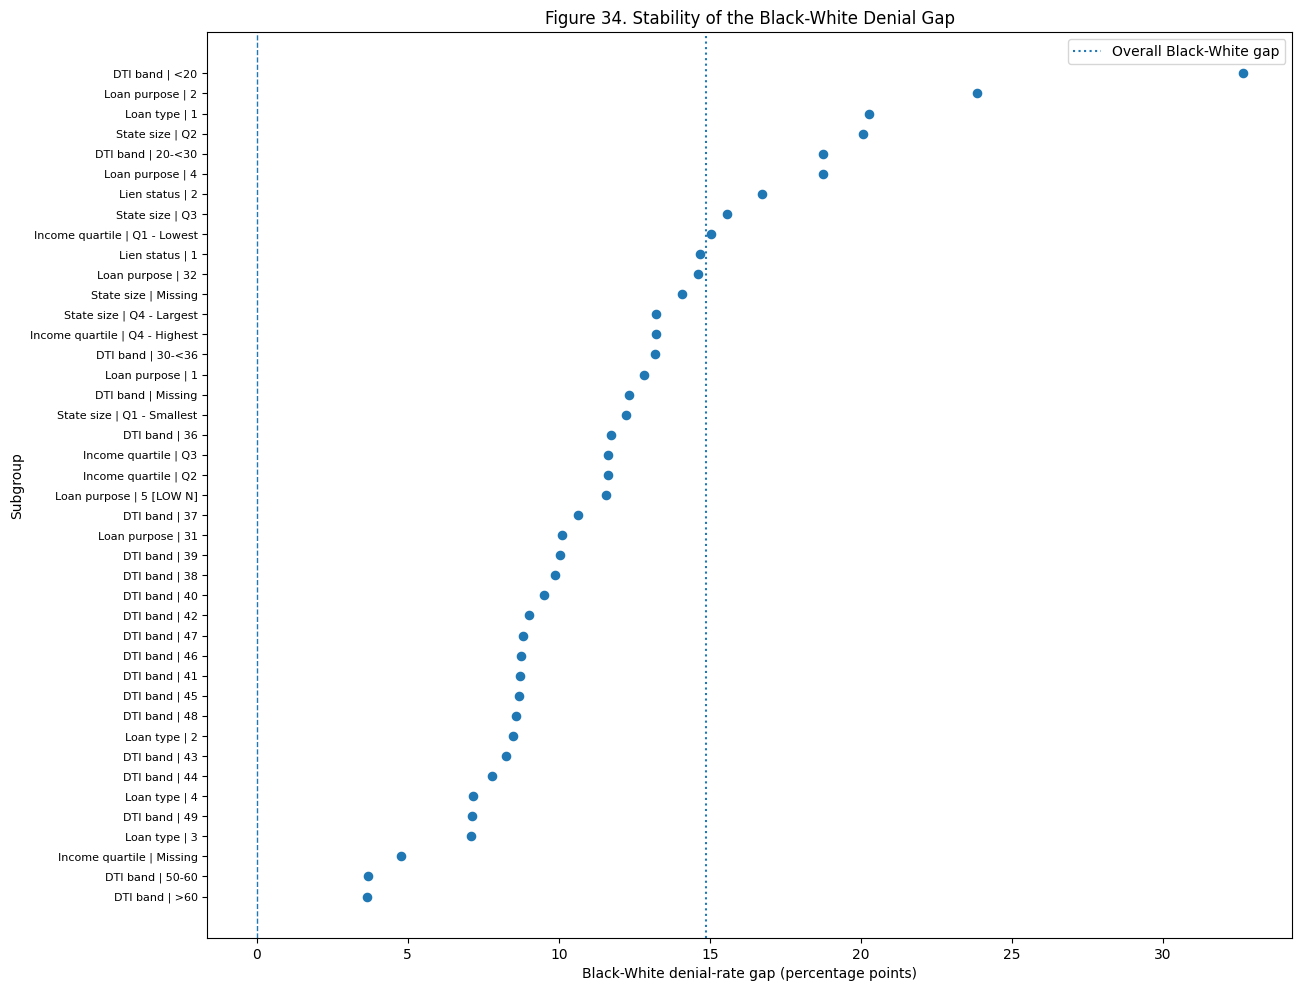

In [177]:
# Step 11b: Draw chart [CHANGE: split only]
fig_height = max(
    8,
    len(G5_PLOT) * 0.28
)

fig, ax = plt.subplots(
    figsize=(14, fig_height)
)

ax.scatter(
    G5_PLOT["gap_pp"],
    range(len(G5_PLOT)),
    s=35
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)

ax.axvline(
    G5_OVERALL_GAP_PP,
    linestyle=":",
    linewidth=1.5,
    label="Overall Black-White gap"
)

ax.set_yticks(
    range(len(G5_PLOT))
)

ax.set_yticklabels(
    G5_PLOT["plot_label"],
    fontsize=8
)

ax.set_xlabel(
    "Black-White denial-rate gap (percentage points)"
)

ax.set_ylabel("Subgroup")

ax.set_title(
    "Figure 34. Stability of the Black-White Denial Gap"
)

ax.legend()

### G5.17 — Save Figure 34

**Input:** Existing G5 variables and preceding cell outputs.

**Process:** Save the existing Figure 34 PNG and display it.

**Output:** Variables or artifacts produced by Step 11c.

In [178]:
# Step 11c: Save and display chart [CHANGE: split only]
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()

plt.savefig(
    os.path.join(
        os.fspath(FIGURE_DIR),
        "B15_fig_34_gap_stability.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("G5 completed.")

<Figure size 640x480 with 0 Axes>

G5 completed.
